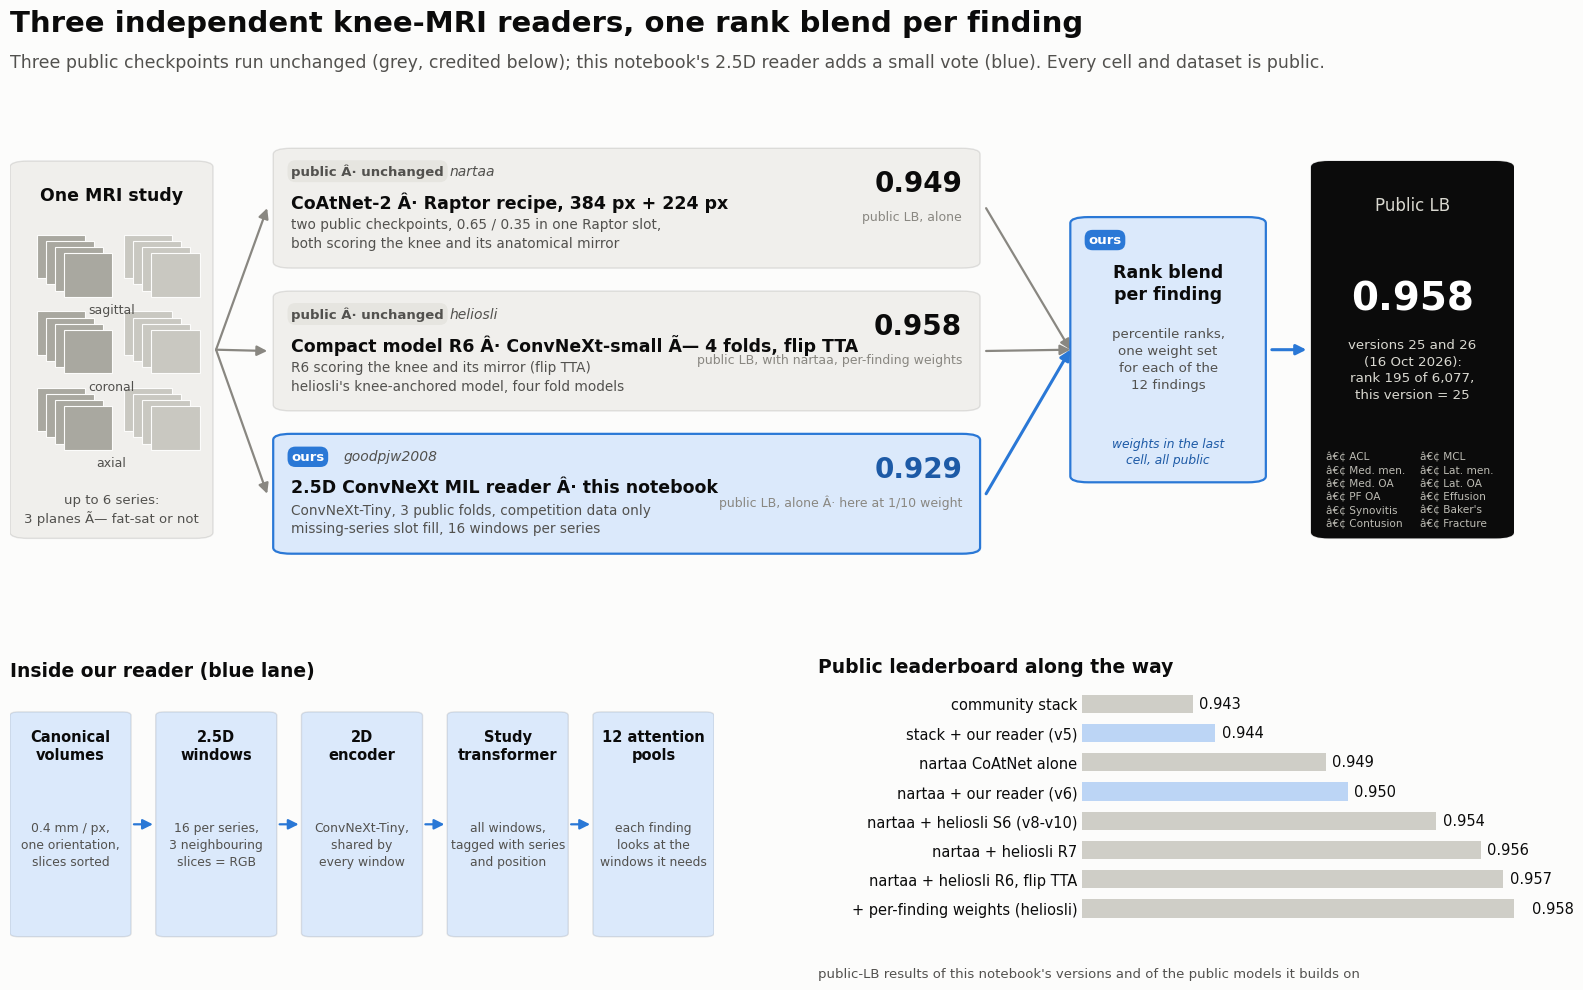

In [1]:
def _figure():
    # How this notebook works (drawn with matplotlib; scores are public-leaderboard results)
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle

    SURFACE, INK, INK2, MUTED, LINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#d9d8d0"
    BLUE, BLUE_D, TINT, NEUTRAL, NEUTRAL2 = "#2a78d6", "#1d5aa6", "#dbe9fb", "#f0efec", "#e6e5e0"
    ORANGE = "#eb6834"

    fig = plt.figure(figsize=(16, 10.2), facecolor=SURFACE)
    fig.text(0.03, 0.962, "Three independent knee-MRI readers, one rank blend per finding", fontsize=21, fontweight="bold", color=INK)
    fig.text(0.03, 0.927, "Three public checkpoints run unchanged (grey, credited below); this notebook's 2.5D reader adds a small vote (blue). Every cell and dataset is public.",
             fontsize=12.5, color=INK2)


    def card(ax, x, y, w, h, fill, edge=None, lw=1.0, r=0.012):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}", fc=fill,
                                    ec=edge or (11 / 255, 11 / 255, 11 / 255, 0.10), lw=lw))


    def arrow(ax, x0, y0, x1, y1, color=MUTED, lw=1.6, rad=0.0):
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=15, lw=lw, color=color,
                                     shrinkA=0, shrinkB=0, connectionstyle=f"arc3,rad={rad}"))


    def pill(ax, x, y, text, fill, color, size=9.5):
        ax.text(x, y, text, fontsize=size, color=color, fontweight="bold", va="center", ha="left",
                bbox=dict(boxstyle="round,pad=0.28,rounding_size=0.6", fc=fill, ec="none"))


    # ================= 1 Â· pipeline =================
    ax = fig.add_axes([0.03, 0.40, 0.94, 0.50])
    ax.set_xlim(0, 1), ax.set_ylim(0, 1), ax.axis("off")

    # input study: six series as small slice stacks
    card(ax, 0.0, 0.13, 0.135, 0.74, NEUTRAL)
    ax.text(0.0675, 0.82, "One MRI study", ha="center", va="top", fontsize=12.5, fontweight="bold", color=INK)
    planes = ["sagittal", "coronal", "axial"]
    for i, pl in enumerate(planes):
        for j, fs in enumerate(["fat-sat", "no fat-sat"]):
            x0, y0 = 0.018 + j * 0.058, 0.64 - i * 0.15
            for k in range(4):
                ax.add_patch(Rectangle((x0 + k * 0.006, y0 - k * 0.012), 0.032, 0.085, fc=("#c9c8c1" if j else "#a9a8a0"),
                                       ec=SURFACE, lw=0.8))
        ax.text(0.0675, 0.64 - i * 0.15 - 0.05, pl, ha="center", va="top", fontsize=9, color=INK2)
    ax.text(0.0675, 0.155, "up to 6 series:\n3 planes Ã— fat-sat or not", ha="center", va="bottom", fontsize=9.5, color=INK2, linespacing=1.35)

    lanes = [
        dict(y=0.66, fill=NEUTRAL, tag="public Â· unchanged", tagfill=NEUTRAL2, tagc=INK2, who="nartaa",
             title="CoAtNet-2 Â· Raptor recipe, 384 px + 224 px",
             lines="two public checkpoints, 0.65 / 0.35 in one Raptor slot,\nboth scoring the knee and its anatomical mirror",
             score="0.949", note="alone"),
        dict(y=0.38, fill=NEUTRAL, tag="public Â· unchanged", tagfill=NEUTRAL2, tagc=INK2, who="heliosli",
             title="Compact model R6 Â· ConvNeXt-small Ã— 4 folds, flip TTA",
             lines="R6 scoring the knee and its mirror (flip TTA)\nheliosli's knee-anchored model, four fold models",
             score="0.958", note="with nartaa, per-finding weights"),
        dict(y=0.10, fill=TINT, tag="ours", tagfill=BLUE, tagc="white", who="goodpjw2008",
             title="2.5D ConvNeXt MIL reader Â· this notebook",
             lines="ConvNeXt-Tiny, 3 public folds, competition data only\nmissing-series slot fill, 16 windows per series",
             score="0.929", note="alone Â· here at 1/10 weight"),
    ]
    LX, LW, LH = 0.175, 0.47, 0.235
    for ln in lanes:
        y = ln["y"]
        card(ax, LX, y, LW, LH, ln["fill"], edge=(BLUE if ln["tag"] == "ours" else None), lw=(1.6 if ln["tag"] == "ours" else 1.0))
        pill(ax, LX + 0.012, y + LH - 0.045, ln["tag"], ln["tagfill"], ln["tagc"])
        ax.text(LX + 0.012 + (0.035 if ln["tag"] == "ours" else 0.105), y + LH - 0.045, ln["who"], fontsize=10, color=INK2,
                va="center", style="italic")
        ax.text(LX + 0.012, y + LH - 0.105, ln["title"], fontsize=12.5, fontweight="bold", color=INK, va="center")
        ax.text(LX + 0.012, y + 0.035, ln["lines"], fontsize=9.8, color=INK2, va="bottom", linespacing=1.4)
        # score chip on the right edge of the lane
        ax.text(LX + LW - 0.012, y + LH - 0.07, ln["score"], fontsize=(17 if "Â·" in ln["score"] else 20), fontweight="bold",
                color=(BLUE_D if ln["tag"] == "ours" else INK), ha="right", va="center")
        ax.text(LX + LW - 0.012, y + LH - 0.135, "public LB, " + ln["note"], fontsize=9, color=MUTED, ha="right", va="center")
        arrow(ax, 0.137, 0.5, LX - 0.004, y + LH / 2, rad=0.0)
        arrow(ax, LX + LW + 0.004, y + LH / 2, 0.705, 0.5, color=(BLUE if ln["tag"] == "ours" else MUTED),
              lw=(2.2 if ln["tag"] == "ours" else 1.6))

    # blend
    card(ax, 0.705, 0.24, 0.13, 0.52, TINT, edge=BLUE, lw=1.6)
    pill(ax, 0.717, 0.715, "ours", BLUE, "white")
    ax.text(0.77, 0.63, "Rank blend\nper finding", ha="center", va="center", fontsize=12.5, fontweight="bold", color=INK, linespacing=1.3)
    ax.text(0.77, 0.48, "percentile ranks,\none weight set\nfor each of the\n12 findings", ha="center", va="center", fontsize=9.6,
            color=INK2, linespacing=1.4)
    ax.text(0.77, 0.30, "weights in the last\ncell, all public", ha="center", va="center", fontsize=8.8, color=BLUE_D,
            linespacing=1.3, style="italic")
    arrow(ax, 0.839, 0.5, 0.862, 0.5, color=BLUE, lw=2.2)

    # result
    card(ax, 0.865, 0.13, 0.135, 0.74, INK)
    ax.text(0.9325, 0.80, "Public LB", ha="center", va="top", fontsize=12, color="#d9d8d0")
    ax.text(0.9325, 0.60, "0.958", ha="center", va="center", fontsize=28, fontweight="bold", color="white")
    ax.text(0.9325, 0.46, "versions 25 and 26\n(16 Oct 2026):\nrank 195 of 6,077,\nthis version = 25", ha="center", va="center",
            fontsize=9.6, color="#d9d8d0", linespacing=1.35)
    findings = ["ACL", "MCL", "Med. men.", "Lat. men.", "Med. OA", "Lat. OA", "PF OA", "Effusion", "Synovitis", "Baker's",
                "Contusion", "Fracture"]
    for i, f in enumerate(findings):
        cx, cy = 0.875 + (i % 2) * 0.0625, 0.29 - (i // 2) * 0.026
        ax.text(cx, cy, "â€¢ " + f, fontsize=7.6, color="#bdbcb4", va="center")

    # ================= 2 Â· inside our reader =================
    ax2 = fig.add_axes([0.03, 0.06, 0.44, 0.29])
    ax2.set_xlim(0, 1), ax2.set_ylim(0, 1), ax2.axis("off")
    ax2.text(0, 0.98, "Inside our reader (blue lane)", fontsize=13.5, fontweight="bold", color=INK, va="top")
    steps = [("Canonical\nvolumes", "0.4 mm / px,\none orientation,\nslices sorted"),
             ("2.5D\nwindows", "16 per series,\n3 neighbouring\nslices = RGB"),
             ("2D\nencoder", "ConvNeXt-Tiny,\nshared by\nevery window"),
             ("Study\ntransformer", "all windows,\ntagged with series\nand position"),
             ("12 attention\npools", "each finding\nlooks at the\nwindows it needs")]
    w, gap = 0.172, 0.035
    for i, (t, s) in enumerate(steps):
        x = i * (w + gap)
        card(ax2, x, 0.05, w, 0.76, TINT)
        ax2.text(x + w / 2, 0.75, t, ha="center", va="top", fontsize=10.5, fontweight="bold", color=INK, linespacing=1.2)
        ax2.text(x + w / 2, 0.36, s, ha="center", va="center", fontsize=8.9, color=INK2, linespacing=1.4)
        if i:
            arrow(ax2, x - gap + 0.004, 0.43, x - 0.004, 0.43, color=BLUE)

    # ================= 3 Â· public-LB journey =================
    ax3 = fig.add_axes([0.70, 0.085, 0.27, 0.235], facecolor=SURFACE)
    fig.text(0.535, 0.348, "Public leaderboard along the way", fontsize=13.5, fontweight="bold", color=INK, va="top")
    rows = [("community stack", 0.943, False),
            ("stack + our reader (v5)", 0.944, False),
            ("nartaa CoAtNet alone", 0.949, False),
            ("nartaa + our reader (v6)", 0.950, False),
            ("nartaa + heliosli S6 (v8-v10)", 0.954, False),
        ("nartaa + heliosli R7", 0.956, False),
        ("nartaa + heliosli R6, flip TTA", 0.957, False),
        ("+ per-finding weights (heliosli)", 0.958, False),
            ]
    ys = list(range(len(rows)))[::-1]
    for y, (lab, v, me) in zip(ys, rows):
        ax3.barh(y, v - 0.938, left=0.938, height=0.62, color=(BLUE if me else ("#bcd5f5" if "our" in lab else "#cfcec7")), zorder=2)
        ax3.text(v + 0.0003, y, f"{v:.3f}", va="center", fontsize=10.5,
                 color=(BLUE_D if me else INK), fontweight=("bold" if me else "normal"))
    ax3.set_yticks(ys), ax3.set_yticklabels([r[0] for r in rows], fontsize=10.5, color=INK)
    fig.text(0.535, 0.035, "public-LB results of this notebook's versions and of the public models it builds on",
             fontsize=9.5, color=INK2)
    ax3.set_xlim(0.938, 0.9575), ax3.set_ylim(-0.6, len(rows) - 0.4)
    ax3.set_xticks([]), ax3.tick_params(axis="y", length=0)
    for s in ax3.spines.values():
        s.set_visible(False)
    plt.show()


try:
    _figure()
except Exception as _e:
    print('figure skipped:', repr(_e))
del _figure

> **Update Â· 16 October 2026**
>
> - **Versions 25 and 26 scored 0.958** (the badge; public LB rank 195 of 6,077 on 16 October): heliosli's per-finding Raptor weights on top of
>   the R6 flip-TTA recipe, with the 224 mirror and this reader at 1/10. Version 26 added R7 at 0.4 of the compact slot and scored the same
>   0.958, version 23 (flip TTA for R7 too) 0.957. **This version (27) is version 25's recipe with the write-up brought up to date.**
> - **Versions 21, 22 and 24 scored 0.957**: heliosli's compact model **R6 scored with flip test-time augmentation**
>   ([their notebook](https://www.kaggle.com/code/heliosli/this-is-new-version-0-9576-in-one-click), public LB 0.957, reported 0.9576) in place of R7 without it, with nartaa's 384 + 224 (mirror)
>   checkpoints in the Raptor slot and this reader at 1/10. R7 as a second compact model (0.4 or 0.5 of the compact
>   slot, versions 21 / 22) made no difference at three decimals; version 24 is R6 alone. Version 23 (flip TTA for R7 too) scored 0.957.
> - **This version adds heliosli's per-finding weights from their newest notebook** ([0.958](https://www.kaggle.com/code/heliosli/blend-mine-in-private-lb-luck-to-all-upvoters)): the Raptor half gets
>   0.8 for Synovitis, 0.2 for Lateral OA, 0.6 for PF OA, 0.35 for Baker's cyst and 0.5 elsewhere (their choice, fixed before any run;
>   R6 is strong on the lateral compartment and weaker on synovitis). The compact slot is R6 alone.
> - **The R6 files** come from [rostigor's versioned copy](https://www.kaggle.com/datasets/rostigor/rsna-knee-r6-fe055406) (heliosli have since published [their own](https://www.kaggle.com/datasets/heliosli/rsna-knee-r6-frozen-fe055406-w1), byte-identical) of heliosli's rsna-knee-r6-frozen-fe055406 version 1 (that dataset's
>   current version holds R7); the manifest (sha256 `6508ce6921eda986..`) and every file are checked against heliosli's hashes before
>   anything runs. Both compact stages are their cells, unchanged apart from the marked lines.
>
> **Update Â· 14 October 2026**
>
> - **Version 11 moves to the best public recipe as of today:** [heliosli's R7 compact model](https://www.kaggle.com/code/heliosli/0-957-latest-dataset-score-in-one-click) (public LB 0.956
>   with nartaa's CoAtNet, 50 / 50) plus [varshithakolupuri's](https://www.kaggle.com/code/varshithakolupuri/rsna-knee-one-unused-checkpoint-lifts-the-0-956) addition of nartaa's second public checkpoint
>   (224 px, 0.8 crop) at 35% of the Raptor slot, all cells unchanged. This notebook's reader is kept at 1/10 of its v6
>   weights: on the current bases our own submissions showed that the reader at full weight no longer adds (0.956 base
>   + reader -> 0.954), while a small vote keeps our model in the picture at no cost.
> - **Versions 8 to 10** used heliosli's S6 model (0.954 with nartaa, whatever the ratio or precision: we measured 0.954
>   five times). The S6 -> R7 step is what moves the public leaderboard.
> - **This reader is used by 77 public notebooks from 30 authors** (the Code tab of
>   [goodpjw2008/rsna-knee-2-5d-convnext-reader](https://www.kaggle.com/datasets/goodpjw2008/rsna-knee-2-5d-convnext-reader)). This notebook is where it comes from.
> - **Want it in your own blend?** See *Add this reader to your notebook* below.

**What this is.** The 2.5D ConvNeXt MIL reader that this notebook introduced on 4 October, rank-blended at a small
weight into the best public three-model blend: [nartaa's CoAtNet](https://www.kaggle.com/code/nartaa/rsna-knee-0949-anatomical-mirror) (384 px) and its [224-px
sibling](https://www.kaggle.com/code/nartaa/rsna-knee-0945-efficient-224crop) in the Raptor slot, and heliosli's compact model [R6](https://www.kaggle.com/datasets/rostigor/rsna-knee-r6-fe055406) (with flip TTA) in the other.

| | Public LB |
|---|---|
| nartaa's CoAtNet alone (Part A1) | 0.949 |
| this notebook's reader alone, 3 folds | 0.929 |
| versions 1 to 5: community stack + reader at 30% | 0.944 |
| version 6: nartaa's CoAtNet + reader, per-finding weights | 0.950 |
| versions 8 to 10: nartaa + heliosli's S6 (+ reader) | 0.954 |
| nartaa + heliosli's R7, 50 / 50 ([heliosli's notebook](https://www.kaggle.com/code/heliosli/0-957-latest-dataset-score-in-one-click)) | 0.956 |
| the same + nartaa's 224 checkpoint at 35% of the Raptor slot ([varshithakolupuri's notebook](https://www.kaggle.com/code/varshithakolupuri/rsna-knee-one-unused-checkpoint-lifts-the-0-956)) | 0.956, ranked higher |
| versions 11 to 20: the R7 recipe + the 224 mirror + S6 as a second compact model + this reader at 1/10 | 0.956, top 10% of the block |
| nartaa + heliosli's R6 with flip TTA, 50 / 50 ([heliosli's notebook](https://www.kaggle.com/code/heliosli/this-is-new-version-0-9576-in-one-click)) | 0.957 |
| **versions 21, 22, 24: 384 + 224 (mirror), R6 (flip TTA) alone or with R7 (0.4 / 0.5), this reader at 1/10** | **0.957** |
| the same R6 recipe with per-finding Raptor weights ([heliosli's newest notebook](https://www.kaggle.com/code/heliosli/blend-mine-in-private-lb-luck-to-all-upvoters)) | 0.958 |
| **versions 25 and 26 (this version = 25): heliosli's per-finding Raptor weights, 384 + 224 (mirror), R6 (flip TTA) alone / with R7 0.4, this reader at 1/10 (Part B)** | **0.958** |

What we measured on the way (our own submissions, 11 to 13 October): on top of the S6 recipe our reader at its v6
weights gave 0.954 = the base; at 1/4 weight 0.954; our S6-distilled reader (gold-58 0.931 alone) 0.953. A third reader
only pays when it is independent of the two it joins, and S6/R7 already cover what a ConvNeXt reader sees; so this
version keeps the reader small and lets the public models carry the score.

### Add this reader to your notebook

1. Attach the dataset [goodpjw2008/rsna-knee-2-5d-convnext-reader](https://www.kaggle.com/datasets/goodpjw2008/rsna-knee-2-5d-convnext-reader).
2. After your notebook has written `/kaggle/working/submission.csv`, copy the five **Part B** cells at the end of this
   notebook. They write the reader's source, install the offline DICOM decoders shipped in the dataset (the hidden test
   has compressed DICOMs), run the three folds and rank-blend the result into your submission.
3. Set `OWN_W_PER_TARGET` to one weight per finding. On top of a ~0.949 single model, 0.03 to 0.35 worked for us; on top
   of a two-model blend that already covers the reader's strengths, keep it at 0.01 to 0.05 or leave it out.

If anything fails, Part B keeps your submission unchanged. If your notebook uses this reader, a link back here helps
others find the source.

## References

- **Part A1** is [nartaa's 0.949 single CoAtNet](https://www.kaggle.com/code/nartaa/rsna-knee-0949-anatomical-mirror) with its weights from
  [nartaa/rsna-knee-publication-swa-weights-20261007](https://www.kaggle.com/datasets/nartaa/rsna-knee-publication-swa-weights-20261007), built on Dread Development's
  [Raptor recipe and backbone](https://www.kaggle.com/datasets/dreaddevelopment/raptor-knee-widedense) and trained with OAI knees (acknowledgement below).
- **Part A1b** is nartaa's [0.945 notebook](https://www.kaggle.com/code/nartaa/rsna-knee-0945-efficient-224crop) with the second checkpoint of the same dataset (224 px, 0.8 centre
  crop); mixing it into the Raptor slot at 35% is [varshithakolupuri's](https://www.kaggle.com/code/varshithakolupuri/rsna-knee-one-unused-checkpoint-lifts-the-0-956) idea and code (stage 2b and the blend cell).
- **Part A2** is stage 2 of [heliosli's R6 notebook](https://www.kaggle.com/code/heliosli/this-is-new-version-0-9576-in-one-click) (R6 with flip TTA), its files from [a versioned public copy](https://www.kaggle.com/datasets/rostigor/rsna-knee-r6-fe055406) of their
  version-1 dataset. **Part A3** is their blend cell with [varshithakolupuri's](https://www.kaggle.com/code/varshithakolupuri/rsna-knee-one-unused-checkpoint-lifts-the-0-956) 224 lines and the per-finding Raptor weights of [their 0.958 notebook](https://www.kaggle.com/code/heliosli/blend-mine-in-private-lb-luck-to-all-upvoters); the blend cell and the
  compact stage come from [heliosli's R7 notebook](https://www.kaggle.com/code/heliosli/0-957-latest-dataset-score-in-one-click): the compact model R7 (ConvNeXt-small, 4 folds, crop 352,
  knee-joint anchors, fastMRI auxiliary training, refitted Effusion and Baker's state stackers) in
  [heliosli/rsna-knee-compact-r7cnxfsss](https://www.kaggle.com/datasets/heliosli/rsna-knee-compact-r7cnxfsss) with its code in [heliosli/rsna-orthofoundation-fold0-epoch7-20261004](https://www.kaggle.com/datasets/heliosli/rsna-orthofoundation-fold0-epoch7-20261004),
  and their 50 / 50 rank blend.
- **Part B** is ours. Its per-finding weights (here scaled to 1/10) and two reader changes (a missing fat-sat or
  non-fat-sat series filled with its counterpart, 16 windows per series) come from
  [sujanmajhisuzan's Apex Grandmaster Stack](https://www.kaggle.com/code/sujanmajhisuzan/rsna-knee-apex-grandmaster-stack), which builds on this reader.

*OAI acknowledgement (required for the Part A1 weights).* Data and/or research tools used in the preparation of this
manuscript were obtained and analyzed from the controlled access datasets distributed from the Osteoarthritis
Initiative (OAI), a data repository housed within the NIMH Data Archive (NDA). OAI is a collaborative informatics system
created by the National Institute of Mental Health and the National Institute of Arthritis, Musculoskeletal and Skin
Diseases (NIAMS) to provide a worldwide resource to quicken the pace of biomarker identification, scientific
investigation and OA drug development. Dataset identifier(s): 10.15154/0hcg-f676.
[Shared NDA Study](https://nda.nih.gov/study.html?id=3407) Â· [DOI: 10.15154/0hcg-f676](https://doi.org/10.15154/0hcg-f676).

## What is ours

The reader: preprocessing (canonical volumes at 0.4 mm per pixel, orientation from `ImageOrientationPatient`, slices
sorted by position), the 2.5D model (ConvNeXt-Tiny over 3-slice windows, a two-layer study transformer, one attention
pool per finding), its training (five folds grouped by report text, soft labels from four public label tables, the 58
gold studies never trained on), the three public fold checkpoints, and the leaderboard probes in the version history.
Our newest work with two reader families is in [our 0.954 notebook](https://www.kaggle.com/code/goodpjw2008/rsna-knee-coatnet-s6-2-5d-mil-lb-0-954).

## Thanks

- **[heliosli](https://www.kaggle.com/heliosli)** for the compact models S6, R6 and R7, the flip-TTA worker, the per-finding weights
  and for inviting blends. Parts A2, A2b and A3 are their cells.
- **[rostigor](https://www.kaggle.com/rostigor)** for keeping version 1 of the R6 bundle available as a versioned dataset before heliosli published their own copy.
- **[nartaa (Danial Zakaria)](https://www.kaggle.com/nartaa)** for both CoAtNet checkpoints and their notebooks.
- **[varshithakolupuri](https://www.kaggle.com/varshithakolupuri)** for noticing the unused 224 checkpoint and measuring it.
- **[Dread Development](https://www.kaggle.com/dreaddevelopment)** for the Raptor recipe behind nartaa's models.
- **[sujanmajhisuzan](https://www.kaggle.com/sujanmajhisuzan)** for the per-finding weights and the reader changes.
- **[stevenleehans](https://www.kaggle.com/stevenleehans)**, **[Pilkwang Kim](https://www.kaggle.com/pilkwang)**,
  **[lixin73](https://www.kaggle.com/lixin73)** and **[laymond](https://www.kaggle.com/laymond)** for the public
  report-label tables the reader was trained on, and `timm`.

---
# Part A1 Â· nartaa's 384-px CoAtNet (unchanged)

Stage 1 of [heliosli's notebook](https://www.kaggle.com/code/heliosli/this-is-new-version-0-9576-in-one-click): [nartaa's published notebook](https://www.kaggle.com/code/nartaa/rsna-knee-0949-anatomical-mirror) run as its own process.

In [2]:
%%writefile /tmp/raptor_run.py
# Authorized scoring run: verify the selected checkpoint before inference.
RUN_INFERENCE = True
if not RUN_INFERENCE:
    raise SystemExit("Static notebook only. Attach the exact checkpoint and competition, enable a T4 GPU, and set RUN_INFERENCE = True to run inference.")

import hashlib
from pathlib import Path
import torch
if not torch.cuda.is_available():
    raise RuntimeError("This scored pipeline requires CUDA; CPU inference is not enabled.")
_weight_name = 'raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt'
_candidates = [
    Path('/kaggle/input/rsna-knee-publication-swa-weights-20261007') / _weight_name,
    Path('/kaggle/input/datasets/nartaa/rsna-knee-publication-swa-weights-20261007') / _weight_name,
    Path('/kaggle/input/rsna-knee-oai-original384-s42-pair') / _weight_name,
    Path('/kaggle/input/datasets/nartaa/rsna-knee-oai-original384-s42-pair') / _weight_name,
]
_weights = next((p for p in _candidates if p.is_file()), None)
if _weights is None:
    raise FileNotFoundError("Attach the exact selected weights; no alternative model is substituted.")
with _weights.open('rb') as _f:
    assert hashlib.file_digest(_f, 'sha256').hexdigest() == '7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef', "Checkpoint hash differs"


# %% [code]
#!/usr/bin/env python3
"""Knee MRI: twelve findings from a single model

This notebook takes a knee MRI study and scores twelve findings at once: ACL tear, MCL tear,
medial and lateral meniscus tears, osteoarthritis in the medial, lateral and patellofemoral
compartments, joint effusion, synovitis, a Baker's cyst, bone contusion and fracture. It scores
0.924 on the public leaderboard using one model, with no ensembling and no test-time augmentation.

This is the inference half of the work. The model was trained separately and its weights are
attached as a dataset, so this notebook only loads them and predicts:
https://www.kaggle.com/datasets/dreaddevelopment/raptor-knee-widedense

Where the training labels came from

Worth saying up front, because it shapes everything else. The competition gives you 4,407 studies
but structured labels for only 58 of them. Every other study arrives with a free-text radiology
report and nothing more, so there is very little to train against out of the box.

The labels behind these weights were made by reading those reports with a language model and
turning each into twelve probabilities rather than twelve yes or no answers. A report that says a
tear is suspected becomes a number near 0.8, not a 1, which is a fairer target than forcing every
hedged sentence into a hard label. That yields 4,349 studies to train on. The 58 studies that came
with real labels were never trained on and are used to check the result honestly; the model reaches
0.9167 macro-AUC on them.

Building a fixed input from studies that are all shaped differently

The hard part of this competition is not the network, it is that no two studies look alike. A
study holds several DICOM series shot in different planes, the number of series varies, and the
number of slices in a series varies more. Anything that expects a fixed-size input has to be given
one.

The approach here is to fill five fixed slots per study, always in the same order, for a stack of
64 images:

  18 slices from a sagittal series, preferring a fluid-sensitive one
  14 slices from a second sagittal series, preferring one that is not fluid-sensitive
  12 slices from a coronal series, preferring a fluid-sensitive one
   8 slices from a second coronal series
  12 slices from an axial series

Preferring a fluid-sensitive series for some slots and not for others is deliberate. Fluid-
sensitive sequences show swelling, effusion and acute injury clearly, while the other sequences
show anatomy and cartilage better, and the twelve findings are split across both. If a study has
no series for a slot, the slot is left as zeros and the model is told to skip it rather than being
fed something misleading.

Within a series, slices are taken evenly across 6 to 94 percent of the stack rather than from the
middle. The outer slices are where the collateral ligaments and the lateral meniscus sit, and
cutting them was measurably costing accuracy on exactly those findings.

Every slice is cropped to a 140 mm box around the centre of the image using the pixel spacing from
the DICOM header, then resized to 336 pixels. Cropping by millimetres rather than by pixel count
matters: it means a knee occupies the same fraction of the frame whether the scan was acquired at
0.3 or 0.5 mm per pixel, so the model is not asked to learn scale differences that carry no medical
information.

How the model reads the stack

Three neighbouring slices are stacked into the three channels of one image. The network then sees
a little of what lies above and below the slice in the middle, which is most of the benefit of a 3D
model at the cost of a 2D one. Each of these three-slice windows is passed through a CoAtNet
backbone at 384 pixels.

The windows are combined with an attention layer that has separate weights for each of the twelve
findings. This is the part that matters most. A cruciate tear may be visible on two sagittal slices
while osteoarthritis is spread across many coronal ones, and a single pooled score forces those two
to share one notion of which slices are important. Giving each finding its own attention weights
lets each one draw on the slices that actually show it.

Running it

Scoring uses 42 windows per study. Inference runs in half precision and automatically retries a
study in full precision if it fails, so no study is ever dropped from the submission. The notebook
needs no internet: the backbone is loaded from the attached weights rather than downloaded.
"""
import os, sys, glob, time, json, gc
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
import numpy as np
from concurrent.futures import ThreadPoolExecutor
import threading, queue
import torch, torch.nn as nn, torch.nn.functional as F
import timm
# T4 (Turing) cuDNN v9 has fp16/fp32 conv engines but NOT bf16 for these shapes
# ("GET was unable to find an engine..."); benchmark lets it pick a valid algo for
# the fixed (1,24,3,res,res) input.
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True

# ---- fixed config (must match training exactly) -----------------------------
INPUT_RES = 320
INPUT_MODE = "crop"
IMG = 384   # native 384 corpus: the model saw 384 px crops directly, no 336->384 upsample
CROP_MM = 140.0
# 96 slices per study at native 384 px. Must match the corpus the weights were trained on
# (cache/build_corpus96.py).
SLOTS = [("Sagittal", 1, 26), ("Sagittal", 0, 22), ("Coronal", 1, 18),
         ("Coronal", 0, 12), ("Axial", -1, 18)]
MAXS = sum(s[2] for s in SLOTS)                     # 96
K_EVAL = 94   # every window position of the 96-slice test volume (full coverage)
HDR_THREADS = 16   # per prep process: header reads are fuse-latency-bound, not CPU-bound
PX_THREADS = 8     # per prep process: pixel reads of the ~96 picked slices
QUEUE_MAX = 48     # studies in flight between the prep pool and the GPU consumers (RAM bound: ~14 MB each)
NORM = "imagenet"
FASTREAD_VARIANT = 'study_lut'   # kernel v3: research/fastread/readers.py, byte-identical to build_study
FR_HDR, FR_PX = 32, 16
_FASTREAD_B64 = "..."
def _load_fastread():
    import base64 as _b, importlib.util as _iu
    p = '/kaggle/working/_fastread.py' if os.path.isdir('/kaggle/working') else os.path.join(os.path.dirname(os.path.abspath(__file__)), '_fastread.py')
    if not os.path.exists(p):
        open(p, 'wb').write(_b.b64decode(_FASTREAD_B64))
    spec = _iu.spec_from_file_location('_fastread', p); m = _iu.module_from_spec(spec); spec.loader.exec_module(m)
    return m
LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
       "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Three arms: (weights filename, fallback arch, fallback res). ck carries arch+res too.
# Selected 2026-08-19 by greedy forward selection AND exhaustive subset search over a 7-arm
# panel on the 45-study gold set (phase2/blend_panel.py); both agree on this exact set.
# Singles: coatnet384 0.9025 | swinbase384 0.8825 | effv2l480 0.8716.
# Blend {coatnet+swin+effv2l} = 0.9068 (2-arm {coatnet+swin} = 0.9059, coatnet alone 0.9025).
# Dropped as redundant: cnn336 (0.8833, the former champion), cnbase384 (0.8754),
# cnlarge384 (0.8752), maxvit384 (0.8438).
#
# SINGLE ARM: coatnet_rmlp_2_rw_384 retrained on the EXPANDED 4,349-study corpus.
#
# Why one arm and not the 3-arm blend: on the live leaderboard CoAtNet alone scored 0.914 while
# every blend scored 0.914-0.915, so ensembling is worth ~+0.001 there -- the ~+0.010 it showed
# on the old 45-study gold set was gold-set noise. One arm is also 1/3 the kernel runtime.
#
# Corpus expansion: the corpus previously held 3,200 of the 4,349 labelled studies and only 45
# of the 58 gold studies. Rebuilt to 4,407 studies (+37.8% training data, 58-study gate).
#
# Measured on the 58-study gate (the incumbent re-scored on the SAME gate for a fair compare):
#   incumbent CoAtNet (3,155-study corpus) 0.8923
#   this model       (4,349-study corpus) 0.9054   (+0.0131, better in 92.7% of 2000 bootstraps)
# Biggest gains land on the findings that were capping us: Lateral Meniscus +0.071,
# Fracture +0.057, Lateral OA +0.048, Medial Meniscus +0.035, ACL +0.028.
ARMS = [   # our 5-fold CoAtNet (public recipe reproduced on our folds/labels), equal-weight rank-mean
    {"file": "raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt", "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384, "w": 1.0},
]


# ============================================================================
# Model -- verbatim from finetune_raptor.py
# ============================================================================
def build_backbone(arch, pretrained=False):
    # maxvit/maxxvit/coatnet are conv-attention hybrids: NO CLS token, NO interpolatable
    # pos-embed -> avg pool. The "vit" substring in "coatnet"/"maxvit" must NOT route them
    # down the ViT path (mirrors finetune_raptor.py exactly).
    hybrid = arch.startswith(("maxvit", "maxxvit", "coatnet", "coat_", "convnext"))
    is_vit = (not hybrid) and any(k in arch for k in ("vit", "deit", "dinov2", "eva", "beit"))
    kw = dict(pretrained=pretrained, num_classes=0, in_chans=3, img_size=INPUT_RES)
    if is_vit:
        kw.update(global_pool="token", dynamic_img_size=True)
    else:
        kw.update(global_pool="avg")
    return timm.create_model(arch, **kw)


class RaptorClassifier(nn.Module):
    def __init__(self, backbone, F_dim=768, n=12, drop=0.2):
        super().__init__()
        self.backbone = backbone
        self.norm = nn.LayerNorm(F_dim)
        self.att = nn.Sequential(nn.Linear(F_dim, 256), nn.Tanh(), nn.Dropout(drop),
                                 nn.Linear(256, n))
        self.clsW = nn.Parameter(torch.zeros(n, F_dim))
        self.clsb = nn.Parameter(torch.zeros(n))
        nn.init.trunc_normal_(self.clsW, std=0.02)
        self.n = n

    def encode(self, x):
        B, K = x.shape[:2]
        # Bound backbone memory; the attention head still sees every window together.
        flat = x.flatten(0, 1)
        f = torch.cat([self.backbone(chunk) for chunk in flat.split(16)], dim=0)
        return f.view(B, K, -1)

    def head(self, feats):
        h = self.norm(feats)
        a = self.att(h)
        a = torch.softmax(a, dim=1)
        pooled = torch.einsum("bkn,bkf->bnf", a, h)
        logits = (pooled * self.clsW).sum(-1) + self.clsb
        return logits

    def forward(self, x):
        return self.head(self.encode(x))


def load_model(pt_path, arch_default, res_default, device, ngpu=1):
    import hashlib
    with open(pt_path, "rb") as stream:
        observed_sha = hashlib.file_digest(stream, "sha256").hexdigest()
    assert observed_sha == '7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef', "Bound checkpoint bytes differ"
    print(f"[weights] sha256 {observed_sha}", flush=True)
    ck = torch.load(pt_path, map_location="cpu", weights_only=False)
    arch = ck.get("arch", arch_default)
    assert int(ck.get("res", res_default)) == 384, "Expected original 384 checkpoint"
    ck_res = INPUT_RES
    bb = build_backbone(arch, pretrained=False)
    model = RaptorClassifier(bb, F_dim=bb.num_features)
    model.load_state_dict(ck["model"], strict=True)
    model.eval().to(device)
    # NOTE: DataParallel removed on purpose. On the full hidden test it drove a system-RAM OOM
    # (per-forward module replication over many studies); a single T4 handles K_EVAL=24 windows
    # fine. Arms are also run SEQUENTIALLY (see main) so peak RAM == one model, not two.
    del ck
    gc.collect()
    return model, ck_res


# ============================================================================
# Eval windowing -- verbatim from finetune_raptor.py StudyWindows (train=False)
# ============================================================================
def _eval_centers(mask, D, k):
    valid = np.where(mask > 0)[0]
    if len(valid) < 3:
        valid = np.arange(min(3, D))
    lo, hi = int(valid.min()), int(valid.max())
    cs = [c for c in range(lo + 1, hi) if c - 1 >= lo and c + 1 <= hi]
    if not cs:
        cs = [max(1, min((lo + hi) // 2, D - 2))]
    idx = np.linspace(0, len(cs) - 1, k).round().astype(int)
    return [cs[i] for i in idx]


SLOT_SIZES = [26, 22, 18, 12, 18]
SAGITTAL_SLOTS = (0, 1)

def _slot_index(D):
    b = np.cumsum([0] + SLOT_SIZES)
    if b[-1] != D: raise RuntimeError(f'slot sizes sum to {b[-1]}, volume has {D} slices')
    s_ = np.searchsorted(b, np.arange(D), side='right') - 1
    rel = (np.arange(D) - b[s_]) / np.maximum(1, np.array(SLOT_SIZES)[s_] - 1)
    return s_, rel

def _mirror_tri(tri, cs, D):
    """final-g1-bundle MIRROR_TTA: true L/R mirror of (k,3,H,W) uint8 eval triplets (research/rnd4/mirror/mirror_f0.py). The slot of each
    window's CENTRE slice decides the axis: sagittal (slots 0,1) -> reverse the 3 slice-channels; coronal/axial (2,3,4) -> flip the width.
    Done on uint8 BEFORE the per-channel LUT, i.e. 'mirror the knee, then normalise'."""
    s_, _ = _slot_index(D)
    sag = torch.from_numpy(np.isin(s_[np.asarray(cs, dtype=np.int64)], SAGITTAL_SLOTS)).to(tri.device).view(-1, 1, 1, 1)
    return torch.where(sag, tri.flip(1), tri.flip(-1))

def infer_pair_probs(model, plain, mirrored, device):
    assert plain.shape==mirrored.shape==(94,3,320,320)
    assert all(not m.training for m in model.modules()), "TTA must not update BN or enable dropout"
    p = infer_probs(model, plain, device)
    q = infer_probs(model, mirrored, device)
    return 0.5 * (p + q)

def eval_windows(vol, mask, k, res, norm=NORM, mirror=False):
    D = vol.shape[0]
    cs = _eval_centers(mask, D, k)
    wins = np.empty((len(cs), 3, res, res), np.float32)
    for j, c in enumerate(cs):
        c = max(1, min(c, D - 2))
        tri = np.stack([vol[c - 1], vol[c], vol[c + 1]], 0)
        if mirror:
            tri = _mirror_tri(torch.from_numpy(tri)[None], [c], D)[0].numpy()
        tri = tri.astype(np.float32) / 255.0
        assert tri.shape[-2:] == (IMG, IMG) and res == INPUT_RES
        lo = (IMG - res) // 2
        tri = tri[:, lo:lo + res, lo:lo + res]
        t = torch.from_numpy(np.ascontiguousarray(tri))
        if t.shape[-1] != res:
            t = F.interpolate(t[None], size=(res, res), mode="bilinear",
                              align_corners=False)[0]
        wins[j] = t.numpy()
    x = torch.from_numpy(wins)
    if norm == "imagenet":
        x = (x - _MEAN) / _STD
    return x


_WLUT = {}
def gpu_windows(vol, mask, k, res, dev, norm=NORM, mirror=False):
    """Same windows as eval_windows, built on the GPU from the uint8 volume. Values come from a per-channel
    256-entry table computed on the CPU with eval_windows' own float32 ops, so they are bit-identical."""
    D = vol.shape[0]
    cs = np.array([max(1, min(c, D - 2)) for c in _eval_centers(mask, D, k)])
    tri = torch.from_numpy(np.ascontiguousarray(vol[np.stack([cs - 1, cs, cs + 1], 1)])).to(dev)   # (k,3,IMG,IMG) uint8
    if mirror:
        tri = _mirror_tri(tri, cs, D)
    assert tri.shape[-2:] == (IMG, IMG) and res == INPUT_RES
    lo = (IMG - res) // 2
    tri = tri[:, :, lo:lo + res, lo:lo + res]
    key = (str(dev), norm)
    if key not in _WLUT:
        v = torch.from_numpy((np.arange(256, dtype=np.uint8).astype(np.float32) / 255.0))
        t = torch.stack([v, v, v], 0).view(3, 256, 1)
        if norm == 'imagenet':
            t = (t - _MEAN.view(3, 1, 1)) / _STD.view(3, 1, 1)
        _WLUT[key] = t.view(3, 256).contiguous().to(dev)
    L = _WLUT[key]
    x = torch.stack([L[c][tri[:, c].long()] for c in range(3)], 1)                   # exact float32 values
    if x.shape[-1] != res:
        if norm == 'imagenet':   # resize must happen BEFORE normalisation, as in eval_windows
            L0 = _WLUT.setdefault((str(dev), 'none'), torch.from_numpy(np.arange(256, dtype=np.uint8).astype(np.float32) / 255.0).to(dev))
            x = L0[tri.long()]
            x = F.interpolate(x, size=(res, res), mode='bilinear', align_corners=False)
            x = (x - _MEAN.to(dev)) / _STD.to(dev)
        else:
            x = F.interpolate(x, size=(res, res), mode='bilinear', align_corners=False)
    return x


@torch.no_grad()
def infer_probs(model, xwins, device):
    assert str(device).startswith("cuda"), "Qualified inference requires CUDA/fp16"
    x = xwins.unsqueeze(0).to(device)
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model(x).float()
        assert torch.isfinite(logits).all(), "Nonfinite fp16 logits"
        o = torch.sigmoid(logits)
    return o[0].cpu().numpy()


def rankpct(x):                                   # per-column percentile rank in [0,1]
    order = x.argsort(0).argsort(0).astype(np.float64)
    return order / max(1, (x.shape[0] - 1))


# ============================================================================
# Preprocessing -- verbatim from kprep2/dino_preprocess.py, retargeted to TEST
# ============================================================================
def _make_reader():
    import pydicom, cv2
    from pydicom.pixel_data_handlers.util import apply_modality_lut

    def _hdr(f):
        try:
            h = pydicom.dcmread(f, stop_before_pixels=True)
            iop = getattr(h, 'ImageOrientationPatient', None)
            ipp = getattr(h, 'ImagePositionPatient', None)
            if iop is not None and ipp is not None and len(iop) == 6:
                r = np.array(iop[:3], float); c = np.array(iop[3:], float)
                n = np.cross(r, c); pos = float(np.dot(np.array(ipp, float), n))
            else:
                pos = float(getattr(h, 'InstanceNumber', 0) or 0)
            ps = getattr(h, 'PixelSpacing', None); ps = float(ps[0]) if ps is not None else 0.5
            return (pos, f, ps, True)
        except Exception:
            return (0.0, f, 0.5, False)

    def order_and_meta(sdir):
        # Header reads are latency-bound on Kaggle's mounted competition data (~240k opens on the hidden
        # set); a thread pool hides that latency. Records and sort are unchanged -> identical ordering.
        fs = glob.glob(sdir + "/*.dcm")
        with ThreadPoolExecutor(max_workers=HDR_THREADS) as ex:
            out = list(ex.map(_hdr, fs))
        recs = [(pos, f, ps) for pos, f, ps, _ in out]; ps_list = [ps for _, _, ps, ok in out if ok]
        recs.sort(key=lambda x: x[0])
        med_ps = float(np.median(ps_list)) if ps_list else 0.5
        return [(f, ps) for _, f, ps in recs], med_ps

    def read_px(f):
        d = pydicom.dcmread(f)
        a = apply_modality_lut(d.pixel_array, d).astype(np.float32)
        if str(getattr(d, 'PhotometricInterpretation', '')) == 'MONOCHROME1':
            a = a.max() - a
        return a

    def mm_crop_resize(a, ps):
        h, w = a.shape; cpx = int(round(CROP_MM / max(ps, 1e-3)))
        cpx = min(cpx, min(h, w)); y0 = (h - cpx) // 2; x0 = (w - cpx) // 2
        a = a[y0:y0 + cpx, x0:x0 + cpx]
        return cv2.resize(a, (IMG, IMG), interpolation=cv2.INTER_AREA)

    return order_and_meta, read_px, mm_crop_resize


def _pick_series_for_slot(rows, plane, fluid, used):
    cands = [r for r in rows if r['Anatomical_Plane'] == plane and r['SeriesInstanceUID'] not in used]
    if fluid in (0, 1):
        pref = [r for r in cands if int(r.get('Fluid_Sensitive', 0) or 0) == fluid]
        if pref:
            return pref[0]
    return cands[0] if cands else None


def build_study(sid, ser_records, tsdir, reader):
    order_and_meta, read_px, mm_crop_resize = reader
    rows = ser_records.get(sid, [])
    vol = np.zeros((MAXS, IMG, IMG), np.uint8); idx = 0; used = set()
    for plane, fluid, k in SLOTS:
        r = _pick_series_for_slot(rows, plane, fluid, used)
        if r is None:
            idx += k; continue
        used.add(r['SeriesInstanceUID'])
        files, med_ps = order_and_meta(f"{tsdir}/{sid}/{r['SeriesInstanceUID']}")
        if not files:
            idx += k; continue
        # wide span: the collateral ligaments and lateral meniscus live in the
        # peripheral slices the old 0.15-0.85 crop threw away. Must match the corpus
        # the weights were trained on (build_corpus80.py, SPAN).
        n = len(files); lo, hi = int(n * 0.02), int(n * 0.98) - 1; hi = max(hi, lo)
        picks = np.linspace(lo, hi, k).round().astype(int) if n > 1 else [0] * k
        sel = [files[min(p, n - 1)] for p in picks]
        def _px(fp_ps):
            fp, ps = fp_ps
            try: return read_px(fp), ps
            except Exception: return None, med_ps
        with ThreadPoolExecutor(max_workers=PX_THREADS) as ex:
            got = list(ex.map(_px, sel))                    # order preserved
        arrs = [a for a, _ in got]; pss = [ps for _, ps in got]
        valid = [a for a in arrs if a is not None]
        if valid:
            allpx = np.concatenate([a.ravel() for a in valid])
            loq, hiq = np.percentile(allpx, [2.0, 98.0])
        else:
            loq, hiq = 0.0, 1.0
        for a, ps in zip(arrs, pss):
            if idx >= MAXS: break
            if a is None: idx += 1; continue
            aw = np.clip((a - loq) / (hiq - loq + 1e-6), 0, 1)
            aw = mm_crop_resize(aw, ps if ps > 0 else med_ps)
            vol[idx] = (aw * 255).astype(np.uint8); idx += 1
        if idx >= MAXS: break
    mask = (vol.reshape(MAXS, -1).sum(1) > 0).astype(np.uint8)
    return vol, mask



# ---- parallel preprocessing helpers (module level so they pickle under fork) ----
_SER = None; _TSDIR = None; _READER = None
def _pre_init():
    global _READER
    _READER = _load_fastread().make_builder(FASTREAD_VARIANT, IMG, SLOTS, hdr_threads=FR_HDR, px_threads=FR_PX)
def _pre_one(sid):
    try:
        vol, mask = _READER(sid, _SER, _TSDIR)
    except Exception as e:
        print(f"  [pre] {sid[:16]} FAILED ({type(e).__name__}: {e})", flush=True)
        vol = np.zeros((MAXS, IMG, IMG), np.uint8); mask = np.zeros(MAXS, np.uint8)
    return sid, vol, mask

# ============================================================================
# Test-root discovery + weights + main
# ============================================================================
def find_test_root():
    cands = ["/kaggle/input/competitions/rsna-knee-abnormality-detection",
             "/kaggle/input/rsna-knee-abnormality-detection"]
    for b in cands:
        if os.path.exists(b + "/test.csv"):
            return b
    for d, _, f in os.walk("/kaggle/input"):
        if "test.csv" in f and (os.path.isdir(d + "/test_series") or os.path.isdir(d + "/test_images")):
            return d
    for d, _, f in os.walk("/kaggle/input"):
        if "test.csv" in f:
            return d
    raise RuntimeError("no test root under /kaggle/input")


def find_weight_file(fname):
    # direct dataset mounts first; NEVER recursive-glob the competitions DICOM tree.
    direct = [f"/kaggle/input/raptor-knee-arms/{fname}",
              f"/kaggle/input/raptor-knee-arms/1/{fname}",
              f"/kaggle/input/raptor-cnn336/{fname}"]
    for p in direct:
        if os.path.exists(p):
            return p
    for d in sorted(glob.glob("/kaggle/input/*/")):
        # skip the competition data wherever Kaggle mounts it (/kaggle/input/competitions/<slug> OR /kaggle/input/<slug>):
        # recursively globbing its DICOM tree hung a commit run for 20+ min (2026-09-26)
        if "competition" in d.lower() or "abnormality-detection" in d or any(
                os.path.exists(os.path.join(d, x)) for x in ("test_series", "train_images", "train.csv", "test.csv")):
            continue
        hits = glob.glob(os.path.join(d, "**", fname), recursive=True)
        if hits:
            return hits[0]
    raise RuntimeError(f"{fname} not found under /kaggle/input")


def main():
    import pandas as pd
    t0 = time.time()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ngpu = torch.cuda.device_count()
    print(f"device {dev} | gpus {ngpu} | torch {torch.__version__}", flush=True)

    ROOT = find_test_root()
    tsdir = ROOT + "/test_series"
    if not os.path.isdir(tsdir):
        tsdir = ROOT + "/test_images"
    print("test root:", ROOT, "| series dir:", tsdir, flush=True)

    test = pd.read_csv(ROOT + "/test.csv"); test["StudyInstanceUID"] = test["StudyInstanceUID"].astype(str)
    test_ids = test["StudyInstanceUID"].tolist()
    tser = pd.read_csv(ROOT + "/test_series.csv")
    tser["StudyInstanceUID"] = tser["StudyInstanceUID"].astype(str)
    tser["SeriesInstanceUID"] = tser["SeriesInstanceUID"].astype(str)
    SER = {k: v.to_dict("records") for k, v in tser.groupby("StudyInstanceUID")}
    print(f"test studies {len(test_ids)} | test series {len(tser)}", flush=True)

    sub_cols = ["StudyInstanceUID"] + LAB
    ssub = os.path.join(ROOT, "sample_submission.csv")
    if os.path.exists(ssub):
        sub_cols = list(pd.read_csv(ssub, nrows=1).columns)

    N = len(test_ids); A = len(ARMS)
    arm_probs = [np.full((N, len(LAB)), 0.5, np.float32) for _ in range(A)]
    pos = {sid: i for i, sid in enumerate(test_ids)}

    # ---- 2. GPU consumers: one thread per GPU, every arm loaded on every GPU (per-study batch of 1,
    #         so the math is identical to the sequential kernel; only the wall-clock changes) ----
    xla = None
    try:
        import torch_xla; import torch_xla.core.xla_model as xm
        dev = torch_xla.device(); xla = xm
        print("device: XLA/TPU", dev, flush=True)
    except Exception as e:
        print("XLA unavailable:", type(e).__name__, str(e)[:80], "| device", dev, flush=True)
    devs = [f"cuda:{g}" for g in range(ngpu)] if (xla is None and ngpu > 0) else [dev]
    models = {}
    for d in devs:
        models[d] = []
        for a, arm in enumerate(ARMS):
            model, res = load_model(find_weight_file(arm["file"]), arm["arch"], arm["res"], d)
            models[d].append((model, res))
        print(f"[gpu {d}] loaded {A} arm(s) | {time.time()-t0:.0f}s", flush=True)
    q = queue.Queue(maxsize=QUEUE_MAX); done_n = [0]; lock = threading.Lock()

    def consumer(d):
        while True:
            item = q.get()
            if item is None: q.task_done(); return
            sid, vol, mask = item; i = pos[sid]
            try:
                for a, (model, res) in enumerate(models[d]):
                    xw = eval_windows(vol, mask, k=K_EVAL, res=res, norm=NORM) if xla is not None else gpu_windows(vol, mask, K_EVAL, res, d)
                    assert xla is None, "Anatomical L/R TTA requires CUDA/fp16"
                    xm = gpu_windows(vol, mask, K_EVAL, res, d, norm=NORM, mirror=True)
                    arm_probs[a][i] = infer_pair_probs(model, xw, xm, d)
                    del xm
            except Exception as e:
                print(f"  [gpu {d}] study {i} {sid[:16]} FALLBACK ({type(e).__name__}: {e})", flush=True)
            with lock:
                done_n[0] += 1
                if done_n[0] % 200 == 0 or done_n[0] == N:
                    print(f"  [gpu] {done_n[0]}/{N} | {time.time()-t0:.0f}s", flush=True)
            q.task_done()

    threads = [threading.Thread(target=consumer, args=(d,), daemon=True) for d in devs]
    for th in threads: th.start()

    # ---- 3. prep every study ONCE in a process pool and stream it to the GPUs as it lands ----
    import multiprocessing as mp
    global _SER, _TSDIR, _READER
    _SER, _TSDIR = SER, tsdir
    nproc = max(4, min(96, (os.cpu_count() or 8) - 8))
    t_pre = time.time()
    with mp.get_context("fork").Pool(nproc, initializer=_pre_init) as pool:
        for i, (sid, vol, mask) in enumerate(pool.imap_unordered(_pre_one, test_ids, chunksize=2)):
            q.put((sid, vol, mask))
            if (i + 1) % 200 == 0 or i + 1 == N:
                print(f"  [pre] {i+1}/{N} | {time.time()-t0:.0f}s", flush=True)
    print(f"[pre] done: {N} studies in {time.time()-t_pre:.0f}s (procs {nproc} x fastread {FASTREAD_VARIANT} {FR_HDR}/{FR_PX} threads)", flush=True)
    for _ in devs: q.put(None)
    q.join()
    for th in threads: th.join()
    print(f"[gpu] done: {done_n[0]}/{N} studies on {len(devs)} device(s) | {time.time()-t0:.0f}s", flush=True)
    _raw = pd.DataFrame(arm_probs[0].astype(np.float32), columns=LAB)   # [blend] raw probabilities; a failed study stays 0.5
    _raw.insert(0, "StudyInstanceUID", test_ids)
    _raw.to_csv("/kaggle/working/raptor_raw.csv", index=False)
    for d in devs:
        for m, _ in models[d]: del m
    models.clear(); gc.collect()

    # WEIGHTED rank-mean blend across the test set, per finding (the offline recipe).
    # Weights come from ARMS[*]["w"] and are normalised here, so dropping/adding an arm can
    # never silently change the scale. Falls back to equal weights if none are declared.
    _w = np.array([float(a.get("w", 1.0)) for a in ARMS], dtype=np.float64)
    _w = _w / _w.sum()
    print(f"[blend] weighted rank-mean w={dict(zip([a['file'] for a in ARMS], _w.round(4)))}", flush=True)
    ranks = np.tensordot(_w, np.stack([rankpct(np.clip(p, 0, 1)) for p in arm_probs]),
                         axes=(0, 0))                                          # (N,12) in [0,1]
    if not np.isfinite(ranks).all():
        ranks[~np.isfinite(ranks)] = 0.5

    sub = pd.DataFrame(ranks.astype(np.float32), columns=LAB)
    sub.insert(0, "StudyInstanceUID", test_ids)
    sub = sub[sub_cols]
    assert list(sub.columns) == sub_cols, "column order drift"
    assert sub["StudyInstanceUID"].tolist() == test_ids, "row identity drift"
    assert np.isfinite(sub[LAB].values).all()
    out = "/kaggle/working/raptor_sub.csv"   # [blend] Raptor stage output; the blend cell writes submission.csv
    sub.to_csv(out, index=False)
    print("wrote", out, "|", len(sub), "rows x", len(sub.columns), "cols", flush=True)
    print(sub.head().to_string(index=False), flush=True)
    print(f"DONE {time.time()-t0:.0f}s", flush=True)


if __name__ == "__main__":
    main()

Writing /tmp/raptor_run.py


In [3]:
# Stage 1: public Raptor model (checkpoint cell + scored source above, run as its own process so its GPU memory is
# released before stage 2).  A failed Raptor stage stops the notebook: no silent single-model submission.
import os, sys, time, subprocess
NB_T0 = time.time()
rc = subprocess.run([sys.executable, '-u', '/tmp/raptor_run.py'], timeout=2 * 3600).returncode
if rc != 0:
    raise RuntimeError('Raptor stage failed with exit code %d' % rc)
for f in ('raptor_sub.csv', 'raptor_raw.csv'):
    assert os.path.isfile('/kaggle/working/' + f), f + ' missing'
RAPTOR_SECONDS = time.time() - NB_T0
print('RAPTOR_STAGE_DONE seconds %.0f' % RAPTOR_SECONDS, flush=True)
subprocess.run(['nvidia-smi', '--query-gpu=index,memory.used', '--format=csv,noheader'], check=False)

device cuda | gpus 2 | torch 2.10.0+cu128
test root: /kaggle/input/competitions/rsna-knee-abnormality-detection | series dir: /kaggle/input/competitions/rsna-knee-abnormality-detection/test_series
test studies 3 | test series 15
XLA unavailable: ModuleNotFoundError No module named 'torch_xla' | device cuda
[weights] sha256 7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef
[gpu cuda:0] loaded 1 arm(s) | 24s
[weights] sha256 7e5315dad125b99fc65b340b3de41de628e9be51ff5835355dd61c86472244ef
[gpu cuda:1] loaded 1 arm(s) | 26s
  [pre] 3/3 | 31s
[pre] done: 3 studies in 5s (procs 4 x fastread study_lut 32/16 threads)
  [gpu] 3/3 | 43s
[gpu] done: 3/3 studies on 2 device(s) | 43s
[blend] weighted rank-mean w={'raptor_ft_alldata_t16_blendjev_oai_d96_r384_swa.pt': np.float64(1.0)}
wrote /kaggle/working/raptor_sub.csv | 3 rows x 13 cols
                                                StudyInstanceUID  ACL  MCL  Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  PF OA  Effusi

CompletedProcess(args=['nvidia-smi', '--query-gpu=index,memory.used', '--format=csv,noheader'], returncode=0)

---
# Part A1b Â· nartaa's 224-px checkpoint (with the mirror view)

nartaa's [0.945 notebook](https://www.kaggle.com/code/nartaa/rsna-knee-0945-efficient-224crop) with the second checkpoint of the same public dataset, scoring the plain and the mirrored knee like the 384-px model ([varshithakolupuri's](https://www.kaggle.com/code/varshithakolupuri/rsna-knee-one-unused-checkpoint-lifts-the-0-956) stage 2b with [their 'one free flip'](https://www.kaggle.com/code/varshithakolupuri/rsna-0-956-one-free-flip-68-ranks-up)), run only if the 9-hour clock allows.

In [4]:
%%writefile /tmp/raptor224_run.py
# Authorized scoring run: verify the selected checkpoint before inference.
RUN_INFERENCE = True
if not RUN_INFERENCE:
    raise SystemExit("Static notebook only. Attach the exact checkpoint and competition, enable a T4 GPU, and set RUN_INFERENCE = True to run inference.")

import hashlib
from pathlib import Path
import torch
if not torch.cuda.is_available():
    raise RuntimeError("This scored pipeline requires CUDA; CPU inference is not enabled.")
_weight_name = 'raptor_ft_alldata_t16_blendjev_oai_d96_c08_r224_swa.pt'
_candidates = [
    Path('/kaggle/input/rsna-knee-publication-swa-weights-20261007') / _weight_name,
    Path('/kaggle/input/datasets/nartaa/rsna-knee-publication-swa-weights-20261007') / _weight_name,
    Path('/kaggle/input/rsna-knee-raptor-alldata-d96-blendjev-oai-c08r224') / _weight_name,
    Path('/kaggle/input/datasets/nartaa/rsna-knee-raptor-alldata-d96-blendjev-oai-c08r224') / _weight_name,
]
_weights = next((p for p in _candidates if p.is_file()), None)
if _weights is None:
    raise FileNotFoundError("Attach the exact selected weights; no alternative model is substituted.")
with _weights.open('rb') as _f:
    assert hashlib.file_digest(_f, 'sha256').hexdigest() == '3394fdd7e668286956e85af2554bef0386df5cd79d1c1af223b095c828b815d6', "Checkpoint hash differs"


# %% [code]
#!/usr/bin/env python3
"""Knee MRI: twelve findings from a single model

This notebook takes a knee MRI study and scores twelve findings at once: ACL tear, MCL tear,
medial and lateral meniscus tears, osteoarthritis in the medial, lateral and patellofemoral
compartments, joint effusion, synovitis, a Baker's cyst, bone contusion and fracture. It scores
0.924 on the public leaderboard using one model, with no ensembling and no test-time augmentation.

This is the inference half of the work. The model was trained separately and its weights are
attached as a dataset, so this notebook only loads them and predicts:
https://www.kaggle.com/datasets/dreaddevelopment/raptor-knee-widedense

Where the training labels came from

Worth saying up front, because it shapes everything else. The competition gives you 4,407 studies
but structured labels for only 58 of them. Every other study arrives with a free-text radiology
report and nothing more, so there is very little to train against out of the box.

The labels behind these weights were made by reading those reports with a language model and
turning each into twelve probabilities rather than twelve yes or no answers. A report that says a
tear is suspected becomes a number near 0.8, not a 1, which is a fairer target than forcing every
hedged sentence into a hard label. That yields 4,349 studies to train on. The 58 studies that came
with real labels were never trained on and are used to check the result honestly; the model reaches
0.9167 macro-AUC on them.

Building a fixed input from studies that are all shaped differently

The hard part of this competition is not the network, it is that no two studies look alike. A
study holds several DICOM series shot in different planes, the number of series varies, and the
number of slices in a series varies more. Anything that expects a fixed-size input has to be given
one.

The approach here is to fill five fixed slots per study, always in the same order, for a stack of
64 images:

  18 slices from a sagittal series, preferring a fluid-sensitive one
  14 slices from a second sagittal series, preferring one that is not fluid-sensitive
  12 slices from a coronal series, preferring a fluid-sensitive one
   8 slices from a second coronal series
  12 slices from an axial series

Preferring a fluid-sensitive series for some slots and not for others is deliberate. Fluid-
sensitive sequences show swelling, effusion and acute injury clearly, while the other sequences
show anatomy and cartilage better, and the twelve findings are split across both. If a study has
no series for a slot, the slot is left as zeros and the model is told to skip it rather than being
fed something misleading.

Within a series, slices are taken evenly across 6 to 94 percent of the stack rather than from the
middle. The outer slices are where the collateral ligaments and the lateral meniscus sit, and
cutting them was measurably costing accuracy on exactly those findings.

Every slice is cropped to a 140 mm box around the centre of the image using the pixel spacing from
the DICOM header, then resized to 336 pixels. Cropping by millimetres rather than by pixel count
matters: it means a knee occupies the same fraction of the frame whether the scan was acquired at
0.3 or 0.5 mm per pixel, so the model is not asked to learn scale differences that carry no medical
information.

How the model reads the stack

Three neighbouring slices are stacked into the three channels of one image. The network then sees
a little of what lies above and below the slice in the middle, which is most of the benefit of a 3D
model at the cost of a 2D one. Each of these three-slice windows is passed through a CoAtNet
backbone at 384 pixels.

The windows are combined with an attention layer that has separate weights for each of the twelve
findings. This is the part that matters most. A cruciate tear may be visible on two sagittal slices
while osteoarthritis is spread across many coronal ones, and a single pooled score forces those two
to share one notion of which slices are important. Giving each finding its own attention weights
lets each one draw on the slices that actually show it.

Running it

Scoring uses 42 windows per study. Inference runs in half precision and automatically retries a
study in full precision if it fails, so no study is ever dropped from the submission. The notebook
needs no internet: the backbone is loaded from the attached weights rather than downloaded.
"""
import os, sys, glob, time, json, gc
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
import numpy as np
from concurrent.futures import ThreadPoolExecutor
import threading, queue
import torch, torch.nn as nn, torch.nn.functional as F
import timm
# T4 (Turing) cuDNN v9 has fp16/fp32 conv engines but NOT bf16 for these shapes
# ("GET was unable to find an engine..."); benchmark lets it pick a valid algo for
# the fixed (1,24,3,res,res) input.
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True

# ---- fixed config (must match training exactly) -----------------------------
IMG = 384   # native 384 corpus: the model saw 384 px crops directly, no 336->384 upsample
CROP_MM = 140.0
# 96 slices per study at native 384 px. Must match the corpus the weights were trained on
# (cache/build_corpus96.py).
SLOTS = [("Sagittal", 1, 26), ("Sagittal", 0, 22), ("Coronal", 1, 18),
         ("Coronal", 0, 12), ("Axial", -1, 18)]
MAXS = sum(s[2] for s in SLOTS)                     # 96
K_EVAL = 94   # every window position of the 96-slice test volume (full coverage)
HDR_THREADS = 16   # per prep process: header reads are fuse-latency-bound, not CPU-bound
PX_THREADS = 8     # per prep process: pixel reads of the ~96 picked slices
QUEUE_MAX = 48     # studies in flight between the prep pool and the GPU consumers (RAM bound: ~14 MB each)
NORM = "imagenet"
FASTREAD_VARIANT = 'study_lut'   # kernel v3: research/fastread/readers.py, byte-identical to build_study
FR_HDR, FR_PX = 32, 16
_FASTREAD_B64 = "..."
def _load_fastread():
    import base64 as _b, importlib.util as _iu
    p = '/kaggle/working/_fastread.py' if os.path.isdir('/kaggle/working') else os.path.join(os.path.dirname(os.path.abspath(__file__)), '_fastread.py')
    if not os.path.exists(p):
        open(p, 'wb').write(_b.b64decode(_FASTREAD_B64))
    spec = _iu.spec_from_file_location('_fastread', p); m = _iu.module_from_spec(spec); spec.loader.exec_module(m)
    return m
LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
       "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
CROP_FRAC = 0.8   # centre crop of the field before the resize (train_knee RAPTOR_CROP_FRAC)
def _crop(t):
    H, W = t.shape[-2], t.shape[-1]; ch, cw = int(round(H * CROP_FRAC)), int(round(W * CROP_FRAC))
    y0, x0 = (H - ch) // 2, (W - cw) // 2
    return t[..., y0:y0 + ch, x0:x0 + cw]
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Three arms: (weights filename, fallback arch, fallback res). ck carries arch+res too.
# Selected 2026-08-19 by greedy forward selection AND exhaustive subset search over a 7-arm
# panel on the 45-study gold set (phase2/blend_panel.py); both agree on this exact set.
# Singles: coatnet384 0.9025 | swinbase384 0.8825 | effv2l480 0.8716.
# Blend {coatnet+swin+effv2l} = 0.9068 (2-arm {coatnet+swin} = 0.9059, coatnet alone 0.9025).
# Dropped as redundant: cnn336 (0.8833, the former champion), cnbase384 (0.8754),
# cnlarge384 (0.8752), maxvit384 (0.8438).
#
# SINGLE ARM: coatnet_rmlp_2_rw_384 retrained on the EXPANDED 4,349-study corpus.
#
# Why one arm and not the 3-arm blend: on the live leaderboard CoAtNet alone scored 0.914 while
# every blend scored 0.914-0.915, so ensembling is worth ~+0.001 there -- the ~+0.010 it showed
# on the old 45-study gold set was gold-set noise. One arm is also 1/3 the kernel runtime.
#
# Corpus expansion: the corpus previously held 3,200 of the 4,349 labelled studies and only 45
# of the 58 gold studies. Rebuilt to 4,407 studies (+37.8% training data, 58-study gate).
#
# Measured on the 58-study gate (the incumbent re-scored on the SAME gate for a fair compare):
#   incumbent CoAtNet (3,155-study corpus) 0.8923
#   this model       (4,349-study corpus) 0.9054   (+0.0131, better in 92.7% of 2000 bootstraps)
# Biggest gains land on the findings that were capping us: Lateral Meniscus +0.071,
# Fracture +0.057, Lateral OA +0.048, Medial Meniscus +0.035, ACL +0.028.
ARMS = [   # round 2: native-res retrain with a centre crop of the 140 mm field
    {"file": "raptor_ft_alldata_t16_blendjev_oai_d96_c08_r224_swa.pt", "arch": "coatnet_rmlp_2_rw_224.sw_in12k_ft_in1k", "res": 224, "w": 1.0},
]


# ============================================================================
# Model -- verbatim from finetune_raptor.py
# ============================================================================
def build_backbone(arch, pretrained=False):
    # maxvit/maxxvit/coatnet are conv-attention hybrids: NO CLS token, NO interpolatable
    # pos-embed -> avg pool. The "vit" substring in "coatnet"/"maxvit" must NOT route them
    # down the ViT path (mirrors finetune_raptor.py exactly).
    hybrid = arch.startswith(("maxvit", "maxxvit", "coatnet", "coat_", "convnext"))
    is_vit = (not hybrid) and any(k in arch for k in ("vit", "deit", "dinov2", "eva", "beit"))
    kw = dict(pretrained=pretrained, num_classes=0, in_chans=3)
    if is_vit:
        kw.update(global_pool="token", dynamic_img_size=True)
    else:
        kw.update(global_pool="avg")
    return timm.create_model(arch, **kw)


class RaptorClassifier(nn.Module):
    def __init__(self, backbone, F_dim=768, n=12, drop=0.2):
        super().__init__()
        self.backbone = backbone
        self.norm = nn.LayerNorm(F_dim)
        self.att = nn.Sequential(nn.Linear(F_dim, 256), nn.Tanh(), nn.Dropout(drop),
                                 nn.Linear(256, n))
        self.clsW = nn.Parameter(torch.zeros(n, F_dim))
        self.clsb = nn.Parameter(torch.zeros(n))
        nn.init.trunc_normal_(self.clsW, std=0.02)
        self.n = n

    def encode(self, x):
        B, K = x.shape[:2]
        f = self.backbone(x.flatten(0, 1))
        return f.view(B, K, -1)

    def head(self, feats):
        h = self.norm(feats)
        a = self.att(h)
        a = torch.softmax(a, dim=1)
        pooled = torch.einsum("bkn,bkf->bnf", a, h)
        logits = (pooled * self.clsW).sum(-1) + self.clsb
        return logits

    def forward(self, x):
        return self.head(self.encode(x))


def load_model(pt_path, arch_default, res_default, device, ngpu=1):
    ck = torch.load(pt_path, map_location="cpu", weights_only=False)
    arch = ck.get("arch", arch_default)
    ck_res = int(ck.get("res", res_default))
    bb = build_backbone(arch, pretrained=False)
    model = RaptorClassifier(bb, F_dim=bb.num_features)
    model.load_state_dict(ck["model"], strict=True)
    model.eval().to(device)
    # NOTE: DataParallel removed on purpose. On the full hidden test it drove a system-RAM OOM
    # (per-forward module replication over many studies); a single T4 handles K_EVAL=24 windows
    # fine. Arms are also run SEQUENTIALLY (see main) so peak RAM == one model, not two.
    del ck
    gc.collect()
    return model, ck_res


# ============================================================================
# Eval windowing -- verbatim from finetune_raptor.py StudyWindows (train=False)
# ============================================================================
def _eval_centers(mask, D, k):
    valid = np.where(mask > 0)[0]
    if len(valid) < 3:
        valid = np.arange(min(3, D))
    lo, hi = int(valid.min()), int(valid.max())
    cs = [c for c in range(lo + 1, hi) if c - 1 >= lo and c + 1 <= hi]
    if not cs:
        cs = [max(1, min((lo + hi) // 2, D - 2))]
    idx = np.linspace(0, len(cs) - 1, k).round().astype(int)
    return [cs[i] for i in idx]


def eval_windows(vol, mask, k, res, norm=NORM):
    D = vol.shape[0]
    cs = _eval_centers(mask, D, k)
    wins = np.empty((len(cs), 3, res, res), np.float32)
    for j, c in enumerate(cs):
        c = max(1, min(c, D - 2))
        tri = np.stack([vol[c - 1], vol[c], vol[c + 1]], 0).astype(np.float32) / 255.0
        t = _crop(torch.from_numpy(tri)) if CROP_FRAC < 1.0 else torch.from_numpy(tri)
        if t.shape[-1] != res:
            t = F.interpolate(t[None], size=(res, res), mode="bilinear",
                              align_corners=False)[0]
        wins[j] = t.numpy()
    x = torch.from_numpy(wins)
    if norm == "imagenet":
        x = (x - _MEAN) / _STD
    return x


# [s9] anatomical L/R mirror TTA, verbatim from nartaa's 0.949 notebook (same 96-slice slot layout)
SLOT_SIZES = [26, 22, 18, 12, 18]
SAGITTAL_SLOTS = (0, 1)

def _slot_index(D):
    b = np.cumsum([0] + SLOT_SIZES)
    if b[-1] != D: raise RuntimeError(f'slot sizes sum to {b[-1]}, volume has {D} slices')
    s_ = np.searchsorted(b, np.arange(D), side='right') - 1
    rel = (np.arange(D) - b[s_]) / np.maximum(1, np.array(SLOT_SIZES)[s_] - 1)
    return s_, rel

def _mirror_tri(tri, cs, D):
    """final-g1-bundle MIRROR_TTA: true L/R mirror of (k,3,H,W) uint8 eval triplets (research/rnd4/mirror/mirror_f0.py). The slot of each
    window's CENTRE slice decides the axis: sagittal (slots 0,1) -> reverse the 3 slice-channels; coronal/axial (2,3,4) -> flip the width.
    Done on uint8 BEFORE the per-channel LUT, i.e. 'mirror the knee, then normalise'."""
    s_, _ = _slot_index(D)
    sag = torch.from_numpy(np.isin(s_[np.asarray(cs, dtype=np.int64)], SAGITTAL_SLOTS)).to(tri.device).view(-1, 1, 1, 1)
    return torch.where(sag, tri.flip(1), tri.flip(-1))

_WLUT = {}
def gpu_windows(vol, mask, k, res, dev, norm=NORM, mirror=False):
    """Same windows as eval_windows, built on the GPU from the uint8 volume. Values come from a per-channel
    256-entry table computed on the CPU with eval_windows' own float32 ops, so they are bit-identical."""
    D = vol.shape[0]
    cs = np.array([max(1, min(c, D - 2)) for c in _eval_centers(mask, D, k)])
    tri = torch.from_numpy(np.ascontiguousarray(vol[np.stack([cs - 1, cs, cs + 1], 1)])).to(dev)   # (k,3,IMG,IMG) uint8
    if mirror:   # [s9]
        tri = _mirror_tri(tri, cs, D)
    key = (str(dev), norm)
    if key not in _WLUT:
        v = torch.from_numpy((np.arange(256, dtype=np.uint8).astype(np.float32) / 255.0))
        t = torch.stack([v, v, v], 0).view(3, 256, 1)
        if norm == 'imagenet':
            t = (t - _MEAN.view(3, 1, 1)) / _STD.view(3, 1, 1)
        _WLUT[key] = t.view(3, 256).contiguous().to(dev)
    L = _WLUT[key]
    x = torch.stack([L[c][tri[:, c].long()] for c in range(3)], 1)                   # exact float32 values
    if x.shape[-1] != res or CROP_FRAC < 1.0:
        if norm == 'imagenet':   # crop + resize BEFORE normalisation, as in eval_windows
            L0 = _WLUT.setdefault((str(dev), 'none'), torch.from_numpy(np.arange(256, dtype=np.uint8).astype(np.float32) / 255.0).to(dev))
            x = L0[tri.long()]
            if CROP_FRAC < 1.0: x = _crop(x)
            x = F.interpolate(x, size=(res, res), mode='bilinear', align_corners=False)
            x = (x - _MEAN.to(dev)) / _STD.to(dev)
        else:
            x = F.interpolate(_crop(x) if CROP_FRAC < 1.0 else x, size=(res, res), mode='bilinear', align_corners=False)
    return x


@torch.no_grad()
def infer_probs(model, xwins, device):
    x = xwins.unsqueeze(0).to(device)
    use_cuda = device != "cpu" and str(device).startswith("cuda")
    if use_cuda:
        # fp16 conv on T4 is fully cuDNN-supported (bf16 is NOT -> "no engine").
        try:
            with torch.autocast("cuda", dtype=torch.float16):
                o = torch.sigmoid(model(x).float())
            return o[0].cpu().numpy()
        except RuntimeError:
            # fp32 always has a Turing conv engine; slower but never drops a study.
            torch.cuda.empty_cache()
            o = torch.sigmoid(model(x).float())
            return o[0].cpu().numpy()
    o = torch.sigmoid(model(x).float())
    return o[0].cpu().numpy()


def rankpct(x):                                   # per-column percentile rank in [0,1]
    order = x.argsort(0).argsort(0).astype(np.float64)
    return order / max(1, (x.shape[0] - 1))


# ============================================================================
# Preprocessing -- verbatim from kprep2/dino_preprocess.py, retargeted to TEST
# ============================================================================
def _make_reader():
    import pydicom, cv2
    from pydicom.pixel_data_handlers.util import apply_modality_lut

    def _hdr(f):
        try:
            h = pydicom.dcmread(f, stop_before_pixels=True)
            iop = getattr(h, 'ImageOrientationPatient', None)
            ipp = getattr(h, 'ImagePositionPatient', None)
            if iop is not None and ipp is not None and len(iop) == 6:
                r = np.array(iop[:3], float); c = np.array(iop[3:], float)
                n = np.cross(r, c); pos = float(np.dot(np.array(ipp, float), n))
            else:
                pos = float(getattr(h, 'InstanceNumber', 0) or 0)
            ps = getattr(h, 'PixelSpacing', None); ps = float(ps[0]) if ps is not None else 0.5
            return (pos, f, ps, True)
        except Exception:
            return (0.0, f, 0.5, False)

    def order_and_meta(sdir):
        # Header reads are latency-bound on Kaggle's mounted competition data (~240k opens on the hidden
        # set); a thread pool hides that latency. Records and sort are unchanged -> identical ordering.
        fs = glob.glob(sdir + "/*.dcm")
        with ThreadPoolExecutor(max_workers=HDR_THREADS) as ex:
            out = list(ex.map(_hdr, fs))
        recs = [(pos, f, ps) for pos, f, ps, _ in out]; ps_list = [ps for _, _, ps, ok in out if ok]
        recs.sort(key=lambda x: x[0])
        med_ps = float(np.median(ps_list)) if ps_list else 0.5
        return [(f, ps) for _, f, ps in recs], med_ps

    def read_px(f):
        d = pydicom.dcmread(f)
        a = apply_modality_lut(d.pixel_array, d).astype(np.float32)
        if str(getattr(d, 'PhotometricInterpretation', '')) == 'MONOCHROME1':
            a = a.max() - a
        return a

    def mm_crop_resize(a, ps):
        h, w = a.shape; cpx = int(round(CROP_MM / max(ps, 1e-3)))
        cpx = min(cpx, min(h, w)); y0 = (h - cpx) // 2; x0 = (w - cpx) // 2
        a = a[y0:y0 + cpx, x0:x0 + cpx]
        return cv2.resize(a, (IMG, IMG), interpolation=cv2.INTER_AREA)

    return order_and_meta, read_px, mm_crop_resize


def _pick_series_for_slot(rows, plane, fluid, used):
    cands = [r for r in rows if r['Anatomical_Plane'] == plane and r['SeriesInstanceUID'] not in used]
    if fluid in (0, 1):
        pref = [r for r in cands if int(r.get('Fluid_Sensitive', 0) or 0) == fluid]
        if pref:
            return pref[0]
    return cands[0] if cands else None


def build_study(sid, ser_records, tsdir, reader):
    order_and_meta, read_px, mm_crop_resize = reader
    rows = ser_records.get(sid, [])
    vol = np.zeros((MAXS, IMG, IMG), np.uint8); idx = 0; used = set()
    for plane, fluid, k in SLOTS:
        r = _pick_series_for_slot(rows, plane, fluid, used)
        if r is None:
            idx += k; continue
        used.add(r['SeriesInstanceUID'])
        files, med_ps = order_and_meta(f"{tsdir}/{sid}/{r['SeriesInstanceUID']}")
        if not files:
            idx += k; continue
        # wide span: the collateral ligaments and lateral meniscus live in the
        # peripheral slices the old 0.15-0.85 crop threw away. Must match the corpus
        # the weights were trained on (build_corpus80.py, SPAN).
        n = len(files); lo, hi = int(n * 0.02), int(n * 0.98) - 1; hi = max(hi, lo)
        picks = np.linspace(lo, hi, k).round().astype(int) if n > 1 else [0] * k
        sel = [files[min(p, n - 1)] for p in picks]
        def _px(fp_ps):
            fp, ps = fp_ps
            try: return read_px(fp), ps
            except Exception: return None, med_ps
        with ThreadPoolExecutor(max_workers=PX_THREADS) as ex:
            got = list(ex.map(_px, sel))                    # order preserved
        arrs = [a for a, _ in got]; pss = [ps for _, ps in got]
        valid = [a for a in arrs if a is not None]
        if valid:
            allpx = np.concatenate([a.ravel() for a in valid])
            loq, hiq = np.percentile(allpx, [2.0, 98.0])
        else:
            loq, hiq = 0.0, 1.0
        for a, ps in zip(arrs, pss):
            if idx >= MAXS: break
            if a is None: idx += 1; continue
            aw = np.clip((a - loq) / (hiq - loq + 1e-6), 0, 1)
            aw = mm_crop_resize(aw, ps if ps > 0 else med_ps)
            vol[idx] = (aw * 255).astype(np.uint8); idx += 1
        if idx >= MAXS: break
    mask = (vol.reshape(MAXS, -1).sum(1) > 0).astype(np.uint8)
    return vol, mask



# ---- parallel preprocessing helpers (module level so they pickle under fork) ----
_SER = None; _TSDIR = None; _READER = None
def _pre_init():
    global _READER
    _READER = _load_fastread().make_builder(FASTREAD_VARIANT, IMG, SLOTS, hdr_threads=FR_HDR, px_threads=FR_PX)
def _pre_one(sid):
    try:
        vol, mask = _READER(sid, _SER, _TSDIR)
    except Exception as e:
        print(f"  [pre] {sid[:16]} FAILED ({type(e).__name__}: {e})", flush=True)
        vol = np.zeros((MAXS, IMG, IMG), np.uint8); mask = np.zeros(MAXS, np.uint8)
    return sid, vol, mask

# ============================================================================
# Test-root discovery + weights + main
# ============================================================================
def find_test_root():
    cands = ["/kaggle/input/competitions/rsna-knee-abnormality-detection",
             "/kaggle/input/rsna-knee-abnormality-detection"]
    for b in cands:
        if os.path.exists(b + "/test.csv"):
            return b
    for d, _, f in os.walk("/kaggle/input"):
        if "test.csv" in f and (os.path.isdir(d + "/test_series") or os.path.isdir(d + "/test_images")):
            return d
    for d, _, f in os.walk("/kaggle/input"):
        if "test.csv" in f:
            return d
    raise RuntimeError("no test root under /kaggle/input")


def find_weight_file(fname):
    # direct dataset mounts first; NEVER recursive-glob the competitions DICOM tree.
    direct = [f"/kaggle/input/raptor-knee-arms/{fname}",
              f"/kaggle/input/raptor-knee-arms/1/{fname}",
              f"/kaggle/input/raptor-cnn336/{fname}"]
    for p in direct:
        if os.path.exists(p):
            return p
    for d in sorted(glob.glob("/kaggle/input/*/")):
        # skip the competition data wherever Kaggle mounts it (/kaggle/input/competitions/<slug> OR /kaggle/input/<slug>):
        # recursively globbing its DICOM tree hung a commit run for 20+ min (2026-09-26)
        if "competition" in d.lower() or "abnormality-detection" in d or any(
                os.path.exists(os.path.join(d, x)) for x in ("test_series", "train_images", "train.csv", "test.csv")):
            continue
        hits = glob.glob(os.path.join(d, "**", fname), recursive=True)
        if hits:
            return hits[0]
    raise RuntimeError(f"{fname} not found under /kaggle/input")


def main():
    import pandas as pd
    t0 = time.time()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ngpu = torch.cuda.device_count()
    print(f"device {dev} | gpus {ngpu} | torch {torch.__version__}", flush=True)

    ROOT = find_test_root()
    tsdir = ROOT + "/test_series"
    if not os.path.isdir(tsdir):
        tsdir = ROOT + "/test_images"
    print("test root:", ROOT, "| series dir:", tsdir, flush=True)

    test = pd.read_csv(ROOT + "/test.csv"); test["StudyInstanceUID"] = test["StudyInstanceUID"].astype(str)
    test_ids = test["StudyInstanceUID"].tolist()
    tser = pd.read_csv(ROOT + "/test_series.csv")
    tser["StudyInstanceUID"] = tser["StudyInstanceUID"].astype(str)
    tser["SeriesInstanceUID"] = tser["SeriesInstanceUID"].astype(str)
    SER = {k: v.to_dict("records") for k, v in tser.groupby("StudyInstanceUID")}
    print(f"test studies {len(test_ids)} | test series {len(tser)}", flush=True)

    sub_cols = ["StudyInstanceUID"] + LAB
    ssub = os.path.join(ROOT, "sample_submission.csv")
    if os.path.exists(ssub):
        sub_cols = list(pd.read_csv(ssub, nrows=1).columns)

    N = len(test_ids); A = len(ARMS)
    arm_probs = [np.full((N, len(LAB)), 0.5, np.float32) for _ in range(A)]
    pos = {sid: i for i, sid in enumerate(test_ids)}

    # ---- 2. GPU consumers: one thread per GPU, every arm loaded on every GPU (per-study batch of 1,
    #         so the math is identical to the sequential kernel; only the wall-clock changes) ----
    xla = None
    try:
        import torch_xla; import torch_xla.core.xla_model as xm
        dev = torch_xla.device(); xla = xm
        print("device: XLA/TPU", dev, flush=True)
    except Exception as e:
        print("XLA unavailable:", type(e).__name__, str(e)[:80], "| device", dev, flush=True)
    devs = [f"cuda:{g}" for g in range(ngpu)] if (xla is None and ngpu > 0) else [dev]
    models = {}
    for d in devs:
        models[d] = []
        for a, arm in enumerate(ARMS):
            model, res = load_model(find_weight_file(arm["file"]), arm["arch"], arm["res"], d)
            models[d].append((model, res))
        print(f"[gpu {d}] loaded {A} arm(s) | {time.time()-t0:.0f}s", flush=True)
    q = queue.Queue(maxsize=QUEUE_MAX); done_n = [0]; lock = threading.Lock()

    def consumer(d):
        while True:
            item = q.get()
            if item is None: q.task_done(); return
            sid, vol, mask = item; i = pos[sid]
            try:
                for a, (model, res) in enumerate(models[d]):
                    xw = eval_windows(vol, mask, k=K_EVAL, res=res, norm=NORM) if xla is not None else gpu_windows(vol, mask, K_EVAL, res, d)
                    if xla is not None:
                        with torch.no_grad():
                            o = torch.sigmoid(model(xw.unsqueeze(0).to(d)).float()); xla.mark_step()
                            arm_probs[a][i] = o[0].cpu().numpy()
                    else:   # [s9] average the plain and the anatomical-mirror view, as the 0.949 model does
                        xm = gpu_windows(vol, mask, K_EVAL, res, d, mirror=True)
                        arm_probs[a][i] = 0.5 * (infer_probs(model, xw, d) + infer_probs(model, xm, d))
                        del xm
            except Exception as e:
                print(f"  [gpu {d}] study {i} {sid[:16]} FALLBACK ({type(e).__name__}: {e})", flush=True)
            with lock:
                done_n[0] += 1
                if done_n[0] % 200 == 0 or done_n[0] == N:
                    print(f"  [gpu] {done_n[0]}/{N} | {time.time()-t0:.0f}s", flush=True)
            q.task_done()

    threads = [threading.Thread(target=consumer, args=(d,), daemon=True) for d in devs]
    for th in threads: th.start()

    # ---- 3. prep every study ONCE in a process pool and stream it to the GPUs as it lands ----
    import multiprocessing as mp
    global _SER, _TSDIR, _READER
    _SER, _TSDIR = SER, tsdir
    nproc = max(4, min(96, (os.cpu_count() or 8) - 8))
    t_pre = time.time()
    with mp.get_context("fork").Pool(nproc, initializer=_pre_init) as pool:
        for i, (sid, vol, mask) in enumerate(pool.imap_unordered(_pre_one, test_ids, chunksize=2)):
            q.put((sid, vol, mask))
            if (i + 1) % 200 == 0 or i + 1 == N:
                print(f"  [pre] {i+1}/{N} | {time.time()-t0:.0f}s", flush=True)
    print(f"[pre] done: {N} studies in {time.time()-t_pre:.0f}s (procs {nproc} x fastread {FASTREAD_VARIANT} {FR_HDR}/{FR_PX} threads)", flush=True)
    for _ in devs: q.put(None)
    q.join()
    for th in threads: th.join()
    print(f"[gpu] done: {done_n[0]}/{N} studies on {len(devs)} device(s) | {time.time()-t0:.0f}s", flush=True)
    for d in devs:
        for m, _ in models[d]: del m
    models.clear(); gc.collect()

    # WEIGHTED rank-mean blend across the test set, per finding (the offline recipe).
    # Weights come from ARMS[*]["w"] and are normalised here, so dropping/adding an arm can
    # never silently change the scale. Falls back to equal weights if none are declared.
    _w = np.array([float(a.get("w", 1.0)) for a in ARMS], dtype=np.float64)
    _w = _w / _w.sum()
    print(f"[blend] weighted rank-mean w={dict(zip([a['file'] for a in ARMS], _w.round(4)))}", flush=True)
    ranks = np.tensordot(_w, np.stack([rankpct(np.clip(p, 0, 1)) for p in arm_probs]),
                         axes=(0, 0))                                          # (N,12) in [0,1]
    if not np.isfinite(ranks).all():
        ranks[~np.isfinite(ranks)] = 0.5

    sub = pd.DataFrame(ranks.astype(np.float32), columns=LAB)
    sub.insert(0, "StudyInstanceUID", test_ids)
    sub = sub[sub_cols]
    assert list(sub.columns) == sub_cols, "column order drift"
    assert sub["StudyInstanceUID"].tolist() == test_ids, "row identity drift"
    assert np.isfinite(sub[LAB].values).all()
    out = "/kaggle/working/raptor224_sub.csv"   # [s5] 224 stage output; the blend cell writes submission.csv
    sub.to_csv(out, index=False)
    print("wrote", out, "|", len(sub), "rows x", len(sub.columns), "cols", flush=True)
    print(sub.head().to_string(index=False), flush=True)
    print(f"DONE {time.time()-t0:.0f}s", flush=True)


if __name__ == "__main__":
    main()

Writing /tmp/raptor224_run.py


In [5]:
# Stage 2b [s5]: nartaa's 224-pixel, 0.8-crop CoAtNet (public, 0.945 alone; same dataset, second checkpoint).
# Runs only if the 9 h clock allows; any failure or timeout leaves the blend exactly as the 0.954 S3 recipe.
import os, sys, time, subprocess
R224_OK = False
_left = 9 * 3600 - (time.time() - NB_T0) - 40 * 60          # keep 40 min for the blend and the margin
if _left < 30 * 60:
    print(f"R224_SKIPPED only {_left / 60:.0f} min left", flush=True)
else:
    _t = time.time()
    try:
        _rc = subprocess.run([sys.executable, '-u', '/tmp/raptor224_run.py'], timeout=min(_left, 2.5 * 3600)).returncode
        R224_OK = _rc == 0 and os.path.isfile('/kaggle/working/raptor224_sub.csv')
        print(f"R224_STAGE rc={_rc} ok={R224_OK} seconds {time.time() - _t:.0f}", flush=True)
    except subprocess.TimeoutExpired:
        print(f"R224_TIMEOUT after {time.time() - _t:.0f}s - blending without it", flush=True)

device cuda | gpus 2 | torch 2.10.0+cu128
test root: /kaggle/input/competitions/rsna-knee-abnormality-detection | series dir: /kaggle/input/competitions/rsna-knee-abnormality-detection/test_series
test studies 3 | test series 15
XLA unavailable: ModuleNotFoundError No module named 'torch_xla' | device cuda
[gpu cuda:0] loaded 1 arm(s) | 8s
[gpu cuda:1] loaded 1 arm(s) | 10s
  [pre] 3/3 | 12s
[pre] done: 3 studies in 2s (procs 4 x fastread study_lut 32/16 threads)
  [gpu] 3/3 | 21s
[gpu] done: 3/3 studies on 2 device(s) | 21s
[blend] weighted rank-mean w={'raptor_ft_alldata_t16_blendjev_oai_d96_c08_r224_swa.pt': np.float64(1.0)}
wrote /kaggle/working/raptor224_sub.csv | 3 rows x 13 cols
                                                StudyInstanceUID  ACL  MCL  Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  PF OA  Effusion  Synovitis  Baker's  Contusion  Fracture
1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191  0.0  0.5              1.0               0.0     

---
# Part A2 Â· heliosli's compact model R6 with flip TTA (unchanged)

Stage 2 of [heliosli's newest notebook](https://www.kaggle.com/code/heliosli/this-is-new-version-0-9576-in-one-click): R6 (bundle fe055406, 4 fold models) scored on the knee and its mirror by their worker's `--flip-tta` (medial / lateral outputs swapped back, the two passes averaged in logit space). The files are read from [a versioned public copy](https://www.kaggle.com/datasets/rostigor/rsna-knee-r6-fe055406) of heliosli's version-1 dataset and checked against their manifest; the marked `[r6]` lines are the only edits.

In [6]:
ARM = 'E_lrprior'
BUNDLE_ID = 'fe055406fad6a12f'
DEADLINE_HOURS = 8.3
CODE_SLUG = 'rsna-orthofoundation-fold0-epoch7-20261004'
COMPETITION = 'rsna-knee-abnormality-detection'
CODE_SHA = {'native_cache.py': 'c53ce8985406b3b918d9e821d43518479e89d9f946daebd817f378e3949718b9', 'native_data.py': 'f59afe205c8e193369fa3ccd22edcce8df3b293205fc48ddb1dd45169ee43b36', 'input_provenance.py': 'b3a22500c7f976f6ee040239ada5cacecf2326861cb49af1c7d8cfdeeb55fcda', 'intensity_mapping.py': '19be2d8cbd6f8971c1288d7512a8cca41d143470c2ba6e9b9096fde035fa9d41', 'coronal_views.py': '841f216d2682ae2c0f8afd82fc902b9fa74924d7145b952069dea8b0bbd03c40', 'exact_duplicates.py': '51b38db21ce9c5fe2b6278a835983414756b61ac6af81aba380b44b41b075897', 'dicom_geometry.py': '12aa501f9704aef15b7a3bbd560951acb6d95b89b7de0141d6cf89fc3f051ab1', 'common.py': '8283fa1f8e7ef8cfacbba52df1715636be3c9ad688e39912814e7d5bcf57105f'}
SOURCE_SHA = {'px_cache.py': 'b13e38a7ad3bd496f8027e02209653e224b0926db4f0853eeb0d076a2d6e2632', 'compact_train.py': '04df7e2e154b2c2521696908f272940c63ce17e9b6337b85847fee64504eeaba', 'compact_infer.py': '8401812cd63737ec99839d317c4037c4efb445d1baec892fa7481bb30399cc2d', 'probe_infer.py': 'a6cc31448019c84be5868d0a2ff1d99719b23b0f86110efc03efff3ce6bd6980', 'probe_dual.py': 'a6155eb08701f9bb746f838bc8ef8e2129c85f76a5c58e379692ffe2e76bbef0', 'knee_anchor_bank_v2.py': 'e564807a129dfcd3c984348917436ee6083066a4d685340587ebd1d3ea14f309', 'side_common.py': 'bbcc5d027834e6a6fd48c4a8cf228e25661b7522c792587c840fe4d7cd5c0566'}
PROBE_CLASS = None
C_SLUG = 'rsna-knee-r6-fe055406'   # [r6] a versioned public copy of heliosli/rsna-knee-r6-frozen-fe055406 version 1 (R6; the manifest's
# sha256 6508ce6921eda986.. is the one their notebooks pin, every file is checked against it below)
FLIP_TTA = True   # [r6] heliosli's newest notebook: worker v4c's flip TTA on R6
W_SLUG = 'rsna-knee-ofl-ssl-weights'
import base64 as _b64, json as _json, zlib as _zlib   # [size] the embedded sources, compressed; SHA-256 checked below as before
SOURCES = _json.loads(_zlib.decompress(_b64.b64decode('...')).decode('utf-8'))

import os, sys, json, shutil, subprocess, zipfile, time, hashlib
from pathlib import Path
T0 = NB_T0   # [blend] the 8.3 h deadline counts from the notebook start (the Raptor stage ran first)
subprocess.run(['nvidia-smi', '--query-gpu=index,name,memory.total', '--format=csv,noheader'], check=False)
subprocess.run(['df', '-h', '/dev/shm', '/kaggle/working', '/tmp'], check=False)
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
TMP = Path('/kaggle/temp') if Path('/kaggle/temp').is_dir() else Path('/tmp')
TMP = TMP / 'probe'
TMP.mkdir(parents=True, exist_ok=True)

def find_mount(slug, required):
    cands = [INPUT / slug, INPUT / 'competitions' / slug]
    cands += list(INPUT.glob('datasets/*/' + slug)) + list(INPUT.glob('datasets/*/' + slug + '/*'))
    cands += list(INPUT.glob('*/' + slug)) + list(INPUT.glob(slug + '/*'))
    found = []
    for p in cands:
        if (p / required).is_file() and p not in found:
            found.append(p)
    if len(found) != 1:
        raise RuntimeError('Cannot resolve %s: %s' % (slug, found))
    return found[0]

CODE_SRC = find_mount(CODE_SLUG, 'receipt.json')
DATA = find_mount(COMPETITION, 'test.csv')

# mainline decode + rendering code: byte-identical to what built the training caches
CODE = TMP / 'mainline_code'
if (CODE_SRC / 'cloud_code.zip').is_file():
    with zipfile.ZipFile(CODE_SRC / 'cloud_code.zip') as z:
        z.extractall(CODE)
else:
    shutil.copytree(CODE_SRC / 'cloud_code', CODE, dirs_exist_ok=True)
for name, digest in CODE_SHA.items():
    assert hashlib.sha256((CODE / 'training' / name).read_bytes()).hexdigest() == digest, ('mainline module differs', name)

# pinned wheels (same versions as the runs that produced the training caches)
WHEELS = TMP / 'wheels'
WHEELS.mkdir(exist_ok=True)
if (CODE_SRC / 'dependencies.zip').is_file():
    with zipfile.ZipFile(CODE_SRC / 'dependencies.zip') as z:
        for n in z.namelist():
            if n.endswith('.whl'):
                (WHEELS / Path(n).name).write_bytes(z.read(n))
else:
    for p in CODE_SRC.rglob('*.whl'):
        shutil.copy(p, WHEELS / p.name)
wheels = sorted(str(p) for p in WHEELS.glob('*.whl'))
assert wheels, 'no wheels found'
subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-index', '--no-deps', *wheels], check=True)

SRC = TMP / 'probe_src'
SRC.mkdir(exist_ok=True)
for name, text in SOURCES.items():
    (SRC / name).write_bytes(text.encode('utf-8'))
    assert hashlib.sha256((SRC / name).read_bytes()).hexdigest() == SOURCE_SHA[name], name
BUNDLE = TMP / 'bundle'
BUNDLE.mkdir(exist_ok=True)

M_SRC = find_mount(C_SLUG, 'manifest.json')
manifest = json.loads((M_SRC / 'manifest.json').read_text())
assert manifest['bundle_id'] == BUNDLE_ID, (manifest['bundle_id'], BUNDLE_ID)
assert hashlib.sha256((M_SRC / 'manifest.json').read_bytes()).hexdigest() == '6508ce6921eda986c885b2226fa55dd4d2aa8e5fc570b4c007c9a60c05bfc648', 'R6 manifest differs from heliosli\'s'   # [r6]
for name in manifest['models'] + (manifest.get('models2') or []):
    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest['sha256'][name], name
    shutil.copy(M_SRC / name, BUNDLE / name)
if manifest.get('state_spec'):
    name = manifest['state_spec']
    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest['sha256'][name], name
    shutil.copy(M_SRC / name, BUNDLE / name)
if manifest.get('side_model'):
    name = manifest['side_model']
    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest['sha256'][name], name
    shutil.copy(M_SRC / name, BUNDLE / name)
if manifest.get('fluid_stacker'):
    name = manifest['fluid_stacker']
    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest['sha256'][name], name
    shutil.copy(M_SRC / name, BUNDLE / name)
if manifest.get('state_stacker'):
    name = manifest['state_stacker']
    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest['sha256'][name], name
    shutil.copy(M_SRC / name, BUNDLE / name)
WORKER = 'compact_infer.py'
WORKER_ARGS = ['--backbone', manifest['backbone'], '--size', str(manifest['size']), '--crop', str(manifest['crop']),
               '--eval-stride', str(manifest.get('eval_stride', 3)), '--views', manifest.get('views', 'v1')]
if manifest.get('state_spec'):
    WORKER_ARGS += ['--state-spec', str(BUNDLE / manifest['state_spec'])]
if manifest.get('side_model'):
    # image side check: studies without one trustworthy laterality tag are re-rendered when the orientation classifier
    # says they are mirrored (same rule as the S5 training-cache fix)
    WORKER_ARGS += ['--side-model', str(BUNDLE / manifest['side_model']), '--side-threshold', str(manifest.get('side_threshold', 2.0)),
                    '--side-position-mm', str(manifest.get('side_position_mm', 20.0)), '--side-max-x', str(manifest.get('side_max_x', 0.0))]
WORKER_ARGS += ['--slices', str(manifest.get('slices', 3)), '--phys-mm', str(manifest.get('phys_mm', 0.0))]
if manifest.get('models2'):
    # second architecture on the same windows (one decode per study), per-class weights fixed in the bundle
    WORKER_ARGS += ['--models2', str(BUNDLE), '--arm2', manifest['arm2'], '--backbone2', manifest['backbone2'],
                    '--w2', ','.join(str(x) for x in manifest['w2'])]
    if manifest.get('crop2') is not None:
        # v3: the second group's own centre crop of the same decoded windows
        WORKER_ARGS += ['--crop2', str(manifest['crop2'])]
if manifest.get('trainer_md5'):
    # v3: the embedded compact_train.py must be the trainer this bundle was built for (and the worker re-checks what it imports)
    assert hashlib.md5((SRC / 'compact_train.py').read_bytes()).hexdigest() == manifest['trainer_md5'], 'pinned trainer differs from the bundle manifest (md5)'
    assert SOURCE_SHA['compact_train.py'] == manifest['src_sha256']['compact_train.py'], 'pinned trainer differs from the bundle manifest (sha256)'
    WORKER_ARGS += ['--trainer-md5', manifest['trainer_md5']]
if manifest.get('compile'):
    # v3: torch.compile of the fold models' encoders (checked against eager inside the worker; eager fallback, logged)
    WORKER_ARGS += ['--compile']
if manifest.get('fluid_stacker'):
    # v4b: D2 fluid volume measured on the rendered rows; the classes the json adopts get the stacker's logit
    WORKER_ARGS += ['--fluid-stacker', str(BUNDLE / manifest['fluid_stacker'])]
if manifest.get('flip_tta') or FLIP_TTA:   # [r6] this notebook's switch (the R6 manifest predates flip TTA: no flip_tta key)
    # v4c: every fold model also scores the mirrored windows; the two passes are averaged in logit space (MCL: plain pass)
    WORKER_ARGS += ['--flip-tta']
if manifest.get('state_stacker'):
    # v4c: the classes the json adopts get b0 + coef . [z, state probabilities, binaries (, lv, miss)]
    WORKER_ARGS += ['--state-stacker', str(BUNDLE / manifest['state_stacker'])]
if manifest.get('views') in ('v3k', 'v4'):
    # knee-centred views: the anchors are rebuilt from the test DICOM headers + the SKM-TEA checkpoint of the code dataset
    assert hashlib.sha256((CODE_SRC / 'anatomy.pt').read_bytes()).hexdigest() == manifest['anchor_weights_sha256'], 'anatomy.pt differs from the training anchor checkpoint'
    WORKER_ARGS += ['--anchor-weights', str(CODE_SRC / 'anatomy.pt')]
if manifest['backbone'] == 'ofl_l':
    # the fold models hold only the trained tail; rebuild the frozen part from the public OFL-L weights
    W_SRC = find_mount(W_SLUG, 'weight_parts.json')
    parts = json.loads((W_SRC / 'weight_parts.json').read_text())
    h = hashlib.sha256()
    with (BUNDLE / 'model.safetensors').open('wb') as dst:
        for item in parts['parts']:
            blob = (W_SRC / item['name']).read_bytes()
            assert len(blob) == item['bytes'] and hashlib.sha256(blob).hexdigest() == item['sha256'], item['name']
            dst.write(blob)
            h.update(blob)
    assert h.hexdigest() == parts['assembled_sha256'] == manifest['init_weights_sha256'], 'encoder weights differ'
    del blob
    WORKER_ARGS += ['--init', str(BUNDLE / 'model.safetensors'), '--freeze-blocks', str(manifest['freeze_blocks'])]
print('ASSETS_READY', str(CODE_SRC), str(M_SRC), str(DATA), 'flip_tta', '--flip-tta' in WORKER_ARGS, 'seconds %.1f' % (time.time() - T0), flush=True)

0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
Filesystem      Size  Used Avail Use% Mounted on
shm              14G     0   14G   0% /dev/shm
/dev/loop2       20G  2.3M   20G   1% /kaggle/working
overlay         8.0T  7.0T  1.1T  87% /
Processing /tmp/probe/wheels/pydicom-3.0.1-py3-none-any.whl
Processing /tmp/probe/wheels/timm-1.0.25-py3-none-any.whl
  Attempting uninstall: timm
    Found existing installation: timm 1.0.26
    Uninstalling timm-1.0.26:
      Successfully uninstalled timm-1.0.26
  Attempting uninstall: pydicom
    Found existing installation: pydicom 3.0.2
    Uninstalling pydicom-3.0.2:
      Successfully uninstalled pydicom-3.0.2
ASSETS_READY /kaggle/input/datasets/heliosli/rsna-orthofoundation-fold0-epoch7-20261004 /kaggle/input/datasets/rostigor/rsna-knee-r6-fe055406 /kaggle/input/competitions/rsna-knee-abnormality-detection flip_tta True seconds 169.0


In [7]:
deadline = T0 + DEADLINE_HOURS * 3600
env = dict(os.environ, PYTHONPATH=str(CODE) + os.pathsep + os.environ.get('PYTHONPATH', ''), PYTHONDONTWRITEBYTECODE='1')
pred = TMP / 'prediction'
rc = subprocess.run([sys.executable, '-u', str(SRC / 'probe_dual.py'), '--data', str(DATA), '--split', 'test',
                     '--code', str(CODE), '--bundle', str(BUNDLE), '--arm', ARM, '--output', str(pred),
                     '--amp', 'auto', '--loader-workers', '2', '--deadline', str(deadline),
                     '--worker', WORKER, '--worker-args', json.dumps(WORKER_ARGS),
                     '--max-fallback-fraction', '1.0'], env=env).returncode   # [blend] no 3 % stop here: stage 3 gives a study we did not score Raptor's rank
for log in sorted(pred.glob('worker*/log.txt')):
    shutil.copyfile(log, WORK / (log.parent.name + '_log.txt'))
if rc != 0:
    raise RuntimeError('controller failed with exit code %d' % rc)
shutil.copyfile(pred / 'submission.csv', WORK / 'ours_sub.csv')

if PROBE_CLASS:
    # single-class probe: every column except PROBE_CLASS is a constant, so public LB = (11 * 0.5 + AUC_c) / 12
    import pandas as pd
    _df = pd.read_csv(WORK / 'ours_sub.csv')
    assert PROBE_CLASS in _df.columns, PROBE_CLASS
    for _c in _df.columns:
        if _c not in ('StudyInstanceUID', PROBE_CLASS):
            _df[_c] = 0.5
    _df.to_csv(WORK / 'ours_sub.csv', index=False)
    print('SINGLE_CLASS_PROBE', PROBE_CLASS, 'other 11 columns set to 0.5', flush=True)
receipt = json.loads((pred / 'submission_receipt.json').read_text())
receipt['seconds_including_notebook_setup'] = time.time() - T0
receipt['bundle_id'] = BUNDLE_ID
receipt['arm'] = ARM
(WORK / 'submission_receipt.json').write_text(json.dumps(receipt, indent=1))
print('OURS_STAGE_COMPLETE', json.dumps({k: receipt.get(k) for k in ('status', 'arm', 'rows', 'scored', 'fallback_studies',
                                                                 'seconds', 'per_study_mean', 'gpus')}), flush=True)
import pandas as pd
display(pd.read_csv(WORK / 'ours_sub.csv').head())

WORKER_START 0 studies 2 dicom files 419
WORKER_START 1 studies 1 dicom files 138
PROGRESS worker 0 of 2 (starting)
PROGRESS worker 1 of 1 (starting)
PROGRESS worker 0 of 2 (starting)
PROGRESS worker 1 of 1 (starting)
PROGRESS worker 0 of 2 (starting)
PROGRESS worker 1 of 1 (starting)
PROGRESS worker 0 of 2 (starting)
PROGRESS worker 1 of 1 (starting)
PROGRESS worker 0 of 2 (starting)
PROGRESS worker 1 of 1 (starting)
PROGRESS worker 0 of 2 (starting)
PROGRESS worker 1 of 1 (starting)
CONTROLLER_DONE {"status": "PASS", "rows": 3, "scored": 3, "fallback_studies": 0, "seconds": 350.1, "per_study_mean": {"decode_s": 49.5, "render_s": 1.867, "gpu_s": 18.233, "windows": 528.7}, "worker_exit_codes": {"0": 0, "1": 0}}
OURS_STAGE_COMPLETE {"status": "PASS", "arm": "E_lrprior", "rows": 3, "scored": 3, "fallback_studies": 0, "seconds": 350.1, "per_study_mean": {"decode_s": 49.5, "render_s": 1.867, "gpu_s": 18.233, "windows": 528.7}, "gpus": ["Tesla T4", "Tesla T4"]}


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.000001,0.000084,0.999993,0.000090,0.846214,0.000091,0.002690,0.084153,0.001027,0.976371,0.000096,0.000008
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.000005,0.000610,0.999990,0.000009,0.982589,0.999539,1.000000,0.067230,0.999336,0.050268,0.008076,0.081461
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.000001,0.000016,0.000052,0.000036,0.999940,0.645768,0.999999,0.007490,0.000024,0.011506,0.000042,0.000048


In [8]:
# [v26] keep the R6 stage outputs; decide whether the R7 stage fits the 9 h clock
import shutil, time
_R6_PRED, _R6_ARGS = pred, (BUNDLE_ID, C_SLUG)
shutil.copyfile(WORK / 'ours_sub.csv', WORK / 'ours_r6_sub.csv')
_R7_ELAPSED = time.time() - NB_T0
_RUN_R7, _R7_OK = _R7_ELAPSED < 5.5 * 3600, False
print('R7_GATE elapsed_h %.2f run %s' % (_R7_ELAPSED / 3600, _RUN_R7), flush=True)


R7_GATE elapsed_h 0.14 run True


In [9]:
# [v26] heliosli's public R7 stage (bundle 8c7b666e), unchanged except its own work dirs / output file / deadline
R7_ASSETS = 'ARM = \'E_lrprior\'\nBUNDLE_ID = \'8c7b666e27dc0e8f\'\nDEADLINE_HOURS = 7.6\nCODE_SLUG = \'rsna-orthofoundation-fold0-epoch7-20261004\'\nCOMPETITION = \'rsna-knee-abnormality-detection\'\nCODE_SHA = {\'native_cache.py\': \'c53ce8985406b3b918d9e821d43518479e89d9f946daebd817f378e3949718b9\', \'native_data.py\': \'f59afe205c8e193369fa3ccd22edcce8df3b293205fc48ddb1dd45169ee43b36\', \'input_provenance.py\': \'b3a22500c7f976f6ee040239ada5cacecf2326861cb49af1c7d8cfdeeb55fcda\', \'intensity_mapping.py\': \'19be2d8cbd6f8971c1288d7512a8cca41d143470c2ba6e9b9096fde035fa9d41\', \'coronal_views.py\': \'841f216d2682ae2c0f8afd82fc902b9fa74924d7145b952069dea8b0bbd03c40\', \'exact_duplicates.py\': \'51b38db21ce9c5fe2b6278a835983414756b61ac6af81aba380b44b41b075897\', \'dicom_geometry.py\': \'12aa501f9704aef15b7a3bbd560951acb6d95b89b7de0141d6cf89fc3f051ab1\', \'common.py\': \'8283fa1f8e7ef8cfacbba52df1715636be3c9ad688e39912814e7d5bcf57105f\'}\nSOURCE_SHA = {\'px_cache.py\': \'b13e38a7ad3bd496f8027e02209653e224b0926db4f0853eeb0d076a2d6e2632\', \'compact_train.py\': \'04df7e2e154b2c2521696908f272940c63ce17e9b6337b85847fee64504eeaba\', \'compact_infer.py\': \'8401812cd63737ec99839d317c4037c4efb445d1baec892fa7481bb30399cc2d\', \'probe_infer.py\': \'a6cc31448019c84be5868d0a2ff1d99719b23b0f86110efc03efff3ce6bd6980\', \'probe_dual.py\': \'a6155eb08701f9bb746f838bc8ef8e2129c85f76a5c58e379692ffe2e76bbef0\', \'knee_anchor_bank_v2.py\': \'e564807a129dfcd3c984348917436ee6083066a4d685340587ebd1d3ea14f309\', \'side_common.py\': \'bbcc5d027834e6a6fd48c4a8cf228e25661b7522c792587c840fe4d7cd5c0566\'}\nPROBE_CLASS = None\nC_SLUG = \'rsna-knee-compact-r7cnxfsss\'\nW_SLUG = \'rsna-knee-ofl-ssl-weights\'\nSOURCES = {\'px_cache.py\': \'"""Per-slice pixel cache on the fast disk, for training compact image models without re-reading F:.\\n\\nData preparation only: no model, no optimizer.  Reads F:/rsnaknee/cache_native (read-only) and writes\\nONLY under --out:\\n  px.u8.npy    [N, S, S] uint8   one row per (series, view, slice), slices in physical order\\n  meta.f32.npy [N, 12]\\n  index.json   study -> [start, n_rows, n_series], per-series blocks, config, progress\\nEach row is exactly one channel of the mainline\\\'s validation-mode window (same crop geometry, same\\nINTER_AREA resize, same series_companded intensity mapping), at S pixels instead of 384.\\nViews: full field + 100 mm local; coronal uses the mainline\\\'s bilateral views.\\n"""\\nimport sys, os, json, time, hashlib, argparse\\nsys.dont_write_bytecode = True\\nCODE_ROOT = os.environ.get("RSNA_CODE_ROOT", "D:/rsnaknee")      # mainline checkout (Linux box: /root/autodl-tmp/rsnaknee)\\nsys.path.insert(0, CODE_ROOT)\\nimport numpy as np\\nimport torch\\n\\nLOCAL_MM = 100.\\nTHIN_MM, SLAB_MM = 1.75, 3.5       # stacks thinner than THIN_MM are averaged into SLAB_MM slabs (see StudySlices.build)\\nPOLICY = "series_companded"\\nPLANE_ID = {"Sagittal": 0, "Coronal": 1, "Axial": 2}\\nMETA_COLS = ["series_idx", "slot", "plane", "view_id", "rel_pos", "log_spacing", "extent_130", "fluid",\\n             "fatsat", "slice_order", "n_slices", "real_series_idx"]\\nUIDK = "StudyInstanceUID"\\n\\n\\ndef study_json(cache, uid):\\n    return os.path.join(cache, "studies", hashlib.sha256(uid.encode()).hexdigest()[:24] + ".json")\\n\\n\\n# View sets.  v1: full field + 100 mm local at the field centre (coronal: bilateral locals).  v2 adds, for sagittal and axial\\n# series, a 100 mm "patellofemoral" local (view id 4; ids 2/3 are the coronal bilateral locals) centred anterior-superior: in the canonical cache anterior is +column\\n# for sagittal and -row for axial, and a centre-of-field local cuts the patella at its edge in every study inspected\\n# (10-06; PF OA is the class with the largest report-vs-image gap on the 58 official studies, 0.92 vs 0.82).\\n# Centre tuples are (row fraction, column fraction) as view_geometry expects.\\nPF_CENTER = {"Sagittal": (.38, .60), "Axial": (.38, .50)}\\n# v3 (high-resolution set, meant for a 384 px cache): NO full-field view; sagittal/axial = centre local (1) + patellofemoral\\n# local (4) + posterior local (5: popliteal fossa / Baker\\\'s cyst / PCL; posterior = -column for sagittal, +row for axial);\\n# coronal = the two bilateral locals only.  Three overlapping 100 mm locals cover what the 1.8 px/mm full view showed.\\nPOST_CENTER = {"Sagittal": (.55, .35), "Axial": (.62, .50)}\\n\\n\\ndef knee_anchor(vol, plane):\\n    """(row_frac, col_frac) of the knee in the series\\\' in-plane frame from the foreground of the 3 middle slices.\\n    Falls back to the field centre when the leg fills the field or nothing is found."""\\n    import cv2\\n    m = len(vol) // 2\\n    mid = np.asarray(vol[max(0, m - 1):m + 2]).astype(np.float32).mean(0)\\n    H, W = mid.shape\\n    hi = float(np.percentile(mid, 99.5))\\n    if hi <= 0:\\n        return (.5, .5), "empty"\\n    fg = (mid > 0.08 * hi).astype(np.uint8)\\n    n, lab, stats, _ = cv2.connectedComponentsWithStats(fg, 8)\\n    if n <= 1:\\n        return (.5, .5), "no_fg"\\n    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))\\n    x, y, w, h = [int(v) for v in stats[k, :4]]\\n    if w >= 0.97 * W and h >= 0.97 * H:\\n        return (.5, .5), "fills_field"\\n    comp = (lab == k)\\n    if plane in ("Sagittal", "Coronal"):\\n        width = comp[y:y + h].sum(1).astype(np.float32)\\n        if len(width) >= 15:\\n            kern = np.ones(15, np.float32) / 15\\n            width = np.convolve(width, kern, mode="same")\\n        row = (y + int(np.argmax(width))) / max(1, H - 1)\\n    else:\\n        row = (y + h / 2.) / max(1, H - 1)\\n    col = (x + w / 2.) / max(1, W - 1)\\n    return (float(row), float(col)), "ok"\\n\\n\\ndef anchored(anchor, spacing_mm, shape, d_row_mm, d_col_mm):\\n    """centre = anchor shifted by physical offsets (rows: +down, cols: +right), as (row_frac, col_frac)."""\\n    sy, sx = float(spacing_mm[0]), float(spacing_mm[1])\\n    H, W = shape\\n    return (min(1., max(0., anchor[0] + d_row_mm / (sy * max(1, H - 1)))),\\n            min(1., max(0., anchor[1] + d_col_mm / (sx * max(1, W - 1)))))\\n\\n\\ndef series_views(plane, native_shape, spacings, size, views="v1", anchor=None, spacing_mm=None, patella=None):\\n    if views in ("v3k", "v4"):\\n        # knee-centred set from the anchor bank (SKM-TEA joint centre projected through the geometry bank):\\n        # v4 adds the full field of view (id 0) of every series in front of the locals, so nothing is out of sight.\\n        full = [(0, None, (.5, .5))] if views == "v4" else []\\n        # centre local (1) at the joint; PF local (4) at the patella anchor when the segmentation found it, else\\n        # anterior-superior of the joint; posterior local (5); coronal medial (2) / lateral (3) 30 mm either side.\\n        # Anterior = +col (sagittal), -row (axial) in the canonical cache.\\n        shp = tuple(native_shape[-2:])\\n        a = anchor if anchor is not None else (.5, .5)\\n        sp = spacing_mm if spacing_mm is not None else (1., 1.)\\n        if plane == "Sagittal":\\n            pf = patella if patella is not None else anchored(a, sp, shp, -25., +40.)   # patella centre ~40 mm anterior of the joint centre (gold montages: +30 cut it)\\n            return full + [(1, LOCAL_MM, a), (4, LOCAL_MM, pf), (5, LOCAL_MM, anchored(a, sp, shp, +5., -35.))]\\n        if plane == "Axial":\\n            pf = patella if patella is not None else anchored(a, sp, shp, -40., 0.)\\n            return full + [(1, LOCAL_MM, a), (4, LOCAL_MM, pf), (5, LOCAL_MM, anchored(a, sp, shp, +35., 0.))]\\n        return full + [(2, LOCAL_MM, anchored(a, sp, shp, 0., -30.)), (3, LOCAL_MM, anchored(a, sp, shp, 0., +30.))]\\n    if plane == "Coronal":\\n        if views == "v2add":\\n            return []\\n        from training.coronal_views import coronal_bilateral_views\\n        out = coronal_bilateral_views(tuple(native_shape[-2:]), spacings, size, LOCAL_MM)\\n        if views == "v3":                     # bilateral locals only (view id 0 is the full field)\\n            return [v for v in out if int(v[0]) != 0]\\n        return out\\n    if views == "v2add":                      # add-on cache: ONLY the rows v2 adds to v1 (coronal adds none)\\n        return [(4, LOCAL_MM, PF_CENTER[plane])] if plane in PF_CENTER else []\\n    if views == "v3":\\n        return [(1, LOCAL_MM, (.5, .5)), (4, LOCAL_MM, PF_CENTER[plane]), (5, LOCAL_MM, POST_CENTER[plane])]\\n    out = [(0, None, (.5, .5)), (1, LOCAL_MM, (.5, .5))]\\n    if views == "v2":\\n        out.append((4, LOCAL_MM, PF_CENTER[plane]))\\n    elif views != "v1":\\n        raise ValueError("unknown view set " + str(views))\\n    return out\\n\\n\\nclass StudySlices(torch.utils.data.Dataset):\\n    def __init__(self, cache, uids, size, views="v1", anchors=None):\\n        self.cache, self.uids, self.size, self.views = cache, uids, size, views\\n        self.anchors = anchors                   # directory of <sha24(study)>.json from knee_anchor_bank_v2.py (views v3k)\\n        self._resolver = None\\n\\n    def __len__(self):\\n        return len(self.uids)\\n\\n    def __getitem__(self, i):\\n        uid = self.uids[i]\\n        try:\\n            return self.build(uid)\\n        except Exception as exc:\\n            return {"uid": uid, "error": repr(exc)[:400], "px": torch.zeros((0, self.size, self.size), dtype=torch.uint8),\\n                    "meta": torch.zeros((0, len(META_COLS)), dtype=torch.float32), "blocks": [], "removed": 0}\\n\\n    def build(self, uid):\\n        import cv2\\n        cv2.setNumThreads(1)\\n        from training.input_provenance import view_geometry\\n        from training.intensity_mapping import normalize_intensity\\n        from training.native_data import select_display_window\\n        from training.exact_duplicates import ExactDuplicateResolver\\n        if self._resolver is None:\\n            self._resolver = ExactDuplicateResolver(None, None, False)\\n        S = self.size\\n        with open(study_json(self.cache, uid), encoding="utf-8") as fh:\\n            study = json.load(fh)\\n        # study JSONs carry the builder\\\'s (Windows) path of every series: relocate to this cache before anything reads them;\\n        # a series the native cache never rendered (12 studies / 31 series) is dropped so the study keeps its other series\\n        series, skipped = [], []\\n        for s in study["series"]:\\n            path = s["path"]\\n            if not os.path.exists(path):\\n                path = os.path.join(self.cache, "series", os.path.basename(path.replace(chr(92), "/")))\\n            if not os.path.exists(path):\\n                skipped.append(s["SeriesInstanceUID"]); continue\\n            series.append(dict(s, path=path))\\n        if not series:\\n            raise ValueError("no series file present for this study (%d missing)" % len(skipped))\\n        study = dict(study, series=series)\\n        plan = self._resolver.resolve(study)\\n        self._resolver.cache.clear()\\n        px, meta, blocks = [], [], []\\n        for real_idx in plan["representative_indices"]:\\n            s = study["series"][real_idx]\\n            path = s["path"]\\n            volume = np.load(path, mmap_mode="r", allow_pickle=False)\\n            pos = np.asarray(s["positions"], float)\\n            if volume.ndim != 3 or len(pos) != len(volume) or not len(pos) or not np.isfinite(pos).all():\\n                raise ValueError("native volume/slice-position mapping is incomplete")\\n            if s["plane"] == "Sagittal" and s.get("side") == "R":\\n                pos = -pos\\n            order = np.argsort(pos, kind="stable")\\n            pos = pos[order]\\n            spacing = float(np.median(np.diff(pos))) if len(pos) > 1 else 0.\\n            window = select_display_window(s, POLICY)\\n            fluid = s.get("fluid_sensitive", -1)\\n            fat = s.get("fat_suppression", -1)\\n            sidx = len(blocks)\\n            vol = np.asarray(volume[order])                      # slices in physical order, read once\\n            order_rep = order                                     # native slice index behind each stored slice (in-plane spacing lookups)\\n            if 0 < spacing < THIN_MM:\\n                # thin 3-D stacks (0.4-1.5 mm): average groups of slices into ~SLAB_MM slabs, so every slice contributes\\n                # (a per-slice window sampler at a physical stride would skip ~90 % of a 0.4 mm stack) and the series\\n                # carries the same slab statistics as a 2-D acquisition.  Same code at Kaggle inference (StudySlices).\\n                g = max(1, int(round(SLAB_MM / spacing)))\\n                n_new = len(pos) // g + (1 if len(pos) % g >= max(1, g // 2) else 0)\\n                if n_new >= 2:\\n                    chunks = [vol[j * g:min(len(vol), (j + 1) * g)] for j in range(n_new)]\\n                    vol = np.stack([np.rint(c.astype(np.float32).mean(0)).astype(vol.dtype) for c in chunks])\\n                    pos = np.array([pos[j * g:min(len(pos), (j + 1) * g)].mean() for j in range(n_new)])\\n                    order_rep = np.array([order[j * g] for j in range(n_new)])\\n                    spacing = float(np.median(np.diff(pos)))\\n            block = {"series": s["SeriesInstanceUID"], "plane": s["plane"], "n_slices": int(len(pos)), "views": []}\\n            anchor = pat = None\\n            sp0 = None\\n            if self.views in ("v3k", "v4"):\\n                if self.anchors:\\n                    ap_ = os.path.join(self.anchors, hashlib.sha256(uid.encode()).hexdigest()[:24] + ".json")\\n                    ent = (json.load(open(ap_)).get("series", {}) if os.path.exists(ap_) else {}).get(s["SeriesInstanceUID"])\\n                    if ent and ent.get("in_field", True):\\n                        anchor = tuple(float(v) for v in ent["joint"])\\n                        pat = tuple(float(v) for v in ent["patella"]) if ent.get("patella") else None\\n                if anchor is None:\\n                    anchor = (.5, .5)                                # no anchor entry: field centre (the foreground heuristic was worse on g02)\\n                sp0 = s["spacing_mm"][int(order_rep[0])]\\n            for view_id, crop, center_xy in series_views(s["plane"], volume.shape, s["spacing_mm"], S, self.views, anchor, sp0, pat):\\n                block["views"].append([int(view_id), len(px)])\\n                for k in range(len(pos)):\\n                    sp = s["spacing_mm"][int(order_rep[k])]\\n                    g = view_geometry(vol.shape[1:], sp, S, crop_mm=crop, center=center_xy)\\n                    x, y, x1, y1 = g.crop_xyxy\\n                    pxo, pyo, _, _ = g.valid_xyxy\\n                    oh, ow = g.resized_shape\\n                    resized = cv2.resize(vol[k, y:y1, x:x1].astype(np.float32), (ow, oh), interpolation=cv2.INTER_AREA)\\n                    resized = normalize_intensity(resized, window, POLICY)\\n                    out = np.zeros((S, S), np.uint8)\\n                    out[pyo:pyo + oh, pxo:pxo + ow] = np.rint(np.clip(resized, 0, 1) * 255).astype(np.uint8)\\n                    px.append(out)\\n                    relative = 2 * (pos[k] - pos[0]) / max(pos[-1] - pos[0], 1e-6) - 1\\n                    meta.append([sidx, s["slot"], PLANE_ID[s["plane"]], view_id, relative, np.log1p(abs(spacing)),\\n                                 g.extent / 130., -1 if fluid is None else fluid, -1 if fat is None else fat,\\n                                 k, len(pos), real_idx])\\n            blocks.append(block)\\n            del volume, vol\\n        if px:\\n            px = torch.from_numpy(np.stack(px))\\n            meta = torch.tensor(meta, dtype=torch.float32)\\n        else:\\n            px = torch.zeros((0, S, S), dtype=torch.uint8)\\n            meta = torch.zeros((0, len(META_COLS)), dtype=torch.float32)\\n        return {"uid": uid, "error": None, "px": px, "meta": meta, "blocks": blocks, "skipped_series": skipped,\\n                "removed": int(plan.get("removed_series", 0))}\\n\\n\\ndef count_upper(cache, uid, size, views="v1"):\\n    with open(study_json(cache, uid), encoding="utf-8") as fh:\\n        study = json.load(fh)\\n    n = 0\\n    for s in study["series"]:\\n        try:\\n            v = len(series_views(s["plane"], s["native_shape"], s["spacing_mm"], size, "v3" if views in ("v3k", "v4") else views)) + (1 if views == "v4" else 0)\\n        except Exception:\\n            v = 3\\n        n += v * len(s["positions"])\\n    return n\\n\\n\\ndef main():\\n    ap = argparse.ArgumentParser()\\n    ap.add_argument("--cache", default="F:/rsnaknee/cache_native")\\n    ap.add_argument("--out", required=True)\\n    ap.add_argument("--first", default=None)\\n    ap.add_argument("--size", type=int, default=288)\\n    ap.add_argument("--limit", type=int, default=0)\\n    ap.add_argument("--workers", type=int, default=10)\\n    ap.add_argument("--seed", type=int, default=20261005)\\n    ap.add_argument("--margin-gb", type=float, default=60.)\\n    ap.add_argument("--anchors", default=None, help="anchor bank directory (knee_anchor_bank.py) for --views v3k")\\n    ap.add_argument("--views", default="v1", choices=["v1", "v2", "v2add", "v3", "v3k", "v4"],\\n                    help="v2 = v1 + patellofemoral local view for sagittal/axial; v2add = only that added view (an add-on cache "\\n                         "that compact_train reads next to a v1 cache with --px-extra)")\\n    a = ap.parse_args()\\n    os.makedirs(a.out, exist_ok=True)\\n    t0 = time.time()\\n    import pandas as pd\\n    uids = pd.read_csv(os.path.join(a.cache, "patients.csv"), dtype=str)[UIDK].tolist()\\n    known = set(uids)\\n    first = json.load(open(a.first, encoding="utf-8")) if a.first else []\\n    first = [u for u in first if u in known]\\n    rest = sorted(known - set(first))\\n    rng = np.random.default_rng(a.seed)\\n    rest = [rest[i] for i in rng.permutation(len(rest))]\\n    order = first + rest\\n    if a.limit:\\n        order = order[:a.limit]\\n    index_path = os.path.join(a.out, "index.json")\\n    if os.path.exists(index_path):\\n        index = json.load(open(index_path, encoding="utf-8"))\\n        if index["order"] != order or index["config"]["size"] != a.size or index["config"].get("views", "v1") != a.views:\\n            raise SystemExit("existing index was built for another order/size/views; use a new --out")\\n    else:\\n        counts = [count_upper(a.cache, u, a.size, a.views) for u in order]\\n        index = {"order": order, "n_upper": int(sum(counts)), "done": {}, "blocks": {}, "cursor": 0, "errors": {},\\n                 "removed_series": 0, "meta_cols": META_COLS,\\n                 "config": {"size": a.size, "local_mm": LOCAL_MM, "policy": POLICY,\\n                            "views": a.views, "anchors": a.anchors,\\n                            "view_recipe": "global_local+coronal_bilateral" + ("+pf_local" if a.views == "v2" else ""),\\n                            "duplicates": "collapse_exact",\\n                            "rows": "one per (series, view, slice), physical order", "gold_first": len(first)}}\\n        json.dump(index, open(index_path, "w", encoding="utf-8"))\\n    N = max(1, index["n_upper"])\\n    gb = N * a.size * a.size / 2 ** 30\\n    print("studies", len(order), "row upper bound", N, "pixel file GB %.1f" % gb, "count seconds %.1f" % (time.time() - t0), flush=True)\\n    import shutil\\n    free = shutil.disk_usage(a.out).free / 2 ** 30\\n    if not os.path.exists(os.path.join(a.out, "px.u8.npy")) and free < gb + a.margin_gb:\\n        raise SystemExit("not enough free space: need %.0f GB + %.0f GB margin, have %.0f GB" % (gb, a.margin_gb, free))\\n\\n    def open_mm(path, shape, dtype):\\n        if os.path.exists(path):\\n            mm = np.load(path, mmap_mode="r+")\\n            if tuple(mm.shape) != tuple(shape):\\n                raise SystemExit("existing memmap has another shape: " + path)\\n            return mm\\n        return np.lib.format.open_memmap(path, mode="w+", dtype=dtype, shape=shape)\\n\\n    px_mm = open_mm(os.path.join(a.out, "px.u8.npy"), (N, a.size, a.size), np.uint8)\\n    meta_mm = open_mm(os.path.join(a.out, "meta.f32.npy"), (N, len(META_COLS)), np.float32)\\n    todo = [u for u in order if u not in index["done"] and u not in index["errors"]]\\n    loader = torch.utils.data.DataLoader(StudySlices(a.cache, todo, a.size, a.views, a.anchors), batch_size=None, shuffle=False,\\n                                         num_workers=a.workers, prefetch_factor=2 if a.workers else None,\\n                                         persistent_workers=bool(a.workers))\\n    state = {"t": time.time(), "studies": 0, "last": time.time()}\\n\\n    def save(final=False):\\n        px_mm.flush(); meta_mm.flush()\\n        tmp = index_path + ".tmp"\\n        json.dump(index, open(tmp, "w", encoding="utf-8"))\\n        os.replace(tmp, index_path)\\n        el = time.time() - state["t"]\\n        sps = state["studies"] / max(el, 1e-6)\\n        prog = {"done_studies": len(index["done"]), "errors": len(index["errors"]), "total_studies": len(order),\\n                "rows_written": index["cursor"], "elapsed_s": round(el, 1), "studies_per_s": round(sps, 3),\\n                "eta_min": round((len(todo) - state["studies"]) / max(sps, 1e-6) / 60, 1), "final": final,\\n                "time": time.strftime("%Y-%m-%d %H:%M:%S")}\\n        json.dump(prog, open(os.path.join(a.out, "progress.json"), "w"))\\n        print(json.dumps(prog), flush=True)\\n\\n    for item in loader:\\n        uid = item["uid"]\\n        state["studies"] += 1\\n        if item["error"]:\\n            index["errors"][uid] = item["error"]\\n            continue\\n        n = len(item["px"])\\n        cur = index["cursor"]\\n        if cur + n > N:\\n            raise RuntimeError("row count exceeds the allocated upper bound")\\n        if n:\\n            px_mm[cur:cur + n] = item["px"].numpy()\\n            meta_mm[cur:cur + n] = item["meta"].numpy()\\n        for b in item["blocks"]:\\n            b["views"] = [[v, cur + off] for v, off in b["views"]]\\n        index["done"][uid] = [cur, n, len(item["blocks"])]\\n        index["blocks"][uid] = item["blocks"]\\n        index["cursor"] = cur + n\\n        index["removed_series"] += item["removed"]\\n        if time.time() - state["last"] > 90:\\n            save(); state["last"] = time.time()\\n    save(final=True)\\n    print("DONE rows", index["cursor"], "studies", len(index["done"]), "errors", len(index["errors"]),\\n          "minutes %.1f" % ((time.time() - t0) / 60), flush=True)\\n\\n\\nif __name__ == "__main__":\\n    main()\\n\', \'compact_train.py\': \'"""Compact fine-tuned image model on the per-slice pixel cache.  The user authorised fine-tuning a compact model on 2026-10-05 evening\\n# v9.8 (10-11 01:00, spec card plans/spec_trainer_v98_fmaux_20261011.md md5 fc451b3e, sections B and E): --fm-aux DIR = the fastMRI+\\n#   lesion-box auxiliary task on the shared encoder.  Every optimiser step, after the main path\\\'s loss.backward() (v9.7\\\'s batch, windows,\\n#   augmentation, random streams, untouched), one auxiliary batch of M = --fm-aux-windows (96) fastMRI 3-slice windows from the fm384_v1\\n#   store (format: FmStore) -- 4 volumes per step (75% drawn from volumes with boxes, 25% from reviewed volumes without findings), per boxed\\n#   volume half the windows centred on slices with a box (any class) and half on slices without, per window a view uniform in {0, 2, 3},\\n#   neighbours at phys step 1 clamped as window_rows -- is cropped to the run\\\'s --crop (offset uniform on 0..384-crop, augment()\\\'s\\n#   distribution, own stream), translated by an integer (dy, dx) uniform on -N..N when --shift-px N > 0 (zero fill, v9.5\\\'s convention),\\n#   flipped left-right with probability --fm-aux-flip and gamma / contrast jittered as augment() does (per window), and goes through the\\n#   SAME model.enc (train mode, bf16 autocast, the compiled module under --compile): map [M, 768, G, G], G = crop / 32 (asserted equal to the\\n#   main batch\\\'s spatial size / 32 and to the map\\\'s grid).  An independent head aux_* (per-position LayerNorm(768) -> linear 768 -> 11,\\n#   float32) gives dense logits [M, 11, G, G]; presence = per class log-mean-exp over the G^2 positions.  L_aux = BCE(dense, per-cell\\n#   coverage fraction of the class\\\'s boxes after crop / shift / flip; pos_weight 8) + BCE(presence, a box of the class keeping >= 25% of its\\n#   original area in the window, any of the 3 slices); means over windows x positions x classes / windows x classes.  lambda * L_aux\\n#   (--fm-aux-weight 0.3) is back-propagated into the same .grad (two backward passes; = the gradient of L_main + lambda * L_aux), then ONE\\n#   clip over every parameter (fm_clip: v9.7\\\'s norm over v9.7\\\'s parameters combined with the head\\\'s), one AdamW step, one EMA update.  The\\n#   auxiliary step (fetch, forward, backward) runs inside torch.random.fork_rng with the seed fm_fork_seed(seed, fold, epoch, step): the\\n#   global CPU / CUDA random states after it are the ones before it, bit for bit.  Sampling and augmentation draws: two private\\n#   torch.Generators seeded per epoch from 9800 + 17*seed + fold + 1000*epoch (augmentation: + 2**32), so a resume at an epoch boundary\\n#   repeats the uninterrupted run\\\'s auxiliary batches; 2 loader workers of their own (--fm-aux-workers).  The aux_* head is created last\\n#   from a private generator (the global stream is untouched), trains in the head group, joins the EMA and the checkpoint, and is\\n#   stripped from deploy_state_dict (fold models keep v9.7\\\'s key set).  Logs: every --fm-aux-log-every (100) steps |lambda grad L_aux| /\\n#   |grad L_main| over the encoder (before the clip); per epoch L_dense, L_presence, the sample digest and the per-class presence AUC on\\n#   the store\\\'s aux_holdout volumes (window level; volume level as information), at the fold\\\'s end with the shipped (EMA) weights, plus the\\n#   B5 gate (meniscus_tear >= 0.75, effusion >= 0.80, cart_full >= 0.75) -> fm_aux_<arm>_s<seed>_f<k>.json.  Refused: a non-ConvNeXt\\n#   backbone (BatchNorm backbones: the aux batch would move the statistics; ViT / OFL: no map), no --spatial-attn, --reeval-run, a crop that\\n#   is not a multiple of 32 up to 384, M not a multiple of 8, M < 0.25 x the main windows per step, a store failing FmStore\\\'s checks.\\n#   warm_load also accepts a source without the aux_* keys (missing keys must be exactly that set).  E (v9.7 audit notes): E1 --reeval-run\\n#   with a state spec whose md5 differs from the one in the source run_config is refused at start-up (both paths and md5s in the message);\\n#   E2 an --out that already holds a done marker ((partial_)preds_<arm>_s<seed>.json, the state read-out\\\'s preds_state_* excepted) is\\n#   refused before any file is written, and run_config.json / pool_uids.json are written only after every start-up check (now including\\n#   the arms\\\' targets, the reeval pool and E1) has passed.  Off (no --fm-aux, the default) = v9.7 bit for bit in every output and printed\\n#   line, except E1 / E2\\\'s refusals (base: compact_train_v97.py md5 0b7bc5d8).\\n# v9.7 (10-10 21:00, spec card spec_trainer_v97_state_oof_20261010.md): --save-state-oof = the state head\\\'s read-out written next to the\\n#   class OOF (R6 state-level fusion in the label builder).  The forward that gives a study\\\'s class logits in predict() (now called\\n#   with return_aux) also returns the state head\\\'s logits; for every held-out study a fold model predicts (its own fold; with\\n#   --holdout-fold also the holdout fold\\\'s studies) and for every gold study it predicts: per class the probability vector over the\\n#   class\\\'s categories = the softmax over the class\\\'s valid slots, the very p of Net.state_evidence, and per binary head\\n#   sigmoid(logit).  Files (the partial_ prefix with --only-folds as for the class files; also under --reeval-run):\\n#   oof_state_<arm>_s<seed>.npy  float32 [pool, D], rows = pool_uids.json, columns = per class (LABELS order) its categories in the\\n#     spec\\\'s order, then the binaries in the spec\\\'s order; NaN = a row this process did not predict (another fold\\\'s study);\\n#     holdout-fold rows = sum over the fold models of p / (K - 1) (the class OOF\\\'s convention);\\n#   oof_state_<arm>_s<seed>.json  the column layout (class, category names, column range; binary, class, column) + provenance;\\n#   preds_state_<arm>_s<seed>.json  gold_uids + per fold model and per class the gold studies\\\' probability lists (+ their mean\\n#     over the fold models once the file holds every fold model).\\n#   Written before the preds json (the run\\\'s done marker); a done run without them is refused, not skipped.  Needs the state head\\n#   (--state-targets).  Merge fold-parallel runs with merge_partial_v2.py.  Training, losses, sampling, augmentation, EMA and the\\n#   class outputs are untouched; off (default) = v9.6 bit for bit (base: compact_train_v96.py md5 d0d362c3).\\n# v9.6 (10-10 18:00, spec card spec_r5_repair_training_20261010.md): --warm-start DIR = repair training.  Fold k starts from the source\\n#   run\\\'s fold-k model DIR/models/<arm>_s<seed>_f<k>.pt: the WHOLE Net state dict (encoder and every head, parameters and buffers) loaded\\n#   with strict=True after the initialisation and the bias0 copy, before the optimizer and the EMA are built -- so the EMA starts from the\\n#   loaded weights.  The optimizer and the LR schedule start fresh over --epochs (same warm-up + cosine shape).  --warm-lr-scale s\\n#   (default 1.0) multiplies every parameter group\\\'s LR (encoder, the layer-wise groups, head) before the schedule records it.  Refused at\\n#   start-up unless DIR\\\'s run_config equals this run in K (--folds), the holdout fold, backbone, crop, slices, spatial attention, extent\\n#   (and its classes) and syn-decomp, the source\\\'s state spec has this run\\\'s categories and binaries, pool_uids.json equals the pool,\\n#   every fold model to load exists and --out is not the source; at load time the configuration-derived buffers of the fresh Net must\\n#   equal the file\\\'s.  The state spec\\\'s prior / base values MAY differ (coordinator correction, 10-10: R5 trains with a re-calibrated\\n#   spec): after the strict load, state_prior / state_valid / state_base_logit are re-set from this run\\\'s spec (per-class change logged);\\n#   every learned parameter keeps the loaded value.  A fold-k model never saw fold k\\\'s studies and the hash folds are the same, so the\\n#   continued model\\\'s out-of-fold predictions stay out-of-fold.  ofl_l is refused (its fold files omit the frozen public weights).\\n#   --aug-grid-fp32 (coordinator addition, 10-10): under --aug v2 the rotation / scale grid\\n#   (F.affine_grid, whose matmul autocast runs in bf16 inside the training autocast region: ~0.7 px grid error) and its bilinear\\n#   resampling (F.grid_sample) run in float32 with autocast off for just those two calls; same draws, same order, same gamma / contrast.\\n#   --draw-seed (coordinator, SCAN_A D1): the training samplers draw with replacement, but Studies seeded each study\\\'s window choice by\\n#   (seed, epoch, index), so a study drawn k times in an epoch got the same windows k times; with the flag every training draw carries a\\n#   nonce (its position in the epoch) and seeds [seed, epoch, index, nonce]; the drawn index sequence is unchanged; int indices\\n#   (evaluation, BN recalibration) keep the old seeding.  --rare-boost-names (SCAN_A D4): the rare-boost terms by state name -- MCL +2 no\\n#   longer for chronic_or_healed_change (v9.5\\\'s "MCL >= 2"); the other four terms asserted to select the same studies as before.  Each\\n#   of the three switches is recorded in the checkpoint (a resumed fold cannot switch mode).\\n#   Without any v9.6 flag (the defaults) = v9.5 bit for bit (base: compact_train_v95.py md5 64358dcb).\\n# v9.5 (10-10 12:00, spec card spec_trainer_v95_shift_20261010.md): --shift-px N = batch translation jitter, one draw per TRAINING\\n#   batch: inside augment(), after the crop and before the --aug v2 affine, every window of the batch (every study, window, plane and\\n#   slice channel) is translated by the same integer (dy, dx), each uniform on -N..N, with zero fill -- the batch is padded with N\\n#   zeros on both pixel axes and cropped back at offset (N + dy, N + dx) (never torch.roll: nothing wraps around).  The draws come\\n#   from their own torch.Generator (9500 + 17*seed + fold, checkpointed as shift_gen), so the crop offsets, rotation / scale,\\n#   resolution, gamma / contrast, mirror, sampler and dropout draws are v9.4\\\'s with the flag on.  Purpose: --crop 384 gets the\\n#   +-16 px translation that --crop 352 takes from its random crop offset (the R4 field-of-view screen changed both at once).\\n#   Never in predict / reeval / bn_recalibrate (centre crop).  --shift-px 0 (default) = v9.4 bit for bit: no draw, no tensor touched\\n#   (base: compact_train_v94.py md5 450b5fc6).\\n# v9.4 (10-10 10:30, spec card spec_trainer_v94_mirror_20261010.md): --mirror p = anatomical mirror + output-permutation augmentation,\\n#   one draw per TRAINING batch (both studies of a batch, so both studies of a matched pair, share it): coronal / axial windows are\\n#   flipped on the width axis (the patient\\\'s left-right axis), sagittal windows are NOT flipped in-plane (in-plane left-right is\\n#   anterior-posterior) but reversed along the slice axis -- the K slice channels [s-r .. s+r] -> [s+r .. s-r] and rel_pos -> -rel_pos\\n#   (the cache stores sagittal slices in a side-canonical order) -- and the coronal bilateral locals change sides (view id 2 <-> 3).\\n#   The model keeps the canonical class order; for a mirrored batch its outputs are re-indexed by P = swap(Medial, Lateral Meniscus)\\n#   x swap(Medial OA, Lateral OA) before EVERY loss (12 logits, state logits and binaries per class, extent area; the syn-decomp\\n#   columns are fixed points), targets / weights / state targets / pair signatures untouched.  MCL is not trained on a mirrored\\n#   batch (main, state and pair weights 0: the mirrored MCL position has no truth).  Never in predict / reeval / bn_recalibrate.\\n#   --extent-classes = the OA classes whose logit receives the extent head\\\'s area term (default the three OA classes; the area,\\n#   its supervision and the area families are unchanged).  Both flags at their defaults = v9.3 bit for bit (base:\\n#   compact_train_v93.py md5 2c523804).\\n# v9.3 (10-10 02:30, spec card spec_trainer_v93_20261010.md; designs mechanisms_r4d_20261010.md 1.4 and 3.5): the P1 families are\\n#   indexed by FAMILY (role / sig / pw are [N, F]; a class may own several families; a family may rank the class logit or the\\n#   extent head\\\'s area; optional per-study masks) -- with the v9 list this is the v9.2 computation column for column.  Four\\n#   families behind four flags: --oa-area-rank (high_grade_large > high_grade_small on log1p(area/100), + the extent head\\\'s\\n#   soft target 0.2 for high_grade_small; needs the opusv11c spec), --oa-sign-decoy (high grade with no bone sign written >\\n#   low grade with a sign written), --acl-acuity-decoy (chronic / calm-unstated ACL tear > ACL normal with acute co-findings;\\n#   age from --lig-age <csv>), --mcl-boundary (high-grade partial / complete, not chronic > grade 2).  All off = v9.2b bit for bit\\n#   (base: compact_train_v92.py md5 29e681e7, the audited v9.2b).\\n# v9.2b (10-10 01:50, audit D1 fixed: beta logged per epoch inside the fold loop): --syn-decomp = synovitis logit decomposed into a specific part + beta * stop-grad(effusion logit) (design mechanisms_r4d_20261010.md 2.4); without it identical to v9.1.\\n# v9.1 (10-09 23:50): --grad-ckpt-blocks N = partial gradient checkpointing (memory only, same maths); without it identical to v9.\\n(the mainline OrthoFoundation training hold on the 5090 is untouched).  v1.1: fold models are saved.\\nv9 (10-09 evening, spec card plans/spec_trainer_v9_grade_pairs_20261009.md): optional --pair-extra adds four within-class grade\\nfamilies to the P1 matched-pair ranking -- Effusion moderate/large over none/small, Baker\\\'s moderate/large over none/small,\\nContusion contusion/traumatic oedema over degenerative/reactive oedema, Fracture acute/impaction/avulsion over trabecular\\nmicrofracture/old fracture -- the grade boundaries where both R2 students err together (shared-error map, 10-09).  These\\nfamilies match no co-finding (signature 0).  Without --pair-extra the code path is v8\\\'s.\\n\\nSame contract as probe_train.py (so probe_eval.py and fuse_eval.py read its outputs unchanged):\\n  - never reads official labels; gold studies are never trained on; targets come from the same CSVs\\n  - K-fold over the non-gold pool with the same hash folds; writes gold predictions (mean of K models)\\n    and out-of-fold predictions for every pool study\\n  - arms: S_strict, P_presence, E_prior, E_lrprior, or name=bce:<column> / name=lr:<column> from --extra\\n\\nModel: 2.5D windows (three physically adjacent slices as channels) -> CNN encoder -> per-class attention\\nover the windows of a study -> 12 logits.  Training samples a fixed number of windows per study; evaluation\\nuses every third slice as a centre (the mainline\\\'s cover sampling) in both views.\\n"""\\nimport argparse, collections, contextlib, csv, hashlib, json, math, os, re, sys, time\\nsys.dont_write_bytecode = True\\nimport numpy as np\\nimport torch\\nimport torch.nn as nn\\nimport torch.nn.functional as F\\n\\nLABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA", "PF OA",\\n          "Effusion", "Synovitis", "Baker\\\'s", "Contusion", "Fracture"]\\nC = len(LABELS)\\n\\n\\nPREDICT_CHUNK = int(os.environ.get("CT_PREDICT_CHUNK", "512"))   # v7: evaluation windows per encoder call (512 = v6)\\n\\n\\ndef covering_centers(n, phase=1, stride=3):\\n    if stride <= 1:\\n        return list(range(n))\\n    c = list(range(min(phase, n - 1), n, stride))\\n    if c[0] > 1:\\n        c.insert(0, 0)\\n    if c[-1] < n - 2:\\n        c.append(n - 1)\\n    return c\\n\\n\\ndef phys_step(spacing_mm, unit_mm):\\n    """slices per ~unit_mm of anatomy: 1 for an ordinary 3-4 mm series, ~9 for a 0.4 mm 3-D stack (unit_mm <= 0: always 1)."""\\n    if unit_mm <= 0:\\n        return 1\\n    return max(1, int(round(unit_mm / max(float(spacing_mm), 0.1))))\\n\\n\\ndef window_rows(blocks, meta_of, mode, slices, eval_stride=3, cover_stride=3, phys_mm=0.0, rng=None, slice_jitter=0.0,\\n                train_sampling="cover"):\\n    """The window list of one study.  blocks: [{\\\'n_slices\\\': n, \\\'views\\\': [(file, view_id, start), ...]}]; meta_of(file, row)\\n    -> the px meta row of that window (column 5 = log1p(slice spacing in mm)).  Returns tuples\\n    (file, centre row, row of slice -r, ..., row of slice +r).  \\\'train\\\' covers every (series, view) at stride\\n    cover_stride x phys_step with a random phase (and takes the K neighbours two steps apart with probability slice_jitter);\\n    \\\'eval\\\' covers at stride eval_stride x phys_step.  phys_mm = 0 reproduces the old per-slice behaviour."""\\n    cand = []\\n    r_ = slices // 2\\n    for b in blocks:\\n        n = b["n_slices"]\\n        for f, view_id, start in b["views"]:\\n            ps = phys_step(math.expm1(float(meta_of(f, start)[5])), phys_mm)\\n            if mode == "train":\\n                if train_sampling == "cover":\\n                    st = cover_stride * ps\\n                    ks = covering_centers(n, int(rng.integers(0, st)), st)\\n                else:\\n                    ks = range(n)\\n            else:\\n                ks = covering_centers(n, 1, eval_stride * ps)\\n            for k in ks:\\n                step_ = ps * (2 if (mode == "train" and slice_jitter > 0 and rng.random() < slice_jitter) else 1)\\n                cand.append((f, start + k) + tuple(start + min(n - 1, max(0, k + d * step_)) for d in range(-r_, r_ + 1)))\\n    return cand\\n\\n\\nclass Studies(torch.utils.data.Dataset):\\n    """Returns uint8 windows [W,3,S,S] and meta [W,6] for one study.  mode \\\'train\\\' samples, \\\'eval\\\' covers."""\\n\\n    def __init__(self, px_dir, uids, n_win, mode, seed, eval_stride=3, train_sampling="uniform", cover_stride=3, px_extra=None, slices=3,\\n                 slice_jitter=0.0, phys_mm=0.0, px_override=None, extent_meta=False):\\n        self.dir, self.uids, self.n_win, self.mode, self.seed = px_dir, uids, n_win, mode, seed\\n        self.extent_meta = bool(extent_meta)\\n        self.eval_stride, self.train_sampling, self.cover_stride = eval_stride, train_sampling, cover_stride\\n        self.slices = int(slices)\\n        self.slice_jitter = float(slice_jitter)\\n        self.phys_mm = float(phys_mm)\\n        assert self.slices % 2 == 1 and self.slices >= 1\\n        index = json.load(open(os.path.join(px_dir, "index.json"), encoding="utf-8"))\\n        # blocks carry (file, view_id, start): file 0 = the main cache, file 1 = the add-on cache (e.g. the v2 patellofemoral\\n        # view built with px_cache --views v2add); a study missing from the add-on simply has no add-on windows\\n        self.blocks = {u: [dict(b, views=[(0, v, st) for v, st in b["views"]]) for b in index["blocks"][u]] for u in uids}\\n        self.dirs = [px_dir]\\n        if px_extra:\\n            extra = json.load(open(os.path.join(px_extra, "index.json"), encoding="utf-8"))\\n            self.dirs.append(px_extra)\\n            n_add = 0\\n            for u in uids:\\n                eb = extra["blocks"].get(u)\\n                if not eb:\\n                    continue\\n                main = self.blocks[u]\\n                if [b["series"] for b in eb] != [b["series"] for b in main]:\\n                    raise SystemExit("add-on cache series order differs from the main cache for study " + u)\\n                for b, e in zip(main, eb):\\n                    b["views"] = b["views"] + [(1, v, st) for v, st in e["views"]]\\n                    n_add += len(e["views"])\\n            print("add-on cache %s: %d extra (series, view) blocks for %d studies" % (px_extra, n_add, len(uids)), flush=True)\\n        if px_override:\\n            # override cache (sidefix): the listed studies are read entirely from it (same format, own row space), e.g.\\n            # the studies whose knee side the image check corrected, re-rendered through the inference path\\n            if px_extra:\\n                raise SystemExit("--px-override cannot be combined with --px-extra")\\n            ov = json.load(open(os.path.join(px_override, "index.json"), encoding="utf-8"))\\n            f_ov = len(self.dirs)\\n            self.dirs.append(px_override)\\n            n_ov = 0\\n            for u in uids:\\n                ob = ov["blocks"].get(u)\\n                if ob is not None:\\n                    self.blocks[u] = [dict(b, views=[(f_ov, v, st) for v, st in b["views"]]) for b in ob]\\n                    n_ov += 1\\n            print("override cache %s: %d of %d studies read from it" % (px_override, n_ov, len(uids)), flush=True)\\n        self.px = self.meta = None\\n        self.epoch = 0\\n\\n    def __len__(self):\\n        return len(self.uids)\\n\\n    def __getitem__(self, i):\\n        if self.px is None:\\n            self.px = [np.load(os.path.join(d, "px.u8.npy"), mmap_mode="r") for d in self.dirs]\\n            self.meta = [np.load(os.path.join(d, "meta.f32.npy"), mmap_mode="r") for d in self.dirs]\\n        nonce = None\\n        if isinstance(i, tuple):                    # v9.6 --draw-seed: (index, nonce) from a training sampler (an int index = v9.5\\\'s path)\\n            i, nonce = i\\n        uid = self.uids[i]\\n        rng = np.random.default_rng(self.seed + 1000003 * self.epoch + i) if self.mode == "train" else None\\n        if nonce is not None and self.mode == "train":   # v9.6 --draw-seed: this draw\\\'s own stream (repeat draws of a study differ)\\n            rng = np.random.default_rng([int(self.seed), int(self.epoch), int(i), int(nonce)])\\n        # \\\'cover\\\': every series/view is covered at stride cover_stride (x the physical step) with a random phase, so a\\n        # focal finding spanning >= one stride is in the sampled set of every epoch (uniform sampling of ~10% of the\\n        # windows misses a 3-slice finding in about half of the epochs).  Rows: (file, centre row, K slice rows k-r..k+r).\\n        cand = window_rows(self.blocks[uid], lambda f, r: self.meta[f][r], self.mode, self.slices, self.eval_stride,\\n                           self.cover_stride, self.phys_mm, rng, self.slice_jitter, self.train_sampling)\\n        if self.mode == "train" and len(cand) > self.n_win:\\n            cand = [cand[j] for j in np.sort(rng.choice(len(cand), self.n_win, replace=False))]\\n        rows = np.array(cand, np.int64)\\n        S = self.px[0].shape[-1]\\n        img = np.empty((len(rows), self.slices, S, S), np.uint8)\\n        m = np.empty((len(rows), self.meta[0].shape[1]), np.float32)\\n        for f in range(len(self.dirs)):\\n            sel = np.flatnonzero(rows[:, 0] == f)\\n            if not len(sel):\\n                continue\\n            r = rows[sel]\\n            img[sel] = np.stack([np.asarray(self.px[f][r[:, 2 + d]]) for d in range(self.slices)], 1)\\n            m[sel] = np.asarray(self.meta[f][r[:, 1]])\\n        meta = np.stack([m[:, 1], m[:, 3], m[:, 4], m[:, 5], m[:, 6], m[:, 7]], 1)   # slot, view, rel_pos, log_spacing, extent, fluid\\n        if self.extent_meta:                                   # + series index, plane (0 sag / 1 cor / 2 ax), slices in the series\\n            meta = np.concatenate([meta, np.stack([m[:, 0], m[:, 2], m[:, 10]], 1)], 1)\\n        return torch.from_numpy(img), torch.from_numpy(meta.astype(np.float32)), i\\n\\n\\ndef collate(batch):\\n    W = max(len(b[0]) for b in batch)\\n    S = batch[0][0].shape[-1]\\n    img = torch.zeros((len(batch), W, batch[0][0].shape[1], S, S), dtype=torch.uint8)\\n    meta = torch.zeros((len(batch), W, batch[0][1].shape[1]), dtype=torch.float32)\\n    mask = torch.zeros((len(batch), W), dtype=torch.bool)\\n    for j, (x, m, _) in enumerate(batch):\\n        img[j, :len(x)] = x\\n        meta[j, :len(x)] = m\\n        mask[j, :len(x)] = True\\n    return img, meta, mask, torch.tensor([b[2] for b in batch])\\n\\n\\nOFL_BACKBONE = "ofl_l"\\n\\n\\nclass OFLEncoder(nn.Module):\\n    """OrthoFoundation-L (public self-supervised weights) as the window encoder, run exactly as the feature extractor\\n    runs it: timm Eva vit_large_patch16_dinov3_qkvb, RoPE removed, 5 prefix tokens, ImageNet normalisation (done by\\n    Net).  Feature = [CLS token, mean patch token] (2048).  The patch embedding, the tokens, norm_pre and the first\\n    `freeze` of the 24 blocks are frozen and run without a graph; the remaining blocks and the final norm are trained.\\n    `deploy_state_dict` returns only what differs from the public weights, so a fold model can be shipped small and\\n    rebuilt on top of the public weights."""\\n\\n    def __init__(self, init, freeze=16, img_size=256):\\n        super().__init__()\\n        import timm\\n        self.vit = timm.create_model("vit_large_patch16_dinov3_qkvb", pretrained=False, num_classes=0, global_pool="",\\n                                     img_size=img_size)\\n        if init:\\n            if str(init).endswith(".safetensors"):\\n                from safetensors.torch import load as load_bytes\\n                with open(str(init), "rb") as fh:          # one sequential read; the mmap loader page-faults 4 KB at a time\\n                    sd = load_bytes(fh.read())             # (0.4 MB/s from a USB disk: 48 min per fold on the 5090)\\n            else:\\n                sd = torch.load(init, map_location="cpu")\\n            self.vit.load_state_dict(sd, strict=True)\\n        self.vit.rope = None\\n        self.freeze = int(freeze)\\n        self.num_features = 2 * self.vit.embed_dim\\n        self.frozen_keys = set()\\n        frozen_modules = [self.vit.patch_embed, self.vit.norm_pre] + list(self.vit.blocks[: self.freeze])\\n        for mod in frozen_modules:\\n            for p in mod.parameters():\\n                p.requires_grad_(False)\\n        for name in ("cls_token", "reg_token", "pos_embed"):\\n            t = getattr(self.vit, name, None)\\n            if isinstance(t, nn.Parameter):\\n                t.requires_grad_(False)\\n        for k, p in self.vit.named_parameters():\\n            if not p.requires_grad:\\n                self.frozen_keys.add("vit." + k)\\n\\n    def trunk(self, x):\\n        v = self.vit\\n        with torch.no_grad():\\n            x = v.patch_embed(x)\\n            x, _ = v._pos_embed(x)\\n            x = v.norm_pre(x)\\n            for blk in v.blocks[: self.freeze]:\\n                x = blk(x, rope=None)\\n        return x\\n\\n    def tail(self, x):\\n        v = self.vit\\n        for blk in v.blocks[self.freeze:]:\\n            x = blk(x, rope=None)\\n        x = v.norm(x)\\n        return torch.cat([x[:, 0], x[:, v.num_prefix_tokens:].mean(1)], -1)\\n\\n    def forward(self, x):\\n        return self.tail(self.trunk(x))\\n\\n\\ndef partial_grad_checkpointing(enc, n):\\n    """v9.1: recompute the first n transformer blocks of a timm ViT encoder in backward (torch.utils.checkpoint,\\n    use_reentrant=False, as timm\\\'s own grad checkpointing).  Memory saved ~ n/len(blocks) of full checkpointing, extra compute\\n    the same fraction.  Outputs and gradients are those of the plain forward (a checkpoint only changes WHEN activations are\\n    computed).  Eval / no_grad passes run the plain forward."""\\n    import torch.utils.checkpoint as _ckpt\\n    blocks = getattr(enc, "blocks", None)\\n    if not isinstance(blocks, (nn.Sequential, nn.ModuleList)):\\n        raise SystemExit("--grad-ckpt-blocks needs a ViT-style timm encoder with .blocks (use --grad-ckpt for others)")\\n    n = min(int(n), len(blocks))\\n\\n    def wrap(f):\\n        def fwd(x, *args, **kw):\\n            if torch.is_grad_enabled() and x.requires_grad:\\n                return _ckpt.checkpoint(f, x, *args, use_reentrant=False, **kw)\\n            return f(x, *args, **kw)\\n        return fwd\\n    for blk in list(blocks)[:n]:\\n        blk.forward = wrap(blk.forward)\\n    return n\\n\\n\\nclass Net(nn.Module):\\n    def __init__(self, backbone, init, hidden=384, drop=0.1, freeze_blocks=16, crop=256, state_spec=None, in_chans=3, spatial=False,\\n                 extent=False, syn_decomp=False, extent_classes=None, fm_aux=0):\\n        super().__init__()\\n        import timm\\n        self.backbone = backbone\\n        self.crop = int(crop)\\n        self.in_chans = int(in_chans)\\n        self.spatial = bool(spatial)\\n        self.extent = bool(extent)\\n        self._ext_area = None\\n        self.syn_decomp = bool(syn_decomp)      # v9.2 (10-10, mechanisms_r4d_20261010.md 2.4): z_syn = z_spec + beta * sg(z_eff)\\n        self._syn_spec = None\\n        if self.syn_decomp:                     # created only when asked: state_dict keys unchanged otherwise\\n            self.syn_beta = nn.Parameter(torch.zeros(()))   # init 0 -> the baseline network at step 0\\n        if self.spatial and backbone == OFL_BACKBONE:\\n            raise SystemExit("--spatial-attn needs a timm backbone (the OFL encoder returns pooled features)")\\n        if backbone == OFL_BACKBONE:\\n            assert self.in_chans == 3, "the OFL patch embedding is a public 3-channel weight"\\n            self.enc = OFLEncoder(init, freeze=freeze_blocks, img_size=crop)\\n        else:\\n            self.enc = self._timm_encoder(backbone, init, self.in_chans)\\n        self.has_bn = any(isinstance(m, nn.modules.batchnorm._BatchNorm) for m in self.enc.modules())\\n        self._build_head(hidden, drop)\\n        self.state_spec = state_spec\\n        self.has_state = state_spec is not None\\n        if self.has_state:\\n            self._build_state_head(hidden, state_spec)\\n        if self.spatial:                        # created last: every baseline parameter keeps the baseline\\\'s initial values\\n            d = self.enc.num_features\\n            self.sp_key = nn.Linear(d, 128)     # keys from per-position normalised features\\n            self.sp_pos = nn.Linear(16, 128, bias=False)\\n            nn.init.zeros_(self.sp_pos.weight)\\n            self.sp_q = nn.Parameter(torch.zeros(C, 128))   # zero query = uniform weights = the baseline average\\n        if self.extent:                         # OA defect extent (after every other parameter: same init as the baseline)\\n            self.ext_u = nn.Parameter(torch.zeros(C, hidden))\\n            self.ext_b = nn.Parameter(torch.full((C,), -4.0))   # sigmoid(-4) = 0.018: area starts ~4 mm^2, not ~3,000 (audit 3)\\n            self.ext_gamma = nn.Parameter(torch.zeros(C))    # zero = the baseline logit at init\\n            self.ext_view = nn.Parameter(torch.zeros(C, 6))  # per (class, view) weight inside a series; 0 = uniform (audit 4)\\n            em = torch.zeros(C)\\n            # v9.4: --extent-classes picks the OA classes whose logit receives the area term (None = the three = v9.3); the area\\n            # itself is still computed and supervised for all three\\n            for l in (("Medial OA", "Lateral OA", "PF OA") if extent_classes is None else extent_classes):\\n                em[LABELS.index(l)] = 1.0\\n            self.register_buffer("ext_mask", em)\\n        self.fm_aux = int(fm_aux)\\n        if self.fm_aux:                         # v9.8 --fm-aux: the auxiliary head, created LAST (every v9.7 parameter keeps its initial\\n            # value and its position in parameters() / state_dict()) from a private generator (the global stream is not consumed);\\n            # per-position LayerNorm(d) -> linear d -> A on the encoder\\\'s map; never part of a competition output, stripped from the\\n            # fold model by deploy_state_dict\\n            d = self.enc.num_features\\n            g_aux = torch.Generator().manual_seed(9800)\\n            self.aux_ln_w = nn.Parameter(torch.ones(d))\\n            self.aux_ln_b = nn.Parameter(torch.zeros(d))\\n            self.aux_w = nn.Parameter(torch.randn(self.fm_aux, d, generator=g_aux) * .02)\\n            self.aux_b = nn.Parameter(torch.full((self.fm_aux,), FM_BIAS0))\\n\\n    def aux_dense(self, fmap):\\n        """v9.8: encoder map [M, d, G, G] (the live map, NOT detached: the auxiliary gradient reaches every encoder parameter) -> dense\\n        logits [M, A, G, G] float32: LayerNorm over d at every position, then the linear map d -> A at every position (no pooling first).\\n        Run in float32 with autocast off."""\\n        assert fmap.ndim == 4, "v9.8 --fm-aux needs the encoder\\\'s spatial map [M, d, G, G]"\\n        with torch.autocast("cuda", enabled=False):\\n            f = fmap.permute(0, 2, 3, 1).float()\\n            f = F.layer_norm(f, (f.shape[-1],), self.aux_ln_w, self.aux_ln_b, 1e-6)\\n            z = torch.matmul(f, self.aux_w.t()) + self.aux_b\\n        return z.permute(0, 3, 1, 2)\\n\\n    def _build_state_head(self, hidden, spec):\\n        """Report-state heads: for class c a K_c-way read-out of the class token (which report state the images show),\\n        OA-sign / acuity binaries on the parent class token, and the frozen prior vector per state (mean report prior of the state\\\'s category over the pool, not fitted on gold).\\n        The class logit gains  gate_c * (logit(sum_s p(s|x) prior_c(s)) - logit(base_c)): the \\\'align to the official\\n        label\\\' mapping applied to predicted states; gate starts at 0 so the direct path is untouched at init."""\\n        cats = spec["categories"]\\n        self.state_k = [len(cats[l]) for l in LABELS]\\n        kmax = max(self.state_k)\\n        self.state_w = nn.Parameter(torch.randn(C, kmax, hidden) * .02)\\n        self.state_b = nn.Parameter(torch.zeros(C, kmax))\\n        prior = torch.full((C, kmax), float("nan"))\\n        valid = torch.zeros((C, kmax), dtype=torch.bool)\\n        for i, l in enumerate(LABELS):\\n            for j, pv in enumerate(spec["prior"][l]):\\n                prior[i, j] = float(pv); valid[i, j] = True\\n        self.register_buffer("state_prior", torch.nan_to_num(prior, nan=0.5).clamp(1e-3, 1 - 1e-3))\\n        self.register_buffer("state_valid", valid)\\n        self.register_buffer("state_base_logit", torch.logit(torch.tensor([float(spec["base"][l]) for l in LABELS]).clamp(1e-3, 1 - 1e-3)))\\n        self.state_gate = nn.Parameter(torch.zeros(C))\\n        self.bin_names = [(b, l) for b, labs in spec["binaries"].items() for l in labs]\\n        self.bin_parent = [LABELS.index(l) for _, l in self.bin_names]\\n        self.bin_w = nn.Parameter(torch.randn(len(self.bin_names), hidden) * .02)\\n        self.bin_b = nn.Parameter(torch.zeros(len(self.bin_names)))\\n\\n    def state_logits(self, study):\\n        """study: [B, C, hidden] class tokens -> state logits [B, C, Kmax] (invalid slots -inf), binary logits [B, nbin]."""\\n        sl = torch.einsum("bch,ckh->bck", study, self.state_w).float() + self.state_b\\n        sl = sl.masked_fill(~self.state_valid[None], float("-inf"))\\n        bl = torch.einsum("bjh,jh->bj", study[:, self.bin_parent], self.bin_w).float() + self.bin_b\\n        return sl, bl\\n\\n    def state_evidence(self, sl):\\n        """logit of the official probability implied by the predicted state distribution, relative to the class base rate."""\\n        p = sl.softmax(-1)                                          # -inf slots -> 0\\n        e = (p * self.state_prior[None]).sum(-1).clamp(1e-3, 1 - 1e-3)\\n        return torch.logit(e) - self.state_base_logit[None]\\n\\n    def deploy_state_dict(self):\\n        """Everything except the frozen public OFL weights (identical to state_dict() for other backbones).  v9.8: and except the\\n        auxiliary head aux_* (--fm-aux), so a fold model has v9.7\\\'s key set (none of its keys starts with aux_)."""\\n        frozen = {"enc." + k for k in getattr(self.enc, "frozen_keys", set())}\\n        return {k: v.detach().cpu() for k, v in self.state_dict().items() if k not in frozen and not k.startswith("aux_")}\\n\\n    def load_deploy_state_dict(self, sd):\\n        missing, unexpected = self.load_state_dict(sd, strict=False)\\n        frozen = {"enc." + k for k in getattr(self.enc, "frozen_keys", set())}\\n        if unexpected or set(missing) - frozen:\\n            raise ValueError("deploy state does not match: missing %s unexpected %s" % (sorted(set(missing) - frozen)[:5], unexpected[:5]))\\n\\n    def _timm_encoder(self, backbone, init, in_chans=3):\\n        import timm\\n        # init == "timm": public ImageNet weights from the local hub cache (HF_HOME); a path: a state dict file\\n        is_vit = backbone.startswith("vit_")\\n        kw = dict(pretrained=(init == "timm"), num_classes=0, in_chans=in_chans,\\n                  drop_path_rate=0.1 if ("convnext" in backbone or is_vit) else 0.0)\\n        if is_vit:\\n            kw["dynamic_img_size"] = True       # keeps the pretrained grid (DINOv2 518 / DINOv3 256); position embeddings or RoPE\\n        else:                                   # are interpolated to the crop at forward; pooling = the model\\\'s own (token / avg)\\n            kw["global_pool"] = "avg"\\n        if backbone.startswith(("coatnet", "maxvit", "maxxvit")):\\n            kw["img_size"] = self.crop          # relative-position tables are built for this input size (CoAtNet / MaxViT)\\n        if self.spatial:                        # keep the spatial grid: CNN -> normed map [N, d, h, w], ViT -> all tokens [N, T, d]\\n            kw["global_pool"] = ""\\n        enc = timm.create_model(backbone, **kw)\\n        if init and init != "timm":\\n            if str(init).endswith(".safetensors"):\\n                from safetensors.torch import load as load_bytes\\n                with open(str(init), "rb") as fh:\\n                    sd = load_bytes(fh.read())\\n            else:\\n                sd = torch.load(init, map_location="cpu")\\n                sd = sd.get("state_dict", sd.get("model", sd)) if isinstance(sd, dict) else sd\\n            if in_chans != 3:                       # inflate the pretrained RGB stem: mean over RGB, replicated K times, scaled 3/K\\n                for k, w in list(sd.items()):\\n                    if w.ndim == 4 and w.shape[1] == 3 and k in enc.state_dict() and enc.state_dict()[k].shape[1] == in_chans:\\n                        sd[k] = w.mean(1, keepdim=True).repeat(1, in_chans, 1, 1) * (3.0 / in_chans)\\n                        print("inflated %s %s -> %s" % (k, tuple(w.shape), tuple(sd[k].shape)), flush=True)\\n            missing, unexpected = enc.load_state_dict(sd, strict=False)\\n            print("init %s: missing %d unexpected %d" % (init, len(missing), len(unexpected)), flush=True)\\n        self.sp_head_norm = None\\n        if self.spatial and isinstance(getattr(getattr(enc, "head", None), "norm", None), nn.Module) \\\\\\n                and not isinstance(enc.head.norm, nn.Identity):\\n            # CNN heads pool THEN normalise: keep that order per class (pool the raw map, then this norm on each class\\\'s\\n            # pooled vector), so a zero spatial query reproduces the baseline feature LN(mean_p x_p) exactly\\n            self.sp_head_norm = enc.head.norm\\n            enc.head.norm = nn.Identity()\\n        return enc\\n\\n    def _build_head(self, hidden, drop):\\n        d = self.enc.num_features\\n        self.proj = nn.Sequential(nn.Linear(d, hidden), nn.LayerNorm(hidden))\\n        self.slot = nn.Embedding(10, hidden)\\n        self.view = nn.Embedding(6, hidden)\\n        self.geom = nn.Linear(4, hidden, bias=False)\\n        for m in (self.slot, self.view):\\n            nn.init.zeros_(m.weight)\\n        nn.init.zeros_(self.geom.weight)\\n        self.drop = nn.Dropout(drop)\\n        self.win_proj = nn.Linear(hidden, hidden)\\n        self.q_win = nn.Parameter(torch.randn(C, hidden) * .02)\\n        self.out_norm = nn.LayerNorm(hidden)\\n        self.cls_w = nn.Parameter(torch.randn(C, hidden) * .02)\\n        self.bias = nn.Parameter(torch.zeros(C))\\n        if self.in_chans == 3:\\n            self.register_buffer("mean", torch.tensor([.485, .456, .406]).view(1, 3, 1, 1))\\n            self.register_buffer("std", torch.tensor([.229, .224, .225]).view(1, 3, 1, 1))\\n        else:                                       # grey slices: one ImageNet-mean/std per channel\\n            self.register_buffer("mean", torch.full((1, self.in_chans, 1, 1), .449))\\n            self.register_buffer("std", torch.full((1, self.in_chans, 1, 1), .226))\\n\\n    def spatial_pool(self, x):\\n        """Encoder output with its spatial grid ([N, d, h, w] CNN map or [N, T, d] ViT tokens) -> per-class window features\\n        [N, C, d]: class c weighs the window\\\'s positions with its own query (sp_q[c]; zero at init = the plain average)\\n        over keys tanh(W f(p) + W_pos pe(p)), so a class can read its own structure inside a window shared with others."""\\n        if x.ndim == 4:\\n            h, w = x.shape[-2:]\\n            f = x.flatten(2).transpose(1, 2)                                      # [N, h*w, d]\\n        else:\\n            f = x[:, getattr(self.enc, "num_prefix_tokens", 0):]\\n            h = w = int(round(f.shape[1] ** 0.5))\\n            assert h * w == f.shape[1], "non-square ViT token grid"\\n        yy, xx = torch.meshgrid(torch.linspace(-1, 1, h, device=f.device), torch.linspace(-1, 1, w, device=f.device), indexing="ij")\\n        fr = torch.tensor([1., 2., 4., 8.], device=f.device) * (math.pi / 2)\\n        yy, xx = yy.reshape(-1, 1) * fr, xx.reshape(-1, 1) * fr\\n        pe = torch.cat([yy.sin(), yy.cos(), xx.sin(), xx.cos()], 1)              # [h*w, 16] fixed 2-D position features\\n        kin = F.layer_norm(f.float(), (f.shape[-1],)).to(f.dtype)                # keys: per-position normalised features\\n        k = torch.tanh(self.sp_key(kin) + self.sp_pos(pe.to(f.dtype))[None])    # [N, P, 128]\\n        att = torch.einsum("npk,ck->npc", k, self.sp_q.to(k.dtype)).float().softmax(1).to(f.dtype)\\n        g = torch.einsum("npc,npd->ncd", att, f)                                 # [N, C, d]\\n        if self.sp_head_norm is not None:                                        # CNN: the head norm after pooling, per class\\n            n_ = self.sp_head_norm\\n            g = F.layer_norm(g.float(), (g.shape[-1],), n_.weight, n_.bias, n_.eps).to(f.dtype)\\n        return g\\n\\n    def extent_area(self, e, meta, mask):\\n        """e [B, W, C] window defect logits -> A [B, C] (mm^2, an area proxy): inside each series the mean sigmoid(e) of\\n        each view\\\'s windows, combined over the views present by a learned per-(class, view) softmax (uniform at init: a\\n        compartment sits inside only some of the locals), times the series\\\' slab thickness (slices x spacing) = mm of\\n        slab with defect evidence; per plane the max over series; then sagittal x coronal (tibiofemoral OA) or axial x\\n        sagittal (PF OA); other classes 0."""\\n        V = 6\\n        sid = meta[..., 6].long()\\n        # one slot per series, never merged: 16 covers every training study (at most 14 series); a deployed study with more\\n        # series gets more slots (lossless -- an empty slot has mean 0 and the per-plane max runs over values >= 0)\\n        S_MAX = max(16, int(sid.max()) + 1)\\n        vid = meta[..., 1].long().clamp(0, V - 1)\\n        q = torch.sigmoid(e.float()) * mask[..., None]\\n        ohv = F.one_hot(sid * V + vid, S_MAX * V).float() * mask[..., None]     # [B, W, S*V]\\n        cntv = ohv.sum(1)                                                          # [B, S*V]\\n        mean_v = (torch.einsum("bwk,bwc->bkc", ohv, q) / cntv.clamp_min(1)[..., None]).view(len(e), S_MAX, V, -1)\\n        present = (cntv > 0).view(len(e), S_MAX, V, 1)\\n        wv = self.ext_view.float().t()[None, None].masked_fill(~present, -1e4).softmax(2) * present   # [B, S, V, C]\\n        mean = (wv * mean_v).sum(2)                                                # [B, S, C]; 0 for a series without windows\\n        oh = F.one_hot(sid, S_MAX).float() * mask[..., None]                     # [B, W, S]\\n        cnt = oh.sum(1)                                                            # [B, S]\\n        span = torch.expm1(meta[..., 3].float()).clamp_min(0) * meta[..., 8].float()   # slab thickness (mm) of each window\\\'s series\\n        span_s = torch.einsum("bws,bw->bs", oh, span) / cnt.clamp_min(1)\\n        plane_s = (torch.einsum("bws,bw->bs", oh, meta[..., 7].float()) / cnt.clamp_min(1)).round()\\n        E = mean * span_s[..., None]                                               # [B, S, C] mm of slab with defect evidence\\n        per_plane = []\\n        for pl in (0, 1, 2):\\n            ok = ((plane_s == pl) & (cnt > 0))[..., None]\\n            per_plane.append(E.masked_fill(~ok, 0.0).amax(1))                     # [B, C]; 0 when the plane is absent\\n        sag, cor, ax = per_plane\\n        area = torch.zeros_like(sag)\\n        for l in ("Medial OA", "Lateral OA"):\\n            c = LABELS.index(l)\\n            area[:, c] = sag[:, c] * cor[:, c]\\n        c = LABELS.index("PF OA")\\n        area[:, c] = ax[:, c] * sag[:, c]\\n        return area\\n\\n    def head(self, tok, meta, mask, return_aux=False):\\n        """Encoder output of the real windows [N, d] (or [N, C, d] with --spatial-attn) -> class logits [B, C] (and the\\n        state/binary logits when asked)."""\\n        B, W = mask.shape\\n        f = self.proj(tok.float())\\n        m = meta\\n        if self.spatial:                                                          # class-specific window tokens [B, W, C, H]\\n            emb = self.slot(m[..., 0].long().clamp(0, 9)) + self.view(m[..., 1].long().clamp(0, 5)) + self.geom(m[..., 2:6])\\n            t = f.new_zeros((B, W) + tuple(f.shape[1:]))\\n            t[mask] = f\\n            t = self.drop(t + emb[:, :, None, :])\\n            s2 = torch.einsum("bwch,ch->bwc", torch.tanh(self.win_proj(t)), self.q_win).float()\\n            s2 = s2.masked_fill(~mask[:, :, None], float("-inf"))\\n            a2 = s2.softmax(1).to(t.dtype)\\n            study = self.out_norm(torch.einsum("bwc,bwch->bch", a2, t))\\n            if self.extent:\\n                e_win = (t.float() * self.ext_u[None, None]).sum(-1) + self.ext_b\\n        else:\\n            t = f.new_zeros((B, W, f.shape[-1]))\\n            t[mask] = f\\n            t = t + self.slot(m[..., 0].long().clamp(0, 9)) + self.view(m[..., 1].long().clamp(0, 5)) + self.geom(m[..., 2:6])\\n            t = self.drop(t)\\n            s2 = torch.einsum("bwh,ch->bwc", torch.tanh(self.win_proj(t)), self.q_win).float()\\n            s2 = s2.masked_fill(~mask[:, :, None], float("-inf"))\\n            a2 = s2.softmax(1).to(t.dtype)\\n            study = self.out_norm(torch.einsum("bwc,bwh->bch", a2, t))\\n            if self.extent:\\n                e_win = torch.einsum("bwh,ch->bwc", t.float(), self.ext_u) + self.ext_b\\n        z = (study * self.cls_w).sum(-1).float() + self.bias\\n        if self.extent:\\n            area = self.extent_area(e_win, meta, mask)\\n            self._ext_area = area\\n            z = z + self.ext_gamma * self.ext_mask * torch.log1p(area / 100.0)\\n        if not self.has_state:\\n            z = self._decompose_syn(z)\\n            return (z, None, None) if return_aux else z\\n        sl, bl = self.state_logits(study)\\n        z = z + self.state_gate[None] * self.state_evidence(sl)\\n        z = self._decompose_syn(z)\\n        return (z, sl, bl) if return_aux else z\\n\\n    def _decompose_syn(self, z):\\n        """v9.2: the synovitis logit = a synovium-specific part + beta * the effusion logit taken as a fixed covariate\\n        (detached: the synovitis loss must not reshape the effusion logit).  Off: z unchanged.  The specific part is kept\\n        for the out-of-fold read-out (oof_synspec) and, later, as the teacher evidence for silent synovitis cells."""\\n        if not self.syn_decomp:\\n            return z\\n        SYN, EFF = LABELS.index("Synovitis"), LABELS.index("Effusion")\\n        self._syn_spec = z[:, SYN].detach().float()\\n        ze = z[:, EFF].detach().clone()                            # own storage: no shared version counter with z\\n        onehot = torch.zeros(z.shape[1], device=z.device, dtype=z.dtype)\\n        onehot[SYN] = 1\\n        return z + (self.syn_beta * ze)[:, None] * onehot[None, :]  # out of place: only the synovitis column changes\\n\\n    def forward(self, img, meta, mask, chunk=0, return_aux=False):\\n        x = img[mask]                                               # only real windows go through the encoder\\n        n = len(x)\\n        if n % 32 and (not self.training or not self.has_bn):     # pad the encoder batch to a multiple of 32: a handful of shapes\\n            x = torch.cat([x, x.new_zeros((32 - n % 32,) + tuple(x.shape[1:]))])   # instead of one per step (allocator, cuDNN autotune);\\n        feats = []\\n        step = chunk or len(x)\\n        for s in range(0, len(x), step):\\n            xs = x[s:s + step].float().div_(255.)\\n            xs = ((xs - self.mean) / self.std).contiguous(memory_format=torch.channels_last)\\n            e = self.enc(xs)\\n            feats.append(self.spatial_pool(e) if self.spatial else e)\\n        return self.head(torch.cat(feats)[:n], meta, mask, return_aux=return_aux)\\n\\n\\ndef bce_soft(z, target, weight):\\n    loss = F.binary_cross_entropy_with_logits(z, target, reduction="none") * weight\\n    den = weight.sum(0)\\n    ok = den > 0\\n    return (loss.sum(0)[ok] / den[ok]).mean()\\n\\n\\ndef lr_loss(z, lr, weight=None):\\n    """Likelihood-ratio loss on soft targets.  v8: optional per-cell weight [B, C]; the mean stays over cells, so a cell\\n    with weight 0.5 pushes half as hard (weight None = the v7 loss, bit for bit)."""\\n    per = -torch.logaddexp(F.logsigmoid(z) + torch.log(lr), F.logsigmoid(-z))\\n    if weight is None:\\n        return per.mean(0).mean()\\n    return (per * weight).mean(0).mean()\\n\\n\\ndef state_loss(sl, bl, st_idx, st_w, bin_t):\\n    """Masked cross-entropy over report states (per class, weight-normalised) + masked BCE over the binaries.\\n    st_idx [B, C] long (-1 unknown), st_w [B, C], bin_t [B, nbin] (nan unknown)."""\\n    total, n = sl.new_zeros(()), 0\\n    for c in range(sl.shape[1]):\\n        ok = st_idx[:, c] >= 0\\n        if ok.any():\\n            ce = F.cross_entropy(sl[ok, c], st_idx[ok, c], reduction="none") * st_w[ok, c]\\n            total = total + ce.sum() / st_w[ok, c].sum().clamp_min(1e-6); n += 1\\n    known = ~torch.isnan(bin_t)\\n    if known.any():\\n        t = torch.nan_to_num(bin_t)\\n        bce = F.binary_cross_entropy_with_logits(bl, t, reduction="none") * known\\n        per = bce.sum(0) / known.sum(0).clamp_min(1)\\n        total = total + per[known.any(0)].mean(); n += 1\\n    return total / max(n, 1)\\n\\n\\n# ---- v9.3: P1 families indexed by FAMILY (shared refactor) and the four R4d families ---------------------------------------\\nAGE_CODES = {"age_unstated": 0, "chronic": 1, "acute": 2, "graft": 3, "no_tear": 4}   # --lig-age csv values (the E8 LIG protocol)\\nOA_SMALL_TARGET = 0.2       # --oa-area-rank: extent-head soft target of a high_grade_small cell (prior 0.33-0.36: < 1 cm^2 more often than not)\\nOA_L = ("Medial OA", "Lateral OA", "PF OA")\\n\\n\\ndef load_lig_age(path, pool):\\n    """v9.3: tear-age attribute per (study, class) from a csv with columns study, class, age (AGE_CODES keys): the E8 re-read\\n    (reader A, provisional) or the adjudicated r4d_inputs/ligament_age.csv.  Cells absent from the csv = age_unstated (0),\\n    as the coordinator\\\'s rule says (the state table\\\'s own acuity binary is NOT consulted)."""\\n    Li = {l: c for c, l in enumerate(LABELS)}\\n    idx = {u: i for i, u in enumerate(pool)}\\n    out = np.zeros((len(pool), C), np.int64)\\n    n_in = n_out = 0\\n    counts = collections.Counter()\\n    for r in csv.DictReader(open(path, encoding="utf-8")):\\n        age, cls = (r.get("age") or "").strip(), (r.get("class") or "").strip()\\n        if age not in AGE_CODES:\\n            raise SystemExit("--lig-age: unknown age value %r for %s / %s" % (age, r.get("study"), cls))\\n        if cls not in Li:\\n            raise SystemExit("--lig-age: unknown class %r" % cls)\\n        i = idx.get((r.get("study") or "").strip())\\n        if i is None:\\n            n_out += 1\\n            continue\\n        out[i, Li[cls]] = AGE_CODES[age]\\n        n_in += 1\\n        counts[(cls, age)] += 1\\n    print("lig-age %s: %d cells on pool studies (%d rows outside the pool) %s" % (path, n_in, n_out, dict(sorted(counts.items()))), flush=True)\\n    return out\\n\\n\\ndef build_pair_families(spec, sti, bint, bin_names, pair_extra, oa_area_rank=False, oa_sign_decoy=False,\\n                        acl_acuity_decoy=False, mcl_boundary=False, lig_age=None):\\n    """v9.3: the P1 families as a list indexed by FAMILY (v8 / v9 indexed them by class: one family per class).  A family is\\n    {label, pos / neg (state names), cof (co-finding arrays, -1 = unknown -> the study leaves the family), pos_mask / neg_mask\\n    (optional bool[N]: an extra per-study membership condition beyond the state), quantity ("z" = class logit, "area" =\\n    log1p(extent area / 100)), name}.  Returns (fams, role[N, F] in {+1, -1, 0}, sig[N, F], pw[N, F] = report prior of the\\n    study\\\'s state in the family\\\'s class, fam_class[F]).  With the v9 list and no v9.3 flag, column f of role / sig / pw is\\n    v9.2\\\'s column of that family\\\'s class, in the same family order (v93_identity_test.py checks it on the real tables)."""\\n    cats, N = spec["categories"], len(sti)\\n    Li = {l: c for c, l in enumerate(LABELS)}\\n    bni = {(b, l): j for j, (b, l) in enumerate(bin_names)}\\n\\n    def sset(l, *names):\\n        return [cats[l].index(x) for x in names]\\n\\n    def inset(l, idx_):                     # 1 / 0 per study, -1 when the report is silent on l\\n        v = sti[:, Li[l]]\\n        return np.where(v < 0, -1, np.isin(v, idx_).astype(np.int64))\\n\\n    def osteo(l):                           # "osteophytes written or not" (the table has 0 only for a normal compartment)\\n        v = bint[:, bni[("sign_osteophytes", l)]]\\n        return (v == 1).astype(np.int64)\\n\\n    TORN_M, HIGH = ("tear", "macerated_or_destroyed"), ("high_grade_size_unstated", "high_grade_large")\\n    # v9.3: with a spec that carries high_grade_partial_tear (opusv11c) that officially positive state is an ACL tear both as a\\n    # co-finding (signature of the meniscus families) and as a positive of the ACL family; with opusv11b the tuple is v9.2\\\'s\\n    acl_torn = tuple(s for s in ("partial_tear_unspecified", "tear_unspecified", "complete_tear", "high_grade_partial_tear") if s in cats["ACL"])\\n    acl_t = inset("ACL", sset("ACL", *acl_torn))\\n    mm_t = inset("Medial Meniscus", sset("Medial Meniscus", *TORN_M))\\n    lm_t = inset("Lateral Meniscus", sset("Lateral Meniscus", *TORN_M))\\n    hi = {l: inset(l, sset(l, *HIGH)) for l in OA_L}\\n    cont = inset("Contusion", sset("Contusion", "contusion_or_bruise", "traumatic_marrow_edema"))\\n    ev = sti[:, Li["Effusion"]]\\n    eff_b = np.select([ev < 0, ev == 0, ev == 1, np.isin(ev, [2, 3])], [-1, 0, 1, 2], 3)\\n    fams = [("Lateral Meniscus", TORN_M, ("normal", "degeneration_no_tear"), [acl_t, mm_t, hi["Lateral OA"]]),\\n            ("Medial Meniscus", TORN_M, ("normal", "degeneration_no_tear"), [acl_t, lm_t, hi["Medial OA"]]),\\n            ("Lateral OA", HIGH, ("normal", "low_grade_chondral"), [osteo("Lateral OA"), hi["Medial OA"], hi["PF OA"]]),\\n            ("Medial OA", HIGH, ("normal", "low_grade_chondral"), [osteo("Medial OA"), hi["Lateral OA"], hi["PF OA"]]),\\n            ("PF OA", HIGH, ("normal", "low_grade_chondral"), [osteo("PF OA"), hi["Medial OA"], hi["Lateral OA"]]),\\n            ("Synovitis", ("synovitis", "synovial_thickening"), ("other_synovial_finding", "none"), [eff_b]),\\n            ("MCL", ("partial_tear_or_grade2", "high_grade_partial_tear", "complete_tear"),\\n             ("normal", "periligamentous_edema_or_grade1", "chronic_or_healed_change"), [mm_t, cont, acl_t]),\\n            ("ACL", acl_torn,\\n             ("normal", "signal_or_degeneration", "low_grade_sprain_or_partial"), [cont, lm_t, mm_t])]\\n    if pair_extra:                          # v9: within-class grade boundaries, no co-finding matching\\n        fams += [("Effusion", ("moderate", "large"), ("none_or_trace", "small"), []),\\n                 ("Baker\\\'s", ("moderate", "large"), ("none", "small"), []),\\n                 ("Contusion", ("contusion_or_bruise", "traumatic_marrow_edema"), ("degenerative_or_reactive_edema",), []),\\n                 ("Fracture", ("acute_fracture", "impaction_or_osteochondral_fracture", "avulsion_fracture"),\\n                  ("trabecular_microfracture_only", "old_or_healed_fracture"), [])]\\n    fams = [dict(label=l, pos=p, neg=n, cof=cf, pos_mask=None, neg_mask=None, quantity="z", name=l) for l, p, n, cf in fams]\\n    if oa_sign_decoy:                       # v9.3: the bone-sign proxy crossed with the grade (signature 0: the crossing is the point)\\n        for l in OA_L:\\n            written = np.zeros(N, bool)\\n            for b in ("sign_osteophytes", "sign_subchondral_marrow", "sign_bone_on_bone"):\\n                written |= bint[:, bni[(b, l)]] == 1\\n            fams.append(dict(label=l, pos=HIGH, neg=("low_grade_chondral",), cof=[], pos_mask=~written, neg_mask=written,\\n                             quantity="z", name=l + "/sign_decoy"))\\n    if oa_area_rank:                        # v9.3: the official area boundary inside the high grade, asked of the extent head\\n        for l in OA_L:\\n            if "high_grade_small" not in cats[l]:\\n                raise SystemExit("--oa-area-rank needs the state high_grade_small in the spec of %s (state_spec_opusv11c.json)" % l)\\n            fams.append(dict(label=l, pos=("high_grade_large",), neg=("high_grade_small",), cof=[], pos_mask=None, neg_mask=None,\\n                             quantity="area", name=l + "/area_rank"))\\n    if acl_acuity_decoy:                    # v9.3: a tear without acute company > an intact ACL with acute company\\n        if lig_age is None:\\n            raise SystemExit("--acl-acuity-decoy needs --lig-age")\\n        age = lig_age[:, Li["ACL"]]\\n        tears = tuple(s for s in ("tear_unspecified", "complete_tear", "high_grade_partial_tear") if s in cats["ACL"])\\n        acute_cof = (cont == 1) | np.isin(ev, sset("Effusion", "moderate", "large"))\\n        calm = (cont == 0) & np.isin(ev, sset("Effusion", "none_or_trace", "small"))\\n        pos_mask = (age == AGE_CODES["chronic"]) | ((age == AGE_CODES["age_unstated"]) & calm)\\n        fams.append(dict(label="ACL", pos=tears, neg=("normal", "signal_or_degeneration", "low_grade_sprain_or_partial"), cof=[],\\n                         pos_mask=pos_mask, neg_mask=acute_cof, quantity="z", name="ACL/acuity_decoy"))\\n    if mcl_boundary:                        # v9.3: the official MCL boundary (high-grade partial / complete acute > grade 2)\\n        if lig_age is None:\\n            raise SystemExit("--mcl-boundary needs --lig-age")\\n        age = lig_age[:, Li["MCL"]]\\n        pos_mask = ~np.isin(age, [AGE_CODES["chronic"], AGE_CODES["graft"], AGE_CODES["no_tear"]])\\n        fams.append(dict(label="MCL", pos=("high_grade_partial_tear", "complete_tear"), neg=("partial_tear_or_grade2",), cof=[],\\n                         pos_mask=pos_mask, neg_mask=None, quantity="z", name="MCL/boundary"))\\n    Fn = len(fams)\\n    role = np.zeros((N, Fn), np.int64)             # +1 positive / -1 hard negative of the family / 0\\n    sig = np.zeros((N, Fn), np.int64)              # co-finding signature: pairs only within one signature\\n    pw = np.zeros((N, Fn), np.float32)              # report prior of the study\\\'s state in the family\\\'s class (pair weight)\\n    fam_class = []\\n    for f, fm in enumerate(fams):\\n        l = fm["label"]\\n        c = Li[l]\\n        v = sti[:, c]\\n        pm = np.isin(v, sset(l, *fm["pos"]))\\n        if fm["pos_mask"] is not None:\\n            pm &= fm["pos_mask"]\\n        nm = np.isin(v, sset(l, *fm["neg"]))\\n        if fm["neg_mask"] is not None:\\n            nm &= fm["neg_mask"]\\n        role[pm, f] = 1\\n        role[nm, f] = -1\\n        unknown_cof = np.zeros(N, bool)\\n        for arr in fm["cof"]:\\n            unknown_cof |= np.asarray(arr) < 0\\n        role[unknown_cof, f] = 0                 # an unknown co-finding cannot be matched: the study leaves this family\\n        code = np.zeros(N, np.int64)\\n        for arr in fm["cof"]:\\n            code = code * 8 + (np.asarray(arr, np.int64) + 1)\\n        sig[:, f] = code\\n        ok = v >= 0\\n        pw[ok, f] = np.asarray(spec["prior"][l], np.float32)[v[ok]]\\n        fam_class.append(c)\\n    return fams, role, sig, pw, fam_class\\n\\n\\ndef pair_buckets_of(role, sig, pi):\\n    """(positive dataset indices, negative dataset indices, probability) per (family, signature) with both present; every\\n    family gets the same total probability, buckets within it ~ sqrt(n_pos * n_neg).  v9.2\\\'s pair_buckets with the family\\n    axis in place of the class axis: the same list in the same order with the same probabilities for the v9 list."""\\n    Fn = role.shape[1]\\n    out = []\\n    for f in range(Fn):\\n        r, sg = role[pi, f], sig[pi, f]\\n        fam = []\\n        for v in np.unique(sg[r != 0]):\\n            P_ = np.flatnonzero((r == 1) & (sg == v)); N_ = np.flatnonzero((r == -1) & (sg == v))\\n            if len(P_) and len(N_):\\n                fam.append((torch.from_numpy(P_), torch.from_numpy(N_), math.sqrt(len(P_) * len(N_))))\\n        tot = sum(b[2] for b in fam)\\n        out += [(p_, n_, w_ / tot / Fn) for p_, n_, w_ in fam]\\n    return out\\n\\n\\ndef family_summary(fams, role, sig):\\n    """per family: positives, negatives, buckets (signatures with both sides) and pairable (positive, negative) pairs over the rows given."""\\n    out = []\\n    for f, fm in enumerate(fams):\\n        r, sg = role[:, f], sig[:, f]\\n        nb = npairs = 0\\n        for v in np.unique(sg[r != 0]):\\n            p_, n_ = int(((r == 1) & (sg == v)).sum()), int(((r == -1) & (sg == v)).sum())\\n            if p_ and n_:\\n                nb += 1; npairs += p_ * n_\\n        out.append("%s[%s] pos %d neg %d buckets %d pairs %d" % (fm["name"], fm["quantity"], int((r == 1).sum()), int((r == -1).sum()), nb, npairs))\\n    return out\\n\\n\\ndef pair_loss_of(z, area, r, sg, pr, cw, fam_class, fam_q):\\n    """Matched-pair ranking over families: for each ordered (positive i, hard negative j) of family f in the batch with the\\n    same co-finding signature, w * softplus(q_j - q_i), w = (prior_i - prior_j) * min(sw_i, sw_j); q = the class logit\\n    (quantity "z") or log1p(area / 100) of the extent head (quantity "area", gradient through the extent read-out and the\\n    encoder, nothing detached); mean over active families.  v9.2\\\'s pair_loss with the family axis in place of the class axis:\\n    the same operations in the same order for the v9 list."""\\n    zf = z.float()\\n    la = None if area is None else torch.log1p(area.float() / 100.0)\\n    tot, cnt = zf.new_zeros(()), 0\\n    for f, c in enumerate(fam_class):\\n        P_ = torch.nonzero(r[:, f] == 1).flatten()\\n        N_ = torch.nonzero(r[:, f] == -1).flatten()\\n        if len(P_) == 0 or len(N_) == 0:\\n            continue\\n        same = (sg[P_, f][:, None] == sg[N_, f][None, :]).float()\\n        w = (pr[P_, f][:, None] - pr[N_, f][None, :]).clamp_min(0) * torch.minimum(cw[P_, c][:, None], cw[N_, c][None, :]) * same\\n        if float(w.sum()) <= 0:\\n            continue\\n        q = zf if fam_q[f] == "z" else la\\n        if q is None:\\n            raise SystemExit("an \\\'area\\\' family needs the extent area (--extent)")\\n        # mean over the valid pairs with w as each pair\\\'s weight (dividing by sum(w) would cancel w for a single pair)\\n        tot = tot + (w * F.softplus(q[N_, c][None, :] - q[P_, c][:, None])).sum() / same.sum()\\n        cnt += 1\\n    return tot / max(cnt, 1), cnt\\n\\n\\nclass PairBatchSampler:\\n    """Training batches of `batch` dataset indices.  With probability `frac` a batch opens with a matched pair -- a positive\\n    and a hard negative of one pair-family class that share the co-finding signature (bucket drawn with the given\\n    probabilities) -- and is filled with base draws; otherwise all draws are base draws (weighted with replacement, as\\n    the rare-boost sampler).  len = n // batch: the same number of steps per epoch as the plain loader."""\\n\\n    def __init__(self, n, batch, weights, buckets, frac, seed):\\n        self.n, self.batch, self.frac = int(n), int(batch), float(frac)\\n        self.w = torch.ones(self.n, dtype=torch.double) if weights is None else torch.as_tensor(weights, dtype=torch.double)\\n        self.buckets = buckets\\n        self.bprob = torch.tensor([b[2] for b in buckets], dtype=torch.double) if buckets else None\\n        self.generator = torch.Generator().manual_seed(int(seed))\\n        assert self.batch >= 2\\n\\n    def __len__(self):\\n        return self.n // self.batch\\n\\n    def _base(self, k):\\n        return torch.multinomial(self.w, k, replacement=True, generator=self.generator).tolist() if k > 0 else []\\n\\n    def __iter__(self):\\n        g = self.generator\\n        for _ in range(len(self)):\\n            if self.buckets and float(torch.rand(1, generator=g)) < self.frac:\\n                pos, neg, _ = self.buckets[int(torch.multinomial(self.bprob, 1, generator=g))]\\n                i = pos[int(torch.randint(0, len(pos), (1,), generator=g))]\\n                j = neg[int(torch.randint(0, len(neg), (1,), generator=g))]\\n                yield [int(i), int(j)] + self._base(self.batch - 2)\\n            else:\\n                yield self._base(self.batch)\\n\\n\\n# ---- v9.6: --draw-seed (SCAN_A D1) -- every training draw its own window stream ---------------------------------------------------\\n# Both training samplers draw WITH replacement (pair sampler base draws, rare-boost WeightedRandomSampler), but Studies seeded its rng with\\n# (seed, epoch, index) only, so a study drawn k times in one epoch was served the same windows k times.  With --draw-seed the training\\n# samplers below yield (index, nonce), nonce = the draw\\\'s position in the epoch (batch * batch size + slot), and Studies seeds\\n# np.random.default_rng([seed, epoch, index, nonce]).  The subclasses only re-wrap what their parent yields: the parent\\\'s generator calls\\n# -- and so the drawn index sequence -- are unchanged, and the isinstance checks of the checkpoint (sampler stream) keep working.\\nclass NoncePairBatchSampler(PairBatchSampler):\\n    def __iter__(self):\\n        for b, batch in enumerate(super().__iter__()):\\n            yield [(int(i), b * self.batch + s) for s, i in enumerate(batch)]\\n\\n\\nclass NonceWeightedSampler(torch.utils.data.WeightedRandomSampler):\\n    def __iter__(self):\\n        for pos, i in enumerate(super().__iter__()):\\n            yield (int(i), pos)\\n\\n\\nclass NonceRandomSampler(torch.utils.data.RandomSampler):\\n    def __iter__(self):\\n        for pos, i in enumerate(super().__iter__()):\\n            yield (int(i), pos)\\n\\n\\n# ---- v9.6: --rare-boost-names (SCAN_A D4) -- the rare-boost terms by state name ----------------------------------------------------\\n# v9.5\\\'s rare_weights tests MCL by index (state >= 2), which also boosts index 3 = chronic_or_healed_change, a state the MCL pair family\\n# treats as a negative.  By name: MCL +2 only for the three tear states below (or the acute-MCL binary, unchanged); the other four terms\\n# are the names of exactly the indices v9.5 tests (Fracture >= 1, PF OA in {3, 4}, Baker\\\'s in {3, 4, 5}, Contusion in {4, 5} under\\n# opusv11b / opusv11c), asserted at start-up to select the same studies as the index rules under the run\\\'s spec, so only MCL changes.\\nRARE_NAME_TERMS = (("MCL", 2.0, ("partial_tear_or_grade2", "high_grade_partial_tear", "complete_tear")),\\n                   ("Fracture", 2.0, ("trabecular_microfracture_only", "insufficiency_or_stress_fracture", "avulsion_fracture",\\n                                      "impaction_or_osteochondral_fracture", "fracture_age_unstated", "acute_fracture", "old_or_healed_fracture")),\\n                   ("PF OA", 1.0, ("high_grade_size_unstated", "high_grade_large")),\\n                   ("Baker\\\'s", 1.0, ("moderate", "large", "ruptured_or_leaking")),\\n                   ("Contusion", 1.0, ("traumatic_marrow_edema", "contusion_or_bruise")))\\nRARE_INDEX_RULES = {"MCL": lambda s: s >= 2, "Fracture": lambda s: s >= 1, "PF OA": lambda s: np.isin(s, (3, 4)),\\n                    "Baker\\\'s": lambda s: np.isin(s, (3, 4, 5)), "Contusion": lambda s: np.isin(s, (4, 5))}   # v9.5\\\'s rare_weights, per term\\n\\n\\ndef rare_term_masks(st, cats, acute, by_name):\\n    """Per rare-boost term a bool [N] over the rows of the state-index matrix st [N, C] (-1 = unknown): by_name -> the RARE_NAME_TERMS name\\n    sets looked up in the spec\\\'s categories, else v9.5\\\'s index rules; the MCL term also when the acute-MCL binary is 1 (acute: bool [N])."""\\n    out = {}\\n    for l, _, names in RARE_NAME_TERMS:\\n        s = st[:, LABELS.index(l)]\\n        m = np.isin(s, [cats[l].index(n_) for n_ in names]) if by_name else np.asarray(RARE_INDEX_RULES[l](s), bool)\\n        out[l] = (m | acute) if l == "MCL" else m\\n    return out\\n\\n\\ndef rare_weights_of(masks):\\n    """v9.5\\\'s weight formula on term masks: 1 + 2 MCL + 2 Fracture + PF OA + Baker\\\'s + Contusion, capped at 4."""\\n    v = np.ones(len(masks["MCL"]))\\n    for l, wt, _ in RARE_NAME_TERMS:\\n        v = v + wt * masks[l]\\n    return np.minimum(v, 4.0)\\n\\n\\n# ---- v9.4: anatomical mirror + output permutation (spec card spec_trainer_v94_mirror_20261010.md) ------------------------------------\\nMIRROR_PAIRS = (("Medial Meniscus", "Lateral Meniscus"), ("Medial OA", "Lateral OA"))   # the class pairs P exchanges; the rest fixed\\n\\n\\ndef mirror_perm(spec=None, bin_names=None):\\n    """The output permutation P of a mirrored batch as index lists: perm over the 12 classes (Medial <-> Lateral Meniscus, Medial OA\\n    <-> Lateral OA, every other class a fixed point; P is its own inverse) and, with a state spec, bin_perm over the binaries (the\\n    same exchange on the binary\\\'s parent class).  Refuses a spec whose two classes of a pair do not share the state category list\\n    (the state head\\\'s per-class K-way outputs would not correspond slot for slot) and a binary that exists for one side only."""\\n    swap = {}\\n    for m_, l_ in MIRROR_PAIRS:\\n        swap[m_], swap[l_] = l_, m_\\n    perm = [LABELS.index(swap.get(l, l)) for l in LABELS]\\n    bin_perm = None\\n    if spec is not None:\\n        for m_, l_ in MIRROR_PAIRS:\\n            if spec["categories"][m_] != spec["categories"][l_]:\\n                raise SystemExit("--mirror needs identical state category lists for %s and %s; the spec has %s vs %s" % (\\n                    m_, l_, spec["categories"][m_], spec["categories"][l_]))\\n        if bin_names is not None:\\n            bin_perm = []\\n            for b, l in bin_names:\\n                partner = (b, swap.get(l, l))\\n                if partner not in bin_names:\\n                    raise SystemExit("--mirror: the binary %s exists for %s but not for %s" % (b, l, swap[l]))\\n                bin_perm.append(bin_names.index(partner))\\n    return perm, bin_perm\\n\\n\\ndef mirror_batch(img, meta):\\n    """Every window of a training batch as seen in the virtual contralateral knee.  img [B, W, K, S, S] (after augment), meta\\n    [B, W, >= 8] with the plane in column 7 (0 sagittal / 1 coronal / 2 axial; the loader adds the extent columns for --mirror as\\n    it does for --extent).  Coronal and axial windows are flipped on the width axis (the patient\\\'s left-right axis in both\\n    planes).  A sagittal window is NOT flipped in-plane (its in-plane axes are anterior-posterior and superior-inferior): its mirror\\n    runs along the slice axis, which the cache stores in a side-canonical order (px_cache: a right knee\\\'s positions are sign-\\n    reversed before sorting), so the K slice channels [s-r .. s+r] become [s+r .. s-r] and rel_pos (column 2, 2(pos-pos0)/span - 1\\n    in [-1, 1]) becomes -rel_pos.  The coronal bilateral locals change sides: view id 2 <-> 3 (column 1; coronal_views.py puts them\\n    at column .25 / .75 of the field, which the flip exchanges).  Slot, spacing, extent, fluid and the extent-head columns are\\n    unchanged; padded windows (zero meta) are flipped as sagittal zeros and stay zero.  Training forward only: refuses without\\n    autograd, which is how predict / reeval / bn_recalibrate run their forwards."""\\n    assert torch.is_grad_enabled(), "v9.4 mirror reached without autograd: the evaluation paths never mirror"\\n    assert meta.shape[-1] >= 8, "v9.4 mirror needs the plane column (meta column 7)"\\n    sag = meta[..., 7].round() == 0\\n    img = torch.where(sag[:, :, None, None, None], img.flip(2), img.flip(-1))\\n    meta = meta.clone()\\n    meta[..., 2] = torch.where(sag, -meta[..., 2], meta[..., 2])\\n    v = meta[..., 1]\\n    meta[..., 1] = torch.where(v == 2, torch.full_like(v, 3.), torch.where(v == 3, torch.full_like(v, 2.), v))\\n    return img, meta\\n\\n\\ndef mirror_outputs(z, sl, bl, area, w_main, st_idx, st_w, bin_t, perm, bin_perm, mcl_bins):\\n    """A mirrored batch\\\'s model outputs re-indexed to the canonical class order: z[:, perm] puts the model\\\'s lateral output under\\n    the medial target and vice versa (menisci, OA compartments), the state logits, the binaries and the extent area the same way\\n    (the syn-decomp columns Synovitis / Effusion are fixed points of P), so the canonical targets, weights, state targets and\\n    pair-family signatures apply unchanged.  MCL leaves every loss of the batch: main weight 0 (a weight of ones is created when\\n    the arm carries no cell weights), state weight 0 with the state index unknown, its binaries unknown; the pair loss receives\\n    the zeroed state weight as its cell weight, so every MCL family\\\'s pair weight is 0.  The selections carry gradient as is."""\\n    MCL = LABELS.index("MCL")\\n    z = z[:, perm]\\n    if sl is not None:\\n        sl, bl = sl[:, perm], bl[:, bin_perm]\\n    if area is not None:\\n        area = area[:, perm]\\n    w_main = torch.ones_like(z) if w_main is None else w_main.clone()\\n    w_main[:, MCL] = 0\\n    if st_w is not None:\\n        st_idx, st_w, bin_t = st_idx.clone(), st_w.clone(), bin_t.clone()\\n        st_idx[:, MCL] = -1\\n        st_w[:, MCL] = 0\\n        if mcl_bins:\\n            bin_t[:, mcl_bins] = float("nan")\\n    return z, sl, bl, area, w_main, st_idx, st_w, bin_t\\n\\n\\n# ---- v9.5: batch translation jitter (spec card spec_trainer_v95_shift_20261010.md) ---------------------------------------------------\\ndef shift_draw(n, gen):\\n    """One training batch\\\'s translation (dy, dx), each uniform on the integers -n .. n, from the shift stream `gen` (its own\\n    generator: no other augmentation draw moves).  Two draws per batch, dy first."""\\n    dy = int(torch.randint(-n, n + 1, (1,), generator=gen))\\n    dx = int(torch.randint(-n, n + 1, (1,), generator=gen))\\n    return dy, dx\\n\\n\\ndef shift_batch(img, dy, dx, n):\\n    """Every window of a training batch translated by the same integer (dy, dx) with zero fill.  img [..., H, W] (the cropped uint8\\n    batch, [B, W, K, crop, crop]) is padded with n zeros on both pixel axes and cropped back at offset (n + dy, n + dx):\\n    out[..., y, x] = img[..., y + dy, x + dx] where that pixel exists, 0 where it does not (what leaves the field is dropped and the\\n    entering border is zero -- not torch.roll, which would wrap the opposite side\\\'s anatomy in).  One (dy, dx) for every study,\\n    window, plane and slice channel of the batch.  Pure indexing (no autocast op, no interpolation, the dtype is kept).  Training\\n    forward only: refuses without autograd, which is how predict / reeval / bn_recalibrate run their forwards (they take the centre\\n    crop and never reach augment)."""\\n    assert torch.is_grad_enabled(), "v9.5 shift reached without autograd: the evaluation paths never shift"\\n    assert -n <= dy <= n and -n <= dx <= n, "v9.5 shift (%d, %d) outside -%d..%d" % (dy, dx, n, n)\\n    H, W_ = img.shape[-2:]\\n    return F.pad(img, (n, n, n, n))[..., n + dy:n + dy + H, n + dx:n + dx + W_]\\n\\n\\n# ---- v9.6: warm start = repair training (spec card spec_r5_repair_training_20261010.md) ----------------------------------------------\\n# run_config fields that must be equal in the source run (--warm-start DIR) and this run: K and the holdout fold (which studies each fold\\n# model never saw: the hash folds) and every flag that changes what Net holds (backbone, crop, slices = input channels, spatial attention,\\n# the extent head and its logit classes, syn-decomp).  A key absent from an older run_config (v9.3 has no extent_classes) is that flag\\\'s\\n# default.  The state spec (by content) and the pool (pool_uids.json) are compared on their own.\\nWARM_FIELDS = ("folds", "holdout_fold", "backbone", "crop", "slices", "spatial_attn", "extent", "extent_classes", "syn_decomp")\\n# Net\\\'s buffers fall in two groups (Net registers exactly these six).  CONFIG buffers come from flags asserted equal above (input\\n# normalisation from --slices, the extent logit mask from --extent-classes): a fresh Net of this run must hold exactly the file\\\'s values\\n# (refused otherwise).  SPEC buffers come from the state spec\\\'s prior / base values (state prior, valid slots, base logit): this run may\\n# bring a spec whose categories and binaries are the source\\\'s but whose prior / base values are new (R5: re-calibrated labels), so after\\n# the strict load they are re-set from THIS run\\\'s spec -- the loaded values would otherwise silently replace the new spec\\\'s -- while every\\n# learned parameter (state_gate, state_w, state_b, bin_w, bin_b included) keeps the loaded value.  Nothing else in Net comes from the\\n# spec; the pair-family weights and the extent targets are rebuilt from this run\\\'s spec in main() and are not part of the model.\\nWARM_CONFIG_BUFFERS = ("mean", "std", "ext_mask")\\nWARM_SPEC_BUFFERS = ("state_prior", "state_valid", "state_base_logit")\\n\\n\\ndef file_md5(path):\\n    h = hashlib.md5()\\n    with open(path, "rb") as fh:\\n        for blk in iter(lambda: fh.read(1 << 24), b""):\\n            h.update(blk)\\n    return h.hexdigest()\\n\\n\\ndef warm_load(model, path):\\n    """v9.6 --warm-start: a source run\\\'s fold model (the plain tensor dict that Net.deploy_state_dict wrote -- the whole state dict for\\n    every timm backbone) loaded into the freshly built `model` with strict=True: the encoder, every head, every parameter and buffer; a\\n    missing, unexpected or reshaped key refuses (never a backbone-only load).  Before loading, each CONFIG buffer of the fresh model must\\n    equal the file\\\'s bit for bit and each SPEC buffer must have the file\\\'s dtype and shape (WARM_CONFIG_BUFFERS / WARM_SPEC_BUFFERS); after\\n    loading, the SPEC buffers are put back to the fresh model\\\'s values = this run\\\'s state spec.  With the source\\\'s own spec that write-back\\n    restores the very values just loaded (bit for bit a plain strict load).  Returns (tensors loaded, md5 of the file, {spec buffer: per-class\\n    change vs the loaded value -- max |d| over the slots for state_prior, the number of changed slots for state_valid, |d| for\\n    state_base_logit}).\\n    """\\n    import io\\n    if not os.path.isfile(path):\\n        raise SystemExit("--warm-start: fold model %s does not exist" % path)\\n    with open(path, "rb") as fh:                         # one read: the md5 is that of the very bytes loaded\\n        raw = fh.read()\\n    md5 = hashlib.md5(raw).hexdigest()\\n    sd = torch.load(io.BytesIO(raw), map_location="cpu")\\n    del raw\\n    own = model.state_dict()\\n    for name in WARM_CONFIG_BUFFERS + WARM_SPEC_BUFFERS:\\n        if (name in own) != (name in sd):\\n            raise SystemExit("--warm-start: buffer %s is %s this run\\\'s Net but %s %s" % (\\n                name, "in" if name in own else "not in", "in" if name in sd else "not in", path))\\n        if name in own:\\n            b_own, b_src = own[name].detach().cpu(), sd[name]\\n            if b_own.dtype != b_src.dtype or b_own.shape != b_src.shape:\\n                raise SystemExit("--warm-start: %s holds a %s of dtype / shape %s %s; this run\\\'s Net builds %s %s (another state spec "\\n                                 "category layout, extent classes or slices)" % (path, name, b_src.dtype, tuple(b_src.shape), b_own.dtype,\\n                                                                                 tuple(b_own.shape)))\\n            if name in WARM_CONFIG_BUFFERS and not torch.equal(b_own, b_src):\\n                raise SystemExit("--warm-start: %s holds another %s than this run\\\'s Net builds (other extent classes or slices)" % (path, name))\\n            # with identical categories (asserted at start-up) the valid slots cannot differ unless a spec\\\'s prior lists do not match its\\n            # categories or the source\\\'s spec file was edited after the source run: refused (a valid target slot masked to -inf\\n            # would give an infinite state cross-entropy)\\n            if name == "state_valid" and not torch.equal(b_own, b_src):\\n                raise SystemExit("--warm-start: %s holds other state_valid slots than this run\\\'s spec builds (a spec whose prior lists do "\\n                                 "not match its categories, or a source spec file edited after the source run)" % path)\\n    spec_now = {n_: own[n_].detach().clone() for n_ in WARM_SPEC_BUFFERS if n_ in own}   # this run\\\'s spec, before the load overwrites it\\n    aux_keys = {k_ for k_ in own if k_.startswith("aux_")}   # v9.8: the --fm-aux head (no fold model carries it: deploy_state_dict strips it)\\n    if not aux_keys:                                       # v9.7\\\'s strict load, unchanged\\n        try:\\n            model.load_state_dict(sd, strict=True)\\n        except RuntimeError as e:\\n            raise SystemExit("--warm-start: %s does not match this run\\\'s Net (strict load): %s" % (path, str(e)[:3000]))\\n    else:                                                  # v9.8: strict except that the missing keys must be EXACTLY the aux_* set\\n        try:\\n            missing, unexpected = model.load_state_dict(sd, strict=False)\\n        except RuntimeError as e:                          # a reshaped key still raises with strict=False\\n            raise SystemExit("--warm-start: %s does not match this run\\\'s Net: %s" % (path, str(e)[:3000]))\\n        if set(missing) != aux_keys or unexpected:\\n            raise SystemExit("--warm-start: %s does not match this run\\\'s Net: the missing keys must be exactly the auxiliary head %s; "\\n                             "missing %s, unexpected %s" % (path, sorted(aux_keys), sorted(missing)[:20], sorted(unexpected)[:20]))\\n    change = {}\\n    if spec_now:\\n        bufs = dict(model.named_buffers())\\n        with torch.no_grad():\\n            for n_, v_ in spec_now.items():\\n                old = bufs[n_].detach().clone()                  # the source run\\\'s value, as loaded\\n                bufs[n_].copy_(v_)\\n                if v_.dtype == torch.bool:\\n                    change[n_] = (v_ != old).sum(-1).tolist()\\n                else:\\n                    d_ = (v_.float() - old.float()).abs()\\n                    change[n_] = (d_.amax(-1) if d_.ndim > 1 else d_).tolist()\\n    return len(sd), md5, change\\n\\n\\ndef file_ids(d):\\n    """{(device, inode): path} of the files directly in d, d/models and d/ckpt (a hard link shares its inode)"""\\n    out = {}\\n    for sub in ("", "models", "ckpt"):\\n        dd = os.path.join(d, sub)\\n        if os.path.isdir(dd):\\n            for f in sorted(os.listdir(dd)):\\n                p = os.path.join(dd, f)\\n                if os.path.isfile(p):\\n                    st = os.stat(p)\\n                    out[(st.st_dev, st.st_ino)] = p\\n    return out\\n\\n\\n# ---- v9.7: --save-state-oof -- the state head\\\'s read-out next to the class OOF (spec card spec_trainer_v97_state_oof_20261010.md) ---------\\ndef state_layout(spec):\\n    """The column layout of the state read-out, fixed by the state spec: per class (LABELS order) a block of K_c columns = its categories in\\n    the spec\\\'s order (the state head\\\'s slots 0 .. K_c-1), then one column per binary head in Net\\\'s order (the spec\\\'s binaries dict order, each\\n    binary\\\'s class list order = Net.bin_names).  Refuses a spec whose prior list length differs from its category count (Net takes the\\n    valid slots from the prior lists and K_c from the categories: the slots would not be the categories)."""\\n    bad = [l for l in LABELS if len(spec["prior"][l]) != len(spec["categories"][l])]\\n    if bad:\\n        raise SystemExit("--save-state-oof: the state spec\\\'s prior list length differs from its category count for %s (the state head\\\'s "\\n                         "valid slots would not be the categories)" % bad)\\n    cols, j = [], 0\\n    for l in LABELS:\\n        k_ = len(spec["categories"][l])\\n        cols.append({"class": l, "categories": list(spec["categories"][l]), "start": j, "stop": j + k_})\\n        j += k_\\n    for b, labs in spec["binaries"].items():\\n        for l in labs:\\n            cols.append({"binary": b, "class": l, "column": j})\\n            j += 1\\n    return {"columns": cols, "width": j}\\n\\n\\ndef state_slots_check(model, layout):\\n    """v9.7: the model\\\'s state head must have exactly the layout\\\'s slots -- per class valid slots 0 .. K_c-1 and no other, K_c = the\\n    layout\\\'s block width -- and the layout\\\'s binaries (name, class) in the same order; refused otherwise (never a silent column shift)."""\\n    blocks = [c_ for c_ in layout["columns"] if "categories" in c_]\\n    valid = model.state_valid.detach().cpu()\\n    for c, b_ in enumerate(blocks):\\n        kc = b_["stop"] - b_["start"]\\n        if b_["class"] != LABELS[c] or model.state_k[c] != kc or not bool(valid[c, :kc].all()) or bool(valid[c, kc:].any()):\\n            raise SystemExit("--save-state-oof: the state head\\\'s slots for %s (K %d, valid %s) are not the layout\\\'s %d categories" % (\\n                LABELS[c], model.state_k[c], valid[c].tolist(), kc))\\n    if [(c_["binary"], c_["class"]) for c_ in layout["columns"] if "binary" in c_] != [tuple(x) for x in model.bin_names]:\\n        raise SystemExit("--save-state-oof: the state head\\\'s binaries %s are not the layout\\\'s" % (model.bin_names,))\\n\\n\\ndef state_probs(model, sl, bl):\\n    """v9.7: the state read-out of one evaluation batch, [B, D] float32.  sl [B, C, Kmax] / bl [B, nbin] are the state / binary logits that\\n    Net.head computed in the forward that gave the batch\\\'s class logits (return_aux).  Per class: p = sl.softmax(-1) -- exactly the p of\\n    Net.state_evidence (the -inf invalid slots get 0) -- restricted to its K_c valid slots 0 .. K_c-1; then sigmoid of every binary logit."""\\n    p = sl.softmax(-1)\\n    return torch.cat([p[:, c, :kc] for c, kc in enumerate(model.state_k)] + [torch.sigmoid(bl)], 1).float()\\n\\n\\ndef state_files(out_dir, pre, arm, seed):\\n    """v9.7: the three read-out files of one (arm, seed): pool array, its layout sidecar, gold json."""\\n    return [os.path.join(out_dir, pre + n_ % (arm, seed)) for n_ in ("oof_state_%s_s%d.npy", "oof_state_%s_s%d.json", "preds_state_%s_s%d.json")]\\n\\n\\ndef write_state_readout(out_dir, pre, arm, seed, layout, spec_path, pool_n, st_pool, gold, gold_fold, st_gold, K, H, only, reeval_of):\\n    """v9.7: writes the three files of state_files().  st_pool: float32 [pool, D] in pool order (NaN = not predicted here; holdout-fold rows\\n    = sum over this file\\\'s fold models of p / (K - 1)); st_gold: {fold k: float32 [gold, D]} = fold model k\\\'s read-out of every gold\\n    study.  The gold mean (arithmetic, float64, over the fold models in fold order) is written only when the file holds every fold model\\n    of the run (merge_partial_v2.py writes it for a merged run)."""\\n    p_npy, p_side, p_gold = state_files(out_dir, pre, arm, seed)\\n    folds_here = sorted(st_gold)\\n    expected = [k_ for k_ in range(K) if k_ != H]\\n    blocks = [c_ for c_ in layout["columns"] if "categories" in c_]\\n    bcols = [c_["column"] for c_ in layout["columns"] if "binary" in c_]\\n    common = {"arm": arm, "seed": seed, "labels": LABELS, "state_spec": spec_path, "state_spec_md5": file_md5(spec_path), "folds": K,\\n              "holdout_fold": H, "only_folds": sorted(only) if only else None, "fold_models": folds_here, "reeval_of": reeval_of,\\n              "values": "per class: softmax of the state head\\\'s logits over the class\\\'s valid slots (the p of Net.state_evidence); per binary "\\n                        "head: sigmoid of its logit; float32, from the bf16-autocast evaluation forward that gives the class logits"}\\n\\n    def lists(arr):                             # [n, D] -> per class [n][K_c] lists + the binaries [n][nbin] (float32 values, unrounded)\\n        return {"state": {b_["class"]: arr[:, b_["start"]:b_["stop"]].tolist() for b_ in blocks}, "binary": arr[:, bcols].tolist()}\\n    np.save(p_npy, st_pool.astype(np.float32))\\n    side = dict(common, kind="v9.7 state-head read-out: pool, out-of-fold", array=os.path.basename(p_npy), shape=list(st_pool.shape),\\n                dtype="float32", rows="pool order = pool_uids.json (%d studies)" % pool_n, columns=layout["columns"], width=layout["width"],\\n                nan_rows="a pool study this process did not predict (another fold\\\'s study under --only-folds) is a NaN row",\\n                holdout_rows=None if H is None else "holdout fold %d: sum over this file\\\'s fold models of p / (K - 1) (the class OOF\\\'s "\\n                                                    "convention: the mean over the K - 1 fold models once every fold model is in)" % H)\\n    json.dump(side, open(p_side, "w"), indent=1)\\n    g = dict(common, kind="v9.7 state-head read-out: gold", gold_uids=gold, gold_fold=gold_fold,\\n             categories={b_["class"]: b_["categories"] for b_ in blocks},\\n             binaries=[[c_["binary"], c_["class"]] for c_ in layout["columns"] if "binary" in c_],\\n             per_fold_model={str(k_): lists(st_gold[k_]) for k_ in folds_here},\\n             mean=lists(np.stack([st_gold[k_] for k_ in folds_here]).astype(np.float64).mean(0)) if folds_here == expected else None,\\n             mean_note="arithmetic mean over the fold models (fold order) of each model\\\'s probability vectors; null while the file lacks "\\n                       "a fold model of the run (a partial file)")\\n    json.dump(g, open(p_gold, "w"))\\n\\n\\n# ---- v9.8: --fm-aux -- the fastMRI+ lesion-box auxiliary task on the shared encoder (spec card spec_trainer_v98_fmaux_20261011.md B) ------\\nFM_CLASSES = ("meniscus_tear", "cart_partial", "cart_full", "bone_edema", "bone_fx_contusion", "effusion", "cyst", "acl_high", "acl_low",\\n              "collateral", "other")       # A4: auxiliary class ids 0 .. 10 (never merged)\\nFM_A = len(FM_CLASSES)\\nFM_VIEWS = (0, 2, 3)            # px_cache v4\\\'s coronal views: 0 = the whole field, 2 / 3 = the 100 mm locals (medial / lateral)\\nFM_SIZE = 384                   # the store\\\'s rendering size (as px384_v4)\\nFM_CELL = 32                    # the encoder\\\'s stride: G = crop / 32 cells per side (11 at 352, 12 at 384)\\nFM_VOLS_PER_STEP = 4            # B2: 4 volumes x M / 4 windows per optimiser step\\nFM_BOXED_FRAC = 0.75            # B2: share of the volume draws from volumes with boxes (the rest: reviewed volumes without findings)\\nFM_POS_WEIGHT = 8.0             # B1: pos_weight of the dense BCE (pre-registered, fixed)\\nFM_PRESENCE_MIN = 0.25          # B1: a box makes its class present when >= 25% of its original area is inside the window\\nFM_BIAS0 = -4.0                 # aux head bias at init: sigmoid(-4) = 0.018 for sparse targets (ext_b\\\'s choice)\\nFM_GATE = (("meniscus_tear", 0.75), ("effusion", 0.80), ("cart_full", 0.75))   # B5: the "the head learned" diagnostic gate\\nFM_DONE_RE = re.compile(r"^(partial_)?preds_(?!state_).+_s\\\\d+\\\\.json$")      # E2: a run\\\'s done marker (not the v9.7 state read-out\\\'s gold json)\\n\\n\\nclass FmStore:\\n    """v9.8: the fm384_v1 store (spec A4), read and checked at start-up; any inconsistency is refused.  Files in the directory:\\n      px.u8.npy     uint8 [N, 384, 384] (np.save; read with mmap)\\n      index.json    {"format": "fm384_v1", "size": 384, "classes": FM_CLASSES (id order), "n_rows": N,\\n                     "volumes": {<volume>: {"n_slices": n, "views": [[0, s0], [2, s2], [3, s3]], "patient_id": str, "aux_holdout": bool,\\n                                            optional "excluded": true (skipped, counted); other keys (acquisition, side score / decision,\\n                                            anchor) are kept for the log only}}}\\n                    the rows of (volume, view v) are s_v .. s_v + n - 1 in slice order (slice k = the k-th RSS slice, 3 mm apart)\\n      boxes.json    {"format": "fm384_v1", "n_rows": N, "boxes": {<row>: [[class id, x0, y0, x1, y1, a0], ...]}} (rows without a box absent)\\n                    x = column, y = row of the row\\\'s 384 view frame (pixel (r, c) covers [c, c+1) x [r, r+1)), clipped to [0, 384];\\n                    a0 = the box\\\'s area in that frame BEFORE the clip (the presence rule\\\'s "original box area", >= the clipped area)\\n      manifest.json any json object (input sha256, render code md5, the three check numbers): logged\\n    Checks: the format tags, classes, shapes; every usable volume has exactly the views {0, 2, 3} (no view-0-only store: that would be\\n    the scaffold_view0 degradation), row blocks inside N and disjoint; every box row inside a block, class 0..10, 0 <= x0 < x1 <= 384,\\n    0 <= y0 < y1 <= 384, a0 >= 0.99 x the clipped area - 1 (rounding slack); one aux_holdout value per patient_id; >= min_volumes usable volumes; >= 1 holdout volume,\\n    >= 1 training volume with boxes and >= 1 without; every class with a box in the training part."""\\n\\n    def __init__(self, d, min_volumes):\\n        self.dir = os.path.abspath(d)\\n        need = ("px.u8.npy", "index.json", "boxes.json", "manifest.json")\\n        miss = [f_ for f_ in need if not os.path.isfile(os.path.join(self.dir, f_))]\\n        if miss:\\n            raise SystemExit("--fm-aux %s: missing %s" % (self.dir, miss))\\n        self.md5 = {f_: file_md5(os.path.join(self.dir, f_)) for f_ in ("index.json", "boxes.json", "manifest.json")}\\n        index = json.load(open(os.path.join(self.dir, "index.json"), encoding="utf-8"))\\n        boxes = json.load(open(os.path.join(self.dir, "boxes.json"), encoding="utf-8"))\\n        self.manifest = json.load(open(os.path.join(self.dir, "manifest.json"), encoding="utf-8"))\\n        px = np.load(os.path.join(self.dir, "px.u8.npy"), mmap_mode="r")\\n        bad = []\\n        if index.get("format") != "fm384_v1" or boxes.get("format") != "fm384_v1":\\n            bad.append("format tags %r / %r (want fm384_v1)" % (index.get("format"), boxes.get("format")))\\n        if index.get("size") != FM_SIZE:\\n            bad.append("size %r (want %d)" % (index.get("size"), FM_SIZE))\\n        if list(index.get("classes") or []) != list(FM_CLASSES):\\n            bad.append("classes %r (want %r)" % (index.get("classes"), list(FM_CLASSES)))\\n        if px.dtype != np.uint8 or px.ndim != 3 or tuple(px.shape[1:]) != (FM_SIZE, FM_SIZE):\\n            bad.append("px.u8.npy %s %s (want uint8 [N, %d, %d])" % (px.dtype, tuple(px.shape), FM_SIZE, FM_SIZE))\\n        N = int(px.shape[0])\\n        self.n_rows = N\\n        if index.get("n_rows") != N or boxes.get("n_rows") != N:\\n            bad.append("n_rows index %r / boxes %r vs px rows %d" % (index.get("n_rows"), boxes.get("n_rows"), N))\\n        if bad:\\n            raise SystemExit("--fm-aux %s refused: %s" % (self.dir, " | ".join(bad)))\\n        vols_all = index.get("volumes") or {}\\n        self.excluded = sorted(v for v, r in vols_all.items() if r.get("excluded"))\\n        self.vols = sorted(v for v, r in vols_all.items() if not r.get("excluded"))\\n        self.n, self.start, self.pid, self.hold = [], {}, [], []\\n        spans = []\\n        for vi, v in enumerate(self.vols):\\n            r = vols_all[v]\\n            n_ = r.get("n_slices")\\n            views = r.get("views")\\n            if not isinstance(n_, int) or n_ < 1:\\n                bad.append("%s: n_slices %r" % (v, n_)); continue\\n            try:\\n                vd = {int(a_): int(b_) for a_, b_ in views}\\n            except (TypeError, ValueError):\\n                bad.append("%s: views %r (want [[0, start], [2, start], [3, start]])" % (v, views)); continue\\n            if sorted(vd) != sorted(FM_VIEWS) or len(views) != len(FM_VIEWS):\\n                bad.append("%s: views %s (want exactly %s)" % (v, sorted(vd), list(FM_VIEWS))); continue\\n            for w_, s_ in vd.items():\\n                if s_ < 0 or s_ + n_ > N:\\n                    bad.append("%s view %d: rows %d..%d outside 0..%d" % (v, w_, s_, s_ + n_ - 1, N - 1))\\n                self.start[(vi, w_)] = s_\\n                spans.append((s_, s_ + n_, v, w_))\\n            pid_ = r.get("patient_id")\\n            if not isinstance(pid_, str) or not pid_:\\n                bad.append("%s: patient_id %r" % (v, pid_))\\n            if not isinstance(r.get("aux_holdout"), bool):\\n                bad.append("%s: aux_holdout %r (want true / false)" % (v, r.get("aux_holdout")))\\n            self.n.append(int(n_)); self.pid.append(pid_); self.hold.append(bool(r.get("aux_holdout")))\\n            if len(bad) > 20:\\n                break\\n        spans.sort()\\n        for (a0_, a1_, va, wa), (b0_, b1_, vb, wb) in zip(spans, spans[1:]):\\n            if b0_ < a1_:\\n                bad.append("row blocks overlap: %s view %d rows %d..%d and %s view %d rows %d..%d" % (va, wa, a0_, a1_ - 1, vb, wb, b0_, b1_ - 1))\\n                break\\n        if bad:\\n            raise SystemExit("--fm-aux %s refused: %s" % (self.dir, " | ".join(bad[:20])))\\n        self.n = np.array(self.n, np.int64)\\n        self.hold = np.array(self.hold, bool)\\n        row_vol = np.full(N, -1, np.int64)                  # row -> volume index (-1: not in a usable volume\\\'s block)\\n        row_k = np.full(N, -1, np.int64)                    # row -> slice index\\n        for (vi, w_), s_ in self.start.items():\\n            row_vol[s_:s_ + self.n[vi]] = vi\\n            row_k[s_:s_ + self.n[vi]] = np.arange(self.n[vi])\\n        self.row_boxes = {}\\n        per_cls = np.zeros((2, FM_A), np.int64)             # boxes (rows x boxes) per class: [training part, holdout]\\n        boxed_k = [set() for _ in self.vols]\\n        n_box = n_skip = 0\\n        for key, lst in (boxes.get("boxes") or {}).items():\\n            try:\\n                row = int(key)\\n            except ValueError:\\n                bad.append("boxes: row key %r" % key); continue\\n            if not 0 <= row < N:\\n                bad.append("boxes: row %d outside 0..%d" % (row, N - 1)); continue\\n            vi = int(row_vol[row])\\n            if vi < 0:                                     # a row of an excluded volume (or of no block): never read\\n                n_skip += 1\\n                continue\\n            if isinstance(lst, list) and not lst:          # an empty list = a row without a box\\n                continue\\n            arr = np.asarray(lst, np.float64)\\n            if arr.ndim != 2 or arr.shape[1] != 6:\\n                bad.append("boxes: row %d entry shape %s (want [n, 6] = class, x0, y0, x1, y1, a0)" % (row, arr.shape)); continue\\n            c_ = arr[:, 0]\\n            ok = (c_ == np.round(c_)) & (c_ >= 0) & (c_ < FM_A)\\n            ok &= (arr[:, 1] >= 0) & (arr[:, 1] < arr[:, 3]) & (arr[:, 3] <= FM_SIZE) & (arr[:, 2] >= 0) & (arr[:, 2] < arr[:, 4]) & (arr[:, 4] <= FM_SIZE)\\n            ok &= arr[:, 5] >= (arr[:, 3] - arr[:, 1]) * (arr[:, 4] - arr[:, 2]) * 0.99 - 1.0   # a0 >= the clipped area (rounding slack)\\n            if not ok.all():\\n                bad.append("boxes: row %d has malformed boxes %s" % (row, arr[~ok][:3].tolist())); continue\\n            if len(arr):\\n                self.row_boxes[row] = arr\\n                boxed_k[vi].add(int(row_k[row]))\\n                n_box += len(arr)\\n                np.add.at(per_cls[int(self.hold[vi])], c_.astype(np.int64), 1)\\n            if len(bad) > 20:\\n                break\\n        if bad:\\n            raise SystemExit("--fm-aux %s refused: %s" % (self.dir, " | ".join(bad[:20])))\\n        self.boxed_slices = [np.array(sorted(s_), np.int64) for s_ in boxed_k]\\n        self.free_slices = [np.array(sorted(set(range(int(self.n[vi]))) - s_), np.int64) for vi, s_ in enumerate(boxed_k)]\\n        self.train_boxed = [vi for vi in range(len(self.vols)) if not self.hold[vi] and len(self.boxed_slices[vi])]\\n        self.train_neg = [vi for vi in range(len(self.vols)) if not self.hold[vi] and not len(self.boxed_slices[vi])]\\n        self.holdout = [vi for vi in range(len(self.vols)) if self.hold[vi]]\\n        pid_hold = collections.defaultdict(set)\\n        for vi in range(len(self.vols)):\\n            pid_hold[self.pid[vi]].add(bool(self.hold[vi]))\\n        split_p = sorted(p_ for p_, s_ in pid_hold.items() if len(s_) > 1)\\n        if split_p:\\n            bad.append("patients on both sides of aux_holdout: %s" % split_p[:5])\\n        if len(self.vols) < min_volumes:\\n            bad.append("%d usable volumes < %d (--fm-aux-min-volumes; spec B5: >= 1,000)" % (len(self.vols), min_volumes))\\n        if not self.holdout:\\n            bad.append("no aux_holdout volume (the B5 diagnostic needs them)")\\n        if not self.train_boxed or not self.train_neg:\\n            bad.append("training volumes with boxes %d, without %d (both are drawn)" % (len(self.train_boxed), len(self.train_neg)))\\n        if (per_cls[0] == 0).any():\\n            bad.append("classes without a box in the training part: %s" % [FM_CLASSES[c] for c in np.flatnonzero(per_cls[0] == 0)])\\n        if bad:\\n            raise SystemExit("--fm-aux %s refused: %s" % (self.dir, " | ".join(bad[:20])))\\n        self.per_cls, self.n_box, self.n_skip = per_cls, n_box, n_skip\\n        # the holdout rule as information (the index\\\'s flag is authoritative): agreement with sha1(patient_id) % 10 == 0, two hash readings\\n        h_full = np.array([int(hashlib.sha1(p_.encode()).hexdigest(), 16) % 10 == 0 for p_ in self.pid])\\n        h_8 = np.array([int(hashlib.sha1(p_.encode()).hexdigest()[:8], 16) % 10 == 0 for p_ in self.pid])\\n        self.hold_agree = (int((h_full == self.hold).sum()), int((h_8 == self.hold).sum()))\\n\\n    def summary(self):\\n        return ("%s: %d usable volumes (%d excluded, skipped), %d patients; training %d with boxes + %d without, holdout %d (%d patients); "\\n                "%d rows, %d boxes (rows x boxes; %d on excluded rows skipped); per class training / holdout %s; aux_holdout vs "\\n                "sha1(patient_id) %% 10 == 0: %d / %d agree (full hex), %d / %d ([:8]); md5 %s; manifest keys %s" % (\\n                    self.dir, len(self.vols), len(self.excluded), len(set(self.pid)), len(self.train_boxed), len(self.train_neg),\\n                    len(self.holdout), len({self.pid[v] for v in self.holdout}), self.n_rows, self.n_box, self.n_skip,\\n                    {FM_CLASSES[c]: (int(self.per_cls[0, c]), int(self.per_cls[1, c])) for c in range(FM_A)},\\n                    self.hold_agree[0], len(self.vols), self.hold_agree[1], len(self.vols), self.md5, sorted(self.manifest)[:12]))\\n\\n    def window_rows(self, vi, view, k):\\n        """the 3 rows of the window centred on slice k of (volume vi, view): k-1, k, k+1 clamped to the volume (phys step 1, window_rows)"""\\n        s_, n_ = self.start[(vi, view)], int(self.n[vi])\\n        return [s_ + min(n_ - 1, max(0, k + d_)) for d_ in (-1, 0, 1)]\\n\\n    def boxes_of(self, rows):\\n        """the boxes [n, 6] of a window\\\'s rows (each distinct row once: a clamped border row is not counted twice)"""\\n        got = [self.row_boxes[r] for r in sorted(set(rows)) if r in self.row_boxes]\\n        return np.concatenate(got) if got else np.zeros((0, 6))\\n\\n\\ndef fm_window_targets(boxes, crop, oy, ox, dy, dx, shift, flip):\\n    """v9.8: the targets of one auxiliary window.  boxes [n, 6] = (class, x0, y0, x1, y1, a0) of its 3 rows in the 384 view frame.  The window\\n    is cropped at (oy, ox) to crop x crop, translated by (dy, dx) with zero fill (out[y, x] = in[y + dy, x + dx], v9.5\\\'s shift_batch; shift =\\n    its pad width N, 0 = no translation) and, with flip, mirrored left-right; every box goes through the same maps in the same order and is\\n    clipped to the field after each (what leaves the field is gone; the entering border is empty).  Returns dense [A, G, G] float32 = per\\n    class the covered fraction of every 32 x 32 cell by the union of the class\\\'s boxes (per pixel, fractional at box edges; G = crop / 32),\\n    presence [A] float32 = 1 where some box of the class keeps >= 25% of its original area a0 inside the window, and the transformed\\n    boxes [m, 6] (class, x0, y0, x1, y1, area kept) of the boxes that remain."""\\n    G = crop // FM_CELL\\n    dense = np.zeros((FM_A, G, G), np.float32)\\n    pres = np.zeros(FM_A, np.float32)\\n    if len(boxes) == 0:\\n        return dense, pres, np.zeros((0, 6))\\n    b = np.asarray(boxes, np.float64)\\n    x0, x1 = np.clip(b[:, 1] - ox, 0, crop), np.clip(b[:, 3] - ox, 0, crop)\\n    y0, y1 = np.clip(b[:, 2] - oy, 0, crop), np.clip(b[:, 4] - oy, 0, crop)\\n    if shift:\\n        x0, x1 = np.clip(x0 - dx, 0, crop), np.clip(x1 - dx, 0, crop)\\n        y0, y1 = np.clip(y0 - dy, 0, crop), np.clip(y1 - dy, 0, crop)\\n    if flip:\\n        x0, x1 = crop - x1, crop - x0\\n    area = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)\\n    masks = {}\\n    kept = []\\n    for i in np.flatnonzero(area > 0):\\n        c = int(b[i, 0])\\n        m = masks.get(c)\\n        if m is None:\\n            m = masks[c] = np.zeros((crop, crop), np.float32)\\n        c0, c1 = int(math.floor(x0[i])), int(math.ceil(x1[i]))\\n        r0, r1 = int(math.floor(y0[i])), int(math.ceil(y1[i]))\\n        cc, rr = np.arange(c0, c1), np.arange(r0, r1)\\n        wx = np.minimum(x1[i], cc + 1) - np.maximum(x0[i], cc)\\n        wy = np.minimum(y1[i], rr + 1) - np.maximum(y0[i], rr)\\n        np.maximum(m[r0:r1, c0:c1], np.outer(wy, wx).astype(np.float32), out=m[r0:r1, c0:c1])\\n        if area[i] >= FM_PRESENCE_MIN * b[i, 5]:\\n            pres[c] = 1.0\\n        kept.append((c, x0[i], y0[i], x1[i], y1[i], area[i]))\\n    for c, m in masks.items():\\n        dense[c] = m.reshape(G, FM_CELL, G, FM_CELL).mean((1, 3))\\n    return dense, pres, np.array(kept, np.float64).reshape(-1, 6)\\n\\n\\ndef fm_window_image(px, rows, crop, oy, ox, dy, dx, shift, flip):\\n    """v9.8: the uint8 [3, crop, crop] image of one auxiliary window (channels = slices k-1, k, k+1): crop at (oy, ox), translate (zero fill,\\n    v9.5\\\'s convention), mirror left-right -- the maps fm_window_targets applies to the boxes, in the same order."""\\n    img = np.stack([np.asarray(px[r]) for r in rows])[:, oy:oy + crop, ox:ox + crop]\\n    if shift:\\n        img = np.pad(img, ((0, 0), (shift, shift), (shift, shift)))[:, shift + dy:shift + dy + crop, shift + dx:shift + dx + crop]\\n    if flip:\\n        img = img[:, :, ::-1]\\n    return np.ascontiguousarray(img)\\n\\n\\nclass FmAuxWindows(torch.utils.data.Dataset):\\n    """v9.8: one auxiliary window per index; the index IS the window\\\'s spec (volume, view, slice, oy, ox, dy, dx, flip, gamma, contrast)\\n    drawn in the main process by FmAuxSampler (or the fixed holdout list), so the workers draw nothing.  Returns (uint8 [3, crop, crop],\\n    dense [A, G, G], presence [A], gamma, contrast); gamma / contrast are applied on the GPU (fm_photometric)."""\\n\\n    def __init__(self, store, crop, shift):\\n        self.st, self.crop, self.shift = store, int(crop), int(shift)\\n        self.px = None\\n\\n    def __len__(self):\\n        return 1\\n\\n    def __getitem__(self, spec):\\n        if self.px is None:\\n            self.px = np.load(os.path.join(self.st.dir, "px.u8.npy"), mmap_mode="r")\\n        vi, view, k, oy, ox, dy, dx, fl, gam, con = spec\\n        rows = self.st.window_rows(vi, view, k)\\n        img = fm_window_image(self.px, rows, self.crop, oy, ox, dy, dx, self.shift, fl)\\n        dense, pres, _ = fm_window_targets(self.st.boxes_of(rows), self.crop, oy, ox, dy, dx, self.shift, fl)\\n        return torch.from_numpy(img), torch.from_numpy(dense), torch.from_numpy(pres), float(gam), float(con)\\n\\n\\ndef fm_collate(batch):\\n    return (torch.stack([b_[0] for b_ in batch]), torch.stack([b_[1] for b_ in batch]), torch.stack([b_[2] for b_ in batch]),\\n            torch.tensor([b_[3] for b_ in batch], dtype=torch.float32), torch.tensor([b_[4] for b_ in batch], dtype=torch.float32))\\n\\n\\ndef fm_epoch_seeds(seed, fold, epoch):\\n    """B3: the auxiliary streams of one (seed, fold, epoch): sampling 9800 + 17*seed + fold + 1000*epoch, augmentation the same + 2**32 (two\\n    generators with one seed would emit the same numbers); fresh every epoch, so a resume at an epoch boundary repeats the batches."""\\n    s_ = 9800 + 17 * int(seed) + int(fold) + 1000 * int(epoch)\\n    return s_, s_ + (1 << 32)\\n\\n\\ndef fm_fork_seed(seed, fold, epoch, step):\\n    """B3: the global-stream seed inside the auxiliary step\\\'s fork_rng (drop path of the auxiliary forward), f(seed, fold, epoch, step)"""\\n    return int(hashlib.sha1(("v9.8 fm-aux %d %d %d %d" % (seed, fold, epoch, step)).encode()).hexdigest()[:15], 16)\\n\\n\\nclass FmAuxSampler:\\n    """v9.8: one epoch of auxiliary batches (batch_sampler of FmAuxWindows): `steps` lists of M window specs, drawn in the main process\\n    from two private generators.  Per step: FM_VOLS_PER_STEP slots; per slot (sampling stream) boxed = rand < 0.75, a volume uniform among\\n    the training volumes with boxes (boxed) or without (otherwise), then M / 4 centre slices -- boxed: the first half uniform over the\\n    volume\\\'s slices with a box (any class), the second half over its slices without one (all slices when it has none) -- and a view\\n    uniform in {0, 2, 3} per window; then (augmentation stream) per window the crop offset oy, ox uniform on 0..384-crop, the translation\\n    dy, dx uniform on -N..N (only when N = --shift-px > 0), flip = rand < --fm-aux-flip, gamma U(0.8, 1.25), contrast U(0.9, 1.1)\\n    (augment()\\\'s ranges).  `digest` = sha1 over every spec yielded (the epoch\\\'s sequence; test 7)."""\\n\\n    def __init__(self, store, steps, M, crop, shift, flip_p, seeds):\\n        self.st, self.steps, self.M, self.crop, self.shift, self.flip_p = store, int(steps), int(M), int(crop), int(shift), float(flip_p)\\n        self.gs = torch.Generator().manual_seed(int(seeds[0]))\\n        self.ga = torch.Generator().manual_seed(int(seeds[1]))\\n        self.h = hashlib.sha1()\\n        self.yielded = 0\\n        assert self.M % (2 * FM_VOLS_PER_STEP) == 0\\n\\n    def __len__(self):\\n        return self.steps\\n\\n    def digest(self):\\n        return self.h.hexdigest()[:16]\\n\\n    def draw(self):\\n        st, gs, ga, M = self.st, self.gs, self.ga, self.M\\n        per = M // FM_VOLS_PER_STEP\\n        base = []\\n        for _ in range(FM_VOLS_PER_STEP):\\n            boxed = float(torch.rand(1, generator=gs)) < FM_BOXED_FRAC\\n            pool = st.train_boxed if boxed else st.train_neg\\n            vi = pool[int(torch.randint(0, len(pool), (1,), generator=gs))]\\n            if boxed:\\n                pos, neg = st.boxed_slices[vi], st.free_slices[vi]\\n                if not len(neg):\\n                    neg = np.arange(int(st.n[vi]))\\n                ks = np.concatenate([pos[torch.randint(0, len(pos), (per // 2,), generator=gs).numpy()],\\n                                     neg[torch.randint(0, len(neg), (per - per // 2,), generator=gs).numpy()]])\\n            else:\\n                ks = torch.randint(0, int(st.n[vi]), (per,), generator=gs).numpy()\\n            vw = torch.randint(0, len(FM_VIEWS), (per,), generator=gs).tolist()\\n            base += [(int(vi), FM_VIEWS[v_], int(k_)) for v_, k_ in zip(vw, ks.tolist())]\\n        lim = FM_SIZE - self.crop + 1\\n        oy = torch.randint(0, lim, (M,), generator=ga).tolist()\\n        ox = torch.randint(0, lim, (M,), generator=ga).tolist()\\n        if self.shift > 0:\\n            dy = torch.randint(-self.shift, self.shift + 1, (M,), generator=ga).tolist()\\n            dx = torch.randint(-self.shift, self.shift + 1, (M,), generator=ga).tolist()\\n        else:\\n            dy = dx = [0] * M\\n        fl = (torch.rand(M, generator=ga) < self.flip_p).tolist()\\n        gam = (torch.rand(M, generator=ga) * 0.45 + 0.8).tolist()\\n        con = (torch.rand(M, generator=ga) * 0.2 + 0.9).tolist()\\n        return [b_ + (oy[j], ox[j], dy[j], dx[j], bool(fl[j]), gam[j], con[j]) for j, b_ in enumerate(base)]\\n\\n    def __iter__(self):\\n        for _ in range(self.steps):\\n            specs = self.draw()\\n            self.h.update(repr(specs).encode())\\n            self.yielded += 1\\n            yield specs\\n\\n\\ndef fm_photometric(img, gam, con):\\n    """v9.8: augment()\\\'s gamma / contrast arithmetic, per window: img uint8 [M, 3, S, S] on the device, gam / con [M]"""\\n    x = (img.float() / 255.).clamp_(0, 1).pow(gam.view(-1, 1, 1, 1))\\n    x = ((x - 0.5) * con.view(-1, 1, 1, 1) + 0.5).clamp_(0, 1) * 255.\\n    return x.round_().to(torch.uint8)\\n\\n\\ndef fm_auc(y, s):\\n    """ROC AUC (Mann-Whitney with average ranks for ties); nan when y has no positive or no negative"""\\n    y = np.asarray(y, bool)\\n    s = np.asarray(s, np.float64)\\n    npos, nneg = int(y.sum()), int((~y).sum())\\n    if npos == 0 or nneg == 0:\\n        return float("nan")\\n    _, inv, cnt = np.unique(s, return_inverse=True, return_counts=True)\\n    avg = np.cumsum(cnt) - (cnt - 1) / 2.0\\n    r = avg[inv]\\n    return float((r[y].sum() - npos * (npos + 1) / 2.0) / (npos * nneg))\\n\\n\\ndef fm_clip(model, max_norm):\\n    """v9.8: ONE clip of the merged gradient over every parameter.  The norm of v9.7\\\'s parameters is computed exactly as v9.7\\\'s\\n    clip_grad_norm_(model.parameters()) computes it (same function, same tensors, same order), the auxiliary head\\\'s separately, and they\\n    are combined as sqrt(n_main^2 + n_aux^2) -- the L2 norm over all parameters -- or n_main itself when the head\\\'s gradient is 0 (lambda = 0:\\n    then the clip is v9.7\\\'s bit for bit); every gradient (the head\\\'s included) is then scaled as clip_grad_norm_ scales it."""\\n    from torch.nn.utils.clip_grad import _get_total_norm, _clip_grads_with_norm_\\n    params = list(model.parameters())\\n    main_g = [p.grad for n, p in model.named_parameters() if not n.startswith("aux_") and p.grad is not None]\\n    aux_g = [p.grad for n, p in model.named_parameters() if n.startswith("aux_") and p.grad is not None]\\n    n_main = _get_total_norm(main_g, 2.0, False, None)\\n    if aux_g:\\n        n_aux = _get_total_norm(aux_g, 2.0, False, None).to(n_main.device)\\n        total = torch.where(n_aux == 0, n_main, torch.sqrt(n_main.square() + n_aux.square()))\\n    else:\\n        total = n_main\\n    _clip_grads_with_norm_(params, max_norm, total, None)\\n    return total\\n\\n\\ndef dynamo_compiles():\\n    """v9.8 (test 9): (frames dynamo compiled so far = counters[\\\'frames\\\'][\\\'ok\\\'], recompiles = distinct compile ids \\\'frame/k\\\' with k >= 1\\n    in the compilation metrics, i.e. compiles of a frame that had been compiled before); (-1, -1) when the counters are unavailable"""\\n    try:\\n        import torch._dynamo.utils as du\\n        ok = int(du.counters.get("frames", {}).get("ok", 0))\\n        ids = {str(x_.compile_id) for x_ in du.get_compilation_metrics()}\\n        rec = sum(1 for s_ in ids if re.match(r"^\\\\[?\\\\d+/(\\\\d+)", s_) and int(re.match(r"^\\\\[?\\\\d+/(\\\\d+)", s_).group(1)) > 0)\\n        return ok, rec\\n    except Exception:\\n        return -1, -1\\n\\n\\ndef fm_make_loader(store, batches, crop, shift, workers, seed_w):\\n    """v9.8: a DataLoader over FmAuxWindows whose batch_sampler is `batches` (FmAuxSampler, or a fixed list of spec lists for the holdout\\n    read-out with shift 0); its own workers and its own generator (never the global stream, never the main loader\\\'s generator)"""\\n    return torch.utils.data.DataLoader(FmAuxWindows(store, crop, shift), batch_sampler=batches, num_workers=workers, collate_fn=fm_collate,\\n                                       pin_memory=True, prefetch_factor=2 if workers > 0 else None, persistent_workers=False,\\n                                       generator=torch.Generator().manual_seed(int(seed_w)))\\n\\n\\ndef fm_aux_step(model, batch, img_main, enc_params, lam, crop, seed, k, ep, b_i, steps, acc, pw, log_every, dev):\\n    """v9.8: one auxiliary step, called after the main loss.backward() of step b_i of epoch ep (fold k): the batch (uint8 windows, dense and\\n    presence targets, gamma, contrast) -> fm_photometric -> model.enc (train mode, bf16 autocast, the compiled module under --compile) ->\\n    aux_dense -> L_aux = BCE(dense, pos_weight 8) + BCE(presence) -> (lam * L_aux).backward() into the same .grad.  Everything inside\\n    torch.random.fork_rng(current CUDA device) seeded with fm_fork_seed(seed, k, ep, b_i): the global CPU / CUDA states afterwards are the\\n    ones before.  Asserts (test 10) the auxiliary and main batches\\\' spatial size == (crop, crop) and the encoder map / targets\\\' grid == G =\\n    crop / 32.  Every log_every steps prints |lam grad L_aux| and |grad L_main| over enc_params (the main part = the .grad before this\\n    backward).  acc [3] += (L_dense, L_presence, 1).  Returns (L_dense, L_presence)."""\\n    xb, yd, yp, gam, con = batch\\n    g_step = ep * steps + b_i\\n    log_now = g_step % log_every == 0\\n    fs = fm_fork_seed(seed, k, ep, b_i)\\n    with torch.random.fork_rng(devices=[torch.cuda.current_device()]):\\n        torch.random.default_generator.manual_seed(fs)\\n        torch.cuda.manual_seed(fs)\\n        xg = fm_photometric(xb.to(dev, non_blocking=True), gam.to(dev, non_blocking=True), con.to(dev, non_blocking=True))\\n        if tuple(xg.shape[-2:]) != tuple(img_main.shape[-2:]) or tuple(xg.shape[-2:]) != (crop, crop):   # test 10\\n            raise AssertionError("v9.8: auxiliary batch %s vs main batch %s vs --crop %d: spatial sizes differ" % (\\n                tuple(xg.shape), tuple(img_main.shape), crop))\\n        with torch.autocast("cuda", dtype=torch.bfloat16):\\n            xs = xg.float().div_(255.)\\n            xs = ((xs - model.mean) / model.std).contiguous(memory_format=torch.channels_last)\\n            fmap = model.enc(xs)\\n        G = crop // FM_CELL\\n        if fmap.ndim != 4 or tuple(fmap.shape[-2:]) != (G, G) or tuple(yd.shape[-2:]) != (G, G):   # test 10\\n            raise AssertionError("v9.8: encoder map %s / dense target %s vs G = crop / 32 = %d" % (tuple(fmap.shape), tuple(yd.shape), G))\\n        dz = model.aux_dense(fmap)                                                   # [M, A, G, G]\\n        l_d = F.binary_cross_entropy_with_logits(dz, yd.to(dev, non_blocking=True), pos_weight=pw)\\n        pz = torch.logsumexp(dz.flatten(2), -1) - math.log(G * G)                   # presence: log-mean-exp over the G^2 positions\\n        l_p = F.binary_cross_entropy_with_logits(pz, yp.to(dev, non_blocking=True))\\n        snap = [torch.zeros_like(p_) if p_.grad is None else p_.grad.detach().clone() for p_ in enc_params] if log_now else None\\n        (lam * (l_d + l_p)).backward()\\n    acc += torch.stack([l_d.detach().float(), l_p.detach().float(), torch.ones((), device=dev)])\\n    if log_now:\\n        with torch.no_grad():\\n            n_m = torch.sqrt(sum(s_.float().square().sum() for s_ in snap))\\n            n_x = torch.sqrt(sum(((p_.grad.float() if p_.grad is not None else torch.zeros_like(s_).float()) - s_.float()).square().sum()\\n                                 for p_, s_ in zip(enc_params, snap)))\\n        print("  fm-aux fold %d epoch %d step %d (fold step %d): |lambda grad L_aux| / |grad L_main| over the encoder %.4g (%.4g / %.4g); "\\n              "L_dense %.4f L_presence %.4f" % (k, ep, b_i, g_step, float(n_x) / max(float(n_m), 1e-30), float(n_x), float(n_m),\\n                                                 float(l_d.detach()), float(l_p.detach())), flush=True)\\n    return l_d.detach(), l_p.detach()\\n\\n\\n@torch.no_grad()\\ndef fm_holdout_eval(model, store, hold_specs, crop, M, workers, dev):\\n    """v9.8: per-class presence AUC on the store\\\'s aux_holdout volumes (the B5 diagnostic; never used to choose anything): every slice of\\n    every holdout volume in the views {0, 2, 3}, centre crop (center()\\\'s offset), no translation / flip / photometric jitter, batches of M\\n    windows (the last padded with zeros) through model.enc in eval mode; window level = sigmoid(presence logit) vs the window\\\'s presence\\n    target (the 25% rule), volume level = the max over the volume\\\'s windows vs any window present.  Inside fork_rng; the module\\\'s train /\\n    eval mode is restored."""\\n    was = model.training\\n    o_ = (FM_SIZE - crop) // 2\\n    specs = [(vi, w_, k_, o_, o_, 0, 0, False, 1.0, 1.0) for vi, w_, k_ in hold_specs]\\n    G = crop // FM_CELL\\n    P, Y = [], []\\n    with torch.random.fork_rng(devices=[torch.cuda.current_device()]):\\n        model.eval()\\n        for xb, yd, yp, _, _ in fm_make_loader(store, [specs[i:i + M] for i in range(0, len(specs), M)], crop, 0, workers, 0):\\n            n_ = len(xb)\\n            if n_ < M:\\n                xb = torch.cat([xb, xb.new_zeros((M - n_,) + tuple(xb.shape[1:]))])\\n            with torch.autocast("cuda", dtype=torch.bfloat16):\\n                xs = xb.to(dev, non_blocking=True).float().div_(255.)\\n                xs = ((xs - model.mean) / model.std).contiguous(memory_format=torch.channels_last)\\n                fmap = model.enc(xs)\\n            dz = model.aux_dense(fmap)[:n_]\\n            P.append(torch.sigmoid(torch.logsumexp(dz.flatten(2), -1) - math.log(G * G)).float().cpu())\\n            Y.append(yp)\\n    model.train(was)\\n    P, Y = torch.cat(P).numpy(), torch.cat(Y).numpy() > 0.5\\n    win = [fm_auc(Y[:, c], P[:, c]) for c in range(FM_A)]\\n    vid = np.array([s_[0] for s_ in specs])\\n    vols = sorted(set(vid.tolist()))\\n    Pv = np.stack([P[vid == v_].max(0) for v_ in vols])\\n    Yv = np.stack([Y[vid == v_].any(0) for v_ in vols])\\n    vol = [fm_auc(Yv[:, c], Pv[:, c]) for c in range(FM_A)]\\n    return {"window_auc": dict(zip(FM_CLASSES, win)), "volume_auc": dict(zip(FM_CLASSES, vol)), "windows": len(specs), "volumes": len(vols),\\n            "window_pos": dict(zip(FM_CLASSES, Y.sum(0).astype(int).tolist())), "volume_pos": dict(zip(FM_CLASSES, Yv.sum(0).astype(int).tolist()))}\\n\\n\\ndef main():\\n    ap = argparse.ArgumentParser()\\n    ap.add_argument("--px", required=True)\\n    ap.add_argument("--px-extra", default=None, help="add-on pixel cache (px_cache --views v2add) read next to --px; its windows join every study")\\n    ap.add_argument("--px-override", default=None, help="override cache (sidefix): studies listed there are read from it instead of --px")\\n    ap.add_argument("--targets", required=True)\\n    ap.add_argument("--extra", default=None)\\n    ap.add_argument("--out", required=True)\\n    ap.add_argument("--arms", default="E_prior")\\n    ap.add_argument("--backbone", default="resnet34")\\n    ap.add_argument("--init", default="F:/rsnaknee/pretrained/resnet34-imagenet.pth")\\n    ap.add_argument("--seeds", type=int, default=1)\\n    ap.add_argument("--folds", type=int, default=5)\\n    ap.add_argument("--epochs", type=int, default=10)\\n    ap.add_argument("--batch", type=int, default=8)\\n    ap.add_argument("--train-windows", type=int, default=48)\\n    ap.add_argument("--crop", type=int, default=256)\\n    ap.add_argument("--slices", type=int, default=3, help="adjacent slices per window = input channels (odd; CNN backbones only beyond 3)")\\n    ap.add_argument("--slice-jitter", type=float, default=0.0, help="probability that a training window uses neighbours two slices apart")\\n    ap.add_argument("--ema", type=float, default=0.0, help="EMA decay of the trainable weights (0 = off); EMA weights are evaluated and saved")\\n    ap.add_argument("--bn-recal-batches", type=int, default=0, help="v7: BatchNorm backbones only (CoAtNet, ResNet): after --ema copies the "\\n                    "averaged weights in, recompute the BatchNorm running statistics for them over this many training batches "\\n                    "(centre crop, no augmentation) before evaluating and saving; also applied by --reeval-run.  0 = off "\\n                    "(backbones without BatchNorm are never touched)")\\n    ap.add_argument("--include-review-holdout", action="store_true", help="add the 120 review-holdout studies (full report targets, "\\n                    "fold -3) to the training pool; they were held out for the report-reader evaluation, not for image training")\\n    ap.add_argument("--grad-ckpt", action="store_true", help="gradient checkpointing in the timm encoder (keeps 208 windows/study on 32 GB cards)")\\n    ap.add_argument("--syn-decomp", action="store_true", help="v9.2 (10-10): synovitis logit = specific part + beta * stop-grad(effusion logit); "\\n                    "beta a scalar parameter (init 0); writes oof_synspec_<arm>_s<seed>.npy next to the OOF.  Off = v9.1 bit for bit")\\n    ap.add_argument("--grad-ckpt-blocks", type=int, default=0, help="v9.1 (10-09): recompute only the first N encoder blocks in backward (ViT "\\n                    "encoders with .blocks): memory between --grad-ckpt (all blocks) and none, about N/12 of its extra compute; same maths")\\n    ap.add_argument("--phys-mm", type=float, default=0.0, help="window spacing in mm of anatomy: the covering stride and the K-slice "\\n                    "neighbour step are multiplied by round(phys_mm / slice spacing), so a 0.4 mm 3-D stack is sampled like a 3.5 mm "\\n                    "2-D series (0 = per-slice, the old behaviour)")\\n    ap.add_argument("--rare-boost", action="store_true", help="oversample studies with rare report states (MCL>=2/acute, fracture, high PF OA, Baker>=moderate, contusion); needs --state-targets")\\n    ap.add_argument("--lr", type=float, default=3e-4)\\n    ap.add_argument("--freeze-blocks", type=int, default=16, help="ofl_l backbone: number of leading transformer blocks kept frozen (of 24)")\\n    ap.add_argument("--llrd", type=float, default=1.0, help="ViT backbones (ofl_l, timm vit_*): layer-wise learning-rate decay per block from the top (1 = off); block i of n gets lr * llrd**(n - 1 - i), embeddings lr * llrd**n")\\n    ap.add_argument("--head-lr", type=float, default=1e-3)\\n    ap.add_argument("--wd", type=float, default=0.02)\\n    ap.add_argument("--workers", type=int, default=6)\\n    ap.add_argument("--eval-workers", type=int, default=3)\\n    ap.add_argument("--forward-only", action="store_true", help="one batch forward/backward, NO optimizer step, then exit")\\n    ap.add_argument("--compile", action="store_true", help="torch.compile the encoder in place (dynamic shapes); same maths, 1.4x (ConvNeXt-small) / 1.9x (DINOv3-B) on a PRO 6000; weight names unchanged")\\n    ap.add_argument("--resume", action="store_true", help="continue every fold from its end-of-epoch checkpoint in <out>/ckpt when present")\\n    ap.add_argument("--ckpt-every", type=int, default=1, help="write the fold checkpoint every N epochs (0 = never); removed when the fold ends")\\n    ap.add_argument("--stop-after-epoch", type=int, default=-1, help="testing: exit right after the checkpoint of this epoch")\\n    ap.add_argument("--eval-stride", type=int, default=3, help="evaluation windows: every k-th slice as centre (3 = the validated default; 1 = every slice)")\\n    ap.add_argument("--train-sampling", default="uniform", choices=["uniform", "cover"],\\n                    help="uniform = --train-windows random windows of the study; cover = every series/view at --cover-stride with a random phase (capped at --train-windows)")\\n    ap.add_argument("--cover-stride", type=int, default=3)\\n    ap.add_argument("--state-targets", default=None, help="state_targets_<tag>.csv from make_state_targets.py (report-state construct)")\\n    ap.add_argument("--state-spec", default=None, help="state_spec_<tag>.json (categories, prior vectors, binaries)")\\n    ap.add_argument("--state-weight", type=float, default=0.5, help="weight of the state/binary losses next to the arm loss")\\n    ap.add_argument("--spatial-attn", action="store_true", help="per-class spatial attention inside each window (encoder keeps its "\\n                    "grid; class queries start at zero = plain average), then per-class window attention over class-specific tokens")\\n    ap.add_argument("--pair-rank", type=float, default=0.0, help="weight of the matched-pair ranking loss on the 8 pair families "\\n                    "(positive vs hard negative of a class with the same co-finding signature); needs --state-targets; 0 = off")\\n    ap.add_argument("--pair-frac", type=float, default=0.33, help="share of training batches that open with a matched pair (--pair-rank)")\\n    ap.add_argument("--pair-extra", action="store_true", help="v9: add the within-class grade families Effusion, Baker\\\'s, Contusion, "\\n                    "Fracture (higher grade over lower grade of the same structure) to --pair-rank")\\n    ap.add_argument("--oa-area-rank", action="store_true", help="v9.3 R4d: per OA class a family that ranks high_grade_large above "\\n                    "high_grade_small on the extent head\\\'s log1p(area/100) (needs --extent and a spec with high_grade_small = opusv11c), "\\n                    "and the extent-head soft target " + str(OA_SMALL_TARGET) + " for high_grade_small cells")\\n    ap.add_argument("--oa-sign-decoy", action="store_true", help="v9.3 R4d: per OA class a family that ranks high grade with NO bone sign "\\n                    "written above low_grade_chondral WITH a sign written (osteophytes / subchondral marrow / bone-on-bone); signature 0")\\n    ap.add_argument("--acl-acuity-decoy", action="store_true", help="v9.3 R4d: a family that ranks chronic ACL tears (and age-unstated tears "\\n                    "with no contusion and effusion <= small) above ACL normal / signal / low-grade WITH a contusion or effusion >= moderate; "\\n                    "needs --lig-age")\\n    ap.add_argument("--mcl-boundary", action="store_true", help="v9.3 R4d: a family that ranks MCL high_grade_partial_tear / complete_tear "\\n                    "(not chronic / graft / no_tear per --lig-age) above partial_tear_or_grade2; needs --lig-age")\\n    ap.add_argument("--lig-age", default=None, help="v9.3: csv with columns study, class, age (chronic / acute / age_unstated / graft / "\\n                    "no_tear) from the E8 ligament re-read (e8/lig_age_A.csv) or the adjudicated r4d_inputs/ligament_age.csv; a cell absent "\\n                    "from the csv = age_unstated")\\n    ap.add_argument("--save-area", action="store_true", help="v9.3 read-out (output only, no effect on training): write oof_area_<arm>_s<seed>.npy "\\n                    "([pool, 12] extent-head area proxy, OA columns meaningful; needs --extent) next to the OOF, also under --reeval-run")\\n    ap.add_argument("--save-state-oof", action="store_true", help="v9.7 read-out (output only, no effect on training or on the class "\\n                    "outputs): the state head\\\'s per-class category probabilities (softmax over the class\\\'s valid slots, as "\\n                    "Net.state_evidence uses them) and binary probabilities for every held-out and gold study a fold model predicts -> "\\n                    "oof_state_<arm>_s<seed>.npy + .json (layout) and preds_state_<arm>_s<seed>.json (gold), also under --reeval-run; "\\n                    "needs --state-targets.  Off (default) = v9.6 bit for bit")\\n    ap.add_argument("--seed-base", type=int, default=0, help="first seed (seeds seed_base .. seed_base+seeds-1); a replicate of a recipe")\\n    ap.add_argument("--extent", action="store_true", help="M4: OA defect extent per series and plane (area proxy) into the OA logits")\\n    ap.add_argument("--extent-weight", type=float, default=0.2, help="weight of the extent supervision (>= 1 cm^2 stated vs normal/low grade)")\\n    ap.add_argument("--extent-classes", default="Medial OA,Lateral OA,PF OA", help="v9.4: the OA classes whose logit receives the extent "\\n                    "head\\\'s area term (M4 ablation: \\\'Medial OA,Lateral OA\\\' leaves PF OA\\\'s logit without it; the area, its supervision and "\\n                    "the area families are unchanged).  Default = all three = v9.3")\\n    ap.add_argument("--mirror", type=float, default=0.0, help="v9.4 (spec_trainer_v94_mirror_20261010.md): probability that a training "\\n                    "batch is mirrored into the virtual contralateral knee -- coronal / axial windows flipped left-right, sagittal windows "\\n                    "reversed along the slice axis (channels reversed, rel_pos negated), coronal view ids 2 <-> 3 -- with the model outputs "\\n                    "re-indexed Medial <-> Lateral (menisci, OA) before every loss and MCL not trained on that batch.  One draw per batch; "\\n                    "training forward only; 0 = off (v9.3 bit for bit)")\\n    ap.add_argument("--shift-px", type=int, default=0, help="v9.5 (spec_trainer_v95_shift_20261010.md): translation jitter of N pixels -- once "\\n                    "per training batch, after the crop and before the --aug v2 affine, every window of the batch is translated by the "\\n                    "same integer (dy, dx), each uniform on -N..N, with zero fill (pad N zeros, crop back at N+dy, N+dx); drawn from its "\\n                    "own stream (9500 + 17*seed + fold), so every other draw is unchanged.  Gives --crop 384 the +-16 px translation that "\\n                    "--crop 352 takes from its random crop offset.  Training forward only; 0 = off (v9.4 bit for bit)")\\n    ap.add_argument("--warm-start", default=None, help="v9.6 (spec_r5_repair_training_20261010.md): repair training -- fold k starts from "\\n                    "DIR/models/<arm>_s<seed>_f<k>.pt (the whole Net state dict, strict=True, loaded before the optimizer and the EMA are "\\n                    "built, so the EMA starts from it); the optimizer and the LR schedule start fresh over --epochs.  DIR\\\'s run_config must "\\n                    "equal this run in --folds, --holdout-fold, backbone, crop, slices, spatial attention, extent (+ classes) and syn-decomp, "\\n                    "its state spec must have this run\\\'s categories and binaries (prior / base values may differ: the state head\\\'s spec "\\n                    "buffers are re-set from this run\\\'s spec after the load), and pool_uids.json the pool (refused at start-up otherwise).  "\\n                    "Off (default) = v9.5 bit for bit")\\n    ap.add_argument("--warm-lr-scale", type=float, default=1.0, help="v9.6: with --warm-start, every parameter group\\\'s learning rate "\\n                    "(encoder, layer-wise groups, head) times s (suggested 0.3); the schedule\\\'s shape is unchanged (warm-up + cosine over "\\n                    "--epochs).  Needs --warm-start")\\n    ap.add_argument("--holdout-fold", type=int, default=None,\\n                    help="clean ruler fold for pseudo-label rounds: this hash fold is excluded from EVERY training set (no model is trained "\\n                         "for it); its predictions are the mean of the other folds\\\' models, so a teacher->student chain evaluated on it "\\n                         "with local_ruler --folds-only is leak-free")\\n    ap.add_argument("--reeval-run", default=None, help="predict-only: load models/<arm>_s<seed>_f<k>.pt from this run directory and rewrite the out-of-fold "\\n                    "predictions into --out with the current --eval-stride (no training)")\\n    ap.add_argument("--aug", default="crop", choices=["crop", "v2"], help="v2 = crop + per-study rotation/scale + gamma/contrast jitter (no flips: laterality)")\\n    ap.add_argument("--aug-grid-fp32", action="store_true", help="v9.6: --aug v2 only -- the rotation / scale sampling grid (affine_grid) "\\n                    "and its bilinear resampling (grid_sample) in float32 with autocast off for those two calls (inside the bf16 autocast "\\n                    "region affine_grid\\\'s matmul runs in bf16: ~0.7 px grid error); same random draws, same order.  Off (default) = v9.5 bit for bit")\\n    ap.add_argument("--draw-seed", action="store_true", help="v9.6 (SCAN_A D1): every TRAINING draw seeds its window choice (cover phase, "\\n                    "slice jitter, window subset) with [seed, epoch, index, nonce], nonce = the draw\\\'s position in the epoch, so a study drawn "\\n                    "k times in one epoch (the rare-boost / pair samplers draw with replacement) gets k window sets; the samplers\\\' drawn "\\n                    "index sequence is unchanged; evaluation and BN recalibration keep v9.5\\\'s seeding.  Off (default) = v9.5 bit for bit")\\n    ap.add_argument("--rare-boost-names", action="store_true", help="v9.6 (SCAN_A D4): the --rare-boost terms by state NAME: MCL +2 only for "\\n                    "partial_tear_or_grade2 / high_grade_partial_tear / complete_tear (or the acute binary) -- v9.5\\\'s index rule (>= 2) also "\\n                    "boosted chronic_or_healed_change; the Fracture / PF OA / Baker\\\'s / Contusion terms by the names of v9.5\\\'s indices "\\n                    "(asserted at start-up to select the same studies).  Needs --rare-boost.  Off (default) = v9.5 bit for bit")\\n    ap.add_argument("--aug-res", type=float, default=0.0, help="v2 only: probability that a training study is down-sampled in-plane by "\\n                    "1.25-2x and up-sampled back (simulates 0.33-0.5 mm scanners); 0 = off, random stream unchanged")\\n    ap.add_argument("--only-folds", default=None, help="diagnostic: comma list of folds to train (others skipped); outputs are written with a partial_ prefix and must not be used as OOF")\\n    ap.add_argument("--check-targets", action="store_true", help="pre-launch check on CPU: build the pool and every arm\\\'s targets and the "\\n                    "state targets with the training code path, print a summary, and exit (no data loading, no model, no GPU)")\\n    ap.add_argument("--fm-aux", default=None, help="v9.8 (spec_trainer_v98_fmaux_20261011.md B): the fm384_v1 store DIR of the fastMRI+ "\\n                    "lesion-box auxiliary task -- every step M windows through the same encoder into the aux_* head (dense coverage BCE "\\n                    "pos_weight 8 + presence BCE), lambda * L_aux back-propagated into the same gradients before the one clip / AdamW / "\\n                    "EMA step; aux windows cropped to --crop (+ --shift-px), G = crop / 32.  ConvNeXt with --spatial-attn only.  Off "\\n                    "(default) = v9.7 bit for bit")\\n    ap.add_argument("--fm-aux-weight", type=float, default=0.3, help="v9.8: lambda of the auxiliary loss (pre-registered 0.3; 0 = the "\\n                    "isolation test: the auxiliary step runs, the main path is v9.7\\\'s bit for bit)")\\n    ap.add_argument("--fm-aux-windows", type=int, default=96, help="v9.8: M auxiliary windows per step (4 volumes x M/4; a multiple of 8; "\\n                    ">= 0.25 x --batch x --train-windows)")\\n    ap.add_argument("--fm-aux-flip", type=float, default=0.5, help="v9.8: probability that an auxiliary window (and its boxes) is mirrored "\\n                    "left-right")\\n    ap.add_argument("--fm-aux-workers", type=int, default=2, help="v9.8: loader workers of the auxiliary batches (their own, not the "\\n                    "main loader\\\'s)")\\n    ap.add_argument("--fm-aux-log-every", type=int, default=100, help="v9.8: every N steps log |lambda grad L_aux| / |grad L_main| over the "\\n                    "encoder parameters (before the clip)")\\n    ap.add_argument("--fm-aux-min-volumes", type=int, default=1000, help="v9.8: the store must hold at least this many usable volumes "\\n                    "(spec B5: >= 1,000; lower only for tests on a synthetic store)")\\n    ap.add_argument("--i-have-user-authorisation-to-finetune", action="store_true")\\n    a = ap.parse_args()\\n    if not a.forward_only and not a.check_targets and not a.i_have_user_authorisation_to_finetune:\\n        raise SystemExit("refusing to update an encoder: the user has only authorised light heads on cached features. "\\n                         "Use --forward-only, or pass the authorisation flag after the user says so.")\\n    if not 0.0 <= a.mirror <= 1.0:                       # v9.4\\n        raise SystemExit("--mirror is a probability: 0 <= p <= 1")\\n    if not 0 <= a.shift_px < a.crop:                     # v9.5\\n        raise SystemExit("--shift-px is a translation in pixels: 0 <= N < --crop")\\n    if a.aug_grid_fp32 and a.aug != "v2":                # v9.6: the flag changes the v2 affine only; never silently ignored\\n        raise SystemExit("--aug-grid-fp32 changes the --aug v2 affine grid: needs --aug v2")\\n    if a.rare_boost_names and not a.rare_boost:          # v9.6: the flag changes --rare-boost\\\'s weights only\\n        raise SystemExit("--rare-boost-names changes the --rare-boost weights: needs --rare-boost")\\n    if a.warm_start is None and a.warm_lr_scale != 1.0:  # v9.6: the scale applies only to a warm start; never silently ignored\\n        raise SystemExit("--warm-lr-scale needs --warm-start")\\n    if a.warm_start is not None:\\n        if not (math.isfinite(a.warm_lr_scale) and a.warm_lr_scale > 0):\\n            raise SystemExit("--warm-lr-scale must be a positive number")\\n        if a.reeval_run:\\n            raise SystemExit("--warm-start trains from a source run\\\'s fold models; --reeval-run only predicts: not both")\\n        if a.backbone == OFL_BACKBONE:\\n            raise SystemExit("--warm-start: ofl_l fold models are deploy state dicts without the frozen public weights, so the whole-Net "\\n                             "strict load is not possible for them (not implemented)")\\n    ext_classes = tuple(s.strip() for s in a.extent_classes.split(","))      # v9.4: the default tuple is the three OA classes = v9.3\\n    for l in ext_classes:\\n        if l not in OA_L:\\n            raise SystemExit("--extent-classes: %r is not one of %s" % (l, OA_L))\\n    if set(ext_classes) != set(OA_L) and not a.extent:\\n        raise SystemExit("--extent-classes changes the extent head\\\'s logit term: needs --extent")\\n    # ---- v9.8: the --fm-aux flags (a companion flag without --fm-aux is refused, never silently ignored)\\n    fm_flags = ("fm_aux_weight", "fm_aux_windows", "fm_aux_flip", "fm_aux_workers", "fm_aux_log_every", "fm_aux_min_volumes")\\n    if a.fm_aux is None:\\n        set_fm = ["--" + f_.replace("_", "-") for f_ in fm_flags if getattr(a, f_) != ap.get_default(f_)]\\n        if set_fm:\\n            raise SystemExit("%s change the auxiliary task: need --fm-aux" % ", ".join(set_fm))\\n    else:\\n        fm_bad = []\\n        if a.reeval_run:\\n            fm_bad.append("--reeval-run only predicts (the auxiliary task trains)")\\n        if "convnext" not in a.backbone:\\n            fm_bad.append("backbone %s: the auxiliary path is implemented for ConvNeXt (no BatchNorm: an auxiliary batch would move "\\n                          "BatchNorm statistics -- CoAtNet / ResNet refused; ViT / OFL encoders return no [N, d, G, G] map)" % a.backbone)\\n        if not a.spatial_attn:\\n            fm_bad.append("needs --spatial-attn (the encoder must return its stride-32 map)")\\n        if a.crop % FM_CELL or not FM_CELL <= a.crop <= FM_SIZE:\\n            fm_bad.append("--crop %d: the auxiliary windows (rendered at %d) are cropped to it, so it must be a multiple of %d in %d..%d" % (\\n                a.crop, FM_SIZE, FM_CELL, FM_CELL, FM_SIZE))\\n        if not (math.isfinite(a.fm_aux_weight) and a.fm_aux_weight >= 0):\\n            fm_bad.append("--fm-aux-weight must be a finite number >= 0")\\n        if a.fm_aux_windows <= 0 or a.fm_aux_windows % (2 * FM_VOLS_PER_STEP):\\n            fm_bad.append("--fm-aux-windows %d: a positive multiple of %d (%d volumes x an even number of windows: half on slices with a "\\n                          "box)" % (a.fm_aux_windows, 2 * FM_VOLS_PER_STEP, FM_VOLS_PER_STEP))\\n        elif a.fm_aux_windows < 0.25 * a.batch * a.train_windows:\\n            fm_bad.append("--fm-aux-windows %d < 0.25 x %d main windows per step (spec B5)" % (a.fm_aux_windows, a.batch * a.train_windows))\\n        if not 0.0 <= a.fm_aux_flip <= 1.0:\\n            fm_bad.append("--fm-aux-flip is a probability")\\n        if a.fm_aux_workers < 0 or a.fm_aux_log_every < 1 or a.fm_aux_min_volumes < 1:\\n            fm_bad.append("--fm-aux-workers >= 0, --fm-aux-log-every >= 1, --fm-aux-min-volumes >= 1")\\n        if fm_bad:\\n            raise SystemExit("--fm-aux refused: " + " | ".join(fm_bad))\\n    # ---- v9.8 E2: an --out that already holds a finished run is refused before ANY file is written (v9.7 rewrote its run_config.json\\n    # and pool_uids.json first and only then skipped or refused the done arm); --check-targets writes nothing and is not affected\\n    if not a.check_targets and os.path.isdir(a.out):\\n        done_m = sorted(f_ for f_ in os.listdir(a.out) if FM_DONE_RE.match(f_) and os.path.isfile(os.path.join(a.out, f_)))\\n        if done_m:\\n            raise SystemExit("--out %s already holds a finished run (done marker %s): refused before writing any file; use a fresh --out" % (\\n                a.out, ", ".join(done_m)))\\n    fm_store = None\\n    if a.fm_aux is not None:                             # v9.8: the store, checked whole before anything is written or built\\n        fm_store = FmStore(a.fm_aux, a.fm_aux_min_volumes)\\n        print("v9.8 fm-aux: store %s" % fm_store.summary(), flush=True)\\n        print("v9.8 fm-aux: lambda %g, M %d windows per step (%d volumes x %d; boxed volumes %.0f%%, half their windows on slices with a box), "\\n              "views %s uniform, crop %d (offset uniform on 0..%d) -> G %d, shift %s, flip p %.2f, gamma / contrast as augment(); dense BCE "\\n              "pos_weight %g + presence (log-mean-exp over %d positions, >= %.0f%% of a box\\\'s area) BCE; head aux_* (LayerNorm %s -> linear "\\n              "-> %d); %d loader workers; |lambda grad aux| / |grad main| every %d steps; holdout presence AUC every epoch" % (\\n                  a.fm_aux_weight, a.fm_aux_windows, FM_VOLS_PER_STEP, a.fm_aux_windows // FM_VOLS_PER_STEP, 100 * FM_BOXED_FRAC,\\n                  list(FM_VIEWS), a.crop, FM_SIZE - a.crop, a.crop // FM_CELL, ("-%d..%d px (--shift-px)" % (a.shift_px, a.shift_px)) if a.shift_px\\n                  else "none (--shift-px 0)", a.fm_aux_flip, FM_POS_WEIGHT, (a.crop // FM_CELL) ** 2, 100 * FM_PRESENCE_MIN, "d", FM_A,\\n                  a.fm_aux_workers, a.fm_aux_log_every), flush=True)\\n    os.makedirs(a.out, exist_ok=True)\\n    dev = torch.device("cpu") if a.check_targets else torch.device("cuda")\\n    torch.backends.cudnn.benchmark = True\\n    index = json.load(open(os.path.join(a.px, "index.json"), encoding="utf-8"))\\n    done = {u for u, v in index["done"].items() if v[1] > 0}\\n    rows = list(csv.DictReader(open(a.targets, encoding="utf-8")))\\n    by_uid = {r["StudyInstanceUID"]: r for r in rows}\\n    if a.extra:\\n        for r in csv.DictReader(open(a.extra, encoding="utf-8")):\\n            if r["StudyInstanceUID"] in by_uid:\\n                by_uid[r["StudyInstanceUID"]].update({k: v for k, v in r.items() if k != "StudyInstanceUID"})\\n    gold = [r["StudyInstanceUID"] for r in rows if r["is_gold"] == "1" and r["StudyInstanceUID"] in done]\\n    # a non-gold study whose report labels were blanked (e.g. the report describes another body part) carries no target:\\n    # it leaves the pool, exactly like a gold row (logged below; bad_report_studies.json lists the blanked studies)\\n    blanked = {r["StudyInstanceUID"] for r in rows if r["is_gold"] == "0" and any(r.get(L + "|prior", "") == "" for L in LABELS)}\\n    pool = sorted(r["StudyInstanceUID"] for r in rows if r["is_gold"] == "0" and r["StudyInstanceUID"] in done\\n                  and r["StudyInstanceUID"] not in blanked\\n                  and ((r["review_holdout"] == "0" and int(r["fold"]) != -3) or a.include_review_holdout))\\n    assert not (set(pool) & set(gold))\\n    for u in gold:\\n        assert all(by_uid[u][L + "|strict"] == "" and by_uid[u][L + "|prior"] == "" for L in LABELS)\\n    K = a.folds\\n    pool_fold = np.array([int(hashlib.sha1(u.encode()).hexdigest()[:8], 16) % K for u in pool])\\n    print("pool %d gold %d folds %s | non-gold studies with blanked report labels left out: %d" % (\\n        len(pool), len(gold), np.bincount(pool_fold, minlength=K).tolist(), len(blanked & done)), flush=True)\\n\\n    def col(uids, suffix, default):\\n        out = np.full((len(uids), C), default, np.float32)\\n        for i, u in enumerate(uids):\\n            for j, L in enumerate(LABELS):\\n                v = by_uid[u].get(L + "|" + suffix, "")\\n                if v != "":\\n                    out[i, j] = float(v)\\n        return torch.from_numpy(out).to(dev)\\n\\n    specs = {}\\n    for item in a.arms.split(","):\\n        if "=" in item:\\n            name, spec = item.split("=", 1)\\n            specs[name] = tuple(spec.split(":"))\\n\\n    def arm_tensors(arm):\\n        if arm == "S_strict":\\n            return "bce", col(pool, "strict", 0.), col(pool, "strict_w", 0.)\\n        if arm == "P_presence":\\n            return "bce", col(pool, "presence", 0.), col(pool, "presence_w", 0.)\\n        # v8: an explicit definition (name=kind:column[:weight_column]) wins over the built-in arm of the same name, so\\n        # "E_lrprior=lr:lr_prior:w" keeps the arm name (and every downstream file name) while adding cell weights\\n        spec = specs.get(arm) or {"E_prior": ("bce", "prior"), "E_lrprior": ("lr", "lr_prior")}[arm]\\n        kind, column = spec[0], spec[1]\\n        if len(spec) > 2 and spec[2]:                       # name=kind:column:weight_column  (0 = cell carries no information)\\n            w = col(pool, spec[2], float("nan") if kind == "lr" else 0.)\\n            t = col(pool, column, float("nan") if kind == "lr" else 0.)\\n            if kind == "lr":                                # v8: every pool cell needs a target and a weight (log lr)\\n                assert not torch.isnan(t).any() and not torch.isnan(w).any(), "lr arm with weights: a cell lacks lr or weight"\\n                assert bool((w >= 0).all()), "negative cell weight"\\n            return kind, t, w\\n        t = col(pool, column, float("nan"))\\n        assert not torch.isnan(t).any()\\n        return kind, t, torch.ones_like(t)\\n\\n    bias0 = torch.logit(col(pool, "prior", float("nan")).mean(0).clamp(1e-3, 1 - 1e-3))\\n\\n    state_spec = None\\n    if a.state_targets:\\n        state_spec = json.load(open(a.state_spec, encoding="utf-8"))\\n        srows = {r["StudyInstanceUID"]: r for r in csv.DictReader(open(a.state_targets, encoding="utf-8"))}\\n        st_idx = torch.full((len(pool), C), -1, dtype=torch.long)\\n        st_w = torch.zeros((len(pool), C))\\n        bin_names = [(b, l) for b, labs in state_spec["binaries"].items() for l in labs]\\n        bin_t = torch.full((len(pool), len(bin_names)), float("nan"))\\n        for i, u in enumerate(pool):\\n            r = srows.get(u)\\n            if r is None:\\n                continue\\n            for c, l in enumerate(LABELS):\\n                v = r.get(l + "|state", "")\\n                if v != "":\\n                    st_idx[i, c] = int(v); st_w[i, c] = float(r.get(l + "|sw") or 1.0)\\n            for j, (b, l) in enumerate(bin_names):\\n                v = r.get(l + "|" + b, "")\\n                if v != "":\\n                    bin_t[i, j] = float(v)\\n        st_idx, st_w, bin_t = st_idx.to(dev), st_w.to(dev), bin_t.to(dev)\\n        print("state targets: known cells per class %s | binaries known %s" % (\\n            (st_idx >= 0).sum(0).tolist(), (~torch.isnan(bin_t)).sum(0).tolist()), flush=True)\\n\\n    # ---- v9.7: --save-state-oof -- the read-out\\\'s column layout from this run\\\'s state spec (refused here, before any data is loaded)\\n    st_layout = None\\n    if a.save_state_oof:\\n        if state_spec is None:\\n            raise SystemExit("--save-state-oof reads out the state head: needs --state-targets / --state-spec")\\n        st_layout = state_layout(state_spec)\\n        print("v9.7 save-state-oof: the state head\\\'s read-out of every held-out and gold study a fold model predicts -> %soof_state_<arm>_s<seed>"\\n              ".npy [%d pool rows x %d columns: %s; binaries %s] + .json (layout), %spreds_state_<arm>_s<seed>.json (gold, per fold model); "\\n              "per class softmax over the class\\\'s valid slots (Net.state_evidence\\\'s p), per binary sigmoid" % (\\n                  "partial_" if a.only_folds else "", len(pool), st_layout["width"],\\n                  ", ".join("%s %d" % (c_["class"], c_["stop"] - c_["start"]) for c_ in st_layout["columns"] if "categories" in c_),\\n                  ["%s/%s" % (c_["binary"], c_["class"]) for c_ in st_layout["columns"] if "binary" in c_], "partial_" if a.only_folds else ""),\\n              flush=True)\\n\\n    # ---- v9.6: warm start -- the source run must have this run\\\'s Net structure on the same hash folds and the same pool, and every fold\\n    # model to be loaded must exist: refused here, before any data is loaded or any model is built (each file is loaded at its fold\\\'s start)\\n    warm_rec = None\\n    if a.warm_start is not None:\\n        wdir = os.path.abspath(a.warm_start)\\n        for f_ in ("run_config.json", "pool_uids.json"):\\n            if not os.path.isfile(os.path.join(wdir, f_)):\\n                raise SystemExit("--warm-start %s refused: no %s there" % (wdir, f_))\\n        src_cfg = json.load(open(os.path.join(wdir, "run_config.json"), encoding="utf-8"))\\n        warm_bad = []\\n        for f_ in WARM_FIELDS:\\n            mine, theirs = getattr(a, f_), src_cfg.get(f_, ap.get_default(f_))\\n            if f_ == "extent_classes":                   # a set of class names (the order does not change the mask)\\n                mine, theirs = sorted(s.strip() for s in mine.split(",")), sorted(s.strip() for s in str(theirs).split(","))\\n            if mine != theirs:\\n                warm_bad.append("%s: this run %r, source %r" % (f_, mine, theirs))\\n        # the state head exists iff --state-targets is given (then built from --state-spec): same presence; and the source\\\'s spec must have\\n        # this run\\\'s CATEGORIES (per class the same states in the same order: the state head\\\'s slots) and BINARIES (the same names over the\\n        # same classes in the same order: the binary heads\\\' rows).  Its prior / base values may differ (R5: a re-calibrated spec) -- the three\\n        # spec buffers are re-set from this run\\\'s spec after every load (warm_load)\\n        sp_mine = a.state_spec if a.state_targets else None\\n        sp_src = src_cfg.get("state_spec") if src_cfg.get("state_targets") else None\\n        spec_note = "no state head"\\n        if (sp_mine is None) != (sp_src is None):\\n            warm_bad.append("state head: this run %s, source %s" % ("on (" + str(sp_mine) + ")" if sp_mine else "off", "on (" + str(sp_src) + ")" if sp_src else "off"))\\n        elif sp_mine is not None:\\n            try:\\n                spec_src = json.load(open(sp_src, encoding="utf-8"))\\n            except (OSError, ValueError):\\n                spec_src = None\\n            if spec_src is None:\\n                warm_bad.append("state spec: the source\\\'s %s cannot be read, so its categories / binaries cannot be compared" % sp_src)\\n            else:\\n                cat_diff = [l for l in LABELS if spec_src.get("categories", {}).get(l) != state_spec["categories"].get(l)]\\n                if cat_diff:\\n                    warm_bad.append("state spec categories differ for %s (this run %s, source %s)" % (cat_diff, sp_mine, sp_src))\\n                if list(spec_src.get("binaries", {}).items()) != list(state_spec["binaries"].items()):\\n                    warm_bad.append("state spec binaries differ (this run %s %s, source %s %s)" % (\\n                        sp_mine, list(state_spec["binaries"].items()), sp_src, list(spec_src.get("binaries", {}).items())))\\n                vals_same = all(spec_src.get(f_, {}).get(l) == state_spec[f_].get(l) for f_ in ("prior", "base") for l in LABELS)\\n                spec_note = "%s: categories and binaries == the source\\\'s (%s); prior / base values %s" % (\\n                    os.path.basename(sp_mine), os.path.basename(sp_src), "identical" if vals_same else\\n                    "DIFFER -- state_prior / state_valid / state_base_logit are re-set from this run\\\'s spec after every load")\\n        src_pool = json.load(open(os.path.join(wdir, "pool_uids.json"), encoding="utf-8"))\\n        if src_pool != pool:\\n            warm_bad.append("pool: this run %d studies, source %d (%d of this run\\\'s not in the source, %d of the source\\\'s not in this run)" % (\\n                len(pool), len(src_pool), len(set(pool) - set(src_pool)), len(set(src_pool) - set(pool))))\\n        only_w = None if not a.only_folds else {int(x) for x in a.only_folds.split(",")}\\n        warm_need = [os.path.join(wdir, "models", "%s_s%d_f%d.pt" % (arm_, seed_, k_)) for seed_ in range(a.seed_base, a.seed_base + a.seeds)\\n                for arm_ in [x.split("=", 1)[0] for x in a.arms.split(",") if x] for k_ in range(K)\\n                if (only_w is None or k_ in only_w) and k_ != a.holdout_fold]\\n        warm_miss = [p_ for p_ in warm_need if not os.path.isfile(p_)]\\n        if warm_miss:\\n            warm_bad.append("fold models missing: %s" % ", ".join(warm_miss))\\n        # this run must never write over its source: not the same directory, and no file already in --out (top level, models/, ckpt/)\\n        # may be the same file as one of the source\\\'s (a merged run directory holds hard links to the per-fold originals; this run opens\\n        # run_config.json, pool_uids.json, preds, OOF, fold models and checkpoints for writing)\\n        if os.path.realpath(a.out) == os.path.realpath(wdir):\\n            warm_bad.append("--out is the warm-start directory itself (its run_config, pool and fold models would be overwritten)")\\n        src_ids, out_ids = file_ids(wdir), file_ids(a.out)\\n        warm_same = sorted(out_ids[i_] for i_ in set(out_ids) & set(src_ids))\\n        if warm_same:\\n            warm_bad.append("file(s) in --out are the same files as the source\\\'s (hard links?): %s" % ", ".join(warm_same))\\n        # this run\\\'s spec must be well formed (one prior per category): the state head\\\'s valid slots come from the prior lists\\n        if state_spec is not None:\\n            bad_len = [l for l in LABELS if len(state_spec["prior"][l]) != len(state_spec["categories"][l])]\\n            if bad_len:\\n                warm_bad.append("state spec %s: the prior list length differs from the category count for %s" % (sp_mine, bad_len))\\n        if warm_bad:\\n            raise SystemExit("--warm-start %s refused: %s" % (wdir, " | ".join(warm_bad)))\\n        # the record a warm checkpoint carries (+ the source fold model\\\'s md5): a resume needs the same source, scale and state spec file\\n        warm_rec = {"dir": wdir, "lr_scale": a.warm_lr_scale, "state_spec_md5": file_md5(a.state_spec) if a.state_targets else None}\\n        print("v9.6 warm-start: source %s matches this run (K %d, holdout fold %s, %s, crop %d, slices %d, spatial %s, extent %s, syn-decomp %s, "\\n              "pool %d); state spec %s; %d fold model(s) to load; LR x %g; optimizer, LR schedule (over --epochs %d) and EMA start fresh" % (\\n                  wdir, K, a.holdout_fold, a.backbone, a.crop, a.slices, a.spatial_attn, a.extent, a.syn_decomp, len(pool), spec_note,\\n                  len(warm_need), a.warm_lr_scale, a.epochs), flush=True)\\n\\n    # ---- v9.8 E1: --reeval-run predicts with the source\\\'s fold models; their state head was trained under the source\\\'s state spec, so\\n    # this run\\\'s --state-spec must be that very file content (md5), else the state columns would be read out under the wrong labels.\\n    # Refused at start-up (before anything is written), with both paths and md5s.  Also moved here from reeval() (E2: every start-up check\\n    # before run_config.json): the source\\\'s pool must be this run\\\'s pool.\\n    if a.reeval_run and not a.check_targets:\\n        rdir = os.path.abspath(a.reeval_run)\\n        if not os.path.isfile(os.path.join(rdir, "pool_uids.json")):\\n            raise SystemExit("--reeval-run %s refused: no pool_uids.json there" % rdir)\\n        if json.load(open(os.path.join(rdir, "pool_uids.json"), encoding="utf-8")) != pool:\\n            raise SystemExit("pool of --reeval-run differs from the current pool")\\n        r_cfg_p = os.path.join(rdir, "run_config.json")\\n        r_cfg = json.load(open(r_cfg_p, encoding="utf-8")) if os.path.isfile(r_cfg_p) else None\\n        sp_this = os.path.abspath(a.state_spec) if a.state_targets else None\\n        if r_cfg is None:\\n            if sp_this is not None:\\n                raise SystemExit("--reeval-run %s refused: no run_config.json there, so the state spec its fold models were trained with "\\n                                 "(this run: %s, md5 %s) cannot be checked" % (rdir, sp_this, file_md5(sp_this)))\\n        else:\\n            sp_src = r_cfg.get("state_spec") if r_cfg.get("state_targets") else None\\n            if (sp_this is None) != (sp_src is None):\\n                raise SystemExit("--reeval-run %s refused: state head %s in the source run (state_spec %s) but %s in this run (--state-spec "\\n                                 "%s)" % (rdir, "on" if sp_src else "off", sp_src, "on" if sp_this else "off", sp_this))\\n            if sp_this is not None:\\n                if not os.path.isfile(sp_src):\\n                    raise SystemExit("--reeval-run %s refused: the source run\\\'s state spec %s (run_config.json) does not exist, so its md5 "\\n                                     "cannot be compared with this run\\\'s %s (md5 %s)" % (rdir, sp_src, sp_this, file_md5(sp_this)))\\n                m_src, m_this = file_md5(sp_src), file_md5(sp_this)\\n                if m_src != m_this:\\n                    raise SystemExit("--reeval-run %s refused: the source run\\\'s state spec %s (md5 %s) is not this run\\\'s --state-spec %s "\\n                                     "(md5 %s): the state columns would carry the wrong labels" % (rdir, sp_src, m_src, sp_this, m_this))\\n\\n    # ---- v9.6: --rare-boost-names (SCAN_A D4): the name rules under this run\\\'s spec, checked here (also under --check-targets); the\\n    # masks of both rule sets over the pool are kept for make_loader, which cross-checks them against v9.5\\\'s rare_weights per training set\\n    rare_masks_idx = rare_masks_name = pool_row = None\\n    if a.rare_boost_names:\\n        if state_spec is None:\\n            raise SystemExit("--rare-boost-names needs --state-targets (the rare-boost terms read the report states)")\\n        cats_rb = state_spec["categories"]\\n        miss_rb = [(l, n_) for l, _, ns in RARE_NAME_TERMS for n_ in ns if n_ not in cats_rb[l]]\\n        if miss_rb:\\n            raise SystemExit("--rare-boost-names: state names missing from the spec %s: %s" % (a.state_spec, miss_rb))\\n        bn_rb = {(b, l): j for j, (b, l) in enumerate(bin_names)}\\n        acute_rb = (bin_t[:, bn_rb[("acute", "MCL")]].cpu().numpy() == 1.0) if ("acute", "MCL") in bn_rb else np.zeros(len(pool), bool)\\n        st_rb = st_idx.cpu().numpy()\\n        rare_masks_idx = rare_term_masks(st_rb, cats_rb, acute_rb, False)\\n        rare_masks_name = rare_term_masks(st_rb, cats_rb, acute_rb, True)\\n        diff_rb = [l for l in ("Fracture", "PF OA", "Baker\\\'s", "Contusion") if not np.array_equal(rare_masks_idx[l], rare_masks_name[l])]\\n        if diff_rb:\\n            raise SystemExit("--rare-boost-names: under %s the name rules of %s select other studies than v9.5\\\'s index rules (%s)" % (\\n                a.state_spec, diff_rb, {l: (int(rare_masks_idx[l].sum()), int(rare_masks_name[l].sum())) for l in diff_rb}))\\n        pool_row = {u: i for i, u in enumerate(pool)}\\n        w_rb_idx, w_rb_name = rare_weights_of(rare_masks_idx), rare_weights_of(rare_masks_name)\\n        mcl_c = LABELS.index("MCL")\\n        lost_rb = rare_masks_idx["MCL"] & ~rare_masks_name["MCL"]\\n        print("v9.6 rare-boost-names: terms by state name %s; Fracture / PF OA / Baker\\\'s / Contusion select the same pool studies as v9.5\\\'s "\\n              "index rules (%s); MCL boosted by v9.5 but not by name: %d pool studies (their MCL states %s; gained: %d); rare weight "\\n              "changes for %d of %d pool studies (mean weight %.4f -> %.4f)" % (\\n                  {l: list(ns) for l, _, ns in RARE_NAME_TERMS},\\n                  {l: int(rare_masks_name[l].sum()) for l in ("Fracture", "PF OA", "Baker\\\'s", "Contusion")}, int(lost_rb.sum()),\\n                  dict(collections.Counter(cats_rb["MCL"][int(s_)] for s_ in st_rb[lost_rb, mcl_c])),\\n                  int((rare_masks_name["MCL"] & ~rare_masks_idx["MCL"]).sum()), int((w_rb_idx != w_rb_name).sum()), len(pool),\\n                  float(w_rb_idx.mean()), float(w_rb_name.mean())), flush=True)\\n    if a.draw_seed:                                      # v9.6: start-up line of the per-draw window streams\\n        print("v9.6 draw-seed: every training draw seeds its windows with [seed, epoch, index, nonce = position in the epoch] (repeat "\\n              "draws of a study in one epoch get their own windows); the samplers\\\' index sequence is unchanged; evaluation and BN "\\n              "recalibration keep the (seed, epoch, index) seeding", flush=True)\\n\\n    # ---- v9.4: anatomical mirror -- P over the classes (and the binaries) and the MCL binaries, fixed for the run; the spec check\\n    # (identical state category lists of the exchanged classes) refuses here, before any data is loaded\\n    mir_perm = mir_bin_perm = mir_mcl_bins = None\\n    if a.mirror > 0:\\n        perm_, bperm_ = mirror_perm(state_spec, bin_names if state_spec is not None else None)\\n        mir_perm = torch.tensor(perm_, device=dev)\\n        mir_bin_perm = None if bperm_ is None else torch.tensor(bperm_, device=dev)\\n        mir_mcl_bins = [j for j, (b, l) in enumerate(bin_names) if l == "MCL"] if state_spec is not None else []\\n        print("v9.4 mirror: probability %.2f per training batch; output permutation %s%s; MCL not trained on mirrored batches (main / "\\n              "state / pair weights 0%s)" % (a.mirror, perm_, "" if bperm_ is None else ", binaries " + str(bperm_),\\n                                            "" if not mir_mcl_bins else ", binaries %s unknown" % mir_mcl_bins), flush=True)\\n    if a.shift_px > 0:                                   # v9.5: start-up line of the translation jitter\\n        print("v9.5 shift: one integer translation (dy, dx), each uniform on -%d..%d, per training batch (every study / window / plane / "\\n              "channel of the batch), zero fill, after the crop%s; own stream 9500 + 17*seed + fold; never in evaluation" % (\\n                  a.shift_px, a.shift_px, " and before the v2 affine" if a.aug == "v2" else " (--aug crop: no affine)"), flush=True)\\n    if a.aug_grid_fp32:                                  # v9.6: start-up line of the float32 affine grid\\n        print("v9.6 aug-grid-fp32: the --aug v2 rotation / scale grid (affine_grid) and its bilinear resampling (grid_sample) run in float32 "\\n              "with autocast off for those two calls; every random draw and every other operation unchanged", flush=True)\\n\\n    # ---- P1 pair families (v9.3: built by build_pair_families, indexed by family; v9.2 = the same v9 list indexed by class)\\n    pair_fams, pair_info, fam_class, fam_q = [], {}, [], []\\n    new_fam = a.oa_area_rank or a.oa_sign_decoy or a.acl_acuity_decoy or a.mcl_boundary\\n    if (a.pair_extra or new_fam) and not a.pair_rank > 0:\\n        raise SystemExit("--pair-extra / --oa-area-rank / --oa-sign-decoy / --acl-acuity-decoy / --mcl-boundary need --pair-rank > 0")\\n    if a.oa_area_rank and not a.extent:\\n        raise SystemExit("--oa-area-rank ranks the extent head\\\'s area: needs --extent")\\n    lig_age = load_lig_age(a.lig_age, pool) if a.lig_age else None\\n    if (a.acl_acuity_decoy or a.mcl_boundary) and lig_age is None:\\n        raise SystemExit("--acl-acuity-decoy / --mcl-boundary need --lig-age <csv> (columns study, class, age)")\\n    if a.pair_rank > 0:\\n        if state_spec is None:\\n            raise SystemExit("--pair-rank needs --state-targets")\\n        pair_fams, role, sig, pw, fam_class = build_pair_families(\\n            state_spec, st_idx.cpu().numpy(), bin_t.cpu().numpy(), bin_names, a.pair_extra, a.oa_area_rank, a.oa_sign_decoy,\\n            a.acl_acuity_decoy, a.mcl_boundary, lig_age)\\n        fam_q = [fm["quantity"] for fm in pair_fams]\\n        pair_info = {"role": role, "sig": sig}\\n        role_t, sig_t, pw_t = torch.from_numpy(role).to(dev), torch.from_numpy(sig).to(dev), torch.from_numpy(pw).to(dev)\\n        print("pair families: " + "; ".join("%s pos %d neg %d" % (fm["name"], int((role[:, f] == 1).sum()), int((role[:, f] == -1).sum()))\\n                                              for f, fm in enumerate(pair_fams)), flush=True)\\n        if new_fam:\\n            print("v9.3 families over the pool: " + " | ".join(family_summary(pair_fams, role, sig)), flush=True)\\n\\n    ext_y = None\\n    if a.extent:\\n        if state_spec is None:\\n            raise SystemExit("--extent needs --state-targets")\\n        ext_y = torch.full((len(pool), C), float("nan"))\\n        for l in ("Medial OA", "Lateral OA", "PF OA"):\\n            c, cats_ = LABELS.index(l), state_spec["categories"][l]\\n            pos_i, neg_i = cats_.index("high_grade_large"), {cats_.index("normal"), cats_.index("low_grade_chondral")}\\n            si = st_idx[:, c].cpu()\\n            ext_y[si == pos_i, c] = 1.0\\n            for k_ in neg_i:\\n                ext_y[si == k_, c] = 0.0\\n            if a.oa_area_rank:                   # v9.3: the small high-grade lesion as the head\\\'s "< 1 cm^2 leaning" example\\n                ext_y[si == cats_.index("high_grade_small"), c] = OA_SMALL_TARGET\\n        ext_y = ext_y.to(dev)\\n        print("extent supervision: positives (>= 1 cm^2 stated) %s, negatives %s" % (\\n            [int((ext_y[:, LABELS.index(l)] == 1).sum()) for l in ("Medial OA", "Lateral OA", "PF OA")],\\n            [int((ext_y[:, LABELS.index(l)] == 0).sum()) for l in ("Medial OA", "Lateral OA", "PF OA")]), flush=True)\\n        if a.oa_area_rank:\\n            print("extent supervision v9.3: high_grade_small cells at soft target %.1f: %s" % (OA_SMALL_TARGET,\\n                  [int((ext_y[:, LABELS.index(l)] == OA_SMALL_TARGET).sum()) for l in OA_L]), flush=True)\\n\\n    def extent_loss(area, sel):\\n        """>= 1 cm^2 stated (1) vs normal / low grade (0), weighted by the report certainty like the state loss (audit 5)."""\\n        y = ext_y[sel]\\n        known = ~torch.isnan(y)\\n        if not bool(known.any()):\\n            return area.new_zeros(())\\n        w_ = st_w[sel].float()[known]\\n        logit_ = 2.0 * (torch.log1p(area.float()) - math.log(101.0))\\n        l_ = F.binary_cross_entropy_with_logits(logit_[known], y[known], reduction="none")\\n        return (l_ * w_).sum() / w_.sum().clamp_min(1e-6)\\n\\n    def pair_buckets(uids):\\n        """v9.3: pair_buckets_of over the training studies\\\' rows (v9.2\\\'s bucket list for the v9 family list)."""\\n        idx = {u: i for i, u in enumerate(pool)}\\n        pi = np.array([idx[u] for u in uids])\\n        return pair_buckets_of(pair_info["role"], pair_info["sig"], pi)\\n\\n    def pair_loss(z, sel, area=None, cw=None):\\n        """v9.3: pair_loss_of on the batch\\\'s rows; area = the extent head\\\'s [B, C] area for the \\\'area\\\' families (None otherwise).\\n        v9.4: cw = the batch\\\'s cell weights when they differ from st_w[sel] (a mirrored batch: MCL column 0)."""\\n        return pair_loss_of(z, area, role_t[sel], sig_t[sel], pw_t[sel], st_w[sel] if cw is None else cw, fam_class, fam_q)\\n\\n    if a.check_targets:\\n        for item in a.arms.split(","):\\n            kind, t, w = arm_tensors(item.split("=")[0])\\n            print("check-targets arm %s (%s): %d x %d cells, finite %s, weighted cells %d, mean target per class %s" % (\\n                item.split("=")[0], kind, t.shape[0], t.shape[1], bool(torch.isfinite(t).all()), int((w > 0).sum()),\\n                [round(float(v), 3) for v in t.mean(0)]), flush=True)\\n        print("check-targets: bias0 finite %s; holdout fold %s has %d pool studies" % (\\n            bool(torch.isfinite(bias0).all()), a.holdout_fold, int((pool_fold == a.holdout_fold).sum()) if a.holdout_fold is not None else 0))\\n        if a.pair_rank > 0:                       # v9.3: every family\\\'s sizes and buckets over the whole pool and over each fold\\\'s training set\\n            print("check-targets families (pool): " + " | ".join(family_summary(pair_fams, pair_info["role"], pair_info["sig"])), flush=True)\\n            for k in range(K):\\n                tr_ = np.flatnonzero((pool_fold != k) & (pool_fold != a.holdout_fold)) if a.holdout_fold is not None else np.flatnonzero(pool_fold != k)\\n                bk_ = pair_buckets_of(pair_info["role"], pair_info["sig"], tr_)\\n                print("check-targets fold %d training set %d studies: %d buckets, probability sum %.4f" % (k, len(tr_), len(bk_), sum(b[2] for b in bk_)), flush=True)\\n        bad = []\\n        for item in a.arms.split(","):\\n            kind, t, w = arm_tensors(item.split("=")[0])\\n            if not bool(torch.isfinite(t).all()):\\n                bad.append("non-finite targets in arm " + item)\\n            if kind == "lr" and bool((t <= 0).any()):\\n                bad.append("non-positive likelihood ratios in arm " + item)\\n            if kind == "bce" and bool(((t < 0) | (t > 1)).any()):\\n                bad.append("probability targets outside [0, 1] in arm " + item)\\n        if not bool(torch.isfinite(bias0).all()):\\n            bad.append("non-finite bias0 (a blank or non-numeric prior in the pool)")\\n        if state_spec is not None:\\n            kc = torch.tensor([len(state_spec["categories"][l]) for l in LABELS], device=st_idx.device)\\n            if bool((st_idx >= kc[None]).any()):\\n                bad.append("state index outside its class\\\'s category list")\\n        if bad:\\n            print("check-targets FAILED: " + "; ".join(bad), flush=True)\\n            raise SystemExit(1)\\n        print("check-targets OK", flush=True)\\n        raise SystemExit(0)\\n\\n    def rare_weights(uids):\\n        """1 + 2[MCL state>=2 or acute] + 2[fracture state>=1] + [PF OA high] + [Baker>=moderate] + [traumatic edema/contusion], cap 4."""\\n        idx = {u: i for i, u in enumerate(pool)}\\n        L = {l: c for c, l in enumerate(LABELS)}\\n        bn = {(b, l): j for j, (b, l) in enumerate(bin_names)}\\n        w = []\\n        for u in uids:\\n            i = idx[u]\\n            st = st_idx[i].tolist()\\n            v = 1.0\\n            v += 2.0 * (st[L["MCL"]] >= 2 or (("acute", "MCL") in bn and float(bin_t[i, bn[("acute", "MCL")]]) == 1.0))\\n            v += 2.0 * (st[L["Fracture"]] >= 1)\\n            v += 1.0 * (st[L["PF OA"]] in (3, 4))\\n            v += 1.0 * (st[L["Baker\\\'s"]] in (3, 4, 5))\\n            v += 1.0 * (st[L["Contusion"]] in (4, 5))\\n            w.append(min(v, 4.0))\\n        return torch.tensor(w, dtype=torch.double)\\n\\n    def make_loader(uids, mode, seed, shuffle, nonce=False):\\n        """v9.6: nonce=True (only run()\\\'s training loader, under --draw-seed) makes the training sampler yield (index, nonce) draws"""\\n        ds = Studies(a.px, uids, a.train_windows, mode, seed, eval_stride=a.eval_stride,\\n                     train_sampling=a.train_sampling, cover_stride=a.cover_stride, px_extra=a.px_extra, slices=a.slices,\\n                     slice_jitter=a.slice_jitter if mode == "train" else 0.0, phys_mm=a.phys_mm, px_override=a.px_override,\\n                     extent_meta=a.extent or a.mirror > 0)      # v9.4: the mirror reads the plane column (the model ignores the extra columns)\\n        train = mode == "train"                     # evaluation: one study per batch, few workers, no pinned copies\\n        sampler = None\\n        if train and a.rare_boost:\\n            if state_spec is None:\\n                raise SystemExit("--rare-boost needs --state-targets")\\n            w = rare_weights(uids)\\n            if a.rare_boost_names:                   # v9.6 (SCAN_A D4): the name-rule weights; v9.5\\\'s (w) must equal the index-rule replica\\n                rows_rb = np.array([pool_row[u] for u in uids])\\n                w_idx_rb = rare_weights_of({l: m_[rows_rb] for l, m_ in rare_masks_idx.items()})\\n                if not np.array_equal(w_idx_rb, w.numpy()):\\n                    raise SystemExit("--rare-boost-names: the index-rule replica differs from rare_weights on this training set")\\n                w_name_rb = torch.tensor(rare_weights_of({l: m_[rows_rb] for l, m_ in rare_masks_name.items()}), dtype=torch.double)\\n                print("v9.6 rare-boost-names: %d of %d training studies change weight (MCL by name; mean %.4f -> %.4f)" % (\\n                    int((w_name_rb != w).sum()), len(uids), float(w.mean()), float(w_name_rb.mean())), flush=True)\\n                w = w_name_rb\\n            sampler = torch.utils.data.WeightedRandomSampler(w, num_samples=len(uids), replacement=True,\\n                                                             generator=torch.Generator().manual_seed(seed + 7))\\n            if nonce:                                # v9.6 --draw-seed: the same sampler (weights, generator), yielding (index, nonce)\\n                sampler = NonceWeightedSampler(sampler.weights, num_samples=len(uids), replacement=True, generator=sampler.generator)\\n            shuffle = False\\n            print("rare-boost: mean weight %.2f, boosted studies %d of %d" % (float(w.mean()), int((w > 1).sum()), len(w)), flush=True)\\n        if train and a.pair_rank > 0:               # matched pairs on top of the same base distribution\\n            bk = pair_buckets(uids)\\n            bs = PairBatchSampler(len(uids), a.batch, None if sampler is None else sampler.weights, bk, a.pair_frac, seed + 7)\\n            if nonce:                                # v9.6 --draw-seed: the same sampler (fresh generator, same seed), yielding (index, nonce)\\n                bs = NoncePairBatchSampler(len(uids), a.batch, None if sampler is None else sampler.weights, bk, a.pair_frac, seed + 7)\\n            print("pair-rank: %d buckets over %d families, %.0f%% of batches drawn as a matched pair (others: base draws, weighted with replacement)" % (\\n                len(bk), len(pair_fams), 100 * a.pair_frac), flush=True)\\n            return ds, torch.utils.data.DataLoader(ds, batch_sampler=bs, num_workers=a.workers, collate_fn=collate,\\n                                                   persistent_workers=False, pin_memory=True, prefetch_factor=2,\\n                                                   generator=torch.Generator().manual_seed(seed))\\n        if nonce and train and sampler is None and shuffle:   # v9.6 --draw-seed, plain shuffle: the RandomSampler the DataLoader would\\n            g_ns = torch.Generator().manual_seed(seed)        # build (same generator object, which also seeds the workers), yielding (index, nonce)\\n            return ds, torch.utils.data.DataLoader(ds, batch_size=a.batch, sampler=NonceRandomSampler(ds, generator=g_ns),\\n                                                   num_workers=a.workers, collate_fn=collate, drop_last=True, persistent_workers=False,\\n                                                   pin_memory=True, prefetch_factor=2, generator=g_ns)\\n        return ds, torch.utils.data.DataLoader(ds, batch_size=a.batch if train else 1, shuffle=shuffle, sampler=sampler,\\n                                               num_workers=a.workers if train else min(a.workers, a.eval_workers),\\n                                               collate_fn=collate, drop_last=train, persistent_workers=False,\\n                                               pin_memory=train, prefetch_factor=2 if train else 1,\\n                                               generator=torch.Generator().manual_seed(seed))\\n\\n    def augment(img, gen, shgen=None, shifts=None):\\n        B, W, _, S, _ = img.shape\\n        oy = int(torch.randint(0, S - a.crop + 1, (1,), generator=gen))\\n        ox = int(torch.randint(0, S - a.crop + 1, (1,), generator=gen))\\n        img = img[..., oy:oy + a.crop, ox:ox + a.crop]\\n        if shgen is not None:                   # v9.5: one translation per batch from its own stream, zero fill, before the affine\\n            dy, dx = shift_draw(a.shift_px, shgen)\\n            img = shift_batch(img, dy, dx, a.shift_px)\\n            if shifts is not None:              # the epoch read-out\\\'s record\\n                shifts.append((dy, dx))\\n        if a.aug != "v2":\\n            return img\\n        # per-study rotation (+-10 deg) and scale (0.9-1.1) through one affine grid; gamma 0.8-1.25; contrast 0.9-1.1.\\n        # No flips: a horizontal flip swaps medial/lateral, a vertical one anterior/posterior.\\n        Cc = img.shape[2]\\n        x = img.float().reshape(B * W, Cc, a.crop, a.crop)\\n        ang = (torch.rand(B, generator=gen) * 20 - 10) * math.pi / 180\\n        sc = torch.rand(B, generator=gen) * 0.2 + 0.9\\n        cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc\\n        theta = torch.stack([torch.stack([cos, -sin, torch.zeros(B)], 1), torch.stack([sin, cos, torch.zeros(B)], 1)], 1)\\n        theta = theta.repeat_interleave(W, 0).to(x.device)\\n        if a.aug_grid_fp32:                     # v9.6: grid + bilinear resampling in float32, autocast off for these two calls only\\n            with torch.autocast("cuda", enabled=False):   # (in the bf16 region affine_grid\\\'s matmul runs in bf16: ~0.7 px grid error)\\n                grid = F.affine_grid(theta.float(), x.shape, align_corners=False)\\n                x = F.grid_sample(x.float(), grid, mode="bilinear", padding_mode="zeros", align_corners=False)\\n        else:                                   # v9.5\\\'s two lines, unchanged\\n            grid = F.affine_grid(theta, x.shape, align_corners=False)\\n            x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)\\n        if a.aug_res > 0:                       # per-study in-plane resolution loss (coarse scanners: 0.33-0.5 mm pixels)\\n            hit = torch.rand(B, generator=gen) < a.aug_res\\n            fac = torch.rand(B, generator=gen) * 0.75 + 1.25\\n            if bool(hit.any()):\\n                xs = x.view(B, W, Cc, a.crop, a.crop)\\n                for b in torch.nonzero(hit).flatten().tolist():\\n                    s_ = max(8, int(round(a.crop / float(fac[b]))))\\n                    lo = F.interpolate(xs[b], size=(s_, s_), mode="area")\\n                    xs[b] = F.interpolate(lo, size=(a.crop, a.crop), mode="bilinear", align_corners=False)\\n                x = xs.view(B * W, Cc, a.crop, a.crop)\\n        gamma = (torch.rand(B, generator=gen) * 0.45 + 0.8).repeat_interleave(W, 0).to(x.device).view(-1, 1, 1, 1)\\n        contrast = (torch.rand(B, generator=gen) * 0.2 + 0.9).repeat_interleave(W, 0).to(x.device).view(-1, 1, 1, 1)\\n        x = (x / 255.).clamp_(0, 1).pow(gamma)\\n        x = ((x - 0.5) * contrast + 0.5).clamp_(0, 1) * 255.\\n        return x.round_().to(torch.uint8).reshape(B, W, Cc, a.crop, a.crop)\\n\\n    def center(img):\\n        S = img.shape[-1]\\n        o = (S - a.crop) // 2\\n        return img[..., o:o + a.crop, o:o + a.crop]\\n\\n    @torch.no_grad()                                  # evaluation only: no autograd graph (same outputs, less time and memory)\\n    def predict(model, uids, seed, want_spec=False, want_area=False, want_state=False):\\n        model.eval()\\n        ds, dl = make_loader(uids, "eval", seed, False)\\n        out = torch.zeros((len(uids), C), device=dev)\\n        spec = torch.zeros((len(uids),), device=dev)\\n        area = torch.zeros((len(uids), C), device=dev)           # v9.3 --save-area: the extent head\\\'s area proxy per study\\n        if want_state:                                            # v9.7 --save-state-oof: the state head\\\'s read-out per study\\n            state_slots_check(model, st_layout)\\n            pst = torch.full((len(uids), st_layout["width"]), float("nan"), device=dev)\\n        for img, meta, mask, idx in dl:\\n            with torch.autocast("cuda", dtype=torch.bfloat16):\\n                if want_state:                  # v9.7: the same forward, also returning the state / binary logits it computed (z unchanged)\\n                    z, sl_, bl_ = model(center(img.to(dev, non_blocking=True)), meta.to(dev), mask.to(dev), chunk=PREDICT_CHUNK, return_aux=True)\\n                    ps_ = state_probs(model, sl_, bl_)\\n                else:\\n                    z = model(center(img.to(dev, non_blocking=True)), meta.to(dev), mask.to(dev), chunk=PREDICT_CHUNK)\\n            out[idx.to(dev)] = z.float()\\n            if want_state:\\n                pst[idx.to(dev)] = ps_\\n            if want_spec and getattr(model, "syn_decomp", False):      # v9.2: the synovium-specific part of the last batch\\n                spec[idx.to(dev)] = model._syn_spec\\n            if want_area and getattr(model, "extent", False):          # v9.3: [B, C] area of the last batch (OA columns meaningful)\\n                area[idx.to(dev)] = model._ext_area.float()\\n        res = [out] + ([spec] if want_spec else []) + ([area] if want_area else []) + ([pst] if want_state else [])\\n        return res[0] if len(res) == 1 else tuple(res)\\n\\n    @torch.no_grad()\\n    def bn_recalibrate(model, uids, seed, n_batches):\\n        """--ema copies only the trainable parameters into the shipped model, so BatchNorm running statistics still describe\\n        the live weights (CoAtNet screen 10-08: holdout 0.61, predictions nearly constant).  Recompute them for the shipped\\n        weights: cumulative averages over n_batches training batches, centre crop, no augmentation.  The whole model is in\\n        train mode so that no zero padding enters the statistics (Net.forward pads only in eval mode or without BatchNorm);\\n        the head\\\'s dropout comes after the encoder and does not reach them.  Returns the number of windows seen."""\\n        bns = [m for m in model.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]\\n        if not bns or n_batches <= 0:\\n            return 0\\n        mom = [m.momentum for m in bns]\\n        for m in bns:\\n            m.reset_running_stats()\\n            m.momentum = None\\n        model.train()\\n        ds_r, dl_r = make_loader(uids, "train", seed, True)\\n        ds_r.slice_jitter = 0.0                      # audit 10-08 defect 1: no slice-jitter augmentation in the statistics\\n        seen = used = 0\\n        stance = torch.compiler.set_stance("force_eager") if hasattr(torch.compiler, "set_stance") else contextlib.nullcontext()\\n        with stance:                                 # audit defect 2: never through a compiled encoder (guards, recompiles)\\n            for i, (img, meta, mask, idx) in enumerate(dl_r):\\n                if i >= n_batches:\\n                    break\\n                with torch.autocast("cuda", dtype=torch.bfloat16):\\n                    model(center(img.to(dev, non_blocking=True)), meta.to(dev), mask.to(dev))\\n                seen += int(mask.sum())\\n                used += 1\\n        for m, v in zip(bns, mom):\\n            m.momentum = v\\n        model.eval()\\n        return used, seen\\n\\n    # ---- v9.8 --fm-aux: thin wrappers of the module-level fm_make_loader / fm_aux_step / fm_holdout_eval with this run\\\'s settings\\n    def fm_loader(batches, seed_w):\\n        return fm_make_loader(fm_store, batches, a.crop, a.shift_px if isinstance(batches, FmAuxSampler) else 0, a.fm_aux_workers, seed_w)\\n\\n    def fm_step(model, batch, img_main, enc_params, seed, k, ep, b_i, steps, acc, pw):\\n        return fm_aux_step(model, batch, img_main, enc_params, a.fm_aux_weight, a.crop, seed, k, ep, b_i, steps, acc, pw,\\n                           a.fm_aux_log_every, dev)\\n\\n    def fm_eval(model, hold_specs):\\n        return fm_holdout_eval(model, fm_store, hold_specs, a.crop, a.fm_aux_windows, a.fm_aux_workers, dev)\\n\\n    def fm_auc_str(d_):\\n        return " ".join("%s %.3f" % (c_, v_) for c_, v_ in d_.items())\\n\\n    def reeval(arm, seed):\\n        only = None if not a.only_folds else {int(x) for x in a.only_folds.split(",")}\\n        pre = "partial_" if only else ""\\n        path = os.path.join(a.out, pre + "preds_%s_s%d.json" % (arm, seed))\\n        if os.path.exists(path):\\n            if a.save_state_oof and not all(os.path.isfile(p_) for p_ in state_files(a.out, pre, arm, seed)):   # v9.7: never a silent skip\\n                raise SystemExit("--save-state-oof: %s exists (arm %s seed %d is done) but its state read-out does not (made without the flag); "\\n                                 "re-predict into a fresh --out" % (path, arm, seed))\\n            return\\n        src = json.load(open(os.path.join(a.reeval_run, "pool_uids.json"), encoding="utf-8"))\\n        if src != pool:\\n            raise SystemExit("pool of --reeval-run differs from the current pool")\\n        z_gold = torch.zeros((len(gold), C), device=dev)\\n        z_pool = torch.zeros((len(pool), C), device=dev)\\n        area_pool = torch.zeros((len(pool), C), device=dev)    # v9.3 --save-area\\n        t_arm = time.time()\\n        H = a.holdout_fold\\n        if a.save_state_oof:                            # v9.7: NaN = a row not predicted here; the holdout fold\\\'s rows accumulate / (K - 1)\\n            st_pool = torch.full((len(pool), st_layout["width"]), float("nan"), device=dev)\\n            if H is not None:\\n                st_pool[torch.from_numpy(np.flatnonzero(pool_fold == H)).to(dev)] = 0.0\\n            st_gold = {}                                # fold k -> fold model k\\\'s read-out of every gold study\\n        for k in range(K):\\n            if only is not None and k not in only:\\n                continue\\n            if H is not None and k == H:                # no model is trained for the holdout fold\\n                continue\\n            ho = np.flatnonzero(pool_fold == k)\\n            model = Net(a.backbone, a.init, freeze_blocks=a.freeze_blocks, crop=a.crop, state_spec=state_spec, in_chans=a.slices, spatial=a.spatial_attn, extent=a.extent, syn_decomp=a.syn_decomp, extent_classes=ext_classes).to(dev).to(memory_format=torch.channels_last)\\n            sd = torch.load(os.path.join(a.reeval_run, "models", "%s_s%d_f%d.pt" % (arm, seed, k)), map_location="cpu")\\n            if a.backbone == OFL_BACKBONE:\\n                model.load_deploy_state_dict(sd)\\n            else:\\n                model.load_state_dict(sd)\\n            if model.has_bn and a.bn_recal_batches > 0:\\n                tr = np.flatnonzero((pool_fold != k) & (pool_fold != H)) if H is not None else np.flatnonzero(pool_fold != k)\\n                b_, w_ = bn_recalibrate(model, [pool[i] for i in tr], 9100 + 17 * seed + k, a.bn_recal_batches)\\n                print("  reeval fold %d: BatchNorm statistics recalibrated over %d batches (%d windows)" % (k, b_, w_), flush=True)\\n            if a.save_state_oof:                        # v9.7: the same gold forward, plus fold model k\\\'s state read-out\\n                zg_, sg_ = predict(model, gold, seed, want_state=True)\\n                z_gold += zg_ / (K if H is None else K - 1)\\n                st_gold[k] = sg_.cpu().numpy()\\n            else:\\n                z_gold += predict(model, gold, seed) / (K if H is None else K - 1)\\n            if a.save_state_oof:                        # v9.7: the same predictions (+ the area proxy when asked), plus the state read-out\\n                res_ = predict(model, [pool[i] for i in ho], seed, want_area=a.save_area, want_state=True)\\n                z_pool[torch.from_numpy(ho).to(dev)] = res_[0]\\n                if a.save_area:\\n                    area_pool[torch.from_numpy(ho).to(dev)] = res_[1]\\n                st_pool[torch.from_numpy(ho).to(dev)] = res_[-1]\\n            elif a.save_area:                           # v9.3: same predictions, plus the area proxy\\n                zp_, ar_ = predict(model, [pool[i] for i in ho], seed, want_area=True)\\n                z_pool[torch.from_numpy(ho).to(dev)] = zp_\\n                area_pool[torch.from_numpy(ho).to(dev)] = ar_\\n            else:\\n                z_pool[torch.from_numpy(ho).to(dev)] = predict(model, [pool[i] for i in ho], seed)\\n            if H is not None:                       # the clean holdout fold, as in training (mean of the fold models)\\n                hh = np.flatnonzero(pool_fold == H)\\n                if a.save_state_oof:                    # v9.7: as below, plus each fold model\\\'s state read-out / (K - 1)\\n                    res_ = predict(model, [pool[i] for i in hh], seed, want_area=a.save_area, want_state=True)\\n                    z_pool[torch.from_numpy(hh).to(dev)] += res_[0] / (K - 1)\\n                    if a.save_area:\\n                        area_pool[torch.from_numpy(hh).to(dev)] += res_[1] / (K - 1)\\n                    st_pool[torch.from_numpy(hh).to(dev)] += res_[-1] / (K - 1)\\n                elif a.save_area:\\n                    zh_, ah_ = predict(model, [pool[i] for i in hh], seed, want_area=True)\\n                    z_pool[torch.from_numpy(hh).to(dev)] += zh_ / (K - 1)\\n                    area_pool[torch.from_numpy(hh).to(dev)] += ah_ / (K - 1)\\n                else:\\n                    z_pool[torch.from_numpy(hh).to(dev)] += predict(model, [pool[i] for i in hh], seed) / (K - 1)\\n            print("  reeval %s seed %d fold %d done (eval stride %d) %.0fs" % (arm, seed, k, a.eval_stride, time.time() - t_arm), flush=True)\\n            del model\\n            torch.cuda.empty_cache()\\n        np.save(os.path.join(a.out, pre + "oof_%s_s%d.npy" % (arm, seed)), z_pool.cpu().numpy().astype(np.float32))\\n        if a.save_area:                                      # v9.3 read-out: the extent head\\\'s area proxy per pool study\\n            np.save(os.path.join(a.out, pre + "oof_area_%s_s%d.npy" % (arm, seed)), area_pool.cpu().numpy().astype(np.float32))\\n        if a.save_state_oof:                                 # v9.7 read-out, written before the preds json (the done marker)\\n            write_state_readout(a.out, pre, arm, seed, st_layout, a.state_spec, len(pool), st_pool.cpu().numpy(), gold,\\n                                [int(by_uid[u]["fold"]) for u in gold], st_gold, K, H, only, a.reeval_run)\\n        out = {"arm": arm, "seed": seed, "reeval_of": a.reeval_run, "eval_stride": a.eval_stride, "gold_uids": gold, "labels": LABELS,\\n               "holdout_fold": H,\\n               "only_folds": sorted(only) if only else None,\\n               "gold_fold": [int(by_uid[u]["fold"]) for u in gold],\\n               "gold_logits": [[round(float(x), 5) for x in r] for r in z_gold.cpu().numpy()],\\n               "receipt": [{"arm": arm, "kind": "reeval", "pool_studies": len(pool), "gold_in_training": 0, "trained": False}]}\\n        json.dump(out, open(path, "w"))\\n\\n    def run(arm, seed):\\n        if a.reeval_run:\\n            return reeval(arm, seed)\\n        only = None if not a.only_folds else {int(x) for x in a.only_folds.split(",")}\\n        path = os.path.join(a.out, ("partial_" if only else "") + "preds_%s_s%d.json" % (arm, seed))\\n        if os.path.exists(path):\\n            if a.save_state_oof and not all(os.path.isfile(p_) for p_ in state_files(a.out, "partial_" if only else "", arm, seed)):   # v9.7\\n                raise SystemExit("--save-state-oof: %s exists (arm %s seed %d is done) but its state read-out does not (made without the flag); "\\n                                 "write it with --reeval-run of this run into a fresh --out" % (path, arm, seed))\\n            return\\n        kind, tgt, wgt = arm_tensors(arm)\\n        cell_w = kind == "lr" and len(specs.get(arm, ())) > 2 and bool(specs[arm][2])   # v8\\n        z_gold = torch.zeros((len(gold), C), device=dev)\\n        z_pool = torch.zeros((len(pool), C), device=dev)\\n        spec_pool = torch.zeros((len(pool),), device=dev)      # v9.2\\n        area_pool = torch.zeros((len(pool), C), device=dev)    # v9.3 --save-area\\n        logs, steps_total = [], 0\\n        warm_md5 = {}                                         # v9.6: fold -> md5 of the source fold model it started from\\n        fm_res = {}                                           # v9.8: fold -> final holdout read-out and B5 gate (--fm-aux)\\n        t_arm = time.time()\\n        H = a.holdout_fold\\n        if a.save_state_oof:                            # v9.7: NaN = a row not predicted here; the holdout fold\\\'s rows accumulate / (K - 1)\\n            st_pool = torch.full((len(pool), st_layout["width"]), float("nan"), device=dev)\\n            if H is not None:\\n                st_pool[torch.from_numpy(np.flatnonzero(pool_fold == H)).to(dev)] = 0.0\\n            st_gold = {}                                # fold k -> fold model k\\\'s read-out of every gold study\\n        for k in range(K):\\n            if only is not None and k not in only:\\n                print("  fold %d skipped (--only-folds)" % k, flush=True)\\n                continue\\n            if H is not None and k == H:\\n                print("  fold %d is the clean holdout: no model trained for it" % k, flush=True)\\n                continue\\n            tr = np.flatnonzero((pool_fold != k) & (pool_fold != H)) if H is not None else np.flatnonzero(pool_fold != k)\\n            ho = np.flatnonzero(pool_fold == k)\\n            torch.manual_seed(1000 + 17 * seed)          # same init for every fold: heads start identical, so fold models can be souped\\n            gen = torch.Generator().manual_seed(5000 + 17 * seed + k)\\n            mgen = torch.Generator().manual_seed(9400 + 17 * seed + k) if a.mirror > 0 else None   # v9.4: the mirror draws\\\' own stream (crops / jitter stay v9.3\\\'s)\\n            # v9.5: the shift draws\\\' own stream (every other draw stays v9.4\\\'s); not \\\'sgen\\\', which the checkpoint block uses for the sampler\\n            shgen = torch.Generator().manual_seed(9500 + 17 * seed + k) if a.shift_px > 0 else None\\n            model = Net(a.backbone, a.init, freeze_blocks=a.freeze_blocks, crop=a.crop, state_spec=state_spec, in_chans=a.slices, spatial=a.spatial_attn, extent=a.extent, syn_decomp=a.syn_decomp, extent_classes=ext_classes,\\n                        fm_aux=FM_A if fm_store is not None else 0).to(dev).to(memory_format=torch.channels_last)   # v9.8: + the aux_* head with --fm-aux\\n            torch.manual_seed(1000 + 17 * seed + k)      # fold-specific stream for dropout / drop path / augmentation\\n            if a.grad_ckpt:                              # 32 GB cards: recompute encoder activations in backward (same maths, ~1.3x compute)\\n                model.enc.set_grad_checkpointing(True)\\n            elif a.grad_ckpt_blocks > 0:                 # v9.1: only the first N blocks are recomputed (96 GB card at crop 384: N=6 fits)\\n                partial_grad_checkpointing(model.enc, a.grad_ckpt_blocks)\\n            if a.grad_ckpt_blocks > 0 and not a.grad_ckpt:\\n                print("  v9.1 partial gradient checkpointing: first %d encoder blocks recomputed in backward" % a.grad_ckpt_blocks, flush=True)\\n            if a.compile:                                # fused kernels; Module.compile keeps state_dict keys (checkpoints, deploy unchanged)\\n                import torch._dynamo as _dynamo          # aliased: a bare \\\'import torch...\\\' here would make torch a local name\\n                _dynamo.config.cache_size_limit = max(32, _dynamo.config.cache_size_limit)\\n                model.enc.compile(dynamic=True)\\n            with torch.no_grad():\\n                model.bias.copy_(bias0)\\n            if warm_rec is not None:                     # v9.6: the source run\\\'s fold-k model, whole and strict, after the bias0 copy (which\\n                # it overwrites) and before the parameter groups, the optimizer and the EMA exist (the EMA below clones the loaded weights)\\n                wpath = os.path.join(warm_rec["dir"], "models", "%s_s%d_f%d.pt" % (arm, seed, k))\\n                n_w, warm_md5[k], warm_chg = warm_load(model, wpath)\\n                # this run\\\'s spec buffers as now set: a --resume below must find exactly these in the checkpoint\\\'s weights\\n                warm_spec = {n_: b_.detach().clone() for n_, b_ in model.named_buffers() if n_ in WARM_SPEC_BUFFERS}\\n                if warm_chg:                             # the state head\\\'s spec buffers now hold this run\\\'s spec: per-class change log\\n                    print("  v9.6 warm-start fold %d: state_prior / state_valid / state_base_logit re-set from this run\\\'s spec (%s) after the "\\n                          "load; per class (%s): max |change| state_prior %s; changed valid slots %s; |change| state_base_logit %s; loaded "\\n                          "state_gate %s" % (\\n                              k, os.path.basename(a.state_spec), ", ".join(LABELS),\\n                              ["%.4g" % v_ for v_ in warm_chg["state_prior"]], warm_chg["state_valid"],\\n                              ["%.4g" % v_ for v_ in warm_chg["state_base_logit"]],\\n                              ["%.3g" % v_ for v_ in model.state_gate.detach().float().cpu().tolist()]), flush=True)\\n            enc = [p for n, p in model.named_parameters() if n.startswith("enc.") and p.requires_grad]\\n            head = [p for n, p in model.named_parameters() if not n.startswith("enc.")]\\n            groups = [{"params": enc, "lr": a.lr}]\\n            vit_mod = model.enc.vit if a.backbone == OFL_BACKBONE else (model.enc if hasattr(model.enc, "blocks") else None)\\n            if vit_mod is not None and a.llrd != 1.0:\\n                nb = len(vit_mod.blocks)\\n                groups, seen = [], set()\\n                for i, blk in enumerate(vit_mod.blocks):\\n                    ps = [p for p in blk.parameters() if p.requires_grad]\\n                    if ps:\\n                        groups.append({"params": ps, "lr": a.lr * (a.llrd ** (nb - 1 - i))}); seen.update(id(p) for p in ps)\\n                rest = [p for p in enc if id(p) not in seen]          # final norm (top) and, when unfrozen, embeddings (bottom)\\n                top = [p for n, p in vit_mod.named_parameters() if n.startswith("norm.") and p.requires_grad]\\n                bottom = [p for p in rest if id(p) not in {id(q) for q in top}]\\n                if top:\\n                    groups.append({"params": top, "lr": a.lr})\\n                if bottom:\\n                    groups.append({"params": bottom, "lr": a.lr * (a.llrd ** nb)})\\n            if k == (sorted(only)[0] if only else 0) and seed == 0:\\n                print("trainable encoder params %.1fM, head params %.2fM, frozen encoder params %.1fM" % (   # v9.8: the aux_* head counted on its own line\\n                    sum(p.numel() for p in enc) / 1e6, sum(p.numel() for n, p in model.named_parameters() if not n.startswith(("enc.", "aux_"))) / 1e6,\\n                    sum(p.numel() for n, p in model.named_parameters() if n.startswith("enc.") and not p.requires_grad) / 1e6), flush=True)\\n            opt = torch.optim.AdamW(groups + [{"params": head, "lr": a.head_lr}], weight_decay=a.wd)\\n            if warm_rec is not None:                     # v9.6: every group (encoder, layer-wise groups, head) x s, before the LR schedule\\n                lr_w = [g_["lr"] for g_ in opt.param_groups]                 # records it as the group\\\'s initial LR\\n                for g_ in opt.param_groups:\\n                    g_["lr"] = g_["lr"] * a.warm_lr_scale\\n                print("  v9.6 warm-start %s seed %d fold %d: %s loaded strict (%d tensors, md5 %s); EMA starts from the loaded weights; "\\n                      "LR of the %d parameter groups x %g: %s -> %s" % (arm, seed, k, wpath, n_w, warm_md5[k], len(lr_w), a.warm_lr_scale,\\n                                                                      ["%.3g" % v_ for v_ in lr_w], ["%.3g" % g_["lr"] for g_ in opt.param_groups]), flush=True)\\n            ema = None\\n            if a.ema > 0:                               # EMA over everything that trains (frozen parts are shared anyway)\\n                ema = {n_: p_.detach().clone() for n_, p_ in model.named_parameters() if p_.requires_grad}\\n            ds, dl = make_loader([pool[i] for i in tr], "train", 9000 + 17 * seed + k, True, nonce=a.draw_seed)   # v9.6: + nonce\\n            total = len(dl) * a.epochs\\n            warm = max(1, int(.05 * total))\\n            sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else\\n                                                      .5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))\\n            tr_t = torch.from_numpy(tr).to(dev)\\n            log = []\\n            fm_rec = fm_hist = fm_pw = fm_hold = None\\n            if fm_store is not None:                     # v9.8: the fold\\\'s auxiliary set-up (the record a checkpoint must match on resume)\\n                if model.has_bn:\\n                    raise SystemExit("--fm-aux refused: %s has BatchNorm layers (the auxiliary batch would move their statistics)" % a.backbone)\\n                if sorted(n_ for n_, _ in model.named_parameters() if n_.startswith("aux_")) != ["aux_b", "aux_ln_b", "aux_ln_w", "aux_w"]:\\n                    raise AssertionError("v9.8: the auxiliary head must be exactly aux_ln_w, aux_ln_b, aux_w, aux_b")\\n                fm_rec = {"dir": fm_store.dir, "md5": fm_store.md5, "weight": a.fm_aux_weight, "windows": a.fm_aux_windows, "flip": a.fm_aux_flip,\\n                          "crop": a.crop, "shift_px": a.shift_px}\\n                fm_hist = []\\n                fm_pw = torch.tensor(FM_POS_WEIGHT, device=dev)\\n                fm_hold = [(vi, w_, k_) for vi in fm_store.holdout for w_ in FM_VIEWS for k_ in range(int(fm_store.n[vi]))]\\n                print("  v9.8 fm-aux %s seed %d fold %d: %d auxiliary batches of %d windows per epoch (one per step) through model.enc "\\n                      "(%s); head aux_* %d parameters in the head group (lr %g); holdout read-out %d windows of %d volumes" % (\\n                          arm, seed, k, len(dl), a.fm_aux_windows, "compiled" if a.compile else "eager",\\n                          sum(p_.numel() for n_, p_ in model.named_parameters() if n_.startswith("aux_")), a.head_lr, len(fm_hold),\\n                          len(fm_store.holdout)), flush=True)\\n            # resumable state, written atomically at the end of every --ckpt-every epochs: weights, optimizer, LR schedule, EMA,\\n            # and every random stream that decides the next epoch (augmentation, sampler, loader, CPU and GPU global streams)\\n            ckpt_path = os.path.join(a.out, "ckpt", "%s_s%d_f%d.pt" % (arm, seed, k))\\n            start_ep = 0\\n            if a.resume and os.path.exists(ckpt_path):\\n                ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)\\n                if ck.get("epochs") != a.epochs or ck.get("train_studies") != len(tr):\\n                    raise SystemExit("checkpoint %s does not match this run (epochs / training set)" % ckpt_path)\\n                warm_now = None if warm_rec is None else dict(warm_rec, md5=warm_md5[k])\\n                if ck.get("warm_start") != warm_now:     # v9.6: a checkpoint continues only the warm start it came from (none = none), and\\n                    # only while the source fold model is the file it started from (md5)\\n                    raise SystemExit("checkpoint %s does not match this run (warm start %s vs this run %s)" % (ckpt_path, ck.get("warm_start"), warm_now))\\n                for key_, on_ in (("aug_grid_fp32", a.aug_grid_fp32), ("draw_seed", a.draw_seed), ("rare_boost_names", a.rare_boost_names)):\\n                    if bool(ck.get(key_, False)) != on_:   # v9.6: one grid precision / draw seeding / boost rule per fold\\n                        raise SystemExit("checkpoint %s does not match this run (--%s %s vs this run %s)" % (\\n                            ckpt_path, key_.replace("_", "-"), bool(ck.get(key_, False)), on_))\\n                if ck.get("fm_aux") != fm_rec:            # v9.8: a fold continues only the auxiliary set-up it started with (none = none)\\n                    raise SystemExit("checkpoint %s does not match this run (--fm-aux %s vs this run %s)" % (ckpt_path, ck.get("fm_aux"), fm_rec))\\n                if fm_rec is not None:\\n                    fm_hist = list(ck.get("fm_hist") or [])\\n                model.load_state_dict(ck["model"])\\n                if warm_rec is not None:                 # v9.6: the resumed weights must carry this run\\\'s spec buffers (the checkpoint\\\'s\\n                    bufs_ = dict(model.named_buffers())  # would otherwise silently replace the spec this run was launched with)\\n                    stale = [n_ for n_, v_ in warm_spec.items() if not torch.equal(bufs_[n_], v_)]\\n                    if stale:\\n                        raise SystemExit("checkpoint %s holds other %s than this run\\\'s state spec (%s) builds: it was written under another "\\n                                         "spec; resume with that spec or restart the fold" % (ckpt_path, stale, a.state_spec))\\n                opt.load_state_dict(ck["opt"])\\n                sched.load_state_dict(ck["sched"])\\n                if ema is not None:\\n                    ema = {n_: v.to(dev) for n_, v in ck["ema"].items()}\\n                gen.set_state(ck["gen"])\\n                if ck.get("sampler_gen") is not None:\\n                    (dl.batch_sampler.generator if isinstance(dl.batch_sampler, PairBatchSampler) else dl.sampler.generator).set_state(ck["sampler_gen"])\\n                if ck.get("loader_gen") is not None:\\n                    dl.generator.set_state(ck["loader_gen"])\\n                if mgen is not None and ck.get("mirror_gen") is not None:   # v9.4: the mirror stream continues where it stopped\\n                    mgen.set_state(ck["mirror_gen"])\\n                if shgen is not None and ck.get("shift_gen") is not None:   # v9.5: the shift stream continues where it stopped\\n                    shgen.set_state(ck["shift_gen"])\\n                torch.set_rng_state(ck["cpu_rng"])\\n                torch.cuda.set_rng_state_all(ck["cuda_rng"])\\n                log = list(ck["log"])\\n                start_ep = int(ck["epoch"]) + 1\\n                print("  resumed %s seed %d fold %d after epoch %d (%s)" % (arm, seed, k, ck["epoch"], ckpt_path), flush=True)\\n            for ep in range(start_ep, a.epochs):\\n                ds.epoch = ep\\n                model.train()\\n                tot = n = 0\\n                pr_batches = pr_terms = 0\\n                mir_batches = 0                             # v9.4\\n                shift_ep = []                               # v9.5: the epoch\\\'s (dy, dx) draws (read-out only)\\n                ext_acc = torch.zeros(8, device=dev)        # v9.3: + the high_grade_small cells\\\' mean log1p(A/100) (entries 6, 7)\\n                if fm_store is not None:                    # v9.8: this epoch\\\'s auxiliary batches: fresh generators (seeded from seed, fold,\\n                    # epoch), one batch per step, own loader; built inside fork_rng (the global CPU stream is not consumed)\\n                    with torch.random.fork_rng(devices=[]):\\n                        fm_seeds = fm_epoch_seeds(seed, k, ep)\\n                        fm_samp = FmAuxSampler(fm_store, len(dl), a.fm_aux_windows, a.crop, a.shift_px, a.fm_aux_flip, fm_seeds)\\n                        fm_it = iter(fm_loader(fm_samp, fm_seeds[1] + 1))\\n                    fm_acc = torch.zeros(3, device=dev)\\n                    fm_b = 0\\n                for img, meta, mask, idx in dl:\\n                    sel = tr_t[idx.to(dev)]\\n                    with torch.autocast("cuda", dtype=torch.bfloat16):   # augment stays inside the autocast region, as in v9.3 (aug v2\\\'s grid maths)\\n                        img_d, meta_d = augment(img.to(dev, non_blocking=True), gen, shgen, shift_ep), meta.to(dev)   # v9.5: + the shift stream\\n                        # v9.4: one draw per batch (both studies, so both halves of a matched pair, share it): the virtual contralateral\\n                        # knee goes through the same forward; the outputs are re-indexed to the canonical class order before every loss\\n                        flip = mgen is not None and float(torch.rand(1, generator=mgen)) < a.mirror\\n                        if flip:\\n                            img_d, meta_d = mirror_batch(img_d, meta_d)\\n                            mir_batches += 1\\n                        z, sl, bl = model(img_d, meta_d, mask.to(dev), return_aux=True)\\n                    area = model._ext_area                                          # [B, C] with --extent, else None\\n                    w_main = wgt[sel] if (kind == "bce" or cell_w) else None\\n                    sti_b, stw_b, bint_b = (st_idx[sel], st_w[sel], bin_t[sel]) if state_spec is not None else (None, None, None)\\n                    if flip:\\n                        z, sl, bl, area, w_main, sti_b, stw_b, bint_b = mirror_outputs(z, sl, bl, area, w_main, sti_b, stw_b, bint_b,\\n                                                                                       mir_perm, mir_bin_perm, mir_mcl_bins)\\n                    loss = bce_soft(z, tgt[sel], w_main) if kind == "bce" else lr_loss(z, tgt[sel], w_main)\\n                    if state_spec is not None:\\n                        loss = loss + a.state_weight * state_loss(sl, bl, sti_b, stw_b, bint_b)\\n                    if a.extent:\\n                        ext_l = extent_loss(area, sel)\\n                        if a.extent_weight > 0:\\n                            loss = loss + a.extent_weight * ext_l\\n                        with torch.no_grad():                     # epoch log of the extent path (audit 6), no sync per step\\n                            la_, y_ = torch.log1p(area.float() / 100.0), ext_y[sel]\\n                            ext_acc += torch.stack([(la_ * (y_ == 1)).sum(), (y_ == 1).sum().float(), (la_ * (y_ == 0)).sum(),\\n                                                    (y_ == 0).sum().float(), ext_l.detach().float(), torch.ones((), device=dev),\\n                                                    (la_ * (y_ == OA_SMALL_TARGET)).sum(), (y_ == OA_SMALL_TARGET).sum().float()])\\n                    if a.pair_rank > 0:\\n                        pl, pc = pair_loss(z, sel, area if a.oa_area_rank else None, stw_b)   # v9.3: area families read the extent head\\n                        loss = loss + a.pair_rank * pl\\n                        pr_batches += int(pc > 0); pr_terms += pc\\n                    opt.zero_grad(set_to_none=True)\\n                    loss.backward()\\n                    if fm_store is not None:                # v9.8: the auxiliary step, after the main backward, into the same .grad\\n                        with torch.random.fork_rng(devices=[]):   # the fetch (loader iterator) never touches the global CPU stream\\n                            fm_batch = next(fm_it)\\n                        fm_ld, fm_lp = fm_step(model, fm_batch, img_d, enc, seed, k, ep, fm_b, len(dl), fm_acc, fm_pw)\\n                        fm_b += 1\\n                    if a.forward_only:\\n                        g = sum(float(p.grad.abs().sum()) for p in model.parameters() if p.grad is not None)\\n                        print("forward-only check: loss %.4f, gradient mass %.3e, windows %d, optimizer steps 0" % (\\n                            float(loss), g, int(mask.sum())), flush=True)\\n                        if fm_store is not None:\\n                            print("forward-only check v9.8 fm-aux: L_dense %.4f L_presence %.4f (lambda %g), %d auxiliary windows; the "\\n                                  "gradient mass above includes lambda * grad L_aux" % (float(fm_ld), float(fm_lp), a.fm_aux_weight,\\n                                                                                         a.fm_aux_windows), flush=True)\\n                        return\\n                    if fm_store is None:\\n                        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.)\\n                    else:                                   # v9.8: one clip of the merged gradient (v9.7\\\'s when lambda = 0)\\n                        fm_clip(model, 5.)\\n                    opt.step()\\n                    sched.step()\\n                    if ema is not None:\\n                        with torch.no_grad():\\n                            d_ = min(a.ema, (1 + sched.last_epoch) / (10 + sched.last_epoch))   # warm EMA early on\\n                            for n_, p_ in model.named_parameters():\\n                                if n_ in ema:\\n                                    ema[n_].mul_(d_).add_(p_.detach(), alpha=1 - d_)\\n                    tot += float(loss.detach()) * len(idx)\\n                    n += len(idx)\\n                log.append(round(tot / max(1, n), 5))\\n                print("  %s seed %d fold %d epoch %d loss %.4f  %.0fs" % (arm, seed, k, ep, log[-1], time.time() - t_arm), flush=True)\\n                if a.syn_decomp:                         # v9.2 read-out (audit N1): beta live and EMA, every epoch\\n                    print("  syn-decomp epoch %d: beta %.4f (ema %s)" % (ep, float(model.syn_beta.detach().cpu()),\\n                          ("%.4f" % float(ema["syn_beta"].cpu())) if ema is not None and "syn_beta" in ema else "n/a"), flush=True)\\n                if a.extent:\\n                    ea = ext_acc.tolist()\\n                    print("  extent epoch %d: auxiliary loss %.4f (weight %.2f) | gamma MOA/LOA/PFOA %s | mean log1p(A/100) on >= 1 cm^2 stated %.3f vs normal/low grade %.3f" % (\\n                        ep, ea[4] / max(1.0, ea[5]), a.extent_weight,\\n                        [round(float(model.ext_gamma[LABELS.index(l)]), 3) for l in ("Medial OA", "Lateral OA", "PF OA")],\\n                        ea[0] / max(1.0, ea[1]), ea[2] / max(1.0, ea[3])), flush=True)\\n                    if a.oa_area_rank:\\n                        print("  extent v9.3 epoch %d: mean log1p(A/100) on high_grade_small (target %.1f) %.3f over %d cells" % (\\n                            ep, OA_SMALL_TARGET, ea[6] / max(1.0, ea[7]), int(ea[7])), flush=True)\\n                if a.pair_rank > 0:\\n                    print("  pair-rank epoch %d: %d of %d batches had at least one matched-pair term (%d class terms; includes base batches that happened to pair)" % (ep, pr_batches, len(dl), pr_terms), flush=True)\\n                if a.mirror > 0:                         # v9.4 read-out: the mirrored share of the epoch\\\'s batches\\n                    print("  mirror epoch %d: %d of %d batches mirrored (p %.2f)" % (ep, mir_batches, len(dl), a.mirror), flush=True)\\n                if a.shift_px > 0:                       # v9.5 read-out: the epoch\\\'s batch translations\\n                    dys, dxs = [sh[0] for sh in shift_ep] or [0], [sh[1] for sh in shift_ep] or [0]\\n                    print("  shift epoch %d: %d of %d batches translated (N %d): dy %d..%d, dx %d..%d, mean |dy| %.2f |dx| %.2f" % (\\n                        ep, len(shift_ep), len(dl), a.shift_px, min(dys), max(dys), min(dxs), max(dxs),\\n                        sum(abs(v) for v in dys) / len(dys), sum(abs(v) for v in dxs) / len(dxs)), flush=True)\\n                if fm_store is not None:                 # v9.8 read-out: the epoch\\\'s auxiliary losses, sample digest, holdout AUC, compiles\\n                    with torch.random.fork_rng(devices=[]):\\n                        fm_left = next(fm_it, None)\\n                    if fm_left is not None or fm_samp.yielded != len(dl) or fm_b != len(dl):\\n                        raise AssertionError("v9.8: epoch %d used %d auxiliary batches, the sampler yielded %d, the loader had more: %s" % (\\n                            ep, fm_b, fm_samp.yielded, fm_left is not None))\\n                    fa = fm_acc.tolist()\\n                    ev_ = fm_eval(model, fm_hold)\\n                    cmp_ = dynamo_compiles() if a.compile else None\\n                    fm_hist.append({"epoch": ep, "l_dense": fa[0] / max(1.0, fa[2]), "l_presence": fa[1] / max(1.0, fa[2]), "steps": int(fa[2]),\\n                                    "digest": fm_samp.digest(), "holdout": ev_, "dynamo": cmp_})\\n                    print("  fm-aux epoch %d: L_dense %.5f L_presence %.5f over %d steps (lambda %g); sample digest %s (seeds %s)" % (\\n                        ep, fm_hist[-1]["l_dense"], fm_hist[-1]["l_presence"], int(fa[2]), a.fm_aux_weight, fm_samp.digest(),\\n                        list(fm_seeds)), flush=True)\\n                    print("  fm-aux epoch %d holdout presence AUC (live weights; %d windows / %d volumes), window level: %s | volume level: %s" % (\\n                        ep, ev_["windows"], ev_["volumes"], fm_auc_str(ev_["window_auc"]), fm_auc_str(ev_["volume_auc"])), flush=True)\\n                    if cmp_ is not None:\\n                        print("  fm-aux epoch %d dynamo: %d frames compiled, %d recompiles (test 9: <= 4 at the end of epoch 0, no growth after)" % (\\n                            ep, cmp_[0], cmp_[1]), flush=True)\\n                if a.ckpt_every > 0 and (ep + 1) % a.ckpt_every == 0 and ep + 1 < a.epochs:\\n                    os.makedirs(os.path.dirname(ckpt_path), exist_ok=True)\\n                    sgen = getattr(dl.sampler, "generator", None) if isinstance(dl.sampler, torch.utils.data.WeightedRandomSampler) else None\\n                    if isinstance(dl.batch_sampler, PairBatchSampler):\\n                        sgen = dl.batch_sampler.generator\\n                    ck_ = {"epoch": ep, "epochs": a.epochs, "train_studies": len(tr), "log": log,\\n                           "model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),\\n                           "ema": None if ema is None else {n_: v.detach().cpu() for n_, v in ema.items()},\\n                           "gen": gen.get_state(), "sampler_gen": None if sgen is None else sgen.get_state(),\\n                           "loader_gen": None if dl.generator is None else dl.generator.get_state(),\\n                           "cpu_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all()}\\n                    if mgen is not None:                 # v9.4: the key exists only with --mirror (the checkpoint is otherwise v9.3\\\'s)\\n                        ck_["mirror_gen"] = mgen.get_state()\\n                    if shgen is not None:                # v9.5: the key exists only with --shift-px > 0 (otherwise v9.4\\\'s key set)\\n                        ck_["shift_gen"] = shgen.get_state()\\n                    if warm_rec is not None:             # v9.6: the key exists only with --warm-start (otherwise v9.5\\\'s key set)\\n                        ck_["warm_start"] = dict(warm_rec, md5=warm_md5[k])\\n                    for key_, on_ in (("aug_grid_fp32", a.aug_grid_fp32), ("draw_seed", a.draw_seed), ("rare_boost_names", a.rare_boost_names)):\\n                        if on_:                          # v9.6: each key exists only with its flag (otherwise v9.5\\\'s key set)\\n                            ck_[key_] = True\\n                    if fm_rec is not None:               # v9.8: the keys exist only with --fm-aux (otherwise v9.7\\\'s key set); the auxiliary\\n                        ck_["fm_aux"] = fm_rec           # generators restart from their epoch seeds, so they need no state here\\n                        ck_["fm_hist"] = fm_hist\\n                    torch.save(ck_, ckpt_path + ".tmp")\\n                    os.replace(ckpt_path + ".tmp", ckpt_path)\\n                if a.stop_after_epoch >= 0 and ep == a.stop_after_epoch:\\n                    print("  stop-after-epoch %d: exiting (test)" % ep, flush=True)\\n                    sys.exit(3)\\n            steps_total += total\\n            if ema is not None:                         # evaluate and ship the EMA weights\\n                with torch.no_grad():\\n                    for n_, p_ in model.named_parameters():\\n                        if n_ in ema:\\n                            p_.copy_(ema[n_])\\n                if model.has_bn and a.bn_recal_batches > 0:\\n                    b_, w_ = bn_recalibrate(model, [pool[i] for i in tr], 9100 + 17 * seed + k, a.bn_recal_batches)\\n                    print("  BatchNorm statistics recalibrated for the EMA weights: %d batches, %d windows" % (b_, w_), flush=True)\\n                elif model.has_bn:\\n                    print("  WARNING: BatchNorm backbone with --ema and no --bn-recal-batches: the saved model pairs EMA weights with "\\n                          "the live weights\\\' BatchNorm statistics (see the 10-08 CoAtNet screen)", flush=True)\\n            if fm_store is not None:                     # v9.8: the B5 diagnostic with the shipped weights (EMA when --ema), written per fold\\n                ev_ = fm_eval(model, fm_hold)\\n                gate = {c_: (ev_["window_auc"][c_], thr_, bool(ev_["window_auc"][c_] >= thr_)) for c_, thr_ in FM_GATE}\\n                fm_res[k] = {"final_holdout": ev_, "gate": gate, "gate_pass": all(g_[2] for g_ in gate.values())}\\n                print("  fm-aux fold %d final holdout presence AUC (%s weights; %d windows / %d volumes), window level: %s | volume level: %s" % (\\n                    k, "EMA" if ema is not None else "live", ev_["windows"], ev_["volumes"], fm_auc_str(ev_["window_auc"]),\\n                    fm_auc_str(ev_["volume_auc"])), flush=True)\\n                print("  fm-aux fold %d B5 gate (the head learned; diagnostic, not a mechanism verdict): %s -> %s" % (\\n                    k, ", ".join("%s %.3f >= %.2f %s" % (c_, v_[0], v_[1], "ok" if v_[2] else "NOT MET") for c_, v_ in gate.items()),\\n                    "PASS" if fm_res[k]["gate_pass"] else "FAIL (stop and check the implementation / data; never read as \\\'mechanism "\\n                                                         "without effect\\\')"), flush=True)\\n                json.dump({"arm": arm, "seed": seed, "fold": k, "kind": "v9.8 --fm-aux auxiliary-task log", "store": fm_rec,\\n                           "classes": list(FM_CLASSES), "epochs": fm_hist, "final_holdout": ev_, "final_weights": "EMA" if ema is not None else "live",\\n                           "gate": gate, "gate_pass": fm_res[k]["gate_pass"], "pos_weight": FM_POS_WEIGHT, "presence_min_area": FM_PRESENCE_MIN,\\n                           "volumes_per_step": FM_VOLS_PER_STEP, "boxed_volume_share": FM_BOXED_FRAC},\\n                          open(os.path.join(a.out, "fm_aux_%s_s%d_f%d.json" % (arm, seed, k)), "w"), indent=1)\\n            os.makedirs(os.path.join(a.out, "models"), exist_ok=True)\\n            torch.save(model.deploy_state_dict(),\\n                       os.path.join(a.out, "models", "%s_s%d_f%d.pt" % (arm, seed, k)))\\n            if os.path.exists(ckpt_path):                 # the fold is complete: its resumable state is no longer needed\\n                os.remove(ckpt_path)\\n            if a.save_state_oof:                        # v9.7: the same gold forward, plus fold model k\\\'s state read-out\\n                zg_, sg_ = predict(model, gold, seed, want_state=True)\\n                z_gold += zg_ / (K if H is None else K - 1)\\n                st_gold[k] = sg_.cpu().numpy()\\n            else:\\n                z_gold += predict(model, gold, seed) / (K if H is None else K - 1)\\n            if a.save_state_oof:                        # v9.7: the same held-out forward, plus the state read-out\\n                zp_, sp_, ar_, ps_ = predict(model, [pool[i] for i in ho], seed, want_spec=True, want_area=True, want_state=True)\\n                st_pool[torch.from_numpy(ho).to(dev)] = ps_\\n            else:\\n                zp_, sp_, ar_ = predict(model, [pool[i] for i in ho], seed, want_spec=True, want_area=True)\\n            z_pool[torch.from_numpy(ho).to(dev)] = zp_\\n            if a.syn_decomp:\\n                spec_pool[torch.from_numpy(ho).to(dev)] = sp_\\n            if a.save_area:\\n                area_pool[torch.from_numpy(ho).to(dev)] = ar_\\n            if H is not None:\\n                hh = np.flatnonzero(pool_fold == H)\\n                if a.save_state_oof:                    # v9.7: as below, plus each fold model\\\'s state read-out / (K - 1)\\n                    res_ = predict(model, [pool[i] for i in hh], seed, want_area=a.save_area, want_state=True)\\n                    z_pool[torch.from_numpy(hh).to(dev)] += res_[0] / (K - 1)\\n                    if a.save_area:\\n                        area_pool[torch.from_numpy(hh).to(dev)] += res_[1] / (K - 1)\\n                    st_pool[torch.from_numpy(hh).to(dev)] += res_[-1] / (K - 1)\\n                elif a.save_area:                       # v9.3: same predictions, plus the area proxy\\n                    zh_, ah_ = predict(model, [pool[i] for i in hh], seed, want_area=True)\\n                    z_pool[torch.from_numpy(hh).to(dev)] += zh_ / (K - 1)\\n                    area_pool[torch.from_numpy(hh).to(dev)] += ah_ / (K - 1)\\n                else:\\n                    z_pool[torch.from_numpy(hh).to(dev)] += predict(model, [pool[i] for i in hh], seed) / (K - 1)\\n            if fm_store is not None and a.compile:        # v9.8 (test 9): the dynamo count once the fold\\\'s predictions are made too\\n                cmp_ = dynamo_compiles()\\n                print("  fm-aux fold %d dynamo after the fold\\\'s predictions: %d frames compiled, %d recompiles" % (k, cmp_[0], cmp_[1]), flush=True)\\n            logs.append([log[0], log[-1]])\\n            del model, opt\\n            torch.cuda.empty_cache()\\n        np.save(os.path.join(a.out, ("partial_" if only else "") + "oof_%s_s%d.npy" % (arm, seed)), z_pool.cpu().numpy().astype(np.float32))\\n        if a.syn_decomp:                                     # v9.2 read-out: the synovium-specific logit per pool study\\n            np.save(os.path.join(a.out, ("partial_" if only else "") + "oof_synspec_%s_s%d.npy" % (arm, seed)), spec_pool.cpu().numpy().astype(np.float32))\\n        if a.save_area:                                      # v9.3 read-out: the extent head\\\'s area proxy per pool study\\n            np.save(os.path.join(a.out, ("partial_" if only else "") + "oof_area_%s_s%d.npy" % (arm, seed)), area_pool.cpu().numpy().astype(np.float32))\\n        if a.save_state_oof:                                 # v9.7 read-out, written before the preds json (the done marker)\\n            write_state_readout(a.out, "partial_" if only else "", arm, seed, st_layout, a.state_spec, len(pool), st_pool.cpu().numpy(), gold,\\n                                [int(by_uid[u]["fold"]) for u in gold], st_gold, K, H, only, None)\\n        out = {"arm": arm, "seed": seed, "epochs": a.epochs, "nested": False, "gold_uids": gold, "only_folds": sorted(only) if only else None,\\n               "holdout_fold": H,\\n               "gold_fold": [int(by_uid[u]["fold"]) for u in gold], "labels": LABELS,\\n               "gold_logits": [[round(float(x), 5) for x in r] for r in z_gold.cpu().numpy()],\\n               "loss_first_last": logs, "optimizer_steps": steps_total, "train_seconds": round(time.time() - t_arm, 1),\\n               "receipt": [{"arm": arm, "kind": kind, "pool_studies": len(pool), "gold_in_training": 0,\\n                            "init_seed": 1000 + 17 * seed, "note": "fold models share one initialisation (soup-compatible)"}]}\\n        if warm_rec is not None:                             # v9.6: provenance of every fold model\\\'s starting point\\n            out["receipt"][0].update(warm_start=warm_rec["dir"], warm_lr_scale=warm_rec["lr_scale"],\\n                                     warm_state_spec_md5=warm_rec["state_spec_md5"],\\n                                     warm_fold_md5={str(k_): v_ for k_, v_ in sorted(warm_md5.items())},\\n                                     note="v9.6 --warm-start: fold k continued from the source run\\\'s fold-k model; optimizer, LR schedule and EMA fresh")\\n        if fm_store is not None:                             # v9.8: the auxiliary task\\\'s provenance and the per-fold B5 gate\\n            out["receipt"][0]["fm_aux"] = {"store": fm_store.dir, "md5": fm_store.md5, "weight": a.fm_aux_weight, "windows": a.fm_aux_windows,\\n                                           "flip": a.fm_aux_flip, "crop": a.crop, "shift_px": a.shift_px,\\n                                           "gate_pass": {str(k_): v_["gate_pass"] for k_, v_ in sorted(fm_res.items())},\\n                                           "note": "v9.8 --fm-aux: fastMRI+ lesion-box auxiliary task on the shared encoder (training only; the fold "\\n                                                   "models carry no aux_* key); per-fold log fm_aux_<arm>_s<seed>_f<k>.json"}\\n        json.dump(out, open(path, "w"))\\n\\n    if not a.reeval_run:                                     # v9.8 E2: the arms\\\' targets are checked before run_config.json is written\\n        for arm_ in [x.split("=", 1)[0] for x in a.arms.split(",") if x]:   # (v9.7 checked them in run(), after writing it)\\n            try:\\n                arm_tensors(arm_)\\n            except (AssertionError, KeyError, IndexError, ValueError) as e:\\n                raise SystemExit("arm %s refused before anything was written: its targets fail the training checks (%s: %s)" % (\\n                    arm_, type(e).__name__, e))\\n    cfg = {k: getattr(a, k) for k in vars(a)}\\n    cfg.update({"pool_studies": len(pool), "gold_studies": len(gold), "feature_studies": len(done), "labels": LABELS,\\n                "scaffold": "compact fine-tuned image model on the pixel cache"})\\n    json.dump(cfg, open(os.path.join(a.out, "run_config.json"), "w"), indent=1)\\n    json.dump(pool, open(os.path.join(a.out, "pool_uids.json"), "w"))\\n    for seed in range(a.seed_base, a.seed_base + a.seeds):\\n        for arm in [x.split("=", 1)[0] for x in a.arms.split(",") if x]:\\n            run(arm, seed)\\n            if a.forward_only:\\n                return\\n    print("ALL DONE", flush=True)\\n\\n\\nif __name__ == "__main__":\\n    main()\\n\', \'compact_infer.py\': \'"""Compact-model inference worker (Kaggle or local): raw DICOM -> image scores for one list of studies.\\n\\nPath, identical to how the compact model was trained and evaluated:\\n  raw DICOM  --mainline training.native_cache.prepare (one study at a time)-->  native uint16 series\\n             --px_cache.StudySlices.build (the SAME file that built the pixel cache)-->  288 px slices\\n             --compact_train evaluation windows (every third slice as centre, both views, 3 adjacent slices)-->\\n             --centre crop 256, fold models of compact_train.Net, mean logit-->  12 probabilities\\nNothing is trained here.  No report, no label, no test-time fitting.  Failed or unreached studies are\\nlisted as fallbacks for the controller.\\n\\nv3 (10-10, R4e): (1) a fold model trained with trainer v9.2+ --syn-decomp (state-dict key syn_beta) is rebuilt with\\nNet(..., syn_decomp=True) -- needs a pinned compact_train.py whose Net has syn_decomp (v9.3); (2) --crop2: group 2 is built\\nwith its own crop and fed its own centre crop of the same decoded windows; (3) --compile: torch.compile of every fold\\nmodel\\\'s encoder (mode \\\'default\\\', dynamic=False: the 10-08 T4 benchmark kaggle/inferbench); before the first study is scored\\nevery encoder batch shape is compiled on synthetic windows (broken-kernel bound) and the first real study runs compiled and\\neager: its study-level probabilities must agree within --compile-tol, or else an fp32 forward must show the compiled path\\nno further from the fp32 model than eager; any error or failed gate puts every model back on its eager encoder (logged as\\nCOMPILE_FALLBACK, recorded in the receipt); (4) --trainer-md5: stop when the imported compact_train.py is not the bundle\\\'s\\npinned trainer.  Without these flags and without syn_beta in the state dicts the computation is v2\\\'s.\\nv3b (10-10): two groups are mixed in logit space, p = sigmoid((1 - w2) z1 + w2 z2) of the fold-mean logits (v3 mixed probabilities); predictions.csv probabilities are written with %.9g (v3 %.6f rounded ~3 % of cells to 0 / 1).\\n\\nv4 (10-10, fluid stacker): optional --fluid-stacker <json> (analysis/fit_fluid_stacker.py on the box).  Each study\\\'s D2 fluid\\nvolume is measured in the loader worker from the rows px_cache.StudySlices.build has just rendered for the models (no extra\\ndecode; the 10-09 definition of scratch_fluid_1009/fluid_measure.py, see fluid_d2 below), and for every class the json marks\\n"adopt" the output logit is replaced by the stacker\\\'s logit b0 + b_z * z + b_lv * log1p(mL) + b_miss * miss.  A study whose\\nvolume cannot be measured (no fluid-sensitive sagittal series, missing region view, any exception) takes the missing path\\n(lv = 0, miss = 1), never a crash.\\nv4b (10-10) = v3b + v4\\\'s fluid additions; z = the class\\\'s deployed v3b line mix (1 - w2) z1 + w2 z2 of the groups\\\' fold-mean\\nlogits (one group: its fold-mean logit), the same tensor operations as score(); the json must be combine "logit" and its line\\nweights must equal (1 - w2, w2) of every adopted class (SystemExit otherwise).  Without --fluid-stacker the output is v3b\\\'s.\\nv4c (10-11) = v4b + (1) --flip-tta: the trainer\\\'s v9.4 --mirror at inference -- every fold model also scores the mirrored windows\\n(compact_train_v97.mirror_batch, copied: coronal / axial windows flipped on the width axis, sagittal windows reversed along the slice\\naxis with rel_pos negated, coronal bilateral views 2 <-> 3), its 12 logits re-indexed by P (Medial <-> Lateral Meniscus, Medial <->\\nLateral OA; compact_train_v97.mirror_perm), and the two passes averaged in logit space per fold model; MCL = the plain pass only (the\\ntrainer drops MCL from every mirrored batch); (2) --state-stacker <json> (analysis/fit_state_stacker.py, one model group): for the\\nclasses the json adopts, the output logit is b0 + coef . [z, the class\\\'s state-head probabilities, its binaries (, lv, miss)], the\\nstate read-out = compact_train_v97.state_probs of every fold model\\\'s forward, averaged over the fold models (the trainer\\\'s gold-mean\\nconvention), with --flip-tta averaged over the two passes like the logits (MCL\\\'s block and binaries from the plain pass); a class is\\nreplaced by at most one stacker (state or fluid); (3) --dump-state: the per-model state read-out in --dump-logits.  None of them\\ngiven = v4b byte for byte.\\n"""\\nimport argparse, contextlib, csv, hashlib, inspect, io, json, math, os, shutil, sys, time\\nfrom pathlib import Path\\nsys.dont_write_bytecode = True\\nHERE = Path(__file__).resolve().parent\\nimport numpy as np\\nimport torch\\n\\nUIDK = "StudyInstanceUID"\\nFORCED_SIDE = {}        # study uid -> "L" / "R": the native render uses this side instead of tags / sagittal IPP x\\nCOMPILE_SANITY_DP = 0.05   # v3 --compile, synthetic windows (random pixels): compiled vs eager |dp| above this = a broken kernel\\n\\n\\ndef compile_gate(d_final, tol, err_c=None, err_e=None):\\n    """v3 --compile acceptance on the first real study\\\'s study-level probabilities.  d_final = max |p_compiled - p_eager|;\\n    err_c / err_e = max |p - p_fp32| of the compiled / eager path (an fp32 forward of the same study, asked for only when\\n    d_final > tol).  Returns (True | False | None = needs the fp32 reference, reason)."""\\n    if d_final <= tol:\\n        return True, "compiled == eager within %.3g (max |dp| %.3g)" % (tol, d_final)\\n    if err_c is None or err_e is None:\\n        return None, "max |dp| compiled vs eager %.3g > %.3g: fp32 reference needed" % (d_final, tol)\\n    if err_c <= err_e + tol:\\n        return True, ("compiled vs eager max |dp| %.3g > %.3g, but compiled is no further from the fp32 model than eager "\\n                      "(max |dp| vs fp32: compiled %.3g, eager %.3g)" % (d_final, tol, err_c, err_e))\\n    return False, ("compiled vs eager max |dp| %.3g > %.3g and compiled is further from the fp32 model than eager "\\n                   "(compiled %.3g, eager %.3g)" % (d_final, tol, err_c, err_e))\\n\\n\\n# ---- v4: D2 fluid volume (training-time definition: scratch_fluid_1009/fluid_measure.py + fluid_io.py on the box, 10-09,\\n# sagittal part; the same operations in the same order, on the rows StudySlices.build returns instead of the px384_v4 cache rows)\\n#   series  among the study\\\'s Sagittal blocks whose META fluid == 1 (fluid-sensitive), the one with the lowest median of its\\n#           full-field view (id 0) rows over pixels > 10 (255 when none); ties keep the first in block order\\n#   region  Effusion: view 4 (100 mm patellofemoral local), Baker\\\'s: view 5 (100 mm posterior local) of that series\\n#   mask    region rows >= 229 (the series\\\' native p99 in the series_companded uint8 mapping), then per slice a morphological\\n#           opening with an elliptical disk of radius max(1, round(1.5 mm / pixel_mm)) px (keeps pockets >= ~3 mm thick)\\n#   volume  sum over slices of (mask pixels x pixel_mm^2) x slice spacing / 1000 -> mL; pixel_mm = extent_130 x 130 / 384 per\\n#           slice row, spacing = expm1(log_spacing) of the series\\\' first row (float32 meta, as the cache stores it)\\nFLUID_SIZE = 384                     # the definition and the stacker were fitted on the 384 px cache (px384_v4)\\nFLUID_P99 = 229\\nFLUID_OPEN_MM = 1.5\\nFLUID_REGION = {"eff_sag_p99_open": 4, "bak_sag_p99_open": 5}\\nFLUID_COL = {"log_spacing": 5, "extent_130": 6, "fluid": 7, "fatsat": 8}          # px_cache.META_COLS positions\\n\\n\\ndef _fluid_disk(r):\\n    import cv2\\n    r = max(1, int(round(r)))\\n    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))\\n\\n\\ndef _fluid_opened(mask, pix_mm):\\n    import cv2\\n    out = np.zeros_like(mask)\\n    for k in range(len(mask)):\\n        if mask[k].any():\\n            out[k] = cv2.morphologyEx(mask[k], cv2.MORPH_OPEN, _fluid_disk(FLUID_OPEN_MM / pix_mm[k]))\\n    return out\\n\\n\\ndef _fluid_ml(mask, pix_mm, spacing):\\n    return float((mask.reshape(len(mask), -1).sum(1) * pix_mm ** 2).sum() * spacing / 1000.0)\\n\\n\\ndef fluid_d2(px, meta, blocks):\\n    """D2 volumes (mL) of one study from its rendered rows: px [N, 384, 384] uint8, meta [N, 12] float32, blocks = the\\n    StudySlices.build blocks ({"plane", "n_slices", "views": [[view_id, first row], ...], "series"}); px may be any object\\n    whose [a:b] slicing returns those rows.  Returns {column: mL or None, ...}; never raises."""\\n    rec = {"status": "ok", "eff_sag_p99_open": None, "bak_sag_p99_open": None, "n_sag_fluid_series": 0, "series": None,\\n           "median": None, "n": None, "spacing": None}\\n    try:\\n        best = None\\n        for b in blocks:\\n            if b["plane"] != "Sagittal":\\n                continue\\n            n = int(b["n_slices"])\\n            views, first = {}, None\\n            for v, st in b["views"]:\\n                m = np.asarray(meta[st])\\n                if first is None:\\n                    first = m\\n                ext = np.asarray(meta[st:st + n, FLUID_COL["extent_130"]], np.float64) * 130.0      # mm spanned by the 384 px side\\n                views[int(v)] = (int(st), ext / FLUID_SIZE)                                         # per-slice pixel size (mm)\\n            if first is None or int(first[FLUID_COL["fluid"]]) != 1:\\n                continue\\n            rec["n_sag_fluid_series"] += 1\\n            st0, _ = views[0]\\n            full = np.asarray(px[st0:st0 + n])\\n            fg = full[full > 10]\\n            med = float(np.median(fg)) if fg.size else 255.0\\n            if best is None or med < best[0]:\\n                best = (med, b, views, n, float(np.expm1(first[FLUID_COL["log_spacing"]])))\\n        if best is None:\\n            rec["status"] = "no fluid-sensitive sagittal series"\\n            return rec\\n        med, b, views, n, spacing = best\\n        rec.update(series=b.get("series"), median=med, n=n, spacing=spacing)\\n        missing = []\\n        for col, v in FLUID_REGION.items():\\n            if v not in views:\\n                missing.append(col)\\n                continue\\n            st, pix = views[v]\\n            vol = np.asarray(px[st:st + n])\\n            m99 = (vol >= FLUID_P99).astype(np.uint8)\\n            rec[col] = _fluid_ml(_fluid_opened(m99, pix), pix, spacing)\\n        if missing:\\n            rec["status"] = "no region view for " + ",".join(missing)\\n    except Exception as exc:                      # the missing path, never a crash\\n        rec.update(status="error: " + repr(exc)[:200], eff_sag_p99_open=None, bak_sag_p99_open=None)\\n    return rec\\n\\n\\ndef fluid_stacker_load(path, n_groups):\\n    """the adopted classes of an analysis/fit_fluid_stacker.py json -> {"classes": {label index: coefficients}, ...}."""\\n    raw = Path(path).read_bytes()\\n    st = json.loads(raw.decode("utf-8"))\\n    feat = st["feature"]\\n    if feat.get("combine") != "logit":                # v4b: the deployed mix is in logit space (v4 also took "prob")\\n        raise SystemExit("--fluid-stacker %s: feature.combine %r; v4b mixes the lines in logit space, the stacker\\\'s z must be "\\n                         "combine logit" % (path, feat.get("combine")))\\n    w = [float(x) for x in feat["weights"]]\\n    if len(w) != n_groups or len(feat["lines"]) != n_groups:\\n        raise SystemExit("--fluid-stacker %s was fitted on %d model lines, this run has %d model groups" % (path, len(w), n_groups))\\n    if abs(sum(w) - 1.0) > 1e-9:\\n        raise SystemExit("--fluid-stacker %s: line weights %s do not sum to 1" % (path, w))\\n    cls = {}\\n    for name, r in st["classes"].items():\\n        if not r.get("adopt"):\\n            continue\\n        if r["volume_column"] not in FLUID_REGION or FLUID_REGION[r["volume_column"]] != int(r["view_id"]):\\n            raise SystemExit("--fluid-stacker %s: %s uses volume %s / view %s, not a D2 column of this worker" % (\\n                path, name, r["volume_column"], r["view_id"]))\\n        co = {k: float(r[k]) for k in ("b0", "b_z", "b_lv", "b_miss")}\\n        if not all(math.isfinite(v) for v in co.values()):\\n            raise SystemExit("--fluid-stacker %s: non-finite coefficient for %s" % (path, name))\\n        wc = [float(x) for x in (feat.get("weights_per_class") or {}).get(name, w)]   # v4b: per-class line weights if the fit had them\\n        if len(wc) != n_groups or abs(sum(wc) - 1.0) > 1e-9:\\n            raise SystemExit("--fluid-stacker %s: line weights %s of %s do not fit %d model groups" % (path, wc, name, n_groups))\\n        cls[name] = dict(co, volume_column=r["volume_column"], weights=wc)\\n    return {"path": str(path), "sha256": hashlib.sha256(raw).hexdigest(), "combine": feat["combine"], "weights": w, "classes": cls,\\n            "lines": [l.get("run") for l in feat["lines"]], "created": st.get("created")}\\n\\n\\ndef fluid_stack(stk, labels, zmix, fl):\\n    """stacker logits of the adopted classes for one study.  v4b: zmix = the deployed line mix per class [12] (float64; v3b\\\'s\\n    (1 - w2) z1 + w2 z2 of the groups\\\' fold-mean logits, one group: its fold-mean logit); fl = fluid_d2 record (None = not\\n    measured).  Returns ({label: z_out}, z_feature [12])."""\\n    z = np.asarray(zmix, np.float64)\\n    out = {}\\n    for name, co in stk["classes"].items():\\n        v = None if fl is None else fl.get(co["volume_column"])\\n        miss = v is None or not math.isfinite(float(v)) or float(v) < 0\\n        lv = 0.0 if miss else float(np.log1p(float(v)))\\n        x = np.array([z[labels.index(name)], lv, 1.0 if miss else 0.0], np.float64)\\n        out[name] = co["b0"] + float(x @ np.array([co["b_z"], co["b_lv"], co["b_miss"]], np.float64))\\n    return out, z\\n\\n\\n# ---- v4c --flip-tta: the trainer\\\'s v9.4 mirror (compact_train_v97.py: MIRROR_PAIRS line 944, mirror_perm lines 947-971,\\n# mirror_batch lines 973-993), copied; the only difference: no autograd assert (it guards the trainer\\\'s evaluation paths)\\nMIRROR_PAIRS = (("Medial Meniscus", "Lateral Meniscus"), ("Medial OA", "Lateral OA"))   # the class pairs P exchanges; the rest fixed\\n\\n\\ndef mirror_perm(labels, spec=None, bin_names=None):\\n    """compact_train_v97.mirror_perm with LABELS passed in: the class permutation P (its own inverse) and, with a state spec and the\\n    model\\\'s bin_names, the binary permutation; refuses a spec whose paired classes differ in their category lists."""\\n    swap = {}\\n    for m_, l_ in MIRROR_PAIRS:\\n        swap[m_], swap[l_] = l_, m_\\n    perm = [labels.index(swap.get(l, l)) for l in labels]\\n    bin_perm = None\\n    if spec is not None:\\n        for m_, l_ in MIRROR_PAIRS:\\n            if spec["categories"][m_] != spec["categories"][l_]:\\n                raise SystemExit("--flip-tta needs identical state category lists for %s and %s; the spec has %s vs %s" % (\\n                    m_, l_, spec["categories"][m_], spec["categories"][l_]))\\n        if bin_names is not None:\\n            bin_perm = []\\n            for b, l in bin_names:\\n                partner = (b, swap.get(l, l))\\n                if partner not in bin_names:\\n                    raise SystemExit("--flip-tta: the binary %s exists for %s but not for %s" % (b, l, swap[l]))\\n                bin_perm.append(bin_names.index(partner))\\n    return perm, bin_perm\\n\\n\\ndef all_models_v4c(models, models2):\\n    return list(models) + list(models2)\\n\\n\\ndef mirror_windows(img, meta):\\n    """compact_train_v97.mirror_batch: img [B, W, K, S, S], meta [B, W, >= 8] with the plane in column 7 (0 sagittal / 1 coronal / 2\\n    axial).  Coronal and axial windows are flipped on the width axis; a sagittal window is reversed along the slice axis (its K slice\\n    channels) and its rel_pos (column 2) negated; the coronal bilateral locals change sides: view id 2 <-> 3 (column 1)."""\\n    assert meta.shape[-1] >= 8, "v4c flip TTA needs the plane column (meta column 7)"\\n    sag = meta[..., 7].round() == 0\\n    img = torch.where(sag[:, :, None, None, None], img.flip(2), img.flip(-1))\\n    meta = meta.clone()\\n    meta[..., 2] = torch.where(sag, -meta[..., 2], meta[..., 2])\\n    v = meta[..., 1]\\n    meta[..., 1] = torch.where(v == 2, torch.full_like(v, 3.), torch.where(v == 3, torch.full_like(v, 2.), v))\\n    return img, meta\\n\\n\\n# ---- v4c --state-stacker: the trainer\\\'s v9.7 state read-out (compact_train_v97.py: state_layout lines 1139-1157, state_probs 1174-1179)\\ndef state_layout(spec, labels):\\n    """compact_train_v97.state_layout with LABELS passed in: per class a block of K_c columns (its categories, slots 0 .. K_c-1), then\\n    one column per binary head (the spec\\\'s binaries dict order, each binary\\\'s class list order = Net.bin_names)."""\\n    bad = [l for l in labels if len(spec["prior"][l]) != len(spec["categories"][l])]\\n    if bad:\\n        raise SystemExit("--state-stacker: the state spec\\\'s prior list length differs from its category count for %s" % bad)\\n    cols, j = [], 0\\n    for l in labels:\\n        k_ = len(spec["categories"][l])\\n        cols.append({"class": l, "categories": list(spec["categories"][l]), "start": j, "stop": j + k_})\\n        j += k_\\n    for b, labs in spec["binaries"].items():\\n        for l in labs:\\n            cols.append({"binary": b, "class": l, "column": j})\\n            j += 1\\n    return {"columns": cols, "width": j}\\n\\n\\ndef state_readout(model, sl, bl):\\n    """compact_train_v97.state_probs: per class p = sl.softmax(-1) (the -inf invalid slots get 0) restricted to its K_c valid slots, then\\n    the sigmoid of every binary logit; float32 [B, D] in the layout of the trainer\\\'s oof_state file."""\\n    p = sl.softmax(-1)\\n    return torch.cat([p[:, c, :kc] for c, kc in enumerate(model.state_k)] + [torch.sigmoid(bl)], 1).float()\\n\\n\\ndef state_stacker_load(path, labels, layout, spec_md5=None):\\n    """the adopted classes of an analysis/fit_state_stacker.py json -> per class the feature list, column indices and raw-space\\n    coefficients; refuses a json whose layout is not this bundle\\\'s (state spec + Net binaries) or whose features do not match it, and\\n    (spec_md5 given) a json fitted on models of another state spec: two specs can share the layout (rr4e and rr5 do) and differ in\\n    their priors."""\\n    raw = Path(path).read_bytes()\\n    st = json.loads(raw.decode("utf-8"))\\n    if st.get("kind") != "state_stacker_v1":\\n        raise SystemExit("--state-stacker %s: kind %r, expected state_stacker_v1" % (path, st.get("kind")))\\n    feat = st["feature"]\\n    if [float(x) for x in feat.get("weights", [])] != [1.0] or len(feat.get("lines", [])) != 1:\\n        raise SystemExit("--state-stacker %s: fitted on %s model lines (weights %s); v4c applies it to one model group" % (\\n            path, len(feat.get("lines", [])), feat.get("weights")))\\n    if st["layout"]["columns"] != layout["columns"] or int(st["layout"]["width"]) != layout["width"]:\\n        raise SystemExit("--state-stacker %s: its state layout is not this bundle\\\'s (state spec / binaries differ)" % path)\\n    if spec_md5 is not None and st.get("state_spec_md5") != spec_md5:\\n        raise SystemExit("--state-stacker %s: fitted on models trained with state spec md5 %s; this bundle\\\'s spec has md5 %s" % (\\n            path, st.get("state_spec_md5"), spec_md5))\\n    blocks = {c_["class"]: c_ for c_ in layout["columns"] if "categories" in c_}\\n    bins = [c_ for c_ in layout["columns"] if "binary" in c_]\\n    cls = {}\\n    for name, r in st["classes"].items():\\n        if not r.get("adopt"):\\n            continue\\n        if name not in labels:\\n            raise SystemExit("--state-stacker: unknown class %r" % name)\\n        b_ = blocks[name]\\n        want = ["z"] + ["state:" + c for c in b_["categories"]] + ["bin:" + c_["binary"] for c_ in bins if c_["class"] == name]\\n        cols = [None] + list(range(b_["start"], b_["stop"])) + [c_["column"] for c_ in bins if c_["class"] == name]\\n        if r.get("volume_column"):\\n            if r["volume_column"] not in FLUID_REGION:\\n                raise SystemExit("--state-stacker %s: %s uses volume %s, not a D2 column of this worker" % (path, name, r["volume_column"]))\\n            want += ["lv", "miss"]\\n            cols += [None, None]\\n        keep = [i for i, f in enumerate(want) if f not in set(r.get("dropped") or [])]\\n        want, cols = [want[i] for i in keep], [cols[i] for i in keep]\\n        if list(r["features"]) != want:\\n            raise SystemExit("--state-stacker %s: %s features %s are not the layout\\\'s %s" % (path, name, r["features"], want))\\n        coef = [float(x) for x in r["coef"]]\\n        if len(coef) != len(want) or not all(math.isfinite(x) for x in coef + [float(r["b0"])]):\\n            raise SystemExit("--state-stacker %s: %s has %d coefficients for %d features (or non-finite ones)" % (path, name, len(coef), len(want)))\\n        cls[name] = {"features": want, "columns": cols, "coef": coef, "b0": float(r["b0"]), "volume_column": r.get("volume_column")}\\n    return {"path": str(path), "sha256": hashlib.sha256(raw).hexdigest(), "classes": cls, "created": st.get("created"),\\n            "needs_volume": any(v["volume_column"] for v in cls.values()), "lines": feat.get("lines")}\\n\\n\\nclass CStudies(torch.utils.data.Dataset):\\n    def __init__(self, data, split, uids, tmp, code, size, eval_stride=3, views="v1", slices=3, anchor_weights=None, phys_mm=0.0,\\n                 side_model=None, side_threshold=2.0, side_max_x=0.0, side_position_mm=20.0, extent_meta=False, fluid=False):\\n        self.data, self.split, self.uids = str(data), split, list(uids)\\n        self.fluid = bool(fluid)         # v4: measure the D2 fluid volumes on the rendered rows (--fluid-stacker)\\n        # extent (M4) fold models read three more meta columns: series index, plane, slices in the series -- the same cache\\n        # columns (0, 2, 10) compact_train.Studies appends with extent_meta\\n        self.extent_meta = bool(extent_meta)\\n        self.tmp, self.code, self.size = str(tmp), str(code), int(size)\\n        self.eval_stride, self.views, self.slices = int(eval_stride), str(views), int(slices)\\n        self.phys_mm = float(phys_mm)\\n        self.anchor_weights = None if anchor_weights is None else str(anchor_weights)\\n        if self.views in ("v3k", "v4") and not self.anchor_weights:\\n            raise ValueError("views v3k need --anchor-weights (SKM-TEA checkpoint) to rebuild the knee anchors at inference")\\n        self.native = None\\n        # image side check (bundles that ship a side model): studies without one explicit DICOM laterality tag are\\n        # scored by the orientation classifier on their canonical coronal/axial slices; a confidently mirrored study is\\n        # re-rendered with the other side (native render, geometry, anchors and views all follow).  None = off.\\n        self.side_model = None if side_model is None else str(side_model)\\n        self.side_threshold, self.side_max_x = float(side_threshold), float(side_max_x)\\n        self.side_position_mm = float(side_position_mm)\\n        self.side_net = None\\n        self.source_directory = True     # False: read DICOMs from the chunked competition archive under <data>/download\\n\\n    def __len__(self):\\n        return len(self.uids)\\n\\n    def _setup(self):\\n        for p in (self.code, str(HERE)):\\n            if p not in sys.path:\\n                sys.path.insert(0, p)\\n        import probe_infer as PI\\n        self.PI = PI\\n        self.native = PI.install_native(True)\\n        import px_cache\\n        import compact_train\\n        self.builder = px_cache.StudySlices(self.tmp, [], self.size, self.views)   # (self.slices is the window depth K)\\n        self.window_rows = compact_train.window_rows          # the trainer\\\'s own window list (eval mode)\\n        self.bank = None\\n        if self.views in ("v3k", "v4"):\\n            # knee-centred views: per-series geometry from the DICOM headers (mainline geometry bank, the code that\\n            # built the training geometry) + SKM-TEA joint anchors (knee_anchor_bank_v2, the code of the training bank)\\n            import training.geometry_bank as GB\\n            import knee_anchor_bank_v2 as KB\\n            self.GB, self.KB = GB, KB\\n            dev = "cuda" if torch.cuda.is_available() else "cpu"\\n            if dev == "cpu":\\n                torch.set_num_threads(2)\\n            self.bank = KB.AnchorBank(KB.load_model(self.anchor_weights, dev), dev)\\n        import training.dicom_geometry as G\\n        if not getattr(G, "_forced_side_wrapped", False):\\n            import dataclasses\\n            orig = G.decide_study_side\\n\\n            def decide(study, tag_values, sagittal_x, _orig=orig):\\n                r = _orig(study, tag_values, sagittal_x)\\n                f = FORCED_SIDE.get(str(study))\\n                return r if f is None else dataclasses.replace(r, side=f, source="image_side_check")\\n            G.decide_study_side = decide\\n            G._forced_side_wrapped = True\\n        if self.side_model:\\n            import side_common as SC\\n            self.SC = SC\\n            sdev = "cuda" if torch.cuda.is_available() else "cpu"\\n            net = SC.build_side_net()\\n            net.load_state_dict(torch.load(self.side_model, map_location="cpu", weights_only=True), strict=True)\\n            self.side_net, self.side_dev = net.eval().to(sdev), sdev\\n\\n    def _prepare(self, uid, work):\\n        with contextlib.redirect_stdout(io.StringIO()):\\n            self.native.prepare(self.data, work, split=self.split, study_ids=[uid], source_directory=self.source_directory)\\n        if self.bank is not None or self.side_net is not None:\\n            with contextlib.redirect_stdout(io.StringIO()):\\n                self.GB.build(root=self.data, manifest=str(work / "manifest.json"), output=str(work / "geometry"),\\n                              split=self.split, source_directory=self.source_directory)\\n\\n    def _native_and_geometry(self, uid, work):\\n        """native render + geometry bank for one study; with a side model, the image side check (may re-render)."""\\n        self.PI.OneStudySource.current = uid\\n        self._prepare(uid, work)\\n        if self.side_net is None:\\n            return None\\n        key = hashlib.sha256(uid.encode()).hexdigest()[:24]\\n        with open(work / "studies" / (key + ".json"), encoding="utf-8") as fh:\\n            study = json.load(fh)\\n        sides = {s.get("side") for s in study["series"]}\\n        cur = next(iter(sides)) if len(sides) == 1 else None\\n        status = set()\\n        for s in study["series"]:\\n            gp = work / "geometry" / (hashlib.sha256((uid + "/" + s["SeriesInstanceUID"]).encode()).hexdigest()[:24] + ".json")\\n            if gp.exists():\\n                status.add(json.loads(gp.read_text(encoding="utf-8")).get("laterality_status"))\\n        sag = [float(np.median(s["positions"])) for s in study["series"] if s.get("plane") == "Sagittal" and s.get("positions")]\\n        x = float(np.median(sag)) if sag else None\\n        note = {"side": cur, "status": "|".join(sorted(str(v) for v in status)), "x": None if x is None else round(x, 1),\\n                "score": None, "flipped": False}\\n        if status == {"explicit_study_tags"} and cur in ("L", "R"):\\n            # one explicit DICOM laterality tag stands unless the knee lies clearly on the other side of the scanner\\n            # (10-07: 18 training studies had the tag contradicted by both the position and the images)\\n            pos = None if x is None or abs(x) < self.side_position_mm else ("L" if x >= 0 else "R")\\n            if pos is None or pos == cur:\\n                return note\\n            note["tag_contradicted_by_position"] = True\\n        if self.side_max_x > 0 and cur in ("L", "R") and x is not None and abs(x) >= self.side_max_x:\\n            return note                                   # far from the scanner centre: the sagittal IPP x rule holds\\n        ims = []\\n        for s in study["series"]:\\n            if s.get("plane") not in self.SC.SIDE_PLANES:\\n                continue\\n            p = Path(s["path"])\\n            if not p.exists():\\n                p = work / "series" / os.path.basename(str(s["path"]).replace(chr(92), "/"))\\n            if p.exists():\\n                ims.append(self.SC.side_inputs(np.load(p, mmap_mode="r")))\\n        ims = [v for v in ims if len(v)]\\n        if not ims:\\n            return note\\n        xb = torch.from_numpy(np.concatenate(ims)).float().div_(255.)[:, None]\\n        with torch.inference_mode():\\n            z = self.side_net(((xb - 0.45) / 0.25).to(self.side_dev)).float().squeeze(1)\\n        score = float(z.mean())\\n        note["score"] = round(score, 3)\\n        if score < -self.side_threshold:\\n            new = "R" if cur in (None, "L") else "L"\\n            FORCED_SIDE[uid] = new\\n            shutil.rmtree(work, ignore_errors=True)\\n            self._prepare(uid, work)\\n            with open(work / "studies" / (key + ".json"), encoding="utf-8") as fh:\\n                got = {s.get("side") for s in json.load(fh)["series"]}\\n            if got != {new}:\\n                raise ValueError("forced side %s not applied (%s)" % (new, got))\\n            note.update(flipped=True, new_side=new)\\n        return note\\n\\n    def rows(self, uid, forced_side=None):\\n        """training-cache override builder: the same native -> geometry -> anchors -> views path for one study, with an\\n        optional forced side; returns (StudySlices.build output, set of sides in the rendered study)."""\\n        if self.native is None:\\n            self._setup()\\n        key = hashlib.sha256(uid.encode()).hexdigest()[:24]\\n        work = Path(self.tmp) / ("r_" + key[:16])\\n        if forced_side is not None:\\n            FORCED_SIDE[uid] = forced_side\\n        try:\\n            self.PI.OneStudySource.current = uid\\n            with contextlib.redirect_stdout(io.StringIO()):\\n                self.native.prepare(self.data, work, split=self.split, study_ids=[uid], source_directory=self.source_directory)\\n                self.GB.build(root=self.data, manifest=str(work / "manifest.json"), output=str(work / "geometry"),\\n                              split=self.split, source_directory=self.source_directory)\\n            self.builder.cache = str(work)\\n            with open(work / "studies" / (key + ".json"), encoding="utf-8") as fh:\\n                study = json.load(fh)\\n            if self.bank is not None:\\n                rec = self.bank.record(uid, study, geo_dir=str(work / "geometry"))\\n                (work / "anchors").mkdir(exist_ok=True)\\n                with open(work / "anchors" / (self.KB.study_key(uid) + ".json"), "w", encoding="utf-8") as fh:\\n                    json.dump(rec, fh)\\n                self.builder.anchors = str(work / "anchors")\\n            return self.builder.build(uid), {s.get("side") for s in study["series"]}\\n        finally:\\n            FORCED_SIDE.pop(uid, None)\\n            shutil.rmtree(work, ignore_errors=True)\\n\\n    def __getitem__(self, i):\\n        uid = self.uids[i]\\n        t0 = time.perf_counter()\\n        work = Path(self.tmp) / ("s_" + hashlib.sha256(uid.encode()).hexdigest()[:16])\\n        t1 = t0\\n        tf, fl = 0.0, None                                    # v4: fluid measurement seconds / record\\n        try:\\n            if self.native is None:\\n                self._setup()\\n            side_note = self._native_and_geometry(uid, work)\\n            t1 = time.perf_counter()\\n            self.builder.cache = str(work)\\n            if self.bank is not None:\\n                key = self.KB.study_key(uid)\\n                with open(work / "studies" / (key + ".json"), encoding="utf-8") as fh:\\n                    study = json.load(fh)\\n                rec = self.bank.record(uid, study, geo_dir=str(work / "geometry"))\\n                (work / "anchors").mkdir(exist_ok=True)\\n                with open(work / "anchors" / (key + ".json"), "w", encoding="utf-8") as fh:\\n                    json.dump(rec, fh)\\n                self.builder.anchors = str(work / "anchors")\\n                anchor_note = {"method": rec["method"], "why": rec["why"][:4]}\\n            else:\\n                anchor_note = None\\n            t2 = time.perf_counter()\\n            item = self.builder.build(uid)\\n            px, meta = item["px"].numpy(), item["meta"].numpy()\\n            if self.fluid:                                    # v4: D2 on the rows just rendered (never raises)\\n                t3 = time.perf_counter()\\n                fl = fluid_d2(px, meta, item["blocks"])\\n                tf = time.perf_counter() - t3\\n            blocks = [{"n_slices": b["n_slices"], "views": [(0, v, st) for v, st in b["views"]]} for b in item["blocks"]]\\n            cand = self.window_rows(blocks, lambda f, r: meta[r], "eval", self.slices, self.eval_stride, phys_mm=self.phys_mm)\\n            if not cand:\\n                raise ValueError("no usable window")\\n            rows = np.array(cand, np.int64)                 # (file, centre row, K slice rows)\\n            img = np.stack([px[rows[:, 2 + d]] for d in range(self.slices)], 1)\\n            m = meta[rows[:, 1]]\\n            meta6 = np.stack([m[:, 1], m[:, 3], m[:, 4], m[:, 5], m[:, 6], m[:, 7]], 1).astype(np.float32)\\n            if self.extent_meta:\\n                meta6 = np.concatenate([meta6, np.stack([m[:, 0], m[:, 2], m[:, 10]], 1).astype(np.float32)], 1)\\n            out = {"uid": uid, "error": None, "images": torch.from_numpy(img), "meta": torch.from_numpy(meta6), "anchor": anchor_note,\\n                   "side": side_note}\\n        except Exception as exc:\\n            t2 = locals().get("t2", t1)\\n            out = {"uid": uid, "error": repr(exc)[:300], "images": torch.zeros((0, self.slices, self.size, self.size), dtype=torch.uint8),\\n                   "meta": torch.zeros((0, 9 if self.extent_meta else 6), dtype=torch.float32), "anchor": None}\\n        finally:\\n            shutil.rmtree(work, ignore_errors=True)\\n        out["seconds"] = [round(t1 - t0, 3), round(time.perf_counter() - t2 - tf, 3), round(t2 - t1, 3)]   # decode, render, anchor\\n        if self.fluid:\\n            out["fluid"] = fl\\n            out["fluid_s"] = round(tf, 4)\\n        return out\\n\\n\\ndef main():\\n    ap = argparse.ArgumentParser()\\n    ap.add_argument("--data", required=True)\\n    ap.add_argument("--split", default="test")\\n    ap.add_argument("--code", required=True)\\n    ap.add_argument("--models", required=True, help="folder with <arm>_s<seed>_f<fold>.pt state dicts")\\n    ap.add_argument("--arm", required=True)\\n    ap.add_argument("--backbone", default="resnet34")\\n    ap.add_argument("--init", default=None, help="ofl_l backbone: the public OFL-L weights (safetensors) the fold models are rebuilt on")\\n    ap.add_argument("--freeze-blocks", type=int, default=16)\\n    ap.add_argument("--size", type=int, default=288)\\n    ap.add_argument("--crop", type=int, default=256)\\n    ap.add_argument("--views", default="v1", help="px_cache view set the fold models were trained with (v1 / v2)")\\n    ap.add_argument("--state-spec", default=None, help="state_spec json of the report-state construct the fold models were trained with")\\n    ap.add_argument("--slices", type=int, default=3, help="adjacent slices per window the fold models were trained with")\\n    ap.add_argument("--anchor-weights", default=None, help="views v3k: the SKM-TEA checkpoint (anatomy.pt of the code dataset) for the knee anchors")\\n    ap.add_argument("--phys-mm", type=float, default=0.0, help="window spacing in mm the fold models were trained with (compact_train --phys-mm)")\\n    ap.add_argument("--eval-stride", type=int, default=3, help="window centres: every k-th slice (3 = training-time validation default; 1 = every slice)")\\n    ap.add_argument("--assignment", default=None)\\n    ap.add_argument("--output", required=True)\\n    ap.add_argument("--tmp", default=None)\\n    ap.add_argument("--amp", default="auto", choices=["auto", "fp16", "bf16", "fp32"])\\n    ap.add_argument("--chunk", type=int, default=None, help="encoder windows per step (default 192; 96 when a CoAtNet group "\\n                    "is loaded: CoAtNet-2 at 192 does not fit a 16 GB T4)")\\n    ap.add_argument("--workers", type=int, default=2)\\n    ap.add_argument("--prefetch", type=int, default=1)\\n    ap.add_argument("--item-timeout", type=float, default=900.)\\n    ap.add_argument("--deadline", type=float, default=0.)\\n    ap.add_argument("--dump-logits", default=None)\\n    ap.add_argument("--models2", default=None, help="second model group (another architecture), run on the same windows")\\n    ap.add_argument("--arm2", default=None, help="file prefix of the second group (default: --arm)")\\n    ap.add_argument("--backbone2", default=None)\\n    ap.add_argument("--w2", default=None, help="weight of group 2 per class: one number or 12 comma-separated (label order); "\\n                    "v3b: logit p = (1 - w) z_group1 + w z_group2 (z = fold-mean logit of the group)")\\n    ap.add_argument("--side-model", default=None, help="orientation classifier (side_common.build_side_net state dict); off when absent")\\n    ap.add_argument("--side-threshold", type=float, default=2.0, help="flip a study only when its mean logit < -threshold")\\n    ap.add_argument("--side-max-x", type=float, default=0.0, help="> 0: skip the check for untagged studies this far (mm) from x = 0")\\n    ap.add_argument("--side-position-mm", type=float, default=20.0, help="a DICOM tag is re-checked only when the knee lies this far on the other side")\\n    ap.add_argument("--crop2", type=int, default=None, help="v3: centre crop of group 2 (--models2), cut from the same decoded "\\n                    "windows; group 2 is built with this crop (default: --crop)")\\n    ap.add_argument("--compile", action="store_true", help="v3: torch.compile every fold model\\\'s encoder (checked against eager, "\\n                    "eager fallback on any error or a difference above --compile-tol)")\\n    ap.add_argument("--compile-mode", default="default", help="v3: torch.compile mode (inductor backend); \\\'default\\\' = the 10-08 T4 benchmark")\\n    ap.add_argument("--compile-backend", default="inductor", help="v3: torch.compile backend; inductor on Kaggle (other values are "\\n                    "for local plumbing tests on machines without Triton, e.g. aot_eager)")\\n    ap.add_argument("--compile-tol", type=float, default=1e-3, help="v3: largest accepted |p_compiled - p_eager| of the first real "\\n                    "study\\\'s study-level probabilities; above it the compiled path is kept only when an fp32 forward shows it is no "\\n                    "further from the fp32 model than eager (+ this tolerance), else every model runs eager")\\n    ap.add_argument("--trainer-md5", default=None, help="v3: md5 of the bundle\\\'s pinned compact_train.py; the worker stops when "\\n                    "the imported compact_train.py differs")\\n    ap.add_argument("--fluid-stacker", default=None, help="v4: coefficient json of analysis/fit_fluid_stacker.py; the classes it "\\n                    "marks adopt get the stacker logit (model logit + D2 fluid volume measured on the rendered rows)")\\n    ap.add_argument("--fluid-dump", default=None, help="v4: per-study fluid / stacker csv (default <output>/fluid_stacker.csv)")\\n    ap.add_argument("--flip-tta", action="store_true", help="v4c: every fold model also scores the mirrored windows (the trainer\\\'s v9.4 "\\n                    "--mirror transform); outputs re-indexed (Medial <-> Lateral Meniscus / OA), the two passes averaged in logit space, "\\n                    "MCL from the plain pass")\\n    ap.add_argument("--state-stacker", default=None, help="v4c: coefficient json of analysis/fit_state_stacker.py (one model group); the "\\n                    "classes it adopts get b0 + coef . [z, state probabilities, binaries (, lv, miss)]")\\n    ap.add_argument("--state-dump", default=None, help="v4c: per-study state-stacker csv (default <output>/state_stacker.csv)")\\n    ap.add_argument("--dump-state", action="store_true", help="v4c: with --dump-logits, also the per-model state read-out (and the "\\n                    "mirrored pass with --flip-tta)")\\n    a = ap.parse_args()\\n    if a.chunk is None:\\n        a.chunk = 96 if any("coatnet" in (b or "") for b in (a.backbone, a.backbone2)) else 192\\n    out = Path(a.output)\\n    out.mkdir(parents=True, exist_ok=True)\\n    tmp = Path(a.tmp or (out / "tmp"))\\n    tmp.mkdir(parents=True, exist_ok=True)\\n    t_start = time.time()\\n    if a.assignment:\\n        uids = json.loads(Path(a.assignment).read_text(encoding="utf-8"))\\n    else:\\n        with open(Path(a.data) / (a.split + ".csv"), encoding="utf-8") as fh:\\n            uids = [r[UIDK] for r in csv.DictReader(fh)]\\n    if len(uids) != len(set(uids)):\\n        raise SystemExit("duplicate study ids")\\n\\n    dev = torch.device("cuda")\\n    for p in (a.code, str(HERE)):\\n        if p not in sys.path:\\n            sys.path.insert(0, p)\\n    import timm\\n    import compact_train as CT\\n    LABELS = CT.LABELS\\n    trainer_md5 = hashlib.md5(Path(CT.__file__).read_bytes()).hexdigest()       # v3: the trainer module actually imported\\n    if a.trainer_md5 and trainer_md5 != a.trainer_md5.lower():\\n        raise SystemExit("compact_train.py at %s has md5 %s, the bundle pins %s" % (CT.__file__, trainer_md5, a.trainer_md5))\\n    cap = torch.cuda.get_device_capability()[0]\\n    amp = a.amp if a.amp != "auto" else ("bf16" if cap >= 8 else "fp16")\\n    state_spec = json.load(open(a.state_spec, encoding="utf-8")) if a.state_spec else None\\n    crop2 = a.crop if a.crop2 is None else int(a.crop2)                          # v3: group 2\\\'s own centre crop\\n    if a.crop2 is not None and not 0 < crop2 <= a.size:\\n        raise SystemExit("--crop2 %d: must be in (0, --size %d]" % (crop2, a.size))\\n    net_has_syn = "syn_decomp" in inspect.signature(CT.Net.__init__).parameters\\n\\n    def load_group(folder, arm, backbone, crop):\\n        fs = sorted(Path(folder).glob(arm + "_s*_f*.pt"))\\n        if not fs:\\n            raise SystemExit("no model files for arm %s in %s" % (arm, folder))\\n        ms, n_sp = [], 0\\n        for p in fs:\\n            sd = torch.load(p, map_location="cpu", weights_only=True)\\n            extent = any(k.split(".")[-1] in ("ext_u", "ext_view", "ext_gamma") for k in sd)   # M4 fold model (OA extent)\\n            if extent:\\n                N_EXTENT[0] += 1\\n            spatial = any(k == "sp_q" or k.endswith(".sp_q") for k in sd)       # P2 fold model (per-class spatial attention)\\n            n_sp += int(spatial)\\n            # v3: trainer v9.2+ --syn-decomp adds one scalar parameter, Net.syn_beta (z_syn = z_spec + beta * sg(z_eff))\\n            syn = any(k == "syn_beta" or k.endswith(".syn_beta") for k in sd)\\n            N_SYN[0] += int(syn)\\n            kw = {}\\n            if spatial:\\n                kw["spatial"] = True\\n            if extent:\\n                kw["extent"] = True\\n            if syn:\\n                if not net_has_syn:\\n                    raise SystemExit("%s was trained with --syn-decomp (key syn_beta) but the imported compact_train.py (%s, md5 %s) "\\n                                     "has no Net(syn_decomp=...): pin trainer v9.3 (compact_train_v93.py)" % (p.name, CT.__file__, trainer_md5))\\n                kw["syn_decomp"] = True\\n            m = CT.Net(backbone, a.init if backbone == CT.OFL_BACKBONE else None, freeze_blocks=a.freeze_blocks, crop=crop,\\n                       state_spec=state_spec, in_chans=a.slices, **kw)\\n            if backbone == CT.OFL_BACKBONE:\\n                m.load_deploy_state_dict(sd)          # fold model = public weights + trained tail/head\\n            else:\\n                m.load_state_dict(sd, strict=True)\\n            ms.append(m.eval().requires_grad_(False).to(dev).to(memory_format=torch.channels_last))\\n        return fs, ms, n_sp\\n\\n    N_EXTENT = [0]\\n    N_SYN = [0]\\n    files, models, n_spatial = load_group(a.models, a.arm, a.backbone, a.crop)\\n    n_syn1 = N_SYN[0]\\n    files2, models2, n_spatial2, W2 = [], [], 0, None\\n    if a.models2:\\n        if not a.backbone2 or a.backbone2 == CT.OFL_BACKBONE or a.backbone == CT.OFL_BACKBONE:\\n            raise SystemExit("--models2 needs --backbone2 (timm backbones only, no OFL shared trunk)")\\n        files2, models2, n_spatial2 = load_group(a.models2, a.arm2 or a.arm, a.backbone2, crop2)\\n        w = [float(x) for x in (a.w2 or "0.5").split(",")]\\n        w = w * len(LABELS) if len(w) == 1 else w\\n        if len(w) != len(LABELS) or not all(0.0 <= x <= 1.0 for x in w):\\n            raise SystemExit("--w2: one weight or %d weights in [0, 1]" % len(LABELS))\\n        W2 = torch.tensor(w, dtype=torch.float64, device=dev)\\n    shared_trunk = a.backbone == CT.OFL_BACKBONE and len(models) > 1\\n    if shared_trunk:\\n        # all fold models share the frozen trunk bit-for-bit; keep one copy and run it once per window batch\\n        sd0 = models[0].enc.state_dict()\\n        for m in models[1:]:\\n            sdm = m.enc.state_dict()\\n            for k in models[0].enc.frozen_keys:\\n                if not torch.equal(sdm[k], sd0[k]):\\n                    raise SystemExit("fold models do not share the frozen trunk: " + k)\\n    # ---- v4 --fluid-stacker: checked before any study is read (a mismatch is a configuration error, not a per-study failure)\\n    STK = None\\n    if a.fluid_stacker:\\n        if a.size != FLUID_SIZE or a.views != "v4":\\n            raise SystemExit("--fluid-stacker needs --size %d --views v4 (the D2 definition reads views 0/4/5 of the 384 px rows); "\\n                             "got --size %d --views %s" % (FLUID_SIZE, a.size, a.views))\\n        STK = fluid_stacker_load(a.fluid_stacker, 1 + int(bool(models2)))\\n        for name in STK["classes"]:\\n            if name not in LABELS:\\n                raise SystemExit("--fluid-stacker: unknown class %r" % name)\\n        for name, co in STK["classes"].items():       # v4b: the stacker was fitted on the line mix this bundle deploys\\n            j = LABELS.index(name)\\n            want = [1.0 - float(W2[j]), float(W2[j])] if models2 else [1.0]\\n            if len(co["weights"]) != len(want) or max(abs(x - y) for x, y in zip(co["weights"], want)) > 1e-12:\\n                raise SystemExit("--fluid-stacker %s: %s was fitted on the line mix %s, this bundle deploys %s (--w2): refit the stacker "\\n                                 "on the deployed mix or deploy its weights" % (STK["path"], name, co["weights"], want))\\n        print("FLUID_READY", json.dumps({"json": STK["path"], "sha256": STK["sha256"][:16], "combine": STK["combine"],\\n                                         "weights": STK["weights"], "adopted": {k: {c: round(v[c], 5) for c in ("b0", "b_z", "b_lv", "b_miss")}\\n                                                                                 for k, v in STK["classes"].items()},\\n                                         "volume": {k: v["volume_column"] for k, v in STK["classes"].items()},\\n                                         "z": "v3b line mix", "weights_per_class": {k: v["weights"] for k, v in STK["classes"].items()}}), flush=True)\\n    # ---- v4c --flip-tta / --state-stacker / --dump-state: checked before any study is read\\n    FLIP, SST, AUX = None, None, False\\n    if a.flip_tta:\\n        if shared_trunk or a.backbone == CT.OFL_BACKBONE:\\n            raise SystemExit("--flip-tta: timm backbones only (not the OFL shared trunk)")\\n        if N_EXTENT[0] == 0:\\n            raise SystemExit("--flip-tta needs the plane column, which the worker adds to the window meta for extent fold models only")\\n        if state_spec is not None and any(tuple(m.bin_names) != tuple(models[0].bin_names) for m in all_models_v4c(models, models2)):\\n            raise SystemExit("--flip-tta: the fold models\\\' binary heads differ")\\n        perm, bin_perm = mirror_perm(LABELS, state_spec, list(models[0].bin_names) if state_spec is not None else None)\\n        FLIP = {"perm": perm, "bin_perm": bin_perm, "mcl": LABELS.index("MCL")}\\n        print("FLIP_TTA_READY", json.dumps({"perm": perm, "mcl_plain_pass_only": True}), flush=True)\\n    if a.state_stacker or a.dump_state:\\n        if state_spec is None:\\n            raise SystemExit("--state-stacker / --dump-state read out the state head: the bundle has no state spec")\\n        if shared_trunk or a.backbone == CT.OFL_BACKBONE:\\n            raise SystemExit("--state-stacker / --dump-state: timm backbones only")\\n        LAYOUT = state_layout(state_spec, LABELS)\\n        for m in all_models_v4c(models, models2):     # compact_train_v97.state_slots_check: the head\\\'s slots are the layout\\\'s\\n            valid = m.state_valid.detach().cpu()\\n            for c, b_ in enumerate([c_ for c_ in LAYOUT["columns"] if "categories" in c_]):\\n                kc = b_["stop"] - b_["start"]\\n                if b_["class"] != LABELS[c] or m.state_k[c] != kc or not bool(valid[c, :kc].all()) or bool(valid[c, kc:].any()):\\n                    raise SystemExit("--state-stacker: a fold model\\\'s state slots for %s are not the spec\\\'s %d categories" % (LABELS[c], kc))\\n            if [(c_["binary"], c_["class"]) for c_ in LAYOUT["columns"] if "binary" in c_] != [tuple(x) for x in m.bin_names]:\\n                raise SystemExit("--state-stacker: a fold model\\\'s binaries are not the spec\\\'s")\\n        AUX = True\\n    MCL_STATE_COLS = []\\n    if AUX:\\n        MCL_STATE_COLS = [i for c_ in LAYOUT["columns"] if c_["class"] == "MCL"\\n                          for i in (range(c_["start"], c_["stop"]) if "categories" in c_ else [c_["column"]])]\\n    if a.state_stacker:\\n        if models2:\\n            raise SystemExit("--state-stacker: one model group only (the json is fitted on one line\\\'s z and state read-out)")\\n        SST = state_stacker_load(a.state_stacker, LABELS, LAYOUT, hashlib.md5(Path(a.state_spec).read_bytes()).hexdigest())\\n        both = sorted(set(SST["classes"]) & set(STK["classes"] if STK is not None else []))\\n        if both:\\n            raise SystemExit("--state-stacker and --fluid-stacker both adopt %s: a class is replaced by one stacker (fit it jointly)" % both)\\n        if SST["needs_volume"] and (a.size != FLUID_SIZE or a.views != "v4"):\\n            raise SystemExit("--state-stacker with volume terms needs --size %d --views v4" % FLUID_SIZE)\\n        print("STATE_STACKER_READY", json.dumps({"json": SST["path"], "sha256": SST["sha256"][:16], "adopted": {\\n            k: {"features": len(v["features"]), "volume": v["volume_column"]} for k, v in SST["classes"].items()}}), flush=True)\\n    print("MODEL_READY", json.dumps({"gpu": torch.cuda.get_device_name(), "amp": amp, "models": len(models),\\n                                     "models2": len(models2), "spatial_models": n_spatial + n_spatial2, "extent_models": N_EXTENT[0],\\n                                     "syn_decomp_models": N_SYN[0], "crop": a.crop, "crop2": crop2 if models2 else None,\\n                                     "compile_requested": bool(a.compile), "trainer_md5": trainer_md5,\\n                                     "studies": len(uids), "seconds": round(time.time() - t_start, 1)}), flush=True)\\n    off = (a.size - a.crop) // 2\\n    off2 = (a.size - crop2) // 2\\n\\n    def _forward(m, img, meta, mask, mode):\\n        """one fold model on a study\\\'s windows (v2\\\'s run_model, unchanged)."""\\n        if mode == "fp32":\\n            return m(img, meta, mask, chunk=a.chunk).float()\\n        with torch.autocast("cuda", dtype=torch.float16 if mode == "fp16" else torch.bfloat16):\\n            return m(img, meta, mask, chunk=a.chunk).float()\\n\\n    # ---- v3 --compile: each fold model\\\'s encoder through torch.compile; EAGER holds the eager encoder of every model that\\n    # currently runs a compiled one (empty = the v2 path, bit for bit)\\n    COMPILE = {"requested": bool(a.compile), "active": False, "mode": a.compile_mode, "backend": a.compile_backend,\\n               "tol_prob": a.compile_tol, "checked": False, "fallback": None, "shapes": None, "check_seconds": None,\\n               "decision": None, "study_dprob": None, "fp32_err_compiled": None, "fp32_err_eager": None,\\n               "max_abs_dlogit": None, "max_abs_dprob": None, "per_group": None, "graphs": None}\\n    EAGER = {}\\n    all_models = list(models) + list(models2)\\n\\n    def set_eager(reason):\\n        for m in all_models:\\n            if id(m) in EAGER:\\n                m.enc = EAGER[id(m)]\\n        EAGER.clear()\\n        COMPILE["active"] = False\\n        COMPILE["fallback"] = str(reason)[:400]\\n        try:\\n            import torch._dynamo as _dynamo\\n            _dynamo.reset()\\n        except Exception:\\n            pass\\n        print("COMPILE_FALLBACK", json.dumps({"reason": COMPILE["fallback"], "every model runs its eager encoder": True}), flush=True)\\n\\n    @contextlib.contextmanager\\n    def eager_encoder(m):\\n        """this fold model on its eager encoder for the duration (the fp32 rescue, the eager side of the compile check)."""\\n        enc = m.enc\\n        if id(m) in EAGER:\\n            m.enc = EAGER[id(m)]\\n        try:\\n            yield\\n        finally:\\n            if id(m) in EAGER:\\n                m.enc = enc\\n\\n    def _forward_aux(m, img, meta, mask, mode):\\n        """v4c: _forward plus the state / binary logits of the same forward (Net.forward return_aux)."""\\n        if mode == "fp32":\\n            z, sl, bl = m(img, meta, mask, chunk=a.chunk, return_aux=True)\\n        else:\\n            with torch.autocast("cuda", dtype=torch.float16 if mode == "fp16" else torch.bfloat16):\\n                z, sl, bl = m(img, meta, mask, chunk=a.chunk, return_aux=True)\\n        return z.float(), sl.float(), bl.float()\\n\\n    def run_model_aux(m, img, meta, mask, mode):\\n        """v4c: run_model with the aux outputs (same compiled / eager handling)."""\\n        if not EAGER:\\n            return _forward_aux(m, img, meta, mask, mode)\\n        if mode == "fp32":\\n            with eager_encoder(m):\\n                return _forward_aux(m, img, meta, mask, mode)\\n        try:\\n            return _forward_aux(m, img, meta, mask, mode)\\n        except Exception as exc:\\n            set_eager("compiled forward failed: " + repr(exc))\\n            return _forward_aux(m, img, meta, mask, mode)\\n\\n    def run_model(m, img, meta, mask, mode):\\n        if not EAGER:                                         # no compiled encoder installed: v2\\n            return _forward(m, img, meta, mask, mode)\\n        if mode == "fp32":                                    # the fp32 rescue of a non-finite autocast output stays eager\\n            with eager_encoder(m):\\n                return _forward(m, img, meta, mask, mode)\\n        try:\\n            return _forward(m, img, meta, mask, mode)\\n        except Exception as exc:                              # e.g. a recompile that fails: eager from here on, this call again\\n            set_eager("compiled forward failed: " + repr(exc))\\n            return _forward(m, img, meta, mask, mode)\\n\\n    if a.compile:\\n        if shared_trunk or a.backbone == CT.OFL_BACKBONE:\\n            COMPILE["fallback"] = "not applied: OFL shared-trunk path (timm backbones only)"\\n            print("COMPILE_SKIPPED", json.dumps({"reason": COMPILE["fallback"]}), flush=True)\\n        else:\\n            try:\\n                import torch._dynamo as _dynamo\\n                # every (encoder, batch shape) is one compiled entry; 6 shapes x 8 fold models must never hit the limit (a hit\\n                # silently runs that frame eagerly: no wrong result, only lost speed)\\n                for name_, lim_ in (("cache_size_limit", 64), ("recompile_limit", 64), ("accumulated_cache_size_limit", 2048),\\n                                    ("accumulated_recompile_limit", 2048)):\\n                    if hasattr(_dynamo.config, name_):\\n                        setattr(_dynamo.config, name_, max(lim_, int(getattr(_dynamo.config, name_))))\\n                ckw = dict(dynamic=False, mode=a.compile_mode) if a.compile_backend == "inductor" else dict(dynamic=False, backend=a.compile_backend)\\n                for m in all_models:\\n                    EAGER[id(m)] = m.enc\\n                    m.enc = torch.compile(EAGER[id(m)], **ckw)   # as kaggle/inferbench: m.enc = torch.compile(enc, mode=..., dynamic=False)\\n                COMPILE["active"] = True\\n            except Exception as exc:\\n                set_eager("torch.compile setup failed: " + repr(exc))\\n\\n    def final_prob(z1, z2):\\n        """study-level probabilities from per-model logits [n, C], formed exactly as score() forms them."""\\n        if z2 is None:\\n            return torch.sigmoid(z1.mean(0).double())\\n        z = (1 - W2) * z1.mean(0).double() + W2 * z2.mean(0).double()         # v3b: the two groups mixed in logit space\\n        return torch.sigmoid(z).clamp(1e-12, 1 - 1e-12)\\n\\n    def compare(zc, ze, gw, key):\\n        """per-model compiled vs eager: finiteness must agree; the largest |dlogit| / |dp| goes into gw."""\\n        if not torch.equal(torch.isfinite(zc), torch.isfinite(ze)):\\n            raise ValueError("compiled and eager outputs differ in finiteness")\\n        fin = torch.isfinite(zc) & torch.isfinite(ze)\\n        if bool(fin.any()):\\n            gw[key + "_dlogit"] = max(gw.get(key + "_dlogit", 0.0), float((zc - ze).abs()[fin].max()))\\n            gw[key + "_dprob"] = max(gw.get(key + "_dprob", 0.0),\\n                                     float((torch.sigmoid(zc.double()) - torch.sigmoid(ze.double())).abs()[fin].max()))\\n\\n    def compile_check(item):\\n        """Before the first study is scored: (1) compile every encoder batch shape this run can produce (Net.forward pads the\\n        windows to a multiple of 32 and cuts them into --chunk steps) on synthetic windows, each fold model\\\'s compiled output\\n        against its eager output there only as a broken-kernel bound (finiteness agrees, |dp| <= COMPILE_SANITY_DP); (2) the\\n        first real study through every fold model compiled and eager: the study-level probabilities (what the submission\\n        holds) must agree within --compile-tol; if they do not, an fp32 forward of the same study decides -- the compiled path\\n        is kept only when it is no further from the fp32 model than the eager path we deploy (+ --compile-tol).  Any error or\\n        a failed gate puts every model back on its eager encoder (COMPILE_FALLBACK)."""\\n        t0 = time.perf_counter()\\n        COMPILE["checked"] = True\\n        try:\\n            if a.chunk <= 0 or a.chunk % 32:\\n                raise ValueError("--compile needs --chunk to be a positive multiple of 32 (got %d)" % a.chunk)\\n            # studies of 32, 64, ..., chunk windows produce every encoder batch a run can see: chunk-sized steps plus a\\n            # last step of 32 .. chunk windows (Net.forward pads to a multiple of 32)\\n            sizes = list(range(32, a.chunk + 1, 32))\\n            gen = torch.Generator().manual_seed(20261010)\\n            ncol = int(item["meta"].shape[1])\\n            full = item["images"].to(dev, non_blocking=True)\\n            meta_r = item["meta"].to(dev)[None]\\n            mask_r = torch.ones((1, full.shape[0]), dtype=torch.bool, device=dev)\\n            groups = [("group1", models, a.crop, off)] + ([("group2", models2, crop2, off2)] if models2 else [])\\n            per_group, real = [], {}\\n            d_final = err_c = err_e = None\\n            with torch.inference_mode():\\n                for gname, ms, cg, og in groups:\\n                    gw = {"group": gname, "crop": cg}\\n                    for s in sizes:\\n                        img_s = torch.randint(0, 256, (1, s, a.slices, cg, cg), generator=gen, dtype=torch.uint8).to(dev)\\n                        meta_s = torch.zeros((1, s, ncol), dtype=torch.float32, device=dev)\\n                        mask_s = torch.ones((1, s), dtype=torch.bool, device=dev)\\n                        for m in ms:\\n                            zc = _forward(m, img_s, meta_s, mask_s, amp)\\n                            with eager_encoder(m):\\n                                ze = _forward(m, img_s, meta_s, mask_s, amp)\\n                            compare(zc, ze, gw, "synthetic")\\n                    if not gw.get("synthetic_dprob", 0.0) <= COMPILE_SANITY_DP:\\n                        raise ValueError("%s synthetic windows: compiled vs eager |dp| %.3g > %.2g (a broken compiled kernel?)" % (\\n                            gname, gw["synthetic_dprob"], COMPILE_SANITY_DP))\\n                    img_r = full[None, :, :, og:og + cg, og:og + cg]                     # the first real study\\n                    zc_l, ze_l = [], []\\n                    for m in ms:\\n                        zc = _forward(m, img_r, meta_r, mask_r, amp)[0]\\n                        with eager_encoder(m):\\n                            ze = _forward(m, img_r, meta_r, mask_r, amp)[0]\\n                        compare(zc, ze, gw, "study")\\n                        zc_l.append(zc)\\n                        ze_l.append(ze)\\n                    real[gname] = (torch.stack(zc_l), torch.stack(ze_l), img_r, ms)\\n                    per_group.append({k: (round(v, 7) if isinstance(v, float) else v) for k, v in gw.items()})\\n                pc = final_prob(real["group1"][0], real["group2"][0] if models2 else None)\\n                pe = final_prob(real["group1"][1], real["group2"][1] if models2 else None)\\n                d_final = float((pc - pe).abs().max())\\n                ok, why = compile_gate(d_final, a.compile_tol)\\n                if ok is None:                                # tie-break: an fp32 forward of the same study, eager encoders\\n                    z32 = {}\\n                    for gname, (_, _, img_r, ms) in real.items():\\n                        zz = []\\n                        for m in ms:\\n                            with eager_encoder(m):\\n                                zz.append(_forward(m, img_r, meta_r, mask_r, "fp32")[0])\\n                        z32[gname] = torch.stack(zz)\\n                    p32 = final_prob(z32["group1"], z32.get("group2"))\\n                    err_c, err_e = float((pc - p32).abs().max()), float((pe - p32).abs().max())\\n                    ok, why = compile_gate(d_final, a.compile_tol, err_c, err_e)\\n            torch.cuda.synchronize()\\n            COMPILE.update(shapes=sizes, per_group=per_group, decision=why, study_dprob=round(d_final, 7),\\n                           fp32_err_compiled=None if err_c is None else round(err_c, 7),\\n                           fp32_err_eager=None if err_e is None else round(err_e, 7),\\n                           max_abs_dlogit=max(g.get("study_dlogit", 0.0) for g in per_group),\\n                           max_abs_dprob=max(g.get("study_dprob", 0.0) for g in per_group))\\n            try:\\n                from torch._dynamo.utils import counters as _counters\\n                COMPILE["graphs"] = int(_counters["stats"]["unique_graphs"])\\n            except Exception:\\n                pass\\n            if not ok:\\n                set_eager("compile check: " + why)\\n            else:\\n                print("COMPILE_READY", json.dumps({k: COMPILE[k] for k in ("mode", "backend", "shapes", "decision", "study_dprob",\\n                                                                        "fp32_err_compiled", "fp32_err_eager", "per_group", "graphs")}), flush=True)\\n        except Exception as exc:\\n            set_eager("compile check failed: " + repr(exc))\\n        COMPILE["check_seconds"] = round(time.perf_counter() - t0, 1)\\n\\n    def heads_from_tokens(m, tok, meta, mask):\\n        """compact_train.Net.head: encoder output -> class logits (the same code the trainer used, state construct included)."""\\n        return m.head(tok, meta, mask)\\n\\n    def run_shared(img, meta, mask, mode):\\n        """OFL fold models: frozen trunk once per window chunk, then every fold\\\'s trained tail + head."""\\n        x = img[mask]\\n        m0 = models[0]\\n        tails = [[] for _ in models]\\n        step = a.chunk or len(x)\\n        ctx = contextlib.nullcontext() if mode == "fp32" else torch.autocast("cuda", dtype=torch.float16 if mode == "fp16" else torch.bfloat16)\\n        with ctx:\\n            for s0 in range(0, len(x), step):\\n                xs = x[s0:s0 + step].float().div_(255.)\\n                xs = ((xs - m0.mean) / m0.std).contiguous(memory_format=torch.channels_last)\\n                tr = m0.enc.trunk(xs)\\n                for i, m in enumerate(models):\\n                    tails[i].append(m.enc.tail(tr))\\n            zs = [heads_from_tokens(m, torch.cat(tails[i]), meta, mask) for i, m in enumerate(models)]\\n        return torch.stack([z[0].float() for z in zs])\\n\\n    EXTRA = {}                                                # v4c: per-study side outputs of score_v4c (dump, state stacker)\\n\\n    def one_pass(m, img, meta, mask):\\n        """v4c: one fold model\\\'s forward with the v4b fp32 rescue; (z [1, 12], state read-out [1, D] or None)."""\\n        if AUX:\\n            z, sl, bl = run_model_aux(m, img, meta, mask, amp)\\n            if not torch.isfinite(z).all():\\n                z, sl, bl = run_model_aux(m, img, meta, mask, "fp32")\\n            return z, sl, bl\\n        z = run_model(m, img, meta, mask, amp)\\n        if not torch.isfinite(z).all():\\n            z = run_model(m, img, meta, mask, "fp32")\\n        return z, None, None\\n\\n    def score_v4c(ms, img, meta, mask, group=1):\\n        """v4c: per fold model the plain pass (and with --flip-tta the mirrored pass, re-indexed by P and averaged in logit space, MCL\\n        from the plain pass); the state read-out of the same forwards (the mirrored one re-indexed by P / bin_perm, averaged, MCL\\\'s\\n        block and binaries from the plain pass).  Returns the per-model logits the study is scored with; EXTRA keeps the rest."""\\n        out, plain, mirr, st_dep, st_plain, st_mirr = [], [], [], [], [], []\\n        if FLIP is not None:\\n            img_m, meta_m = mirror_windows(img, meta)\\n        for m in ms:\\n            z, sl, bl = one_pass(m, img, meta, mask)\\n            st = state_readout(m, sl, bl) if sl is not None else None\\n            if FLIP is None:\\n                out.append(z[0])\\n                if st is not None:\\n                    st_dep.append(st[0]); st_plain.append(st[0])\\n                continue\\n            zm, slm, blm = one_pass(m, img_m, meta_m, mask)\\n            P = FLIP["perm"]\\n            zt = 0.5 * (z[0] + zm[0][P])\\n            zt[FLIP["mcl"]] = z[0][FLIP["mcl"]]\\n            out.append(zt)\\n            plain.append(z[0]); mirr.append(zm[0])\\n            if st is not None:\\n                stm = state_readout(m, slm[:, P], blm[:, FLIP["bin_perm"]])\\n                stt = 0.5 * (st[0] + stm[0])\\n                stt[MCL_STATE_COLS] = st[0][MCL_STATE_COLS]\\n                st_dep.append(stt); st_plain.append(st[0]); st_mirr.append(state_readout(m, slm, blm)[0])\\n        EXTRA["group%d" % group] = {"plain": plain, "mirror": mirr, "state": st_dep, "state_plain": st_plain, "state_mirror": st_mirr}\\n        return out\\n\\n    @torch.inference_mode()\\n    def score(images, meta):\\n        full = images.to(dev, non_blocking=True)\\n        img = full[None, :, :, off:off + a.crop, off:off + a.crop]\\n        # v3 --crop2: group 2\\\'s own centre crop of the same decoded windows (the same tensor when the crops agree)\\n        img2 = img if crop2 == a.crop else full[None, :, :, off2:off2 + crop2, off2:off2 + crop2]\\n        meta = meta.to(dev)[None]\\n        mask = torch.ones((1, img.shape[1]), dtype=torch.bool, device=dev)\\n        if shared_trunk:\\n            zs = run_shared(img, meta, mask, amp)\\n            if not torch.isfinite(zs).all():\\n                zs = run_shared(img, meta, mask, "fp32")\\n            return zs.mean(0), zs\\n        if FLIP is not None or AUX:                           # v4c: flip TTA / state read-out (v4b\\\'s loops below otherwise)\\n            EXTRA.clear()\\n            zs = torch.stack(score_v4c(models, img, meta, mask))\\n            if not models2:\\n                return zs.mean(0), zs\\n            zs2 = torch.stack(score_v4c(models2, img2, meta, mask, group=2))\\n        else:\\n            zs = []\\n            for m in models:\\n                z = run_model(m, img, meta, mask, amp)\\n                if not torch.isfinite(z).all():\\n                    z = run_model(m, img, meta, mask, "fp32")\\n                zs.append(z[0])\\n            zs = torch.stack(zs)\\n            if not models2:\\n                return zs.mean(0), zs\\n            zs2 = []\\n            for m in models2:                                 # second architecture on the same windows (one decode)\\n                z = run_model(m, img2, meta, mask, amp)\\n                if not torch.isfinite(z).all():\\n                    z = run_model(m, img2, meta, mask, "fp32")\\n                zs2.append(z[0])\\n            zs2 = torch.stack(zs2)\\n        z = (1 - W2) * zs.mean(0).double() + W2 * zs2.mean(0).double()        # v3b: the two groups mixed in logit space\\n        pf = torch.sigmoid(z).clamp(1e-12, 1 - 1e-12)\\n        return torch.log(pf / (1 - pf)), torch.cat([zs, zs2])\\n\\n    fh = open(out / "predictions.csv", "w", encoding="utf-8", newline="")\\n    wr = csv.writer(fh)\\n    wr.writerow([UIDK] + LABELS)\\n    fallback, stats = {}, {"decode_s": 0., "render_s": 0., "gpu_s": 0., "windows": 0, "wait_s": 0., "rows": 0, "anchor_s": 0.}\\n    per_study, dump = [], {}\\n    anchor_methods = {}\\n    side_counts = {"checked": 0, "flipped": 0}\\n    # v4: per-study fluid / stacker record\\n    FL = {"studies": 0, "with_volume": {}, "missing": {}, "status": {}, "fluid_s": 0., "stack_fallback": {}, "first": []}\\n    if STK is not None:\\n        FL["with_volume"] = {k: 0 for k in STK["classes"]}\\n        FL["missing"] = {k: 0 for k in STK["classes"]}\\n        ffh = open(a.fluid_dump or (out / "fluid_stacker.csv"), "w", encoding="utf-8", newline="")\\n        fwr = csv.writer(ffh)\\n        fwr.writerow([UIDK, "status", "n_sag_fluid_series", "series", "median", "n", "spacing", "eff_sag_p99_open", "bak_sag_p99_open",\\n                      "fluid_s"] + [c + s for c in STK["classes"] for s in ("|z_feature", "|z_out", "|p_model", "|p_out")])\\n\\n    SS = {"studies": 0, "stack_fallback": {}, "first": []}       # v4c: per-study state-stacker record\\n    if SST is not None:\\n        sfh = open(a.state_dump or (out / "state_stacker.csv"), "w", encoding="utf-8", newline="")\\n        swr = csv.writer(sfh)\\n        swr.writerow([UIDK] + [c + s for c in SST["classes"] for s in ("|z_feature", "|z_out", "|p_model", "|p_out")])\\n\\n    def apply_state_stacker(uid, item, zs, p):\\n        """v4c: overwrite the adopted classes\\\' probabilities with the state stacker\\\'s; anything unexpected keeps the model\\\'s value."""\\n        SS["studies"] += 1\\n        zf = zs.mean(0).double().cpu().numpy()                # the deployed group-1 logit (one group), as score() returns it\\n        stv = torch.stack(EXTRA["group1"]["state"]).double().mean(0).cpu().numpy()   # arithmetic mean over the fold models\\n        row = [uid]\\n        try:\\n            fl = item.get("fluid")\\n            for name, co in SST["classes"].items():\\n                j = LABELS.index(name)\\n                x = []\\n                for f, col in zip(co["features"], co["columns"]):\\n                    if f == "z":\\n                        x.append(float(zf[j]))\\n                    elif f in ("lv", "miss"):\\n                        v = None if fl is None else fl.get(co["volume_column"])\\n                        miss = v is None or not math.isfinite(float(v)) or float(v) < 0\\n                        x.append((0.0 if miss else float(np.log1p(float(v)))) if f == "lv" else (1.0 if miss else 0.0))\\n                    else:\\n                        x.append(float(stv[col]))\\n                z_out = co["b0"] + float(np.dot(np.asarray(x, np.float64), np.asarray(co["coef"], np.float64)))\\n                p_model = float(p[j])\\n                if math.isfinite(z_out):\\n                    p[j] = 1.0 / (1.0 + math.exp(-z_out)) if z_out >= 0 else math.exp(z_out) / (1.0 + math.exp(z_out))\\n                else:\\n                    SS["stack_fallback"][uid] = "non-finite stacker logit for " + name\\n                row += ["%.17g" % zf[j], "%.17g" % z_out, "%.17g" % p_model, "%.17g" % float(p[j])]\\n        except Exception as exc:                              # keep the model\\\'s probabilities for this study\\n            SS["stack_fallback"][uid] = repr(exc)[:200]\\n            row = [uid] + [""] * (4 * len(SST["classes"]))\\n        swr.writerow(row)\\n        sfh.flush()\\n\\n    def apply_stacker(uid, item, zs, p):\\n        """v4: overwrite the adopted classes\\\' probabilities with the stacker\\\'s; anything unexpected keeps the v3 value."""\\n        fl = item.get("fluid")\\n        st = "not measured" if fl is None else fl.get("status", "?")\\n        FL["studies"] += 1\\n        FL["status"][st] = FL["status"].get(st, 0) + 1\\n        FL["fluid_s"] += float(item.get("fluid_s", 0.0))\\n        n1 = len(models)\\n        # v4b: z = the deployed v3b line mix, the same tensor operations as score() (one group: its fold-mean logit)\\n        if models2:\\n            zmix = ((1 - W2) * zs[:n1].mean(0).double() + W2 * zs[n1:].mean(0).double()).cpu().numpy()\\n        else:\\n            zmix = zs.mean(0).double().cpu().numpy()\\n        row_extra = []\\n        try:\\n            zo, zf = fluid_stack(STK, LABELS, zmix, fl)\\n            for name, z_out in zo.items():\\n                j = LABELS.index(name)\\n                col = STK["classes"][name]["volume_column"]\\n                has = fl is not None and fl.get(col) is not None\\n                FL["with_volume" if has else "missing"][name] += 1\\n                p_model = float(p[j])\\n                if math.isfinite(z_out):\\n                    p[j] = 1.0 / (1.0 + math.exp(-z_out)) if z_out >= 0 else math.exp(z_out) / (1.0 + math.exp(z_out))\\n                else:\\n                    FL["stack_fallback"][uid] = "non-finite stacker logit for " + name\\n                row_extra += ["%.17g" % zf[j], "%.17g" % z_out, "%.17g" % p_model, "%.17g" % float(p[j])]   # v4b: full precision\\n        except Exception as exc:                      # keep the v3 probabilities for this study\\n            FL["stack_fallback"][uid] = repr(exc)[:200]\\n            row_extra = [""] * (4 * len(STK["classes"]))\\n        f = fl or {}\\n        fwr.writerow([uid, st, f.get("n_sag_fluid_series", ""), f.get("series", ""), f.get("median", ""), f.get("n", ""),\\n                      f.get("spacing", ""), "" if f.get("eff_sag_p99_open") is None else repr(f["eff_sag_p99_open"]),\\n                      "" if f.get("bak_sag_p99_open") is None else repr(f["bak_sag_p99_open"]), item.get("fluid_s", "")] + row_extra)\\n        ffh.flush()\\n        if len(FL["first"]) < 50:\\n            FL["first"].append([uid, st, f.get("eff_sag_p99_open"), f.get("bak_sag_p99_open"), item.get("fluid_s")])\\n\\n    def handle(item):\\n        uid = item["uid"]\\n        if item["error"] or not len(item["images"]):\\n            fallback[uid] = item["error"] or "no usable window"\\n            return\\n        if EAGER and not COMPILE["checked"]:\\n            compile_check(item)                       # v3: once, before the first study is scored; not counted in gpu_s\\n        tg = time.perf_counter()\\n        try:\\n            zmean, zs = score(item["images"], item["meta"])\\n        except Exception as exc:\\n            fallback[uid] = "gpu: " + repr(exc)[:200]\\n            return\\n        if not torch.isfinite(zmean).all():\\n            fallback[uid] = "non-finite score"\\n            return\\n        p = torch.sigmoid(zmean).double().cpu().numpy()\\n        dt = time.perf_counter() - tg\\n        if STK is not None:\\n            ts = time.perf_counter()\\n            apply_stacker(uid, item, zs, p)           # v4: adopted classes only; the other classes keep v3b\\\'s numbers\\n            FL["stack_s"] = FL.get("stack_s", 0.0) + time.perf_counter() - ts\\n        if SST is not None:                           # v4c: the state stacker (never the same class as the fluid stacker)\\n            apply_state_stacker(uid, item, zs, p)\\n        wr.writerow([uid] + ["%.9g" % float(x) for x in p])\\n        fh.flush()\\n        stats["rows"] += 1\\n        stats["decode_s"] += item["seconds"][0]\\n        stats["render_s"] += item["seconds"][1]\\n        stats["anchor_s"] += item["seconds"][2] if len(item["seconds"]) > 2 else 0.\\n        if item.get("side") and item["side"].get("score") is not None:\\n            side_counts["checked"] += 1\\n            side_counts["flipped"] += int(bool(item["side"].get("flipped")))\\n        if item.get("anchor"):\\n            anchor_methods[item["anchor"]["method"]] = anchor_methods.get(item["anchor"]["method"], 0) + 1\\n        stats["gpu_s"] += dt\\n        stats["windows"] += len(item["images"])\\n        per_study.append([uid, len(item["images"]), item["seconds"][0], item["seconds"][1], round(dt, 3)])\\n        if a.dump_logits:\\n            if FLIP is None and not a.dump_state:\\n                dump[uid] = zs.float().cpu().numpy().tolist()\\n            else:                                     # v4c: the scored per-model logits plus the passes / state read-out\\n                g = EXTRA.get("group1", {})\\n                rec_ = {"z": zs.float().cpu().numpy().tolist()}\\n                if FLIP is not None:\\n                    rec_["z_plain"] = [v.float().cpu().tolist() for v in g.get("plain", [])] + [v.float().cpu().tolist() for v in EXTRA.get("group2", {}).get("plain", [])]\\n                    rec_["z_mirror_raw"] = [v.float().cpu().tolist() for v in g.get("mirror", [])] + [v.float().cpu().tolist() for v in EXTRA.get("group2", {}).get("mirror", [])]\\n                if a.dump_state:\\n                    rec_["state_plain"] = [v.float().cpu().tolist() for v in g.get("state_plain", [])]\\n                    if FLIP is not None:\\n                        rec_["state_mirror_raw"] = [v.float().cpu().tolist() for v in g.get("state_mirror", [])]\\n                dump[uid] = rec_\\n\\n    pos = 0\\n    timed_out = False\\n    while pos < len(uids) and not timed_out:\\n        ds = CStudies(a.data, a.split, uids[pos:], tmp, a.code, a.size, a.eval_stride, a.views, a.slices, a.anchor_weights, a.phys_mm,\\n                      a.side_model, a.side_threshold, a.side_max_x, a.side_position_mm, extent_meta=N_EXTENT[0] > 0,\\n                      fluid=STK is not None or (SST is not None and SST["needs_volume"]))\\n        loader = torch.utils.data.DataLoader(ds, batch_size=None, shuffle=False, num_workers=a.workers,\\n                                             prefetch_factor=a.prefetch if a.workers else None, persistent_workers=False,\\n                                             multiprocessing_context="spawn" if a.workers else None,\\n                                             timeout=a.item_timeout if a.workers else 0)\\n        try:\\n            mark = time.perf_counter()\\n            for item in loader:\\n                stats["wait_s"] += time.perf_counter() - mark\\n                handle(item)\\n                pos += 1\\n                if pos % 20 == 0 or pos == len(uids) or pos <= 3:\\n                    el = time.time() - t_start\\n                    prog = {"done": pos, "of": len(uids), "scored": stats["rows"], "fallback": len(fallback),\\n                            "elapsed_s": round(el, 1), "s_per_study": round(el / max(pos, 1), 2),\\n                            "decode_s": round(stats["decode_s"], 1), "render_s": round(stats["render_s"], 1),\\n                            "gpu_s": round(stats["gpu_s"], 1), "anchor_s": round(stats["anchor_s"], 1),\\n                            "anchors": anchor_methods, "windows": stats["windows"]}\\n                    if STK is not None:                   # v4\\n                        prog.update(fluid_s=round(FL["fluid_s"], 2), fluid_missing=FL["missing"])\\n                    print(json.dumps(prog), flush=True)\\n                if a.deadline and time.time() > a.deadline:\\n                    timed_out = True\\n                    break\\n                mark = time.perf_counter()\\n        except Exception as exc:\\n            if pos < len(uids):\\n                fallback[uids[pos]] = "loader: " + repr(exc)[:200]\\n            pos += 1\\n        del loader\\n    for u in uids[pos:]:\\n        fallback[u] = "not reached before the deadline"\\n    fh.close()\\n    if STK is not None:\\n        ffh.close()\\n    if SST is not None:\\n        sfh.close()\\n    shutil.rmtree(tmp, ignore_errors=True)\\n    if a.dump_logits:\\n        Path(a.dump_logits).write_text(json.dumps(dump), encoding="utf-8")\\n    receipt = {"status": "PASS", "arm": a.arm, "models": [p.name for p in files], "backbone": a.backbone, "shared_trunk": bool(shared_trunk), "init": a.init,\\n               "spatial_models": n_spatial, "extent_models": N_EXTENT[0], "group2": None if not models2 else {"models": [p.name for p in files2], "backbone": a.backbone2,\\n                                                                                   "spatial_models": n_spatial2, "w2": W2.tolist(),\\n                                                                                   "syn_decomp_models": N_SYN[0] - n_syn1, "crop": crop2},\\n               "syn_decomp_models": n_syn1, "crop": a.crop, "crop2": crop2 if models2 else None, "line_mix": "logit", "compile": COMPILE,\\n               "trainer_md5": trainer_md5, "trainer_file": str(CT.__file__), "worker_file": Path(__file__).name,\\n               "studies": len(uids), "scored": stats["rows"], "fallback": fallback, "timed_out": timed_out, "amp": amp,\\n               "gpu": torch.cuda.get_device_name(), "torch": torch.__version__, "timm": timm.__version__,\\n               "seconds": round(time.time() - t_start, 1), "stats": {k: round(v, 1) for k, v in stats.items()},\\n               "per_study": per_study[:50], "anchor_methods": anchor_methods, "views": a.views, "phys_mm": a.phys_mm,\\n               "side_check": None if not a.side_model else dict(side_counts, threshold=a.side_threshold, max_x=a.side_max_x, position_mm=a.side_position_mm,\\n                                                                  model_sha256=hashlib.sha256(Path(a.side_model).read_bytes()).hexdigest()),\\n               "anchor_weights_sha256": (hashlib.sha256(Path(a.anchor_weights).read_bytes()).hexdigest() if a.anchor_weights else None),\\n               # v3: the worker and trainer entries hash the files actually running / imported (same as HERE/<name> in the notebook)\\n               "sha256": {n: hashlib.sha256(({"compact_train.py": Path(CT.__file__), "compact_infer.py": Path(__file__).resolve()}.get(n)\\n                                              or (HERE / n)).read_bytes()).hexdigest()\\n                          for n in ("px_cache.py", "compact_train.py", "compact_infer.py", "probe_infer.py")\\n                          + (("side_common.py",) if a.side_model else ())\\n                          + (("knee_anchor_bank_v2.py",) if a.views in ("v3k", "v4") else ())},\\n               "model": "compact fine-tuned image model on the pixel cache"}\\n    if FLIP is not None:                              # v4c\\n        receipt["flip_tta"] = {"perm": FLIP["perm"], "bin_perm": FLIP["bin_perm"], "mcl": "plain pass only",\\n                               "transform": "compact_train_v97.mirror_batch (coronal/axial width flip; sagittal slice reversal + rel_pos "\\n                                            "negated; coronal views 2 <-> 3)", "combine": "per fold model 0.5 (z + P z_mirror), logit space"}\\n    if SST is not None:                               # v4c\\n        receipt["state_stacker"] = {"json": SST["path"], "sha256": SST["sha256"], "created": SST["created"], "lines": SST["lines"],\\n                                    "classes": {k: {"features": v["features"], "b0": v["b0"], "coef": v["coef"], "volume_column": v["volume_column"]}\\n                                                for k, v in SST["classes"].items()},\\n                                    "state_combine": "arithmetic mean over the fold models of state_probs" + (" (flip TTA: mean of the two passes)" if FLIP else ""),\\n                                    "studies": SS["studies"], "stack_fallback": SS["stack_fallback"]}\\n    if STK is not None:                               # v4\\n        receipt["fluid_stacker"] = {"json": STK["path"], "sha256": STK["sha256"], "created": STK["created"], "combine": STK["combine"],\\n                                    "weights": STK["weights"], "lines": STK["lines"], "z": "v3b line mix",\\n                                    "weights_per_class": {k: v["weights"] for k, v in STK["classes"].items()},\\n                                    "classes": {k: {c: v[c] for c in ("b0", "b_z", "b_lv", "b_miss", "volume_column")} for k, v in STK["classes"].items()},\\n                                    "studies": FL["studies"], "with_volume": FL["with_volume"], "missing": FL["missing"], "status": FL["status"],\\n                                    "fluid_s": round(FL["fluid_s"], 2), "stack_s": round(FL.get("stack_s", 0.0), 3),\\n                                    "fluid_s_per_study": round(FL["fluid_s"] / max(1, FL["studies"]), 4),\\n                                    "stack_fallback": FL["stack_fallback"], "first": FL["first"]}\\n    (out / "receipt.json").write_text(json.dumps(receipt, indent=1), encoding="utf-8")\\n    print("WORKER_DONE", json.dumps({k: receipt[k] for k in ("studies", "scored", "timed_out", "seconds", "amp")}),\\n          "fallback", len(fallback), "compile", json.dumps({k: COMPILE[k] for k in ("requested", "active", "fallback")}), flush=True)\\n\\n\\nif __name__ == "__main__":\\n    main()\\n\', \'probe_infer.py\': \'"""probe_ inference worker (Kaggle or local): raw DICOM -> label-free image scores for one list of studies.\\n\\nPath, identical to how the probe features were cached:\\n  raw DICOM  --mainline training.native_cache.prepare (one study at a time)-->  native uint16 series\\n             --fe_extract.StudyWindows.build (the SAME file that built the feature cache)-->  384 px windows\\n             --frozen OrthoFoundation-L public SSL weights-->  CLS + 6x6 patch cells --PCA-256 (saved pca.npz)-->\\n             --saved probe heads (probe_train.Head, K fold models x seeds), mean logit-->  12 probabilities\\nNothing is trained here.  No report, no label, no test-time adaptation.  A study that cannot be decoded, or\\nthat is not reached before the deadline, is listed as a fallback (the controller fills it with the mean score).\\nEverything here is a probe_ scaffold (frozen encoder + light heads); it is not the mainline model.\\n"""\\nimport argparse, contextlib, csv, hashlib, inspect, io, json, os, shutil, sys, time\\nfrom pathlib import Path\\nfrom types import SimpleNamespace\\nsys.dont_write_bytecode = True\\nHERE = Path(__file__).resolve().parent\\nimport numpy as np\\nimport torch\\n\\nUIDK = "StudyInstanceUID"\\n\\n\\nclass OneStudySource:\\n    """Directory reader that lists only the study being prepared (the stock one lists every DICOM of the split)."""\\n    current = None\\n\\n    def __init__(self, root, split):\\n        self.root = Path(root)\\n        self.split = split\\n\\n    def read(self, item):\\n        return (self.root / (item.filename if hasattr(item, "filename") else item)).read_bytes()\\n\\n    def infolist(self):\\n        base = self.root / (self.split + "_series") / OneStudySource.current\\n        return [SimpleNamespace(filename=p.relative_to(self.root).as_posix()) for p in sorted(base.glob("*/*.dcm"))]\\n\\n    def close(self):\\n        pass\\n\\n\\ndef quantize_series_slicewise(images):\\n    """Same global float32 extrema and per-voxel arithmetic as training.native_cache.quantize_series, without\\n    the whole-volume float32 copy (taken from the mainline\\\'s accepted Kaggle memory patch)."""\\n    lo = min(float(np.asarray(x, np.float32).min()) for x in images)\\n    hi = max(float(np.asarray(x, np.float32).max()) for x in images)\\n    scale = max(hi - lo, 1e-6)\\n    encoded = np.empty((len(images), *images[0].shape), dtype=np.uint16)\\n    for z, image in enumerate(images):\\n        volume = np.asarray(image, np.float32)\\n        encoded[z] = np.rint((volume - lo) / scale * 65535).clip(0, 65535).astype(np.uint16)\\n    window = np.percentile(encoded[:, ::4, ::4], [1, 99]).astype(float).tolist()\\n    return encoded, {"minimum": lo, "maximum": hi, "max_absolute_quantization_error_bound": scale / 131070,\\n                     "display_window_uint16": window}\\n\\n\\ndef install_native(lean=True):\\n    import training.native_cache as native\\n    if lean:\\n        src = inspect.getsource(native.prepare)\\n        for before, after in [\\n            ("pydicom.dcmread(io.BytesIO(archive.read(i)))",\\n             "pydicom.dcmread(io.BytesIO(archive.read(i)), stop_before_pixels=True)"),\\n            ("geom.pixels_from_dataset(objects[sid][name],path=name)",\\n             "geom.pixels_from_dataset(pydicom.dcmread(io.BytesIO(archive.read(name))),path=name)")]:\\n            if src.count(before) != 1:\\n                raise RuntimeError("training.native_cache.prepare differs from the frozen source")\\n            src = src.replace(before, after)\\n        exec(compile(src, "probe_infer:prepare", "exec"), native.__dict__)\\n        native.quantize_series = quantize_series_slicewise\\n    native.DirectorySource = OneStudySource\\n    return native\\n\\n\\nclass Studies(torch.utils.data.Dataset):\\n    def __init__(self, data, split, uids, tmp, code, lean=True):\\n        self.data, self.split, self.uids = str(data), split, list(uids)\\n        self.tmp, self.code, self.lean = str(tmp), str(code), lean\\n        self.native = None\\n        self.windows = None\\n\\n    def __len__(self):\\n        return len(self.uids)\\n\\n    def _setup(self):\\n        if self.code not in sys.path:\\n            sys.path.insert(0, self.code)\\n        if str(HERE) not in sys.path:\\n            sys.path.insert(0, str(HERE))\\n        self.native = install_native(self.lean)\\n        import fe_extract\\n        self.windows = fe_extract.StudyWindows(self.tmp, [])\\n\\n    def __getitem__(self, i):\\n        uid = self.uids[i]\\n        t0 = time.perf_counter()\\n        work = Path(self.tmp) / ("s_" + hashlib.sha256(uid.encode()).hexdigest()[:16])\\n        t1 = t0\\n        try:\\n            if self.native is None:\\n                self._setup()\\n            OneStudySource.current = uid\\n            with contextlib.redirect_stdout(io.StringIO()):\\n                self.native.prepare(self.data, work, split=self.split, study_ids=[uid], source_directory=True)\\n            t1 = time.perf_counter()\\n            self.windows.cache = str(work)\\n            item = self.windows.build(uid)\\n            item["error"] = None\\n        except Exception as exc:\\n            item = {"uid": uid, "error": repr(exc)[:300], "images": torch.zeros((0, 3, 384, 384), dtype=torch.uint8),\\n                    "meta": torch.zeros((0, 12), dtype=torch.float32), "series": [], "removed": 0}\\n        finally:\\n            shutil.rmtree(work, ignore_errors=True)\\n        item["seconds"] = [round(t1 - t0, 3), round(time.perf_counter() - t1, 3)]\\n        return item\\n\\n\\ndef load_heads(heads_dir, arm, hidden, dev):\\n    if str(HERE) not in sys.path:\\n        sys.path.insert(0, str(HERE))\\n    from probe_train import Head, LABELS\\n    if Path(heads_dir).is_file():                     # one file: {"<arm>_s<seed>_<fold>.pt": state_dict}\\n        blob = torch.load(heads_dir, map_location="cpu", weights_only=True)\\n        items = sorted((k, v) for k, v in blob.items() if k.startswith(arm + "_s"))\\n    else:\\n        items = [(p.name, torch.load(p, map_location="cpu", weights_only=True))\\n                 for p in sorted(Path(heads_dir).glob(arm + "_s*_*.pt"))]\\n    if not items:\\n        raise SystemExit("no head files for arm " + arm)\\n    heads = []\\n    for name, state in items:\\n        h = Head(hidden)\\n        h.load_state_dict(state, strict=True)\\n        heads.append(h.eval().requires_grad_(False).to(dev))\\n    return heads, LABELS, [name for name, _ in items]\\n\\n\\ndef main():\\n    ap = argparse.ArgumentParser()\\n    ap.add_argument("--data", required=True, help="folder with <split>.csv, <split>_series.csv, <split>_series/")\\n    ap.add_argument("--split", default="test")\\n    ap.add_argument("--code", required=True, help="folder that contains the mainline \\\'training\\\' package")\\n    ap.add_argument("--weights", required=True)\\n    ap.add_argument("--pca", required=True)\\n    ap.add_argument("--norm", required=True)\\n    ap.add_argument("--heads", required=True)\\n    ap.add_argument("--arm", required=True)\\n    ap.add_argument("--hidden", type=int, default=256)\\n    ap.add_argument("--assignment", default=None, help="json list of study ids; default = every id of <split>.csv")\\n    ap.add_argument("--output", required=True)\\n    ap.add_argument("--tmp", default=None)\\n    ap.add_argument("--amp", default="auto", choices=["auto", "fp16", "bf16", "fp32"])\\n    ap.add_argument("--batch", type=int, default=64)\\n    ap.add_argument("--workers", type=int, default=2)\\n    ap.add_argument("--prefetch", type=int, default=1)\\n    ap.add_argument("--item-timeout", type=float, default=900., help="seconds to wait for one study from the loader")\\n    ap.add_argument("--deadline", type=float, default=0., help="unix time after which no new study is started")\\n    ap.add_argument("--dump-features", default=None)\\n    ap.add_argument("--stock-native", action="store_true", help="use the unpatched native builder (parity checks)")\\n    a = ap.parse_args()\\n    out = Path(a.output)\\n    out.mkdir(parents=True, exist_ok=True)\\n    tmp = Path(a.tmp or (out / "tmp"))\\n    tmp.mkdir(parents=True, exist_ok=True)\\n    t_start = time.time()\\n    if a.assignment:\\n        uids = json.loads(Path(a.assignment).read_text(encoding="utf-8"))\\n    else:\\n        with open(Path(a.data) / (a.split + ".csv"), encoding="utf-8") as fh:\\n            uids = [r[UIDK] for r in csv.DictReader(fh)]\\n    if len(uids) != len(set(uids)):\\n        raise SystemExit("duplicate study ids")\\n\\n    dev = torch.device("cuda")\\n    if a.code not in sys.path:\\n        sys.path.insert(0, a.code)\\n    if str(HERE) not in sys.path:\\n        sys.path.insert(0, str(HERE))\\n    import fe_extract as FE\\n    import timm\\n    from safetensors.torch import load_file\\n    cap = torch.cuda.get_device_capability()[0]\\n    amp = a.amp if a.amp != "auto" else ("bf16" if cap >= 8 else "fp16")\\n    torch.backends.cuda.matmul.allow_tf32 = True\\n    torch.backends.cudnn.allow_tf32 = True\\n    model = timm.create_model("vit_large_patch16_dinov3_qkvb", pretrained=False, num_classes=0, global_pool="",\\n                              img_size=FE.IMG)\\n    model.load_state_dict(load_file(a.weights), strict=True)\\n    model.rope = None\\n    model.eval().requires_grad_(False).to(dev)\\n    prefix = int(getattr(model, "num_prefix_tokens", 5))\\n    mean = torch.tensor([.485, .456, .406], device=dev).view(1, 3, 1, 1)\\n    std = torch.tensor([.229, .224, .225], device=dev).view(1, 3, 1, 1)\\n    g = FE.IMG // 16\\n    blk = g // FE.GRID\\n    z = np.load(a.pca)\\n    pca_mean, pca_comp = torch.from_numpy(z["mean"]).to(dev), torch.from_numpy(z["components"]).to(dev)\\n    zn = np.load(a.norm)\\n    c_mu, c_sd = torch.from_numpy(zn["mu"]).to(dev), torch.from_numpy(zn["sd"]).to(dev)\\n    heads, LABELS, head_names = load_heads(a.heads, a.arm, a.hidden, dev)\\n    print("MODEL_READY", json.dumps({"gpu": torch.cuda.get_device_name(), "amp": amp, "heads": len(heads), "studies": len(uids), "seconds": round(time.time() - t_start, 1)}), flush=True)\\n    retries = {"fp32_batches": 0}\\n\\n    def forward_tokens(x, mode):\\n        if mode == "fp32":\\n            return model.forward_features(x).float()\\n        dt = torch.float16 if mode == "fp16" else torch.bfloat16\\n        with torch.autocast("cuda", dtype=dt):\\n            return model.forward_features(x).float()\\n\\n    @torch.inference_mode()\\n    def encode(images_u8):\\n        out_cls, out_cells = [], []\\n        for chunk in images_u8.split(a.batch):\\n            x = chunk.to(dev, non_blocking=True).float().div_(255.)\\n            x = (x - mean) / std\\n            tok = forward_tokens(x, amp)\\n            if not torch.isfinite(tok).all():\\n                tok = forward_tokens(x, "fp32")\\n                retries["fp32_batches"] += 1\\n            b = tok.shape[0]\\n            if tok.shape[1] != prefix + g * g:\\n                raise ValueError("unexpected token count %s" % (tuple(tok.shape),))\\n            patch = tok[:, prefix:].reshape(b, FE.GRID, blk, FE.GRID, blk, tok.shape[-1]).mean((2, 4))\\n            out_cls.append(tok[:, 0])\\n            out_cells.append(patch.reshape(b, FE.GRID * FE.GRID, tok.shape[-1]))\\n        return torch.cat(out_cls), torch.cat(out_cells)\\n\\n    @torch.inference_mode()\\n    def score(cls, cells, meta):\\n        cls16 = cls.half()                                             # the cache stores float16\\n        cells16 = ((cells - pca_mean) @ pca_comp).half()\\n        x_cells = ((cells16.float() - c_mu) / c_sd).clamp_(-8, 8).half().float()\\n        x_cls = cls16.float()\\n        meta = meta.to(dev)\\n        slot = meta[:, 1].long().clamp(0, 9)[None]\\n        view = meta[:, 3].long().clamp(0, 5)[None]\\n        geom = meta[:, 4:8][None]\\n        mask = torch.ones((1, len(cls)), dtype=torch.bool, device=dev)\\n        zs = torch.stack([h(x_cls[None], x_cells[None], slot, view, geom, mask)[0] for h in heads])\\n        return zs.mean(0), zs, cls16, cells16\\n\\n    pred_path = out / "predictions.csv"\\n    fh = open(pred_path, "w", encoding="utf-8", newline="")\\n    wr = csv.writer(fh)\\n    wr.writerow([UIDK] + LABELS)\\n    fallback, stats = {}, {"decode_s": 0., "render_s": 0., "gpu_s": 0., "windows": 0, "wait_s": 0., "rows": 0}\\n    per_study = []\\n    if a.dump_features:\\n        Path(a.dump_features).mkdir(parents=True, exist_ok=True)\\n\\n    def handle(item):\\n        uid = item["uid"]\\n        if item["error"] or not len(item["images"]):\\n            fallback[uid] = item["error"] or "no usable window"\\n            return\\n        tg = time.perf_counter()\\n        try:\\n            cls, cells = encode(item["images"])\\n            zmean, zs, cls16, cells16 = score(cls, cells, item["meta"])\\n        except Exception as exc:\\n            fallback[uid] = "gpu: " + repr(exc)[:200]\\n            return\\n        if not torch.isfinite(zmean).all():\\n            fallback[uid] = "non-finite score"\\n            return\\n        p = torch.sigmoid(zmean).double().cpu().numpy()\\n        dt = time.perf_counter() - tg\\n        wr.writerow([uid] + ["%.6f" % float(x) for x in p])\\n        fh.flush()\\n        stats["rows"] += 1\\n        stats["decode_s"] += item["seconds"][0]\\n        stats["render_s"] += item["seconds"][1]\\n        stats["gpu_s"] += dt\\n        stats["windows"] += len(cls)\\n        per_study.append([uid, len(cls), item["seconds"][0], item["seconds"][1], round(dt, 3)])\\n        if a.dump_features:\\n            np.savez(os.path.join(a.dump_features, hashlib.sha256(uid.encode()).hexdigest()[:24] + ".npz"), uid=uid,\\n                     cls=cls16.cpu().numpy(), cells=cells16.cpu().numpy(), meta=item["meta"].numpy(),\\n                     logits=zs.float().cpu().numpy(), series=np.array(item["series"]))\\n\\n    pos = 0\\n    timed_out = False\\n    while pos < len(uids) and not timed_out:\\n        ds = Studies(a.data, a.split, uids[pos:], tmp, a.code, lean=not a.stock_native)\\n        # spawn: the same start method as the Windows runs this was tested with (no fork-after-CUDA state);\\n        # timeout: a stuck decode must surface as an error for that study, never as a silent hang\\n        loader = torch.utils.data.DataLoader(ds, batch_size=None, shuffle=False, num_workers=a.workers,\\n                                             prefetch_factor=a.prefetch if a.workers else None, persistent_workers=False,\\n                                             multiprocessing_context="spawn" if a.workers else None,\\n                                             timeout=a.item_timeout if a.workers else 0)\\n        try:\\n            mark = time.perf_counter()\\n            for item in loader:\\n                stats["wait_s"] += time.perf_counter() - mark\\n                handle(item)\\n                pos += 1\\n                if pos % 20 == 0 or pos == len(uids) or pos <= 3:\\n                    el = time.time() - t_start\\n                    print(json.dumps({"done": pos, "of": len(uids), "scored": stats["rows"], "fallback": len(fallback),\\n                                      "elapsed_s": round(el, 1), "s_per_study": round(el / max(pos, 1), 2),\\n                                      "decode_s": round(stats["decode_s"], 1), "render_s": round(stats["render_s"], 1),\\n                                      "gpu_s": round(stats["gpu_s"], 1), "windows": stats["windows"]}), flush=True)\\n                if a.deadline and time.time() > a.deadline:\\n                    timed_out = True\\n                    break\\n                mark = time.perf_counter()\\n        except Exception as exc:                       # a loader worker died: skip that study, restart after it\\n            if pos < len(uids):\\n                fallback[uids[pos]] = "loader: " + repr(exc)[:200]\\n            pos += 1\\n        del loader\\n    for u in uids[pos:]:\\n        fallback[u] = "not reached before the deadline"\\n    fh.close()\\n    shutil.rmtree(tmp, ignore_errors=True)\\n    receipt = {"status": "PASS", "arm": a.arm, "heads": head_names, "studies": len(uids), "scored": stats["rows"],\\n               "fallback": fallback, "timed_out": timed_out, "amp": amp, "fp32_retry_batches": retries["fp32_batches"],\\n               "gpu": torch.cuda.get_device_name(), "torch": torch.__version__, "timm": timm.__version__,\\n               "seconds": round(time.time() - t_start, 1), "stats": {k: round(v, 1) for k, v in stats.items()},\\n               "per_study": per_study[:50],\\n               "native": "stock" if a.stock_native else "lean (header pass, slice-wise quantise)",\\n               "sha256": {n: hashlib.sha256((HERE / n).read_bytes()).hexdigest()\\n                          for n in ("fe_extract.py", "probe_train.py", "probe_infer.py")},\\n               "scaffold": "probe_: frozen encoder + light heads"}\\n    (out / "receipt.json").write_text(json.dumps(receipt, indent=1), encoding="utf-8")\\n    print("WORKER_DONE", json.dumps({k: receipt[k] for k in ("studies", "scored", "timed_out", "seconds", "amp")}),\\n          "fallback", len(fallback), flush=True)\\n\\n\\nif __name__ == "__main__":\\n    main()\\n\', \'probe_dual.py\': \'"""probe_ controller: split the test studies over the visible GPUs, run probe_infer.py workers, merge.\\n\\nNever fails the notebook for a single bad study or a dead worker: whatever a worker wrote is used, every\\nother study gets the per-class mean of the scored studies (0.5 if nothing was scored) and is counted in the\\nreceipt.  Output columns and row order follow sample_submission.csv.\\nv3b (10-10): submission.csv probabilities are written with %.9g (probe_dual.py: %.6f); nothing else differs.\\n"""\\nimport argparse, csv, json, os, subprocess, sys, time\\nfrom pathlib import Path\\nsys.dont_write_bytecode = True\\nHERE = Path(__file__).resolve().parent\\nUIDK = "StudyInstanceUID"\\n\\n\\ndef main():\\n    ap = argparse.ArgumentParser()\\n    ap.add_argument("--data", required=True)\\n    ap.add_argument("--split", default="test")\\n    ap.add_argument("--code", required=True)\\n    ap.add_argument("--bundle", required=True, help="folder with model.safetensors, pca.npz, feature_norm.npz, heads/")\\n    ap.add_argument("--arm", required=True)\\n    ap.add_argument("--output", required=True)\\n    ap.add_argument("--amp", default="auto")\\n    ap.add_argument("--loader-workers", type=int, default=2)\\n    ap.add_argument("--deadline", type=float, default=0.)\\n    ap.add_argument("--limit", type=int, default=0)\\n    ap.add_argument("--weights", default=None, help="default: <bundle>/model.safetensors")\\n    ap.add_argument("--worker", default="probe_infer.py", help="probe_infer.py or compact_infer.py")\\n    ap.add_argument("--worker-args", default="[]", help="json list of extra worker arguments (compact worker)")\\n    ap.add_argument("--max-fallback-fraction", type=float, default=0.03)\\n    a = ap.parse_args()\\n    t0 = time.time()\\n    data, out, bundle = Path(a.data), Path(a.output), Path(a.bundle)\\n    out.mkdir(parents=True, exist_ok=True)\\n    with open(data / (a.split + ".csv"), encoding="utf-8") as fh:\\n        ids = [r[UIDK] for r in csv.DictReader(fh)]\\n    if a.limit:\\n        ids = ids[:a.limit]\\n    if len(ids) != len(set(ids)):\\n        raise SystemExit("duplicate test ids")\\n    try:\\n        names = subprocess.check_output(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],\\n                                        text=True).strip().splitlines()\\n    except Exception:\\n        names = ["unknown"]\\n    n_gpu = max(1, len(names))\\n\\n    def cost(uid):                       # number of DICOM files; scheduling only\\n        n = 0\\n        try:\\n            for s in os.scandir(data / (a.split + "_series") / uid):\\n                if s.is_dir():\\n                    n += sum(1 for _ in os.scandir(s.path))\\n        except OSError:\\n            pass\\n        return n\\n\\n    costs = {u: cost(u) for u in ids}\\n    order = sorted(ids, key=lambda u: (-costs[u], u))\\n    parts = [order[i::n_gpu] for i in range(n_gpu)]\\n    # inside a worker: keep the big studies from arriving back to back\\n    parts = [p[::2] + p[1::2] for p in parts]\\n    heads_path = str(bundle / "heads.pt") if (bundle / "heads.pt").is_file() else str(bundle / "heads")\\n    procs = []\\n    for gi, part in enumerate(parts):\\n        wdir = out / ("worker%d" % gi)\\n        wdir.mkdir(exist_ok=True)\\n        assign = wdir / "ids.json"\\n        assign.write_text(json.dumps(part), encoding="utf-8")\\n        env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gi), OMP_NUM_THREADS="1", MKL_NUM_THREADS="1",\\n                   OPENBLAS_NUM_THREADS="1", MALLOC_ARENA_MAX="2", PYTHONDONTWRITEBYTECODE="1")\\n        cmd = [sys.executable, "-u", str(HERE / a.worker), "--data", str(data), "--split", a.split,\\n               "--code", a.code, "--arm", a.arm, "--assignment", str(assign), "--output", str(wdir), "--amp", a.amp,\\n               "--workers", str(a.loader_workers), "--deadline", str(a.deadline)]\\n        if a.worker == "probe_infer.py":\\n            cmd += ["--weights", a.weights or str(bundle / "model.safetensors"), "--pca", str(bundle / "pca.npz"),\\n                    "--norm", str(bundle / "feature_norm.npz"), "--heads", heads_path]\\n        else:\\n            cmd += ["--models", str(bundle)] + [str(x) for x in json.loads(a.worker_args)]\\n        log = open(wdir / "log.txt", "w", encoding="utf-8")\\n        procs.append((gi, subprocess.Popen(cmd, env=env, stdout=log, stderr=subprocess.STDOUT), log, wdir, part))\\n        print("WORKER_START", gi, "studies", len(part), "dicom files", sum(costs[u] for u in part), flush=True)\\n    last = 0\\n    while any(p.poll() is None for _, p, _, _, _ in procs):\\n        time.sleep(5)\\n        if time.time() - last > 60:\\n            last = time.time()\\n            for gi, p, _, wdir, part in procs:\\n                try:\\n                    tail = [l for l in (wdir / "log.txt").read_text(encoding="utf-8", errors="replace").splitlines()\\n                            if l.startswith("{")][-1:]\\n                except OSError:\\n                    tail = []\\n                print("PROGRESS worker", gi, "of", len(part), tail[0] if tail else "(starting)", flush=True)\\n    codes = {}\\n    for gi, p, log, wdir, part in procs:\\n        log.close()\\n        codes[gi] = p.returncode\\n        if p.returncode != 0:\\n            print("WORKER_FAILED", gi, "exit", p.returncode, flush=True)\\n            print((wdir / "log.txt").read_text(encoding="utf-8", errors="replace")[-3000:], flush=True)\\n\\n    with open(data / "sample_submission.csv", encoding="utf-8") as fh:\\n        rd = csv.reader(fh)\\n        header = next(rd)\\n        sample_ids = [r[0] for r in rd]\\n    if a.limit:\\n        sample_ids = [u for u in sample_ids if u in set(ids)]\\n    if set(sample_ids) != set(ids):\\n        raise SystemExit("test.csv and sample_submission.csv list different studies")\\n    labels = header[1:]\\n    pred, receipts = {}, []\\n    for gi, p, log, wdir, part in procs:\\n        f = wdir / "predictions.csv"\\n        if f.exists():\\n            with open(f, encoding="utf-8") as fh:\\n                for r in csv.DictReader(fh):\\n                    try:\\n                        v = [float(r[L]) for L in labels]\\n                    except (KeyError, ValueError, TypeError):\\n                        continue\\n                    if all(0. <= x <= 1. for x in v):\\n                        pred[r[UIDK]] = v\\n        try:\\n            receipts.append(json.loads((wdir / "receipt.json").read_text(encoding="utf-8")))\\n        except Exception:\\n            receipts.append({"status": "NO_RECEIPT", "worker": gi})\\n    scored = [u for u in sample_ids if u in pred]\\n    if scored:\\n        mean = [sum(pred[u][j] for u in scored) / len(scored) for j in range(len(labels))]\\n    else:\\n        mean = [0.5] * len(labels)\\n    missing = [u for u in sample_ids if u not in pred]\\n    with open(out / "submission.csv", "w", encoding="utf-8", newline="") as fh:\\n        wr = csv.writer(fh)\\n        wr.writerow(header)\\n        for u in sample_ids:\\n            wr.writerow([u] + ["%.9g" % x for x in pred.get(u, mean)])\\n    reasons = {}\\n    for r in receipts:\\n        for u, why in (r.get("fallback") or {}).items():\\n            reasons[u] = why\\n    total = {"decode_s": 0., "render_s": 0., "gpu_s": 0., "windows": 0., "rows": 0.}\\n    for r in receipts:\\n        for k in total:\\n            total[k] += float((r.get("stats") or {}).get(k, 0.))\\n    n = max(1., total["rows"])\\n    result = {"status": "PASS" if scored else "ALL_FALLBACK", "arm": a.arm, "rows": len(sample_ids),\\n              "scored": len(scored), "fallback_studies": len(missing),\\n              "fallback_reasons": {u: reasons.get(u, "worker did not report") for u in missing[:40]},\\n              "worker_exit_codes": codes, "gpus": names, "seconds": round(time.time() - t0, 1),\\n              "per_study_mean": {"decode_s": round(total["decode_s"] / n, 3), "render_s": round(total["render_s"] / n, 3),\\n                                 "gpu_s": round(total["gpu_s"] / n, 3), "windows": round(total["windows"] / n, 1)},\\n              "workers": receipts, "worker": a.worker}\\n    (out / "submission_receipt.json").write_text(json.dumps(result, indent=1), encoding="utf-8")\\n    if len(missing) > a.max_fallback_fraction * len(sample_ids):\\n        raise SystemExit("PROBE_TOO_MANY_FALLBACKS %d of %d (limit %.0f%%); see submission_receipt.json" % (\\n            len(missing), len(sample_ids), 100 * a.max_fallback_fraction))\\n    print("CONTROLLER_DONE", json.dumps({k: result[k] for k in ("status", "rows", "scored", "fallback_studies",\\n                                                                "seconds", "per_study_mean", "worker_exit_codes")}), flush=True)\\n\\n\\nif __name__ == "__main__":\\n    main()\\n\', \'knee_anchor_bank_v2.py\': \'"""Knee anchor bank v2: the knee joint centre (and patella centre) of every study in world coordinates, projected into\\neach series\\\' pixel grid.  Library (AnchorBank, used by compact_infer.py at Kaggle inference) + CLI (the 5090 bank).\\n\\nPer study: every aligned sagittal series yields a candidate = centroid of the SKM-TEA joint tissues (any of femoral /\\ntibial cartilage / meniscus confidently present: max over the three channels > 0.5) on 7 slices ~4 mm apart around the\\nmiddle of the stack.  A candidate is kept when its mass >= MASS_MIN pixels, it projects inside the central 15-85 % of\\nits own series\\\' rows and columns, and it lies within PRIOR_MM of the slab prior.  Candidates within AGREE_MM are\\nmass-averaged; otherwise the heaviest wins (\\\'disagree\\\' recorded).  With no candidate the anchor is the slab prior.\\nSlab prior = centre of the intersection of the orthogonal stacks: LR from the sagittal stack, AP from the coronal stack,\\nSI from the sagittal+coronal field centres (header geometry only, no model).\\nFixes over v1 (found on the 58 gold montages): v1\\\'s \\\'sum of three probabilities > 0.5\\\' mask fired on calf tissue in\\nlarge-FOV scans (joint at row 0.91-0.96 accepted); v1 took only the first fluid-sensitive series; v1 rejected\\noblique-sagittal protocols (cos < 0.97) wholesale; v1\\\'s fallback was the sagittal field centre.\\nNon-fluid-sensitive sagittal series (T1 / PD without fat suppression) give ~zero mass: expected, not a flip error\\n(checked on 136 gold series x 4 flip combinations).\\n\\nCLI (5090):  python knee_anchor_bank_v2.py --out F:/rsnaknee/anchors_v2 [--uids list.json] [--limit N]\\nOutput anchors/<sha24(study)>.json: {"study", "version": 2, "joint_lps", "patella_lps", "slab_prior_lps", "method",\\n  "why": [...], "series": {sid: {"joint": [row_frac, col_frac], "patella": [...] | null, "in_field", "dist_mm"}}}\\nNo label is read anywhere here."""\\nimport argparse, csv, hashlib, json, os, sys, time\\nimport numpy as np, cv2, torch, torch.nn.functional as F\\n\\nGEO = "F:/rsnaknee/geometry"            # 5090 defaults (CLI); the library takes explicit directories\\nCACHE = "F:/rsnaknee/cache_native"\\nLO, HI = 0.15, 0.85          # plausibility window (fractions of the source series\\\' rows / cols)\\nAGREE_MM = 20.0\\nPRIOR_MM = 35.0              # a segmentation candidate farther than this from the slab prior is rejected (g35: 85 mm)\\nOBLIQUE_COS = 0.85           # v1 used 0.97 (14 deg): oblique-sagittal knee protocols were rejected wholesale\\nSPAN_MM = 4.0                # spacing between the segmented slices (3-D stacks otherwise contribute a 3 mm slab)\\nMASS_MIN = 250               # v1: 400\\nN_SLICES = 7\\n\\n\\ndef key_for(uid, sid):\\n    return hashlib.sha256((uid + "/" + sid).encode()).hexdigest()[:24]\\n\\n\\ndef study_key(uid):\\n    return hashlib.sha256(uid.encode()).hexdigest()[:24]\\n\\n\\ndef load_model(weights, dev):\\n    """the SKM-TEA V-Net through the mainline loader (needs the `training` package on sys.path)."""\\n    from training.anatomy import load_segmenter\\n    return load_segmenter(weights, dev)\\n\\n\\ndef project(aff, X):\\n    """aff [Z,3,3] (col,row,1 -> LPS mm); X [3] LPS -> (z, col, row, |distance to that plane|) of the nearest slice."""\\n    o = aff[:, :, 2]\\n    n = np.cross(aff[0, :, 0], aff[0, :, 1]); n /= np.linalg.norm(n)\\n    d = (o - X[None]) @ n\\n    z = int(np.argmin(np.abs(d)))\\n    M = aff[z, :, :2]\\n    cr, *_ = np.linalg.lstsq(M, X - o[z], rcond=None)\\n    return z, float(cr[0]), float(cr[1]), float(abs(d[z]))\\n\\n\\ndef centroid(prob, thr=0.5):\\n    m = prob > thr\\n    if m.sum() < 40:\\n        return None, 0\\n    ys, xs = np.nonzero(m)\\n    w = prob[m]\\n    return (float((ys * w).sum() / w.sum()), float((xs * w).sum() / w.sum())), int(m.sum())\\n\\n\\nclass AnchorBank:\\n    def __init__(self, model, dev, geo_dir=None):\\n        self.model, self.dev, self.geo_dir = model, dev, geo_dir\\n\\n    def geometry(self, uid, sid, geo_dir=None):\\n        p = os.path.join(geo_dir or self.geo_dir, key_for(uid, sid) + ".json")\\n        return json.load(open(p)) if os.path.exists(p) else None\\n\\n    @torch.no_grad()\\n    def segment(self, series, geo, n_slices=N_SLICES):\\n        from training.anatomy_runtime import native_volume\\n        vol = native_volume(series["path"])\\n        mean, std = float(vol.mean()), max(float(vol.std()), 1.)\\n        aff = np.asarray(geo["affines_col_row_origin_lps_mm"], float)\\n        if abs(aff[0, 1, 0]) / np.linalg.norm(aff[0, :, 0]) < OBLIQUE_COS or abs(aff[0, 2, 1]) / np.linalg.norm(aff[0, :, 1]) < OBLIQUE_COS:\\n            return None, "oblique"\\n        flip_x = aff[0, 1, 0] < 0; flip_y = aff[0, 2, 1] > 0          # same convention as training.anatomy.segment_series\\n        m = len(vol) // 2\\n        dz = float(np.linalg.norm(aff[1, :, 2] - aff[0, :, 2])) if len(aff) > 1 else 4.\\n        step = max(1, int(round(SPAN_MM / max(dz, 1e-3))))\\n        zs = sorted({min(len(vol) - 1, max(0, m + k * step)) for k in range(-(n_slices // 2), n_slices // 2 + 1)})\\n        out = []\\n        for z in zs:\\n            x = (np.asarray(vol[z], np.float32) - mean) / std\\n            if flip_x: x = x[:, ::-1]\\n            if flip_y: x = x[::-1]\\n            sy, sx = series["spacing_mm"][z]\\n            shape = (max(16, round(x.shape[1] * sx / .3125)), max(16, round(x.shape[0] * sy / .3125)))\\n            x = cv2.resize(np.ascontiguousarray(x), shape, interpolation=cv2.INTER_LINEAR)\\n            t = torch.from_numpy(x.copy())[None, None].to(self.dev)\\n            h, w = t.shape[-2:]; t = F.pad(t, (0, (-w) % 16, 0, (-h) % 16), mode="replicate")\\n            p = self.model(t).sigmoid()[..., :h, :w]\\n            p = F.interpolate(p, size=vol.shape[-2:], mode="bilinear", align_corners=False)[0].float().cpu().numpy()\\n            if flip_x: p = p[:, :, ::-1]\\n            if flip_y: p = p[:, ::-1]\\n            out.append((z, np.ascontiguousarray(p)))\\n        return out, "ok"\\n\\n    def candidate(self, s, geo):\\n        aff = np.asarray(geo["affines_col_row_origin_lps_mm"], float)\\n        segs, why = self.segment(s, geo)\\n        if segs is None:\\n            return None, why\\n        pts, wts, ppts, pwts = [], [], [], []\\n        for z, p in segs:\\n            joint = np.max(p[1:4], axis=0)                       # any joint tissue confidently present\\n            c, n = centroid(joint, 0.5)\\n            if c is not None:\\n                pts.append(aff[z] @ np.array([c[1], c[0], 1.])); wts.append(n)\\n            cp, npx = centroid(p[0], 0.5)\\n            if cp is not None and npx >= 60:\\n                ppts.append(aff[z] @ np.array([cp[1], cp[0], 1.])); pwts.append(npx)\\n        mass, pmass = int(sum(wts)), int(sum(pwts))\\n        if mass < MASS_MIN:\\n            return None, "mass<%d(%d)" % (MASS_MIN, mass)\\n        X = np.average(np.array(pts), axis=0, weights=np.array(wts, float))\\n        Xp = np.average(np.array(ppts), axis=0, weights=np.array(pwts, float)) if pmass >= 120 else None\\n        if Xp is not None and not (Xp[1] < X[1] and Xp[2] > X[2] - 10):   # patella: anterior (smaller LPS y), not below the joint\\n            Xp = None\\n        h, w = s["native_shape"][-2:]\\n        z, c, r, _ = project(aff, X)\\n        rf, cf = r / max(1, h - 1), c / max(1, w - 1)\\n        if not (LO <= rf <= HI and LO <= cf <= HI):\\n            return None, "implausible(rf=%.2f,cf=%.2f)" % (rf, cf)\\n        return dict(X=X, Xp=Xp, mass=mass, pmass=pmass, sid=s["SeriesInstanceUID"]), "ok"\\n\\n    def slab_prior(self, uid, d, geo_dir=None):\\n        per = {}\\n        for s in d["series"]:\\n            geo = self.geometry(uid, s["SeriesInstanceUID"], geo_dir)\\n            if geo is None or not geo["quality"]["aligned"]:\\n                continue\\n            aff = np.asarray(geo["affines_col_row_origin_lps_mm"], float)\\n            h, w = s["native_shape"][-2:]; z = len(aff) // 2\\n            per.setdefault(s["plane"], []).append(aff[z] @ np.array([(w - 1) / 2., (h - 1) / 2., 1.]))\\n        if not per:\\n            return None\\n        G = np.zeros(3)\\n        for ax, planes in enumerate((("Sagittal",), ("Coronal",), ("Sagittal", "Coronal"))):\\n            cs = [c for pl in planes for c in per.get(pl, [])] or [c for pl in per for c in per[pl]]\\n            G[ax] = float(np.median([c[ax] for c in cs]))\\n        return G\\n\\n    def record(self, uid, d, geo_dir=None):\\n        """anchor record of one study from its native-cache study dict `d` and the geometry directory."""\\n        sags = [s for s in d["series"] if s["plane"] == "Sagittal" and os.path.exists(s["path"])]\\n        sags.sort(key=lambda s: -(s.get("fluid_sensitive") or 0))\\n        rec = {"study": uid, "version": 2, "joint_lps": None, "patella_lps": None, "method": None, "why": [], "series": {}}\\n        G = self.slab_prior(uid, d, geo_dir)\\n        rec["slab_prior_lps"] = None if G is None else [float(v) for v in G]\\n        cands = []\\n        for s in sags:\\n            geo = self.geometry(uid, s["SeriesInstanceUID"], geo_dir)\\n            if geo is None or not geo["quality"]["aligned"]:\\n                rec["why"].append("no_geo" if geo is None else "not_aligned"); continue\\n            try:\\n                c, why = self.candidate(s, geo)\\n            except Exception as exc:                                   # one bad series must not lose the study\\n                c, why = None, "error:" + repr(exc)[:80]\\n            if c is None:\\n                rec["why"].append(why); continue\\n            if G is not None and np.linalg.norm(c["X"] - G) > PRIOR_MM:\\n                rec["why"].append("far_from_prior(%.0fmm)" % np.linalg.norm(c["X"] - G)); continue\\n            cands.append(c)\\n        X = Xp = None\\n        if cands:\\n            cands.sort(key=lambda c: -c["mass"])\\n            best = cands[0]\\n            close = [c for c in cands if np.linalg.norm(c["X"] - best["X"]) <= AGREE_MM]\\n            if len(close) >= 2:\\n                X = np.average(np.array([c["X"] for c in close]), axis=0, weights=np.array([c["mass"] for c in close], float))\\n                rec["method"] = "skm_tea_joint_avg%d" % len(close)\\n            else:\\n                X = best["X"]; rec["method"] = "skm_tea_joint"\\n                if len(cands) >= 2:\\n                    rec["why"].append("disagree(%.0fmm)" % np.linalg.norm(cands[1]["X"] - best["X"]))\\n            pc = [c for c in close if c["Xp"] is not None] or [c for c in cands if c["Xp"] is not None]\\n            if pc:\\n                Xp = max(pc, key=lambda c: c["pmass"])["Xp"]\\n        elif G is not None:\\n            X = G; rec["method"] = "slab_prior"\\n        else:\\n            rec["why"].append("no_geometry")\\n        if X is not None:\\n            rec["joint_lps"] = [float(v) for v in X]\\n            if Xp is not None:\\n                rec["patella_lps"] = [float(v) for v in Xp]\\n            for s in d["series"]:\\n                geo = self.geometry(uid, s["SeriesInstanceUID"], geo_dir)\\n                if geo is None:\\n                    continue\\n                aff = np.asarray(geo["affines_col_row_origin_lps_mm"], float)\\n                h, w = s["native_shape"][-2:]\\n                z, c, r, dist = project(aff, X)\\n                entry = {"joint": [r / max(1, h - 1), c / max(1, w - 1)], "in_field": bool(0 <= r < h and 0 <= c < w),\\n                         "dist_mm": round(dist, 1), "patella": None}\\n                if Xp is not None:\\n                    zp, cp, rp, dp = project(aff, Xp)\\n                    entry["patella"] = [rp / max(1, h - 1), cp / max(1, w - 1)]\\n                rec["series"][s["SeriesInstanceUID"]] = entry\\n        return rec\\n\\n\\ndef plausible_v1(rec, d):\\n    """does an existing record pass the v2 gate?  (joint fractions of every sagittal series inside the window)"""\\n    if not str(rec.get("method", "")).startswith("skm_tea_joint"):\\n        return False\\n    for s in d["series"]:\\n        if s["plane"] != "Sagittal":\\n            continue\\n        e = rec["series"].get(s["SeriesInstanceUID"])\\n        if e is None or not e["in_field"]:\\n            return False\\n        rf, cf = e["joint"]\\n        if not (LO <= rf <= HI and LO <= cf <= HI):\\n            return False\\n    return True\\n\\n\\ndef main():\\n    ap = argparse.ArgumentParser()\\n    ap.add_argument("--out", default="F:/rsnaknee/anchors_v2")\\n    ap.add_argument("--geo", default=GEO)\\n    ap.add_argument("--cache", default=CACHE)\\n    ap.add_argument("--limit", type=int, default=0)\\n    ap.add_argument("--uids", default=None)\\n    ap.add_argument("--only-rework", default=None, help="existing anchor dir: process only fallback / implausible records")\\n    ap.add_argument("--weights", default="F:/rsnaknee/pretrained/skm_tea/model-raw.ckpt")\\n    ap.add_argument("--code-root", default="D:/rsnaknee", help="directory holding the mainline `training` package")\\n    a = ap.parse_args()\\n    if a.code_root and os.path.isdir(a.code_root) and a.code_root not in sys.path:\\n        sys.path.insert(0, a.code_root)\\n    os.makedirs(a.out, exist_ok=True)\\n    dev = "cuda"\\n    bank = AnchorBank(load_model(a.weights, dev), dev, a.geo)\\n    uids = [r["StudyInstanceUID"] for r in csv.DictReader(open(os.path.join(a.cache, "patients.csv")))]\\n    if a.uids: uids = json.load(open(a.uids))\\n    if a.limit: uids = uids[:a.limit]\\n    t0 = time.time(); stats = {"ok": 0, "ok_avg": 0, "disagree": 0, "fallback": 0, "no_geometry": 0, "patella": 0, "skipped_v1_ok": 0}\\n    why_all = {}\\n    for i, uid in enumerate(uids):\\n        outp = os.path.join(a.out, study_key(uid) + ".json")\\n        d = json.load(open(os.path.join(a.cache, "studies", study_key(uid) + ".json"), encoding="utf-8"))\\n        if a.only_rework:\\n            v1p = os.path.join(a.only_rework, study_key(uid) + ".json")\\n            if os.path.exists(v1p) and plausible_v1(json.load(open(v1p)), d):\\n                stats["skipped_v1_ok"] += 1\\n                continue\\n        elif os.path.exists(outp) and json.load(open(outp)).get("version") == 2:\\n            continue\\n        rec = bank.record(uid, d)\\n        m = rec["method"] or ""\\n        if m.startswith("skm_tea_joint"):\\n            stats["ok"] += 1\\n            if "avg" in m: stats["ok_avg"] += 1\\n        elif m == "slab_prior":\\n            stats["fallback"] += 1\\n        else:\\n            stats["no_geometry"] += 1\\n        if rec["patella_lps"] is not None: stats["patella"] += 1\\n        for w in rec["why"]:\\n            k = w.split("(")[0]; why_all[k] = why_all.get(k, 0) + 1\\n            if k == "disagree": stats["disagree"] += 1\\n        json.dump(rec, open(outp, "w"), indent=0)\\n        if (i + 1) % 100 == 0:\\n            print(i + 1, stats, "%.0fs" % (time.time() - t0), flush=True)\\n    print("done", stats, "why:", why_all, "%.0fs" % (time.time() - t0), flush=True)\\n\\n\\nif __name__ == "__main__":\\n    main()\\n\', \'side_common.py\': \'"""Image-based knee side check, shared by the training-cache fix and Kaggle inference.\\n\\nThe native cache stores coronal and axial series in a canonical frame where the study\\\'s side has already been applied:\\nlateral should sit at +column for both knees (a right knee is mirrored as the last pixel operation, see\\ntraining/dicom_geometry.flip_for_plane).  When the side is wrong, every coronal/axial image of the study is mirrored.\\nside_inputs() turns one canonical native volume into a few normalised 2-D images; the classifier says whether lateral is\\nat +column (correct orientation) or at -column (mirrored, i.e. the study\\\'s side is wrong)."""\\nimport numpy as np\\nimport cv2\\n\\nSIDE_SIZE = 160\\nSIDE_FRACS = (0.4, 0.5, 0.6)\\nSIDE_PLANES = ("Coronal", "Axial")\\n\\n\\ndef side_inputs(vol):\\n    """canonical native volume [n, H, W] (any dtype) -> uint8 [k, SIDE_SIZE, SIDE_SIZE], k <= 3 middle slices."""\\n    n = int(vol.shape[0])\\n    if n < 1:\\n        return np.zeros((0, SIDE_SIZE, SIDE_SIZE), np.uint8)\\n    idx = sorted({int(round(f * (n - 1))) for f in SIDE_FRACS})\\n    out = []\\n    for i in idx:\\n        im = np.asarray(vol[i], np.float32)\\n        lo, hi = np.percentile(im[::4, ::4], [1, 99])\\n        im = np.clip((im - lo) / max(float(hi - lo), 1e-6), 0, 1)\\n        im = cv2.resize(im, (SIDE_SIZE, SIDE_SIZE), interpolation=cv2.INTER_AREA)\\n        out.append(np.rint(im * 255).astype(np.uint8))\\n    return np.stack(out)\\n\\n\\ndef build_side_net():\\n    import timm, torch.nn as nn\\n    net = timm.create_model("resnet34", pretrained=False, num_classes=1, in_chans=1)\\n    return net\\n\'}\n\nimport os, sys, json, shutil, subprocess, zipfile, time, hashlib\nfrom pathlib import Path\nT0 = NB_T0   # [blend] the 8.3 h deadline counts from the notebook start (the Raptor stage ran first)\nsubprocess.run([\'nvidia-smi\', \'--query-gpu=index,name,memory.total\', \'--format=csv,noheader\'], check=False)\nsubprocess.run([\'df\', \'-h\', \'/dev/shm\', \'/kaggle/working\', \'/tmp\'], check=False)\nos.environ[\'HF_HUB_OFFLINE\'] = \'1\'\nos.environ[\'HF_HUB_DISABLE_TELEMETRY\'] = \'1\'\nINPUT = Path(\'/kaggle/input\')\nWORK = Path(\'/kaggle/working\')\nTMP = Path(\'/kaggle/temp\') if Path(\'/kaggle/temp\').is_dir() else Path(\'/tmp\')\nTMP = TMP / \'probe\'\nTMP.mkdir(parents=True, exist_ok=True)\n\ndef find_mount(slug, required):\n    cands = [INPUT / slug, INPUT / \'competitions\' / slug]\n    cands += list(INPUT.glob(\'datasets/*/\' + slug)) + list(INPUT.glob(\'datasets/*/\' + slug + \'/*\'))\n    cands += list(INPUT.glob(\'*/\' + slug)) + list(INPUT.glob(slug + \'/*\'))\n    found = []\n    for p in cands:\n        if (p / required).is_file() and p not in found:\n            found.append(p)\n    if len(found) != 1:\n        raise RuntimeError(\'Cannot resolve %s: %s\' % (slug, found))\n    return found[0]\n\nCODE_SRC = find_mount(CODE_SLUG, \'receipt.json\')\nDATA = find_mount(COMPETITION, \'test.csv\')\n\n# mainline decode + rendering code: byte-identical to what built the training caches\nCODE = TMP / \'mainline_code_r7\'\nif (CODE_SRC / \'cloud_code.zip\').is_file():\n    with zipfile.ZipFile(CODE_SRC / \'cloud_code.zip\') as z:\n        z.extractall(CODE)\nelse:\n    shutil.copytree(CODE_SRC / \'cloud_code\', CODE, dirs_exist_ok=True)\nfor name, digest in CODE_SHA.items():\n    assert hashlib.sha256((CODE / \'training\' / name).read_bytes()).hexdigest() == digest, (\'mainline module differs\', name)\n\n# pinned wheels (same versions as the runs that produced the training caches)\nWHEELS = TMP / \'wheels_r7\'\nWHEELS.mkdir(exist_ok=True)\nif (CODE_SRC / \'dependencies.zip\').is_file():\n    with zipfile.ZipFile(CODE_SRC / \'dependencies.zip\') as z:\n        for n in z.namelist():\n            if n.endswith(\'.whl\'):\n                (WHEELS / Path(n).name).write_bytes(z.read(n))\nelse:\n    for p in CODE_SRC.rglob(\'*.whl\'):\n        shutil.copy(p, WHEELS / p.name)\nwheels = sorted(str(p) for p in WHEELS.glob(\'*.whl\'))\nassert wheels, \'no wheels found\'\nsubprocess.run([sys.executable, \'-m\', \'pip\', \'install\', \'--no-index\', \'--no-deps\', *wheels], check=True)\n\nSRC = TMP / \'probe_src_r7\'\nSRC.mkdir(exist_ok=True)\nfor name, text in SOURCES.items():\n    (SRC / name).write_bytes(text.encode(\'utf-8\'))\n    assert hashlib.sha256((SRC / name).read_bytes()).hexdigest() == SOURCE_SHA[name], name\nBUNDLE = TMP / \'bundle_r7\'\nBUNDLE.mkdir(exist_ok=True)\n\nM_SRC = find_mount(C_SLUG, \'manifest.json\')\nmanifest = json.loads((M_SRC / \'manifest.json\').read_text())\nassert manifest[\'bundle_id\'] == BUNDLE_ID, (manifest[\'bundle_id\'], BUNDLE_ID)\nfor name in manifest[\'models\'] + (manifest.get(\'models2\') or []):\n    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest[\'sha256\'][name], name\n    shutil.copy(M_SRC / name, BUNDLE / name)\nif manifest.get(\'state_spec\'):\n    name = manifest[\'state_spec\']\n    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest[\'sha256\'][name], name\n    shutil.copy(M_SRC / name, BUNDLE / name)\nif manifest.get(\'side_model\'):\n    name = manifest[\'side_model\']\n    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest[\'sha256\'][name], name\n    shutil.copy(M_SRC / name, BUNDLE / name)\nif manifest.get(\'fluid_stacker\'):\n    name = manifest[\'fluid_stacker\']\n    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest[\'sha256\'][name], name\n    shutil.copy(M_SRC / name, BUNDLE / name)\nif manifest.get(\'state_stacker\'):\n    name = manifest[\'state_stacker\']\n    assert hashlib.sha256((M_SRC / name).read_bytes()).hexdigest() == manifest[\'sha256\'][name], name\n    shutil.copy(M_SRC / name, BUNDLE / name)\nWORKER = \'compact_infer.py\'\nWORKER_ARGS = [\'--backbone\', manifest[\'backbone\'], \'--size\', str(manifest[\'size\']), \'--crop\', str(manifest[\'crop\']),\n               \'--eval-stride\', str(manifest.get(\'eval_stride\', 3)), \'--views\', manifest.get(\'views\', \'v1\')]\nif manifest.get(\'state_spec\'):\n    WORKER_ARGS += [\'--state-spec\', str(BUNDLE / manifest[\'state_spec\'])]\nif manifest.get(\'side_model\'):\n    # image side check: studies without one trustworthy laterality tag are re-rendered when the orientation classifier\n    # says they are mirrored (same rule as the S5 training-cache fix)\n    WORKER_ARGS += [\'--side-model\', str(BUNDLE / manifest[\'side_model\']), \'--side-threshold\', str(manifest.get(\'side_threshold\', 2.0)),\n                    \'--side-position-mm\', str(manifest.get(\'side_position_mm\', 20.0)), \'--side-max-x\', str(manifest.get(\'side_max_x\', 0.0))]\nWORKER_ARGS += [\'--slices\', str(manifest.get(\'slices\', 3)), \'--phys-mm\', str(manifest.get(\'phys_mm\', 0.0))]\nif manifest.get(\'models2\'):\n    # second architecture on the same windows (one decode per study), per-class weights fixed in the bundle\n    WORKER_ARGS += [\'--models2\', str(BUNDLE), \'--arm2\', manifest[\'arm2\'], \'--backbone2\', manifest[\'backbone2\'],\n                    \'--w2\', \',\'.join(str(x) for x in manifest[\'w2\'])]\n    if manifest.get(\'crop2\') is not None:\n        # v3: the second group\'s own centre crop of the same decoded windows\n        WORKER_ARGS += [\'--crop2\', str(manifest[\'crop2\'])]\nif manifest.get(\'trainer_md5\'):\n    # v3: the embedded compact_train.py must be the trainer this bundle was built for (and the worker re-checks what it imports)\n    assert hashlib.md5((SRC / \'compact_train.py\').read_bytes()).hexdigest() == manifest[\'trainer_md5\'], \'pinned trainer differs from the bundle manifest (md5)\'\n    assert SOURCE_SHA[\'compact_train.py\'] == manifest[\'src_sha256\'][\'compact_train.py\'], \'pinned trainer differs from the bundle manifest (sha256)\'\n    WORKER_ARGS += [\'--trainer-md5\', manifest[\'trainer_md5\']]\nif manifest.get(\'compile\'):\n    # v3: torch.compile of the fold models\' encoders (checked against eager inside the worker; eager fallback, logged)\n    WORKER_ARGS += [\'--compile\']\nif manifest.get(\'fluid_stacker\'):\n    # v4b: D2 fluid volume measured on the rendered rows; the classes the json adopts get the stacker\'s logit\n    WORKER_ARGS += [\'--fluid-stacker\', str(BUNDLE / manifest[\'fluid_stacker\'])]\nif manifest.get(\'flip_tta\'):\n    # v4c: every fold model also scores the mirrored windows; the two passes are averaged in logit space (MCL: plain pass)\n    WORKER_ARGS += [\'--flip-tta\']\nif manifest.get(\'state_stacker\'):\n    # v4c: the classes the json adopts get b0 + coef . [z, state probabilities, binaries (, lv, miss)]\n    WORKER_ARGS += [\'--state-stacker\', str(BUNDLE / manifest[\'state_stacker\'])]\nif manifest.get(\'views\') in (\'v3k\', \'v4\'):\n    # knee-centred views: the anchors are rebuilt from the test DICOM headers + the SKM-TEA checkpoint of the code dataset\n    assert hashlib.sha256((CODE_SRC / \'anatomy.pt\').read_bytes()).hexdigest() == manifest[\'anchor_weights_sha256\'], \'anatomy.pt differs from the training anchor checkpoint\'\n    WORKER_ARGS += [\'--anchor-weights\', str(CODE_SRC / \'anatomy.pt\')]\nif manifest[\'backbone\'] == \'ofl_l\':\n    # the fold models hold only the trained tail; rebuild the frozen part from the public OFL-L weights\n    W_SRC = find_mount(W_SLUG, \'weight_parts.json\')\n    parts = json.loads((W_SRC / \'weight_parts.json\').read_text())\n    h = hashlib.sha256()\n    with (BUNDLE / \'model.safetensors\').open(\'wb\') as dst:\n        for item in parts[\'parts\']:\n            blob = (W_SRC / item[\'name\']).read_bytes()\n            assert len(blob) == item[\'bytes\'] and hashlib.sha256(blob).hexdigest() == item[\'sha256\'], item[\'name\']\n            dst.write(blob)\n            h.update(blob)\n    assert h.hexdigest() == parts[\'assembled_sha256\'] == manifest[\'init_weights_sha256\'], \'encoder weights differ\'\n    del blob\n    WORKER_ARGS += [\'--init\', str(BUNDLE / \'model.safetensors\'), \'--freeze-blocks\', str(manifest[\'freeze_blocks\'])]\nprint(\'ASSETS_READY\', str(CODE_SRC), str(M_SRC), str(DATA), \'seconds %.1f\' % (time.time() - T0), flush=True)\n'
R7_RUN = "\ndeadline = T0 + DEADLINE_HOURS * 3600\nenv = dict(os.environ, PYTHONPATH=str(CODE) + os.pathsep + os.environ.get('PYTHONPATH', ''), PYTHONDONTWRITEBYTECODE='1')\npred = TMP / 'prediction_r7'\nrc = subprocess.run([sys.executable, '-u', str(SRC / 'probe_dual.py'), '--data', str(DATA), '--split', 'test',\n                     '--code', str(CODE), '--bundle', str(BUNDLE), '--arm', ARM, '--output', str(pred),\n                     '--amp', 'auto', '--loader-workers', '2', '--deadline', str(deadline),\n                     '--worker', WORKER, '--worker-args', json.dumps(WORKER_ARGS),\n                     '--max-fallback-fraction', '1.0'], env=env).returncode   # [blend] no 3 % stop here: stage 3 gives a study we did not score Raptor's rank\nfor log in sorted(pred.glob('worker*/log.txt')):\n    shutil.copyfile(log, WORK / (log.parent.name + '_log.txt'))\nif rc != 0:\n    raise RuntimeError('controller failed with exit code %d' % rc)\nshutil.copyfile(pred / 'submission.csv', WORK / 'ours_r7_sub.csv')\n\nif PROBE_CLASS:\n    # single-class probe: every column except PROBE_CLASS is a constant, so public LB = (11 * 0.5 + AUC_c) / 12\n    import pandas as pd\n    _df = pd.read_csv(WORK / 'ours_r7_sub.csv')\n    assert PROBE_CLASS in _df.columns, PROBE_CLASS\n    for _c in _df.columns:\n        if _c not in ('StudyInstanceUID', PROBE_CLASS):\n            _df[_c] = 0.5\n    _df.to_csv(WORK / 'ours_r7_sub.csv', index=False)\n    print('SINGLE_CLASS_PROBE', PROBE_CLASS, 'other 11 columns set to 0.5', flush=True)\nreceipt = json.loads((pred / 'submission_receipt.json').read_text())\nreceipt['seconds_including_notebook_setup'] = time.time() - T0\nreceipt['bundle_id'] = BUNDLE_ID\nreceipt['arm'] = ARM\n(WORK / 'submission_receipt.json').write_text(json.dumps(receipt, indent=1))\nprint('OURS_STAGE_COMPLETE', json.dumps({k: receipt.get(k) for k in ('status', 'arm', 'rows', 'scored', 'fallback_studies',\n                                                                 'seconds', 'per_study_mean', 'gpus')}), flush=True)\nimport pandas as pd\ndisplay(pd.read_csv(WORK / 'ours_r7_sub.csv').head())\n"

if _RUN_R7:
    try:
        exec(compile(R7_ASSETS, 'r7_assets', 'exec'), globals())
        exec(compile(R7_RUN, 'r7_run', 'exec'), globals())
        _R7_OK = (WORK / 'ours_r7_sub.csv').is_file()
    except Exception as _e:
        import traceback; traceback.print_exc()
        print('R7_STAGE_FAILED', repr(_e), flush=True)


0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
Filesystem      Size  Used Avail Use% Mounted on
shm              14G     0   14G   0% /dev/shm
/dev/loop2       20G  2.4M   20G   1% /kaggle/working
overlay         8.0T  7.0T  1.1T  87% /
Processing /tmp/probe/wheels_r7/pydicom-3.0.1-py3-none-any.whl
Processing /tmp/probe/wheels_r7/timm-1.0.25-py3-none-any.whl
pydicom is already installed with the same version as the provided wheel. Use --force-reinstall to force an installation of the wheel.
timm is already installed with the same version as the provided wheel. Use --force-reinstall to force an installation of the wheel.
ASSETS_READY /kaggle/input/datasets/heliosli/rsna-orthofoundation-fold0-epoch7-20261004 /kaggle/input/datasets/heliosli/rsna-knee-compact-r7cnxfsss /kaggle/input/competitions/rsna-knee-abnormality-detection seconds 536.3
WORKER_START 0 studies 2 dicom files 419
WORKER_START 1 studies 1 dicom files 138
PROGRESS worker 0 of 2 (starting)
PROGRESS worker 1 of 1 (starting)
PR

,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,1.435773e-06,0.000078,0.999998,0.000038,0.469648,0.000357,0.003101,0.129996,0.006517,0.975154,0.000089,0.000014
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,1.445312e-06,0.001181,0.999816,0.000004,0.989306,0.999375,1.000000,0.059711,0.999852,0.028025,0.016414,0.131535
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,6.410348e-07,0.000033,0.000072,0.000041,0.999896,0.790126,0.999995,0.016460,0.000036,0.008857,0.000043,0.000028


In [10]:
_R7_SHARE = 0.4
# [v26] compact slot = (1-s) rank(R6) + s rank(R7), failure-aware; any problem -> exact R6 output (v25 recipe)
import csv as _csv, numpy as _np, pandas as _pd
try:
    if _R7_OK:
        _r6 = _pd.read_csv(WORK / 'ours_r6_sub.csv', dtype={'StudyInstanceUID': str}).set_index('StudyInstanceUID')
        _r7 = _pd.read_csv(WORK / 'ours_r7_sub.csv', dtype={'StudyInstanceUID': str}).set_index('StudyInstanceUID')
        _cols = list(_r6.columns)

        def _scored(pdir):
            s = set()
            for f in pdir.glob('worker*/predictions.csv'):
                with open(f, encoding='utf-8') as fh:
                    for r in _csv.DictReader(fh):
                        try:
                            v = [float(r[c]) for c in _cols]
                        except (KeyError, ValueError, TypeError):
                            continue
                        if all(0.0 <= x <= 1.0 for x in v):
                            s.add(r['StudyInstanceUID'])
            return s

        _s6, _s7 = _scored(_R6_PRED), _scored(TMP / 'prediction_r7')
        _ids = list(_r6.index)
        _r7 = _r7.reindex(_ids)
        _ok6 = _np.array([i in _s6 for i in _ids])
        _ok7 = _np.array([i in _s7 for i in _ids])
        _cov7 = float(_ok7.mean()) if len(_ids) else 0.0
        if _cov7 < 0.5:
            raise RuntimeError('R7 coverage %.3f < 0.5' % _cov7)
        from scipy.stats import norm as _norm

        def _z_on(v, ok):
            # [review] rank each model over ITS OWN scored rows only (mean-filled fallback rows excluded), then probit,
            # so rows with and without R7 stay on the same scale (0.6 z6 + 0.4 z7 has ~unit variance at rho ~0.9)
            z = _np.full(len(v), _np.nan)
            ok = ok & _np.isfinite(v)
            if ok.sum() >= 2:
                r = _pd.Series(v[ok]).rank(method='average').values
                z[ok] = _norm.ppf((r - 0.5) / ok.sum())
            return z

        _out = _r6.copy()
        for c in _cols:
            a = _z_on(_r6[c].values.astype(float), _ok6)
            b = _z_on(_r7[c].values.astype(float), _ok7)
            has_a, has_b = _np.isfinite(a), _np.isfinite(b)
            comb = _np.where(has_a & has_b, (1 - _R7_SHARE) * _np.nan_to_num(a) + _R7_SHARE * _np.nan_to_num(b),
                             _np.where(has_a, _np.nan_to_num(a), _np.where(has_b, _np.nan_to_num(b), 0.0)))
            _out[c] = _pd.Series(comb).rank(pct=True).values
        assert _np.isfinite(_out.values).all()
        _out.reset_index().to_csv(WORK / 'ours_sub.csv', index=False)
        print('R7_COMBINED share %.2f coverage %.3f r6_scored %d r7_scored %d rows %d' % (_R7_SHARE, _cov7, len(_s6), len(_s7), len(_ids)), flush=True)
    else:
        shutil.copyfile(WORK / 'ours_r6_sub.csv', WORK / 'ours_sub.csv')
        print('R7_SKIPPED -> R6 only (v25 recipe)', flush=True)
except Exception as _e:
    shutil.copyfile(WORK / 'ours_r6_sub.csv', WORK / 'ours_sub.csv')
    print('R7_COMBINE_FAILED -> R6 only', repr(_e), flush=True)
pred = _R6_PRED
BUNDLE_ID, C_SLUG = _R6_ARGS


R7_COMBINED share 0.40 coverage 1.000 r6_scored 3 r7_scored 3 rows 3


---
# Part A3 Â· the rank blend, 224 in the Raptor slot

Raptor rank = 0.65 x rank(384 model) + 0.35 x rank(224 model); compact rank = rank(R6); then Raptor w, compact 1 - w with heliosli's per-finding w (Synovitis 0.8, Lateral OA 0.2, PF OA 0.6, Baker's 0.35, else 0.5) (heliosli's blend cell with varshithakolupuri's 224 lines). This writes the submission that Part B nudges.

In [11]:
# Stage 3: per-finding rank blend with weights fixed before any run: Raptor 0.5, ours 0.5.  Not fitted on any labels:
# [v3] Each model is ranked over its own non-failed studies; more than 50 % of the studies unscored by our stage stops the notebook;
# any fallback prints BLEND_FALLBACK.
# Per-finding override (user decision 10-10 17:15, fixed before any run): Medial OA 0.50, Lateral OA 0.50, PF OA 0.50 follow Raptor.
# Raptor trained on every training study and was selected on the 58 gold, so no clean labelled set exists to fit them.
# A study that one model failed on takes the other model's rank; more than 3 % Raptor failures stops the notebook.
import csv
import numpy as np
import pandas as pd
W_RAPTOR, W_OURS = 0.5, 0.5
W_RAPTOR_C = {'Medial OA': 0.5, 'Lateral OA': 0.2, 'PF OA': 0.6, 'Synovitis': 0.8, "Baker's": 0.35}   # [wc] per-finding Raptor weight (compact slot = 1 - it): heliosli's 0.958 notebook, 16 Oct   # per-finding Raptor weight (ours = 1 - it); every other finding uses W_RAPTOR
assert all(0.0 <= w_ <= 1.0 for w_ in (W_RAPTOR, W_OURS) + tuple(W_RAPTOR_C.values())), 'blend weights outside [0, 1]'   # [v3] a per-finding Raptor weight may be exactly 1.0 (ours 0)
test_ids = pd.read_csv(DATA / 'test.csv')['StudyInstanceUID'].astype(str).tolist()
ss = DATA / 'sample_submission.csv'
ours = pd.read_csv(WORK / 'ours_sub.csv', dtype={'StudyInstanceUID': str})
cols = list(pd.read_csv(ss, nrows=1).columns) if ss.is_file() else list(ours.columns)
labels = cols[1:]
raw = pd.read_csv(WORK / 'raptor_raw.csv', dtype={'StudyInstanceUID': str})
rsub = pd.read_csv(WORK / 'raptor_sub.csv', dtype={'StudyInstanceUID': str})
for df, nm in ((ours, 'ours'), (raw, 'raptor_raw'), (rsub, 'raptor_sub')):
    assert sorted(df['StudyInstanceUID']) == sorted(test_ids), nm + ': rows differ from test.csv'
    assert set(labels) <= set(df.columns), nm + ': columns differ'
ours = ours.set_index('StudyInstanceUID').loc[test_ids, labels]
raw = raw.set_index('StudyInstanceUID').loc[test_ids, labels]
rsub = rsub.set_index('StudyInstanceUID').loc[test_ids, labels]
A224 = 0.35   # [s5] share of the Raptor slot given to the 224-crop model; fixed before any run
r224 = None
if R224_OK:
    try:
        _r = pd.read_csv(WORK / 'raptor224_sub.csv', dtype={'StudyInstanceUID': str})
        assert sorted(_r['StudyInstanceUID']) == sorted(test_ids) and set(labels) <= set(_r.columns)
        r224 = _r.set_index('StudyInstanceUID').loc[test_ids, labels]
        assert np.isfinite(r224.values).all()
    except Exception as _e:
        print('R224_UNUSABLE', repr(_e), flush=True); r224 = None
n = len(test_ids)
rap_fail = (raw.values == 0.5).all(axis=1)             # Raptor leaves a failed study at 0.5 in every column
scored = set()                                          # ours fills a failed study with the column mean: read what was scored
for f in pred.glob('worker*/predictions.csv'):
    with open(f, encoding='utf-8') as fh:
        for r in csv.DictReader(fh):
            try:
                v = [float(r[L]) for L in labels]
            except (KeyError, ValueError, TypeError):
                continue
            if all(0. <= x <= 1. for x in v):
                scored.add(r['StudyInstanceUID'])
our_fail = np.array([u not in scored for u in test_ids])
if rap_fail.sum() > 0.03 * n:
    raise RuntimeError('Raptor failed on %d of %d studies' % (rap_fail.sum(), n))
if our_fail.sum() > 0.5 * n:                            # [v3] no silent Raptor-only submission under the blend's name
    raise RuntimeError('our stage did not score %d of %d studies (more than 50 %%)' % (our_fail.sum(), n))


def pct(v):
    return pd.Series(np.asarray(v, dtype=np.float64)).rank(method='average', pct=True).values


def pct_on(v, ok):
    # [v3] percentile rank among the rows in ok only (one model's non-failed studies); the other rows are NaN and are
    # replaced below by the other model's rank (or 0.5), so a mean-filled failed row no longer shifts the scored rows' ranks
    r = np.full(len(v), np.nan)
    if ok.any():
        r[ok] = pct(np.asarray(v, dtype=np.float64)[ok])
    return r


out = np.zeros((n, len(labels)))
rho_rr, rho_ro = {}, {}
for j, c in enumerate(labels):
    rr, ro = pct_on(raw[c].values, ~rap_fail), pct_on(ours[c].values, ~our_fail)   # [v3] each over its own non-failed rows
    if r224 is not None:   # [s5] mix the 224 model into the Raptor slot, over Raptor's non-failed rows
        rr = (1.0 - A224) * rr + A224 * pct_on(r224[c].values, ~rap_fail)
    wr = W_RAPTOR_C.get(c, W_RAPTOR)
    b = wr * rr + (1.0 - wr) * ro
    b[rap_fail] = ro[rap_fail]
    b[our_fail] = rr[our_fail]
    b[rap_fail & our_fail] = 0.5
    out[:, j] = b
    if n >= 3:
        rho_rr[c] = round(float(pd.Series(raw[c].values).corr(pd.Series(rsub[c].values), method='spearman')), 4)
        rho_ro[c] = round(float(pd.Series(raw[c].values).corr(pd.Series(ours[c].values), method='spearman')), 4)
# [v27p] probit-all blend (structural, not fitted on any labels): each member is Gaussianised on its OWN non-failed
# rows (probit of its average rank), the Raptor slot (0.65 x 384 + 0.35 x 224) is re-standardised, the outer
# per-finding blend wr * Raptor + (1 - wr) * compact is taken in probit space and re-standardised over the rows both
# slots scored, then percentile-ranked.  Same members, same weights, same failure rules as v26 (a failed slot takes the
# other slot's value, both failed -> middle).  Any exception -> the exact v26 rank blend computed just above.
_out_rank = out.copy()
BLEND_SPACE = 'rank'
try:
    from scipy.stats import norm as _nrm

    def _zq(v, ok):
        v = np.asarray(v, dtype=np.float64)
        z = np.full(len(v), np.nan)
        ok = ok & np.isfinite(v)
        if ok.sum() >= 2:
            r = pd.Series(v[ok]).rank(method='average').values
            z[ok] = _nrm.ppf((r - 0.5) / ok.sum())
        return z

    def _std_on(v, ok):
        ok = ok & np.isfinite(v)
        if ok.sum() < 2:
            return v
        s = float(np.std(v[ok]))
        return (v - float(np.mean(v[ok]))) / (s if s > 1e-12 else 1.0)

    _both = ~rap_fail & ~our_fail
    _outp = np.zeros_like(out)
    for j, c in enumerate(labels):
        zr = _zq(raw[c].values, ~rap_fail)
        if r224 is not None:
            zr = _std_on((1.0 - A224) * zr + A224 * _zq(r224[c].values, ~rap_fail), ~rap_fail)
        zo = _zq(ours[c].values, ~our_fail)
        wr = W_RAPTOR_C.get(c, W_RAPTOR)
        b = _std_on(wr * zr + (1.0 - wr) * zo, _both)
        b = np.where(rap_fail, zo, b)
        b = np.where(our_fail, zr, b)
        b = np.where(rap_fail & our_fail, 0.0, b)
        b = np.where(np.isfinite(b), b, 0.0)
        _outp[:, j] = pct(b)
    assert np.isfinite(_outp).all() and (_outp >= 0).all() and (_outp <= 1).all()
    if n >= 50:   # sanity (hidden run): the probit blend must stay close to the v26 rank blend (same members, same weights)
        _rho = min(float(pd.Series(_outp[:, j]).corr(pd.Series(_out_rank[:, j]), method='spearman')) for j in range(len(labels)))
        assert _rho > 0.95, 'probit blend drifted from the rank blend: min spearman %.4f' % _rho
    out = _outp
    BLEND_SPACE = 'probit'
except Exception as _e:
    out = _out_rank
    print('BLEND_SPACE_FALLBACK rank (exact v26 blend)', repr(_e), flush=True)
print('BLEND_SPACE', BLEND_SPACE, flush=True)
if rho_rr and min(rho_rr.values()) < 0.99:
    raise RuntimeError('Raptor raw dump does not match its own submission ranks: %s' % rho_rr)
sub = pd.DataFrame(out.astype(np.float32), columns=labels)
sub.insert(0, 'StudyInstanceUID', test_ids)
sub = sub[cols]
assert sub['StudyInstanceUID'].tolist() == test_ids and np.isfinite(sub[labels].values).all()
assert ((sub[labels].values >= 0) & (sub[labels].values <= 1)).all()
sub.to_csv(WORK / 'submission.csv', index=False)
blend = {'weights': {'raptor': W_RAPTOR, 'ours': W_OURS, 'raptor_per_class': W_RAPTOR_C}, 'rows': n, 'raptor_failed': int(rap_fail.sum()),
         'ours_failed': int(our_fail.sum()), 'raptor_seconds': round(RAPTOR_SECONDS, 1),
         'total_seconds': round(time.time() - NB_T0, 1), 'spearman_raptor_raw_vs_sub': rho_rr,
         'spearman_raptor_vs_ours': rho_ro,
         'mode': 'blend', 'both_failed': int((rap_fail & our_fail).sum()),   # [v3] (> 50 % ours unscored stops above)
         'rank_basis': 'each model over its own non-failed rows', 'blend_space': BLEND_SPACE}
(WORK / 'blend_receipt.json').write_text(json.dumps(blend, indent=1))
if rap_fail.any() or our_fail.any():                     # [v3] loud: a fallback changed what this submission is
    print('BLEND_FALLBACK ours_failed=%d raptor_failed=%d both_failed=%d of %d' % (
        int(our_fail.sum()), int(rap_fail.sum()), int((rap_fail & our_fail).sum()), n), flush=True)
print('NOTEBOOK_COMPLETE', json.dumps(blend), flush=True)
display(sub.head())

BLEND_SPACE probit
NOTEBOOK_COMPLETE {"weights": {"raptor": 0.5, "ours": 0.5, "raptor_per_class": {"Medial OA": 0.5, "Lateral OA": 0.2, "PF OA": 0.6, "Synovitis": 0.8, "Baker's": 0.35}}, "rows": 3, "raptor_failed": 0, "ours_failed": 0, "raptor_seconds": 68.2, "total_seconds": 722.4, "spearman_raptor_raw_vs_sub": {"ACL": 1.0, "MCL": 1.0, "Medial Meniscus": 1.0, "Lateral Meniscus": 1.0, "Medial OA": 1.0, "Lateral OA": 1.0, "PF OA": 1.0, "Effusion": 1.0, "Synovitis": 1.0, "Baker's": 1.0, "Contusion": 1.0, "Fracture": 1.0}, "spearman_raptor_vs_ours": {"ACL": 1.0, "MCL": 1.0, "Medial Meniscus": 1.0, "Lateral Meniscus": -0.5, "Medial OA": -0.5, "Lateral OA": 0.5, "PF OA": 1.0, "Effusion": 0.5, "Synovitis": 1.0, "Baker's": 1.0, "Contusion": 1.0, "Fracture": 1.0}, "mode": "blend", "both_failed": 0, "rank_basis": "each model over its own non-failed rows", "blend_space": "probit"}


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.333333,0.666667,1.000000,0.666667,0.666667,0.333333,0.333333,0.666667,0.666667,1.000000,0.666667,0.333333
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,1.000000,1.000000,0.666667,0.333333,0.333333,1.000000,1.000000,1.000000,1.000000,0.666667,1.000000,1.000000
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.666667,0.333333,0.333333,1.000000,1.000000,0.666667,0.666667,0.333333,0.333333,0.333333,0.333333,0.666667


---
# Part B Â· this notebook's reader (1/10 weight)

The next cells write the reader's source to `/kaggle/working/own_src/` and the last cell runs its three public folds and rank-blends them into the Part A3 submission at 1/10 of the v6 per-finding weights. If it fails or would run late, the Part A3 submission is kept.

In [12]:
import os
os.makedirs('/kaggle/working/own_src', exist_ok=True)

In [13]:
%%writefile /kaggle/working/own_src/preprocess.py
"""Turn each DICOM series into a canonical uint8 volume [n_slices, SIZE, SIZE].

Canonical means: fixed physical pixel size, centre crop to a fixed field of view,
standard in-plane orientation, standard slice order and a per-series intensity window.
The same `load_series` is used for the training cache and for inference.

Usage: python src/preprocess.py [train|test] [n_series_limit]
"""
import os
import sys
from multiprocessing import Pool

import cv2
import numpy as np
import pandas as pd
import pydicom

DATA = "/mnt/ssd/rsna_knee/data"
WORK = "/mnt/ssd/rsna_knee/work"

MM_PER_PX = 0.4
SIZE = 384  # 153.6 mm field of view
MAX_SLICES = 64

# plane -> (normal axis, slice-order sign, (col axis, sign), (row axis, sign)) in LPS coordinates
# Sagittal: slices right->left, image columns anterior->posterior, rows superior->inferior
# Coronal:  slices anterior->posterior, columns patient-right->left, rows superior->inferior
# Axial:    slices superior->inferior, columns patient-right->left, rows anterior->posterior
CANON = {
    0: (+1, (1, +1), (2, -1)),
    1: (+1, (0, +1), (2, -1)),
    2: (-1, (0, +1), (1, +1)),
}
PLANES = ["Sagittal", "Coronal", "Axial"]


def _read(path):
    ds = pydicom.dcmread(path)
    arr = ds.pixel_array.astype(np.float32)
    if ds.get("PhotometricInterpretation", "MONOCHROME2") == "MONOCHROME1":
        arr = arr.max() - arr
    slope, inter = ds.get("RescaleSlope"), ds.get("RescaleIntercept")
    if slope is not None and inter is not None:
        arr = arr * float(slope) + float(inter)
    iop = [float(v) for v in ds.ImageOrientationPatient] if "ImageOrientationPatient" in ds else None
    ipp = [float(v) for v in ds.ImagePositionPatient] if "ImagePositionPatient" in ds else None
    ps = [float(v) for v in ds.PixelSpacing] if "PixelSpacing" in ds else None
    inst = float(ds.get("InstanceNumber") or 0)
    frames = list(arr) if arr.ndim == 3 else [arr]
    return [(f, iop, ipp, ps, inst + i * 1e-3) for i, f in enumerate(frames)]


def _canon_slice(img, iop, ps, plane):
    """Reorient one slice to the canonical in-plane orientation; returns (img, (row_mm, col_mm))."""
    ps = ps or [MM_PER_PX * img.shape[0] / SIZE] * 2  # no spacing: assume the image spans the crop
    if iop is None:
        return img, ps
    r, c = np.array(iop[:3]), np.array(iop[3:])
    _, (cax, csgn), (rax, rsgn) = CANON[plane]
    if abs(r[cax]) < abs(r[rax]):  # rows and columns are swapped relative to canonical
        img, r, c, ps = img.T, c, r, ps[::-1]
    if r[cax] * csgn < 0:
        img = img[:, ::-1]
    if c[rax] * rsgn < 0:
        img = img[::-1]
    return img, ps


def _resample(img, ps):
    """Centre crop to SIZE*MM_PER_PX mm, resample to MM_PER_PX, zero-pad to SIZE x SIZE."""
    out = np.zeros((SIZE, SIZE), np.float32)
    h, w = img.shape
    ch = min(h, int(round(SIZE * MM_PER_PX / ps[0])))
    cw = min(w, int(round(SIZE * MM_PER_PX / ps[1])))
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    crop = np.ascontiguousarray(img[y0:y0 + ch, x0:x0 + cw])
    nh = max(1, min(SIZE, int(round(ch * ps[0] / MM_PER_PX))))
    nw = max(1, min(SIZE, int(round(cw * ps[1] / MM_PER_PX))))
    interp = cv2.INTER_AREA if nh < ch else cv2.INTER_LINEAR
    res = cv2.resize(crop, (nw, nh), interpolation=interp)
    oy, ox = (SIZE - nh) // 2, (SIZE - nw) // 2
    out[oy:oy + nh, ox:ox + nw] = res
    return out


def load_series(sdir, plane_name=None):
    """Returns (uint8 volume [n, SIZE, SIZE], info dict). Unreadable slices are skipped."""
    slices, bad = [], 0
    for fn in os.listdir(sdir):
        try:
            slices.extend(_read(os.path.join(sdir, fn)))
        except Exception:
            bad += 1
    info = {"n_raw": len(slices), "n_bad": bad}
    if not slices:
        return np.zeros((1, SIZE, SIZE), np.uint8), info

    iop = next((s[1] for s in slices if s[1] is not None), None)
    if iop is not None:
        normal = np.cross(iop[:3], iop[3:])
        plane = int(np.abs(normal).argmax())
    else:
        normal, plane = None, PLANES.index(plane_name) if plane_name in PLANES else 0
    info["plane"] = PLANES[plane]

    if normal is not None and all(s[2] is not None for s in slices):
        sgn = CANON[plane][0] * np.sign(normal[plane])
        slices.sort(key=lambda s: float(np.dot(s[2], normal)) * sgn)
        pos = [float(np.dot(s[2], normal)) for s in slices]
        info["slice_gap"] = float(np.median(np.abs(np.diff(pos)))) if len(pos) > 1 else 0.0
    else:
        slices.sort(key=lambda s: s[4])
    if len(slices) > MAX_SLICES:
        keep = np.linspace(0, len(slices) - 1, MAX_SLICES).round().astype(int)
        slices = [slices[i] for i in keep]

    vol = np.stack([_resample(*_canon_slice(s[0], s[1], s[3], plane)) for s in slices])
    lo, hi = np.percentile(vol[:, ::4, ::4], [1, 99.5])
    vol = np.clip((vol - lo) / max(hi - lo, 1e-6), 0, 1)
    info["n"] = len(vol)
    return (vol * 255).round().astype(np.uint8), info


def _job(args):
    split, study, series, plane, out_dir = args
    out = f"{out_dir}/{series}.npy"
    info = {"study": study, "series": series}
    if os.path.exists(out):
        return None
    try:
        vol, extra = load_series(f"{DATA}/{split}_series/{study}/{series}", plane)
        np.save(out + ".tmp.npy", vol)
        os.replace(out + ".tmp.npy", out)
        info.update(extra)
    except Exception as e:
        info["error"] = f"{type(e).__name__}: {e}"[:200]
    return info


def main():
    split = sys.argv[1] if len(sys.argv) > 1 else "train"
    limit = int(sys.argv[2]) if len(sys.argv) > 2 else None
    out_dir = f"{WORK}/cache{SIZE}_{split}"
    os.makedirs(out_dir, exist_ok=True)
    se = pd.read_csv(f"{DATA}/{split}_series.csv")
    if limit:
        se = se.sample(limit, random_state=0)
    tasks = [(split, a, b, p, out_dir) for a, b, p in zip(se.StudyInstanceUID, se.SeriesInstanceUID, se.Anatomical_Plane)]
    rows = []
    with Pool(18) as p:
        for i, r in enumerate(p.imap_unordered(_job, tasks, chunksize=4)):
            if r:
                rows.append(r)
            if i % 1000 == 0:
                print(f"{i}/{len(tasks)}", flush=True)
    df = pd.DataFrame(rows)
    meta = f"{WORK}/cache{SIZE}_{split}_meta.csv"
    if os.path.exists(meta) and len(df):
        df = pd.concat([pd.read_csv(meta), df]).drop_duplicates("series", keep="last")
    if len(df):
        df.to_csv(meta, index=False)
        print("done", len(df), "errors:", int(df["error"].notna().sum()) if "error" in df else 0)


if __name__ == "__main__":
    main()

Writing /kaggle/working/own_src/preprocess.py


In [14]:
%%writefile /kaggle/working/own_src/knee.py
"""Shared dataset and model code for training and inference."""
import math

import numpy as np
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F

LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
          "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
PLANES = ["Sagittal", "Coronal", "Axial"]
# slot = plane index + 3 * (1 - fat_suppressed): fat-suppressed planes first
N_SLOTS = 6
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


def slot_of(plane, fat_sup):
    return PLANES.index(plane) + 3 * (1 - int(fat_sup))


def build_study_table(series_df, n_slices):
    """series_df: StudyInstanceUID, SeriesInstanceUID, Fat_Suppression, Anatomical_Plane.
    n_slices: dict series -> cached slice count. Returns {study: [[series ids of slot 0], ...]}
    with each slot's candidates sorted by slice count (largest first)."""
    table = {}
    for st, sr, fs, pl in zip(series_df.StudyInstanceUID, series_df.SeriesInstanceUID,
                              series_df.Fat_Suppression, series_df.Anatomical_Plane):
        if n_slices.get(sr, 0) < 3:
            continue
        table.setdefault(st, [[] for _ in range(N_SLOTS)])[slot_of(pl, fs)].append(sr)
    for slots in table.values():
        for cands in slots:
            cands.sort(key=lambda s: -n_slices[s])
        # Intelligent anatomical plane fallback: if fat-sat is missing, use non-fat-sat (and vice-versa)
        for p in range(3):
            fs_s, nonfs_s = p, p + 3
            if not slots[fs_s] and slots[nonfs_s]:
                slots[fs_s] = list(slots[nonfs_s])
            elif not slots[nonfs_s] and slots[fs_s]:
                slots[nonfs_s] = list(slots[fs_s])
    return table


def window_centres(n, k, train, lo=0.04, hi=0.96):
    """k slice indices (centres of 3-slice windows) spread over the series."""
    a, b = max(1.0, lo * (n - 1)), min(n - 2.0, hi * (n - 1))
    if b < a:
        a = b = (n - 1) / 2
    if train:
        edges = np.linspace(a, b, k + 1)
        c = edges[:-1] + np.random.rand(k) * (edges[1:] - edges[:-1])
    else:
        c = np.linspace(a, b, k)
    return np.clip(np.round(c).astype(int), 1, max(1, n - 2))


class StudyDataset(torch.utils.data.Dataset):
    """One item = one study: uint8 windows [N_SLOTS, k, 3, H, W], slot mask, slice positions, target."""

    def __init__(self, studies, table, cache_dir, targets=None, k=8, train=False, loader=None):
        self.studies, self.table, self.cache_dir = list(studies), table, cache_dir
        self.targets, self.k, self.train = targets, k, train
        self.loader = loader or (lambda s: np.load(f"{self.cache_dir}/{s}.npy", mmap_mode="r"))

    def __len__(self):
        return len(self.studies)

    def __getitem__(self, i):
        st = self.studies[i]
        slots = self.table.get(st, [[] for _ in range(N_SLOTS)])
        x, mask, pos = None, np.zeros(N_SLOTS, bool), np.zeros((N_SLOTS, self.k), np.float32)
        for s, cands in enumerate(slots):
            if not cands:
                continue
            sr = cands[np.random.randint(len(cands))] if self.train else cands[0]
            vol = self.loader(sr)
            n = len(vol)
            c = window_centres(n, self.k, self.train)
            win = np.stack([vol[np.clip([j - 1, j, j + 1], 0, n - 1)] for j in c])  # [k, 3, H, W]
            if x is None:
                x = np.zeros((N_SLOTS, self.k) + win.shape[1:], np.uint8)
            x[s], mask[s], pos[s] = win, True, c / max(n - 1, 1)
        if x is None:
            x = np.zeros((N_SLOTS, self.k, 3, 384, 384), np.uint8)
        y = self.targets[i] if self.targets is not None else np.zeros(len(LABELS), np.float32)
        return torch.from_numpy(x), torch.from_numpy(mask), torch.from_numpy(pos), torch.from_numpy(np.asarray(y, np.float32))


def make_views(x, res, train, group, fov=0.92):
    """x: uint8 [N, 3, H, W] with N = n_series * group. Crops a centred `fov` fraction of the cached
    field of view and resizes to res; in training adds rotation/scale/shift and gain/gamma jitter
    that is shared within a series."""
    n = x.shape[0]
    ns = n // group
    dev = x.device
    x = x.float().div_(255.0)
    if train:
        ang = (torch.rand(ns, device=dev) - 0.5) * 2 * math.radians(12)
        sc = fov * (1 + (torch.rand(ns, device=dev) - 0.5) * 0.24)
        tx = (torch.rand(ns, device=dev) - 0.5) * 0.12
        ty = (torch.rand(ns, device=dev) - 0.5) * 0.12
        gamma = torch.exp((torch.rand(ns, device=dev) - 0.5) * 0.5)
        gain = 1 + (torch.rand(ns, device=dev) - 0.5) * 0.2
    else:
        ang = torch.zeros(ns, device=dev)
        sc = torch.full((ns,), fov, device=dev)
        tx = ty = torch.zeros(ns, device=dev)
        gamma = gain = None
    cos, sin = torch.cos(ang) * sc, torch.sin(ang) * sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    theta = theta.repeat_interleave(group, 0)
    grid = F.affine_grid(theta, (n, 3, res, res), align_corners=False)
    if x.shape[-1] > 1.5 * res:  # avoid aliasing when shrinking a lot
        x = F.avg_pool2d(x, 2) if x.shape[-1] >= 2 * res else F.interpolate(x, scale_factor=0.75, mode="bilinear", antialias=True)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    if train:
        g = gamma.repeat_interleave(group).view(n, 1, 1, 1)
        x = x.clamp_min(1e-4).pow(g) * gain.repeat_interleave(group).view(n, 1, 1, 1)
    mean = torch.tensor(MEAN, device=dev).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=dev).view(1, 3, 1, 1)
    return (x - mean) / std


class KneeNet(nn.Module):
    """2D backbone on 3-slice windows -> tokens tagged with series slot and slice position ->
    small transformer over all windows of the study -> one attention pooling per finding."""

    def __init__(self, backbone="convnext_tiny", pretrained=True, dim=384, depth=2, drop=0.2, drop_path=0.1,
                 img_size=None):
        super().__init__()
        kw = {"drop_path_rate": drop_path} if drop_path else {}
        if img_size and backbone.startswith(("vit_", "eva", "beit")):  # fixed-grid transformers need the input size
            kw["img_size"] = img_size
        self.enc = timm.create_model(backbone, pretrained=pretrained, num_classes=0, **kw)
        self.proj = nn.Sequential(nn.Dropout(drop), nn.Linear(self.enc.num_features, dim), nn.LayerNorm(dim))
        self.slot_emb = nn.Embedding(N_SLOTS, dim)
        self.pos_emb = nn.Sequential(nn.Linear(1, dim), nn.GELU(), nn.Linear(dim, dim))
        layer = nn.TransformerEncoderLayer(dim, 8, dim * 2, dropout=0.1, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False) if depth else None
        self.att = nn.Sequential(nn.Linear(dim, 256), nn.Tanh(), nn.Dropout(drop), nn.Linear(256, len(LABELS)))
        self.cls_w = nn.Parameter(torch.randn(len(LABELS), dim) * 0.02)
        self.cls_b = nn.Parameter(torch.zeros(len(LABELS)))

    def head(self, feat, mask, pos):
        """feat [B, S, K, D], mask [B, S] bool, pos [B, S, K] in 0..1 -> logits [B, 12]."""
        b, s, k, _ = feat.shape
        slot = torch.arange(s, device=feat.device).view(1, s, 1).expand(b, s, k)
        h = self.proj(feat) + self.slot_emb(slot) + self.pos_emb(pos.unsqueeze(-1).to(feat.dtype))
        h = h.view(b, s * k, -1)
        pad = ~mask.unsqueeze(-1).expand(b, s, k).reshape(b, s * k)
        pad = pad & ~pad.all(1, keepdim=True)  # a study with no series at all attends to everything
        if self.tf is not None:
            h = self.tf(h, src_key_padding_mask=pad)
        a = self.att(h).float().masked_fill(pad.unsqueeze(-1), -1e4).softmax(1)  # [B, T, C]
        pooled = torch.einsum("btc,btd->bcd", a.to(h.dtype), h)
        return (pooled * self.cls_w).sum(-1) + self.cls_b

    def forward(self, x, mask, pos, res=256, train=False):
        """x uint8 [B, S, K, 3, H, W]."""
        b, s, k = x.shape[:3]
        keep = mask.view(-1)  # run the backbone only on series that exist
        xv = x.view(b * s, k, *x.shape[3:])[keep].flatten(0, 1)
        f = self.enc(make_views(xv, res, train, k).contiguous(memory_format=torch.channels_last))
        feat = f.new_zeros(b * s, k, f.shape[-1])
        feat[keep] = f.view(-1, k, f.shape[-1])
        return self.head(feat.view(b, s, k, -1), mask, pos)

Writing /kaggle/working/own_src/knee.py


In [15]:
%%writefile /kaggle/working/own_src/infer.py
"""Predict the 12 findings for every study straight from DICOM folders.

Used by the Kaggle submission notebook and locally to check that predictions from raw DICOMs
match those from the training cache.

Usage: python src/infer.py <data_dir> <split> <out_csv> <ckpt> [<ckpt> ...]
  data_dir contains <split>.csv, <split>_series.csv and <split>_series/
"""
import os
import sys

import numpy as np
import pandas as pd
import torch

from knee import LABELS, N_SLOTS, KneeNet, build_study_table, window_centres
from preprocess import MAX_SLICES, SIZE, load_series


class DicomStudyDataset(torch.utils.data.Dataset):
    """Loads every selected series of a study once; windows are cut per model setting later."""

    def __init__(self, studies, table, root, k):
        self.studies, self.table, self.root, self.k = list(studies), table, root, k

    def __len__(self):
        return len(self.studies)

    def __getitem__(self, i):
        st = self.studies[i]
        slots = self.table.get(st, [[] for _ in range(N_SLOTS)])
        x = np.zeros((N_SLOTS, self.k, 3, SIZE, SIZE), np.uint8)
        mask, pos = np.zeros(N_SLOTS, bool), np.zeros((N_SLOTS, self.k), np.float32)
        for s, cands in enumerate(slots):
            if not cands:
                continue
            try:
                vol, _ = load_series(f"{self.root}/{st}/{cands[0]}")
            except Exception:
                continue
            n = len(vol)
            if n < 3:
                continue
            c = window_centres(n, self.k, False)
            x[s] = np.stack([vol[np.clip([j - 1, j, j + 1], 0, n - 1)] for j in c])
            mask[s], pos[s] = True, c / max(n - 1, 1)
        return torch.from_numpy(x), torch.from_numpy(mask), torch.from_numpy(pos)


def load_models(ckpts, device="cuda"):
    models = []
    for path in ckpts:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        # the pretrained tag after the dot is irrelevant here and unknown to older timm versions
        m = KneeNet(ck["args"]["backbone"].split(".")[0], pretrained=False, img_size=ck["args"]["res"])
        m.load_state_dict(ck["model"])
        models.append((m.to(device).to(memory_format=torch.channels_last).eval(), ck["args"]["res"]))
    return models


@torch.no_grad()
def run(data_dir, split, ckpts, k=16, studies=None, workers=4, bs=4):
    se = pd.read_csv(f"{data_dir}/{split}_series.csv")
    root = f"{data_dir}/{split}_series"
    if studies is None:
        studies = pd.read_csv(f"{data_dir}/{split}.csv").StudyInstanceUID.tolist()
    se = se[se.StudyInstanceUID.isin(set(studies))]
    n_files = {}
    for st, sr in zip(se.StudyInstanceUID, se.SeriesInstanceUID):
        d = f"{root}/{st}/{sr}"
        n_files[sr] = min(len(os.listdir(d)), MAX_SLICES) if os.path.isdir(d) else 0
    table = build_study_table(se, n_files)
    dl = torch.utils.data.DataLoader(DicomStudyDataset(studies, table, root, k), batch_size=bs,
                                     num_workers=workers, pin_memory=True)
    models = load_models(ckpts)
    out = []
    for x, mask, pos in dl:
        x, mask, pos = x.cuda(non_blocking=True), mask.cuda(), pos.cuda()
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.stack([m(x, mask, pos, res=res).float().sigmoid() for m, res in models]).mean(0)
        out.append(p.cpu())
    return pd.DataFrame(torch.cat(out).numpy(), index=pd.Index(studies, name="StudyInstanceUID"), columns=LABELS)


if __name__ == "__main__":
    data_dir, split, out_csv, ckpts = sys.argv[1], sys.argv[2], sys.argv[3], sys.argv[4:]
    run(data_dir, split, ckpts).to_csv(out_csv)
    print("wrote", out_csv)

Writing /kaggle/working/own_src/infer.py


In [16]:
import time as _g_time
if _g_time.time() - globals().get('NB_T0', _g_time.time()) > 8.2 * 3600:
    print('Part B skipped: time budget used, the Part A3 submission is kept', flush=True)
else:
    # ---- Part B: our reader, rank-blended into Part A's submission with one weight per finding ----
    import glob as _o_glob, os as _o_os, shutil as _o_shutil, subprocess as _o_sp, sys as _o_sys, time as _o_time
    import pandas as _o_pd
    OWN_W = 0.15
    OWN_GLOB = "cnxt_v0_fold[012].pt"
    OWN_MODE = "end"  # end: blend with the final submission; T / H: blend into one side of the stack's last blend
    # v11: the v6 weights x 0.1 (see the write-up)
    OWN_W_PER_TARGET = {"Baker's": 0.035, "Contusion": 0.03, "Medial OA": 0.025, "ACL": 0.025, "Medial Meniscus": 0.02, "MCL": 0.02, "Lateral Meniscus": 0.008, "Fracture": 0.008, "Lateral OA": 0.008, "PF OA": 0.008, "Effusion": 0.004, "Synovitis": 0.003}  # optional {finding: weight}; used with mode "end" when not empty
    OWN_P33 = 0.0  # >0: weight of the public meniscus specialist (renta0426) inside the stack's Medial Meniscus rank
    _o_pub, _o_bak = "/kaggle/working/submission.csv", "/kaggle/working/_public_stack.csv"
    _o_shutil.copy(_o_pub, _o_bak)
    try:
        def _o_find(name):
            for pat in ["/kaggle/input/*/", "/kaggle/input/*/*/", "/kaggle/input/*/*/*/"]:
                for d in sorted(_o_glob.glob(pat)):
                    if _o_os.path.exists(_o_os.path.join(d, name)):
                        return d.rstrip("/")
            raise FileNotFoundError(name)
        _o_assets, _o_data = _o_find("knee.py"), _o_find("test_series.csv")
        _o_ck = sorted(c for g in OWN_GLOB.split() for c in _o_glob.glob(_o_assets + "/" + g))
        assert _o_ck, "no own checkpoints found"
        _o_env = dict(_o_os.environ)
        _o_target = "/kaggle/working/_own_env"
        _o_sp.run([_o_sys.executable, "-m", "pip", "install", "-q", "--no-index", "--no-deps", "--target", _o_target,
                   "--find-links", _o_assets, "pylibjpeg", "pylibjpeg-libjpeg", "pylibjpeg-openjpeg", "pyjpegls", "python-gdcm"], check=False)
        _o_timm = [w for pat in ["/kaggle/input/*/timm-*.whl", "/kaggle/input/*/*/timm-*.whl", "/kaggle/input/*/*/*/timm-*.whl"]
                   for w in _o_glob.glob(pat)]
        if _o_timm:
            _o_sp.run([_o_sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--target", _o_target, _o_timm[0]], check=False)
        _o_env["PYTHONPATH"] = _o_target + _o_os.pathsep + _o_env.get("PYTHONPATH", "")
        _o_chk = ("import glob,os,numpy as np,pydicom;A=%r;ref=np.load(A+'/fixtures_ref.npy')\n"
                 "for f in sorted(glob.glob(A+'/fixtures_*.dcm')):\n"
                 "    try: print('decoder check',os.path.basename(f),'OK' if np.array_equal(pydicom.dcmread(f).pixel_array,ref) else 'MISMATCH',flush=True)\n"
                 "    except Exception as e: print('decoder check',os.path.basename(f),'FAIL',repr(e)[:120],flush=True)\n") % _o_assets
        if _o_os.path.exists(_o_assets + "/fixtures_ref.npy"):  # compressed-DICOM decoders must work in the leg's environment
            _o_sp.run([_o_sys.executable, "-c", _o_chk], env=_o_env, check=False)
        try:  # run on the GPU with the most free memory
            import gc as _o_gc, torch as _o_torch
            _o_gc.collect(); _o_torch.cuda.empty_cache()
            _o_free = [_o_torch.cuda.mem_get_info(i)[0] for i in range(_o_torch.cuda.device_count())]
            _o_env["CUDA_VISIBLE_DEVICES"] = str(max(range(len(_o_free)), key=lambda i: _o_free[i]))
            print("own leg: free GPU memory (GB)", [round(f / 1e9, 1) for f in _o_free], flush=True)
        except Exception as _o_e:
            print("own leg: GPU pick skipped:", repr(_o_e))
        _o_t0 = _o_time.time()
        _o_sp.run([_o_sys.executable, "/kaggle/working/own_src/infer.py", _o_data, "test", "/kaggle/working/_own.csv"] + _o_ck,
                  check=True, env=_o_env)
        _o_stack = _o_pd.read_csv(_o_bak, dtype={"StudyInstanceUID": str})
        if OWN_P33 > 0:
            try:  # rebuild the stack's Medial Meniscus rank with the specialist mixed into its transformer share
                _o_bag = _o_pd.read_csv("/kaggle/working/public0033_bag_raw.csv", dtype={"StudyInstanceUID": str})
                _o_tr = globals().get("_blend_tr", globals().get("_ke_tr"))
                _o_cr = globals().get("_blend_cr", globals().get("_ke_cr"))
                _o_uid = _ke_ours["StudyInstanceUID"].astype(str).tolist()
                _o_bagr = _o_bag.set_index("StudyInstanceUID")["Medial Meniscus"].reindex(_o_uid)
                assert _o_bagr.notna().all(), "specialist output does not cover every study"
                _o_bagr = _o_bagr.rank(method="average", pct=True).to_numpy()
                _o_wc = float(_coatnet_weight["Medial Meniscus"])
                _o_pre = (1 - _o_wc - OWN_P33) * _o_tr["Medial Meniscus"].to_numpy() + _o_wc * _o_cr["Medial Meniscus"].to_numpy() + OWN_P33 * _o_bagr
                _o_mm = _o_pd.Series(_o_pre, index=_o_uid).rank(method="average", pct=True)
                _o_old = _o_stack["Medial Meniscus"].copy()
                _o_stack["Medial Meniscus"] = _o_mm.reindex(_o_stack.StudyInstanceUID.astype(str)).to_numpy()
                assert _o_stack["Medial Meniscus"].notna().all(), "overlay produced NaN"
                print(f"own leg: meniscus specialist at {OWN_P33} in the stack's Medial Meniscus (transformer {1 - _o_wc - OWN_P33:.2f}, coat {_o_wc:.2f}); "
                      f"rank corr with the stack's column {_o_old.corr(_o_stack['Medial Meniscus'], method='spearman'):.3f}")
            except Exception as _o_pe:
                print("own leg: meniscus specialist overlay skipped:", repr(_o_pe))
        _o_own = _o_pd.read_csv("/kaggle/working/_own.csv", dtype={"StudyInstanceUID": str})
        _o_own = _o_own.set_index("StudyInstanceUID").loc[_o_stack.StudyInstanceUID].reset_index()
        _o_labels = [c for c in _o_stack.columns if c != "StudyInstanceUID"]
        assert _o_own[_o_labels].notna().all().all(), "own predictions contain NaN"
        assert (_o_own[_o_labels].nunique() > 1).all(), "own predictions are constant"
        _o_rank = lambda d: d[_o_labels].rank(method="average", pct=True)
        _o_final = _o_stack.copy()
        if OWN_MODE in ("T", "H") and "_ke_ours" in globals() and "_ke_theirs" in globals():
            # recompute the stack's last blend, rank((1-w)*rank(T) + w*H), with our leg mixed into one side
            _o_T = _ke_ours.set_index("StudyInstanceUID").loc[_o_stack.StudyInstanceUID]
            _o_H = _ke_theirs.set_index("StudyInstanceUID").loc[_o_stack.StudyInstanceUID]
            _o_side_T = _o_T[_o_labels].rank(method="average", pct=True).reset_index(drop=True)
            _o_side_H = _o_H[_o_labels].reset_index(drop=True)
            _o_ownr = _o_rank(_o_own).reset_index(drop=True)
            if OWN_MODE == "T":
                _o_side_T = ((1 - OWN_W) * _o_side_T + OWN_W * _o_ownr).rank(method="average", pct=True)
            else:
                _o_side_H = ((1 - OWN_W) * _o_side_H + OWN_W * _o_ownr).rank(method="average", pct=True)
            for _o_c in _o_labels:
                _o_w = float(_coatnet_weight[_o_c])
                _o_final[_o_c] = ((1 - _o_w) * _o_side_T[_o_c] + _o_w * _o_side_H[_o_c]).to_numpy()
            _o_final[_o_labels] = _o_final[_o_labels].rank(method="average", pct=True)
            print(f"own leg: mode {OWN_MODE}, mixed at {OWN_W} into the stack's {'transformer' if OWN_MODE == 'T' else 'raptor/coat'} side")
        else:
            _o_rs, _o_ro = _o_rank(_o_stack), _o_rank(_o_own)
            for _o_c in _o_labels:
                _o_w = float(OWN_W_PER_TARGET.get(_o_c, OWN_W)) if OWN_W_PER_TARGET else OWN_W
                _o_final[_o_c] = ((1 - _o_w) * _o_rs[_o_c] + _o_w * _o_ro[_o_c]).to_numpy()
            _o_final[_o_labels] = _o_final[_o_labels].rank(method="average", pct=True)
            if OWN_W_PER_TARGET:
                print("own leg: per-target weights", OWN_W_PER_TARGET)
        _o_final.to_csv(_o_pub, index=False)
        print(f"own leg: blended {len(_o_ck)} checkpoints at weight {OWN_W} in {_o_time.time() - _o_t0:.0f}s; "
              f"mean rank corr with stack {_o_rank(_o_stack).corrwith(_o_rank(_o_own)).mean():.3f}")
    except Exception as _o_e:
        _o_shutil.copy(_o_bak, _o_pub)
        print("own leg FAILED, public stack submission kept:", repr(_o_e))

ERROR: Could not find a version that satisfies the requirement pyjpegls (from versions: none)
ERROR: No matching distribution found for pyjpegls


own leg: free GPU memory (GB) [15.5, 15.5]
wrote /kaggle/working/_own.csv
own leg: per-target weights {"Baker's": 0.035, 'Contusion': 0.03, 'Medial OA': 0.025, 'ACL': 0.025, 'Medial Meniscus': 0.02, 'MCL': 0.02, 'Lateral Meniscus': 0.008, 'Fracture': 0.008, 'Lateral OA': 0.008, 'PF OA': 0.008, 'Effusion': 0.004, 'Synovitis': 0.003}
own leg: blended 3 checkpoints at weight 0.15 in 41s; mean rank corr with stack 0.708
